# Real-data validation — structure-preserving eco-evolutionary PINN

This notebook is the **manuscript-ready real-data companion** to the synthetic Rounds 1–4 repository. It preserves the current scientific model while separating the primary analyses from supplementary model-form diagnostics.

The real-data analysis uses:

- `Ramsayer_PRIMARY_PINN_data.csv` — longitudinal total bacterial load and phenotype information where available.
- `Ramsayer_qR_48h_EXACT_linked.csv` — exact 48-h resistant fractions linked to treated rescued populations.
- `Ramsayer_qR_86h_ENDPOINT_unpaired.csv` (or the recovered external copy `Ramsayer_qR_86h_ENDPOINT_unpaired_RECOVERED.csv`) — independent treated 86-h endpoint validation. These rows are **never paired to individual treated trajectories** because endpoint population IDs are unavailable.

## Scientific interpretation

The current network is a **hard-feasible, physics-regularized PINN**. Hard abundance/simplex/capacity constraints are exact, but the full-horizon diagnostic shows that the trained neural trajectory is not globally identical to an independent integration of the fitted ODE. Therefore the inferred biological parameters should not be presented as uniquely identified mechanistic estimates unless that model-form inconsistency is resolved.

## Execution policy

1. Use `QUICK_MODE=True` for development, debugging, and structural verification.
2. Do **not** report QUICK-mode numerical values in the manuscript.
3. For manuscript-scale numbers, set `QUICK_MODE=False`, restart the kernel, and rerun the **setup + primary analyses**.
4. Supplementary diagnostics are intentionally separated below and do **not** need to be rerun in FINAL mode unless they will be reported.
5. Cell 12 is an independent 48→86 h distribution-level validation. It requires an **external endpoint CSV**; no endpoint values are embedded in this notebook.

## Analysis map

**Primary analyses**
- Experiment 3.7 — real-data reconstruction with the shared dose-conditioned hard PINN.
- Experiment 3.8 — leave-one-dose phenotype-out inference.
- Experiment 3.9 — nested multi-dose shared-parameter stability.
- Experiment 3.10 — held-out, unpaired 86-h endpoint-distribution validation.

**Core model audits**
- physics/loss balance;
- parameter summary;
- early-time PINN-versus-exact-ODE consistency.

**Supplementary/model-form diagnostics**
- conditional μ–cR exact-ODE objective geometry;
- full-horizon PINN–ODE consistency;
- matched direct ODE benchmarks and mechanistic extensions;
- population-level rescue heterogeneity, outer-CV rescue mixture, and 23-h landmark prediction.


In [28]:
# CELL 1 — Imports, paths, reproducibility, run mode, and publication settings
# =============================================================================
from pathlib import Path

import os
import json
import math
import time
import copy
import random
import warnings
import gc
from dataclasses import dataclass, asdict
from typing import Dict, List, Tuple, Optional, Set

import numpy as np
import pandas as pd

import scipy
from scipy.integrate import solve_ivp

import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator

import torch
import torch.nn as nn
import torch.nn.functional as F

from IPython.display import display
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# -----------------------------------------------------------------------------
# Reproducibility
# -----------------------------------------------------------------------------
SEED = 20260815
random.seed(SEED)
np.random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

# -----------------------------------------------------------------------------
# Local dataset paths supplied for this project
# -----------------------------------------------------------------------------
# repository root (works when started from the repo root or from notebooks/)
REPO_ROOT = Path.cwd().parent if Path.cwd().name.lower() == "notebooks" else Path.cwd()
DATA_DIR = REPO_ROOT / "data" / "real"

PRIMARY_PATH = DATA_DIR / "Ramsayer_PRIMARY_PINN_data.csv"
Q48_PATH = DATA_DIR / "Ramsayer_qR_48h_EXACT_linked.csv"

# Independent future-endpoint file used only by Cell 12. Cell 12 also checks
# the recovered external copy if this canonical file is not present.
Q86_PATH = DATA_DIR / "Ramsayer_qR_86h_ENDPOINT_unpaired.csv"

# -----------------------------------------------------------------------------
# Output folders
# -----------------------------------------------------------------------------
OUTPUT_ROOT = REPO_ROOT / "results" / "real_data"
FIGURE_DIR = OUTPUT_ROOT / "figures"
TABLE_DIR = OUTPUT_ROOT / "tables"
MODEL_DIR = OUTPUT_ROOT / "models"
HISTORY_DIR = OUTPUT_ROOT / "histories"
REPORT_DIR = OUTPUT_ROOT / "reports"

for folder in [FIGURE_DIR, TABLE_DIR, MODEL_DIR, HISTORY_DIR, REPORT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# -----------------------------------------------------------------------------
# QUICK_MODE=True is for development. For final manuscript numbers change to
# False, restart the kernel, and rerun the setup + PRIMARY analyses. The
# supplementary diagnostics do not need a blanket FINAL rerun.
# -----------------------------------------------------------------------------
QUICK_MODE = False
FORCE_RETRAIN = False

if QUICK_MODE:
    PRETRAIN_EPOCHS = 250
    PHYSICS_WARMUP_EPOCHS = 250
    ADAM_EPOCHS = 1200
    LBFGS_MAX_ITER = 60
    COLLOCATION_POINTS_PER_DOSE = 192
    EARLY_STOPPING_PATIENCE = 400
    LOG_EVERY = 100
    CV_SEEDS = [11]
    DESIGN_SEEDS = [1]
    PROFILE_GRID_SIZE = 21
else:
    PRETRAIN_EPOCHS = 1500
    PHYSICS_WARMUP_EPOCHS = 1200
    ADAM_EPOCHS = 8000
    LBFGS_MAX_ITER = 300
    COLLOCATION_POINTS_PER_DOSE = 768
    EARLY_STOPPING_PATIENCE = 1800
    LOG_EVERY = 200
    CV_SEEDS = [11, 22, 33]
    DESIGN_SEEDS = [1, 2, 3, 4, 5]
    PROFILE_GRID_SIZE = 45

RUN_LABEL = "quick" if QUICK_MODE else "final"

# -----------------------------------------------------------------------------
# Neural-network and optimizer settings
# -----------------------------------------------------------------------------
NETWORK_WIDTH = 64
NETWORK_DEPTH = 4
STATE_LEARNING_RATE = 8.0e-4
PARAMETER_LEARNING_RATE = 2.0e-3
GRADIENT_CLIP_NORM = 10.0
RESAMPLE_EVERY = 25

# Physics collocation extends through 86 h to regularize the unobserved
# post-48 h treated interval. Because the FINAL model-form audit shows that the
# PINN is not globally identical to its fitted exact ODE, the treated 48–86 h
# neural trajectory is regarded as unvalidated extrapolation. Independent
# future-endpoint evaluation is performed in Cell 12.
PHYSICS_HORIZON_H = 86.0
OBSERVED_TREATED_HORIZON_H = 48.0

# Real doses are converted to A=C/100 in [0,1]. These drug-effect coefficients
# intentionally retain the form used in the synthetic repository.
SENSITIVE_DRUG_EFFECT = 1.0
RESISTANT_DRUG_EFFECT = 0.10

# -----------------------------------------------------------------------------
# PyTorch precision/device — matches the synthetic repository philosophy
# -----------------------------------------------------------------------------
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DTYPE = torch.float64

torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
try:
    torch.use_deterministic_algorithms(True, warn_only=True)
except Exception:
    pass

warnings.filterwarnings("ignore", category=UserWarning)

# -----------------------------------------------------------------------------
# Publication-style figures
# -----------------------------------------------------------------------------
plt.rcParams.update({
    "figure.dpi": 125,
    "savefig.dpi": 400,
    "font.family": "sans-serif",
    "font.size": 10.5,
    "axes.labelsize": 11.5,
    "axes.titlesize": 12.0,
    "legend.fontsize": 9.0,
    "xtick.labelsize": 9.5,
    "ytick.labelsize": 9.5,
    "axes.linewidth": 1.05,
    "lines.linewidth": 2.0,
    "legend.frameon": True,
    "legend.framealpha": 1.0,
    "axes.unicode_minus": False,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

DOSE_COLORS = {
    0.0: "#4D4D4D",
    30.0: "#1B9E77",
    40.0: "#377EB8",
    50.0: "#984EA3",
    100.0: "#E41A1C",
}
ALIVE_COLOR = "#1F78B4"
DEAD_COLOR = "#D95F02"
MODEL_COLOR = "#111111"
SENSITIVE_COLOR = "#2166AC"
RESISTANT_COLOR = "#B2182B"


def save_figure(fig: plt.Figure, stem: str, close: bool = False) -> None:
    """Save every figure as PNG, PDF and SVG."""
    clean = stem.strip().replace(" ", "_")
    fig.savefig(FIGURE_DIR / f"{clean}.png", dpi=400, bbox_inches="tight", facecolor="white")
    fig.savefig(FIGURE_DIR / f"{clean}.pdf", bbox_inches="tight", facecolor="white")
    fig.savefig(FIGURE_DIR / f"{clean}.svg", bbox_inches="tight", facecolor="white")
    if close:
        plt.close(fig)


def clear_memory() -> None:
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print("Run label:", RUN_LABEL)
print("Device:", DEVICE)
print("PyTorch:", torch.__version__)
print("SciPy:", scipy.__version__)
print("Primary data:", PRIMARY_PATH)
print("48-h phenotype data:", Q48_PATH)
print("Canonical 86-h endpoint file exists:", Q86_PATH.exists())

Run label: final
Device: cuda
PyTorch: 2.7.1+cu118
SciPy: 1.16.3
Primary data: data\real\Ramsayer_PRIMARY_PINN_data.csv
48-h phenotype data: data\real\Ramsayer_qR_48h_EXACT_linked.csv
Canonical 86-h endpoint file exists: True


In [29]:
# CELL 2 — Load, validate, and audit the real datasets
# =============================================================================
#
# IMPORTANT HOLD-OUT RULE
# -----------------------
# This cell deliberately DOES NOT read the independent treated 86-h endpoint
# file. Q86_PATH is only checked for existence here. The endpoint values are
# first loaded in Cell 12, after the FINAL model and primary analyses are frozen.
#
# This reduces the risk of accidental future-endpoint leakage into model
# development, tuning, or intermediate diagnostics.
# =============================================================================

# -----------------------------------------------------------------------------
# 0. Required source files
# -----------------------------------------------------------------------------
if not PRIMARY_PATH.exists():
    raise FileNotFoundError(
        f"Primary dataset not found: {PRIMARY_PATH}"
    )

if not Q48_PATH.exists():
    raise FileNotFoundError(
        f"48-h resistant-fraction dataset not found: {Q48_PATH}"
    )

primary = pd.read_csv(PRIMARY_PATH)
q48 = pd.read_csv(Q48_PATH)

# Deliberately do not load the independent future endpoint here.
q86 = None

# -----------------------------------------------------------------------------
# 1. Required columns
# -----------------------------------------------------------------------------
required_primary = {
    "volume_ml",
    "status_86",
    "dose_ug_ml",
    "population_id",
    "time_h",
    "log10_population_plus1",
    "resistant_fraction_qR",
}

required_q48 = {
    "dose_ug_ml",
    "population_id",
    "time_h",
    "resistant_fraction_qR",
    "abs_link_error",
    "status_86",
}

missing_primary = required_primary.difference(primary.columns)
missing_q48 = required_q48.difference(q48.columns)

if missing_primary:
    raise ValueError(
        "Primary dataset is missing columns: "
        f"{sorted(missing_primary)}"
    )

if missing_q48:
    raise ValueError(
        "q48 dataset is missing columns: "
        f"{sorted(missing_q48)}"
    )

# -----------------------------------------------------------------------------
# 2. Standardize types without silently accepting failed conversion
# -----------------------------------------------------------------------------
primary_numeric_required = [
    "volume_ml",
    "dose_ug_ml",
    "time_h",
    "log10_population_plus1",
]

for col in primary_numeric_required:
    primary[col] = pd.to_numeric(
        primary[col],
        errors="coerce",
    )

primary["resistant_fraction_qR"] = pd.to_numeric(
    primary["resistant_fraction_qR"],
    errors="coerce",
)

q48_numeric_required = [
    "dose_ug_ml",
    "time_h",
    "resistant_fraction_qR",
    "abs_link_error",
]

for col in q48_numeric_required:
    q48[col] = pd.to_numeric(
        q48[col],
        errors="coerce",
    )

# Population IDs and status are identifiers, not continuous numeric features.
primary["population_id"] = primary["population_id"].astype(str)
q48["population_id"] = q48["population_id"].astype(str)

primary["status_86"] = primary["status_86"].astype(str).str.strip()
q48["status_86"] = q48["status_86"].astype(str).str.strip()

# Mandatory primary fields must be present on every longitudinal row.
mandatory_primary_fields = [
    "volume_ml",
    "status_86",
    "dose_ug_ml",
    "population_id",
    "time_h",
    "log10_population_plus1",
]

missing_mandatory = primary[
    mandatory_primary_fields
].isna().any()

if missing_mandatory.any():
    bad_cols = missing_mandatory[
        missing_mandatory
    ].index.tolist()

    raise ValueError(
        "Primary dataset contains missing values in mandatory fields: "
        f"{bad_cols}"
    )

# Every q48 row is an observed phenotype row, so none of its required fields
# may be missing.
if q48[
    [
        "dose_ug_ml",
        "population_id",
        "time_h",
        "resistant_fraction_qR",
        "abs_link_error",
        "status_86",
    ]
].isna().any(axis=None):
    raise ValueError(
        "q48 dataset contains missing values in required fields."
    )

# -----------------------------------------------------------------------------
# 3. Basic numerical-domain checks
# -----------------------------------------------------------------------------
if (primary["volume_ml"] <= 0.0).any():
    raise ValueError(
        "Primary dataset contains non-positive culture volume."
    )

if (
    ~np.isfinite(
        primary[
            "log10_population_plus1"
        ].to_numpy(float)
    )
).any():
    raise ValueError(
        "Primary dataset contains non-finite log10 population values."
    )

if (
    primary[
        "log10_population_plus1"
    ]
    < 0.0
).any():
    raise ValueError(
        "log10(population+1) must be non-negative."
    )

# qR is allowed to be missing in the longitudinal primary table, but whenever
# it is observed it must lie in [0, 1].
primary_qr_observed = primary[
    "resistant_fraction_qR"
].dropna()

if (
    (
        primary_qr_observed
        < 0.0
    )
    |
    (
        primary_qr_observed
        > 1.0
    )
).any():
    raise ValueError(
        "Primary observed resistant fractions must lie in [0, 1]."
    )

if (
    (
        q48[
            "resistant_fraction_qR"
        ]
        < 0.0
    )
    |
    (
        q48[
            "resistant_fraction_qR"
        ]
        > 1.0
    )
).any():
    raise ValueError(
        "q48 resistant fractions must lie in [0, 1]."
    )

if (
    q48[
        "abs_link_error"
    ]
    < 0.0
).any():
    raise ValueError(
        "q48 abs_link_error must be non-negative."
    )

# -----------------------------------------------------------------------------
# 4. Reconstruct total population only for diagnostics / normalization
# -----------------------------------------------------------------------------
primary["population_size_est"] = (
    np.power(
        10.0,
        primary[
            "log10_population_plus1"
        ].to_numpy(float),
    )
    - 1.0
)

if (
    ~np.isfinite(
        primary[
            "population_size_est"
        ].to_numpy(float)
    )
).any():
    raise ValueError(
        "Reconstructed population size contains non-finite values."
    )

if (
    primary[
        "population_size_est"
    ]
    < 0.0
).any():
    raise ValueError(
        "Reconstructed population size must be non-negative."
    )

# -----------------------------------------------------------------------------
# 5. Dataset identity / structural audit
# -----------------------------------------------------------------------------
EXPECTED_DOSES = [
    0.0,
    30.0,
    40.0,
    50.0,
    100.0,
]

AVAILABLE_DOSES = sorted(
    primary[
        "dose_ug_ml"
    ]
    .dropna()
    .unique()
    .astype(float)
    .tolist()
)

if AVAILABLE_DOSES != EXPECTED_DOSES:
    raise ValueError(
        f"Unexpected dose set: {AVAILABLE_DOSES}"
    )

# The cleaned Ramsayer Experiment-2 table contains 60 independent populations.
if primary["population_id"].nunique() != 60:
    raise ValueError(
        "Expected 60 unique populations in the cleaned primary dataset; "
        f"found {primary['population_id'].nunique()}."
    )

# Each longitudinal observation must be unique.
primary_key = [
    "dose_ug_ml",
    "population_id",
    "time_h",
]

duplicate_primary = primary.duplicated(
    subset=primary_key,
    keep=False,
)

if duplicate_primary.any():
    display(
        primary.loc[
            duplicate_primary,
            primary_key
            + [
                "status_86",
                "log10_population_plus1",
            ],
        ].sort_values(primary_key)
    )

    raise ValueError(
        "Duplicate primary (dose, population_id, time) observations detected."
    )

q48_key = [
    "dose_ug_ml",
    "population_id",
    "time_h",
]

duplicate_q48 = q48.duplicated(
    subset=q48_key,
    keep=False,
)

if duplicate_q48.any():
    display(
        q48.loc[
            duplicate_q48
        ].sort_values(q48_key)
    )

    raise ValueError(
        "Duplicate q48 (dose, population_id, time) rows detected."
    )

# Each population must belong to one dose, one eventual-status class, and one
# culture volume throughout its trajectory.
population_identity = (
    primary
    .groupby(
        "population_id"
    )
    .agg(
        n_doses=(
            "dose_ug_ml",
            "nunique",
        ),
        n_statuses=(
            "status_86",
            "nunique",
        ),
        n_volumes=(
            "volume_ml",
            "nunique",
        ),
    )
)

bad_identity = population_identity[
    (population_identity["n_doses"] != 1)
    |
    (population_identity["n_statuses"] != 1)
    |
    (population_identity["n_volumes"] != 1)
]

if not bad_identity.empty:
    display(bad_identity)

    raise ValueError(
        "At least one population changes dose, outcome status, or volume "
        "within its longitudinal trajectory."
    )

# Exactly 12 populations per dose.
population_count_by_dose = (
    primary
    .groupby(
        "dose_ug_ml"
    )[
        "population_id"
    ]
    .nunique()
)

expected_population_count = pd.Series(
    {
        0.0: 12,
        30.0: 12,
        40.0: 12,
        50.0: 12,
        100.0: 12,
    },
    dtype=int,
)

for dose, expected_n in expected_population_count.items():
    observed_n = int(
        population_count_by_dose.get(
            dose,
            0,
        )
    )

    if observed_n != int(expected_n):
        raise ValueError(
            f"Dose {dose:g} ug/mL should contain {expected_n} populations; "
            f"found {observed_n}."
        )

# Expected longitudinal time design:
# controls: 0,4,23,48,86 h
# treated:  0,4,23,48 h
expected_times_by_dose = {
    0.0: [
        0.0,
        4.0,
        23.0,
        48.0,
        86.0,
    ],
    30.0: [
        0.0,
        4.0,
        23.0,
        48.0,
    ],
    40.0: [
        0.0,
        4.0,
        23.0,
        48.0,
    ],
    50.0: [
        0.0,
        4.0,
        23.0,
        48.0,
    ],
    100.0: [
        0.0,
        4.0,
        23.0,
        48.0,
    ],
}

for dose, expected_times in expected_times_by_dose.items():
    dose_rows = primary[
        primary[
            "dose_ug_ml"
        ]
        == dose
    ]

    for population_id, population_rows in dose_rows.groupby(
        "population_id"
    ):
        observed_times = sorted(
            population_rows[
                "time_h"
            ]
            .astype(float)
            .tolist()
        )

        if not np.allclose(
            observed_times,
            expected_times,
            atol=1e-12,
            rtol=0.0,
        ):
            raise ValueError(
                f"Unexpected time design for dose={dose:g}, "
                f"population={population_id}. "
                f"Observed={observed_times}, expected={expected_times}"
            )

# -----------------------------------------------------------------------------
# 6. Outcome-label audit
# -----------------------------------------------------------------------------
allowed_statuses = {
    "alive_86",
    "dead_86",
}

unexpected_statuses = (
    set(
        primary[
            "status_86"
        ].unique()
    )
    - allowed_statuses
)

if unexpected_statuses:
    raise ValueError(
        "Unexpected status_86 labels: "
        f"{sorted(unexpected_statuses)}"
    )

# Controls should all survive in the cleaned experiment.
control_statuses = set(
    primary.loc[
        primary[
            "dose_ug_ml"
        ]
        == 0.0,
        "status_86",
    ].unique()
)

if control_statuses != {
    "alive_86"
}:
    raise ValueError(
        "Untreated controls unexpectedly contain non-alive status labels."
    )

# -----------------------------------------------------------------------------
# 7. Exact 48-h phenotype linkage audit
# -----------------------------------------------------------------------------
if len(q48) != 26:
    raise ValueError(
        "Expected 26 exactly linked treated qR observations at 48 h; "
        f"found {len(q48)}."
    )

if not np.allclose(
    q48[
        "time_h"
    ].to_numpy(float),
    48.0,
    atol=1e-12,
    rtol=0.0,
):
    raise ValueError(
        "Every q48 record must be at exactly 48 h."
    )

if not set(
    q48[
        "dose_ug_ml"
    ].unique()
).issubset(
    {
        30.0,
        40.0,
        50.0,
        100.0,
    }
):
    raise ValueError(
        "q48 contains an unexpected dose."
    )

if not (
    q48[
        "status_86"
    ]
    == "alive_86"
).all():
    raise ValueError(
        "The exact treated q48 table should contain rescued/alive populations only."
    )

expected_q48_counts = {
    30.0: 6,
    40.0: 7,
    50.0: 7,
    100.0: 6,
}

observed_q48_counts = (
    q48
    .groupby(
        "dose_ug_ml"
    )
    .size()
    .to_dict()
)

observed_q48_counts = {
    float(k): int(v)
    for k, v
    in observed_q48_counts.items()
}

if observed_q48_counts != expected_q48_counts:
    raise ValueError(
        "Unexpected q48 count by dose.\n"
        f"Expected: {expected_q48_counts}\n"
        f"Observed: {observed_q48_counts}"
    )

primary_q48 = primary.loc[
    np.isclose(
        primary[
            "time_h"
        ],
        48.0,
    )
    &
    primary[
        "resistant_fraction_qR"
    ].notna(),
    [
        "dose_ug_ml",
        "population_id",
        "time_h",
        "resistant_fraction_qR",
    ],
].copy()

audit = q48.merge(
    primary_q48,
    on=[
        "dose_ug_ml",
        "population_id",
        "time_h",
    ],
    how="left",
    suffixes=(
        "_q48",
        "_primary",
    ),
    validate="one_to_one",
)

audit[
    "qR_abs_difference"
] = (
    audit[
        "resistant_fraction_qR_q48"
    ]
    -
    audit[
        "resistant_fraction_qR_primary"
    ]
).abs()

if audit[
    "resistant_fraction_qR_primary"
].isna().any():
    raise ValueError(
        "At least one q48 row could not be linked to the primary dataset."
    )

if (
    audit[
        "qR_abs_difference"
    ].max()
    > 1e-10
):
    raise ValueError(
        "q48 values do not match the primary cleaned dataset."
    )

if (
    q48[
        "abs_link_error"
    ].max()
    > 1e-6
):
    raise ValueError(
        "Stored q48 linkage error is unexpectedly large."
    )

# -----------------------------------------------------------------------------
# 8. Build the phenotype table used by the primary PINN
# -----------------------------------------------------------------------------
# Treated doses: exactly linked qR at 48 h.
phenotype_treated = q48[
    [
        "dose_ug_ml",
        "population_id",
        "time_h",
        "resistant_fraction_qR",
        "status_86",
    ]
].copy()

phenotype_treated[
    "source"
] = "qR_48h_exact"

# Untreated controls: exact qR at 86 h already present in the primary file.
phenotype_control = primary.loc[
    (
        primary[
            "dose_ug_ml"
        ]
        == 0.0
    )
    &
    primary[
        "resistant_fraction_qR"
    ].notna(),
    [
        "dose_ug_ml",
        "population_id",
        "time_h",
        "resistant_fraction_qR",
        "status_86",
    ],
].copy()

phenotype_control[
    "source"
] = "control_86h_exact"

if len(phenotype_control) != 12:
    raise ValueError(
        "Expected 12 exact untreated-control phenotype observations at 86 h; "
        f"found {len(phenotype_control)}."
    )

if not np.allclose(
    phenotype_control[
        "time_h"
    ].to_numpy(float),
    86.0,
    atol=1e-12,
    rtol=0.0,
):
    raise ValueError(
        "Untreated-control phenotype observations should be at 86 h."
    )

phenotype = pd.concat(
    [
        phenotype_treated,
        phenotype_control,
    ],
    ignore_index=True,
)

if phenotype.duplicated(
    subset=[
        "dose_ug_ml",
        "population_id",
        "time_h",
    ]
).any():
    raise ValueError(
        "Duplicate phenotype observations detected."
    )

phenotype = (
    phenotype
    .sort_values(
        [
            "dose_ug_ml",
            "population_id",
            "time_h",
        ]
    )
    .reset_index(
        drop=True
    )
)

# -----------------------------------------------------------------------------
# 9. Define the primary deterministic PINN cohort
# -----------------------------------------------------------------------------
# IMPORTANT:
# The primary deterministic PINN is conditional on eventual rescue at treated
# doses because treated phenotype observations are available for rescued
# populations. Untreated controls are retained because all controls survive.
# This model must therefore NOT be described as an all-population rescue model.
rescued_total = primary.loc[
    (
        primary[
            "dose_ug_ml"
        ]
        == 0.0
    )
    |
    (
        primary[
            "status_86"
        ]
        == "alive_86"
    )
].copy().reset_index(
    drop=True
)

if rescued_total["population_id"].nunique() != 38:
    raise ValueError(
        "Expected 38 control/rescued populations in the primary PINN cohort; "
        f"found {rescued_total['population_id'].nunique()}."
    )

# -----------------------------------------------------------------------------
# 10. Compact audit tables
# -----------------------------------------------------------------------------
summary = (
    primary
    .groupby(
        [
            "dose_ug_ml",
            "status_86",
        ]
    )[
        "population_id"
    ]
    .nunique()
    .rename(
        "n_populations"
    )
    .reset_index()
)

time_design_summary = (
    primary
    .groupby(
        [
            "dose_ug_ml",
            "time_h",
        ]
    )[
        "population_id"
    ]
    .nunique()
    .rename(
        "n_populations"
    )
    .reset_index()
)

print("=" * 88)
print("CELL 2 DATA-INTEGRITY AUDIT PASSED")
print("=" * 88)
print("Primary rows                              :", len(primary))
print("Unique populations                        :", primary["population_id"].nunique())
print("Primary PINN populations (control/rescued):", rescued_total["population_id"].nunique())
print("Rows used by primary PINN                 :", len(rescued_total))
print("Exact treated qR observations at 48 h     :", len(phenotype_treated))
print("Exact untreated qR observations at 86 h   :", len(phenotype_control))
print("Maximum stored q48 linkage error           :", q48["abs_link_error"].max())
print("Maximum qR cross-file difference            :", audit["qR_abs_difference"].max())
print("Independent treated 86-h endpoint loaded?  : NO")
print("Independent 86-h endpoint file exists?      :", Q86_PATH.exists())
print()
print(
    "Primary-analysis scope: treated PINN trajectories are conditional on "
    "eventual rescue; this is not an all-population rescue model."
)
print("=" * 88)

display(summary)
display(time_design_summary)
display(primary.head())
display(phenotype.head())

CELL 2 DATA-INTEGRITY AUDIT PASSED
Primary rows                              : 252
Unique populations                        : 60
Primary PINN populations (control/rescued): 38
Rows used by primary PINN                 : 164
Exact treated qR observations at 48 h     : 26
Exact untreated qR observations at 86 h   : 12
Maximum stored q48 linkage error           : 3.000000026176508e-09
Maximum qR cross-file difference            : 0.0
Independent treated 86-h endpoint loaded?  : NO
Independent 86-h endpoint file exists?      : True

Primary-analysis scope: treated PINN trajectories are conditional on eventual rescue; this is not an all-population rescue model.


,dose_ug_ml,status_86,n_populations
0,0.0,alive_86,12
1,30.0,alive_86,6
2,30.0,dead_86,6
3,40.0,alive_86,7
4,40.0,dead_86,5
5,50.0,alive_86,7
6,50.0,dead_86,5
7,100.0,alive_86,6
8,100.0,dead_86,6


,dose_ug_ml,time_h,n_populations
0,0.0,0.0,12
1,0.0,4.0,12
2,0.0,23.0,12
3,0.0,48.0,12
4,0.0,86.0,12
5,30.0,0.0,12
6,30.0,4.0,12
7,30.0,23.0,12
8,30.0,48.0,12
9,40.0,0.0,12


,volume_ml,status_86,dose_ug_ml,population_id,time_h,log10_population_plus1,resistant_fraction_qR,qR_source,qR_linkage,population_size_est
0,1.5,alive_86,0.0,11_50,0.0,9.615424,NaN,NaN,NaN,4.125000e+09
1,1.5,alive_86,0.0,11_50,4.0,9.736396,NaN,NaN,NaN,5.450000e+09
2,1.5,alive_86,0.0,11_50,23.0,9.934499,NaN,NaN,NaN,8.600001e+09
3,1.5,alive_86,0.0,11_50,48.0,9.778151,NaN,NaN,NaN,6.000001e+09
4,1.5,alive_86,0.0,11_50,86.0,9.838849,0.0,Rams_exp2_4.txt,exact: unique control final log-population,6.900000e+09


,dose_ug_ml,population_id,time_h,resistant_fraction_qR,status_86,source
0,0.0,101_50,86.0,0.000000e+00,alive_86,control_86h_exact
1,0.0,111_50,86.0,0.000000e+00,alive_86,control_86h_exact
2,0.0,11_50,86.0,0.000000e+00,alive_86,control_86h_exact
3,0.0,121_50,86.0,0.000000e+00,alive_86,control_86h_exact
4,0.0,21_50,86.0,7.462687e-08,alive_86,control_86h_exact


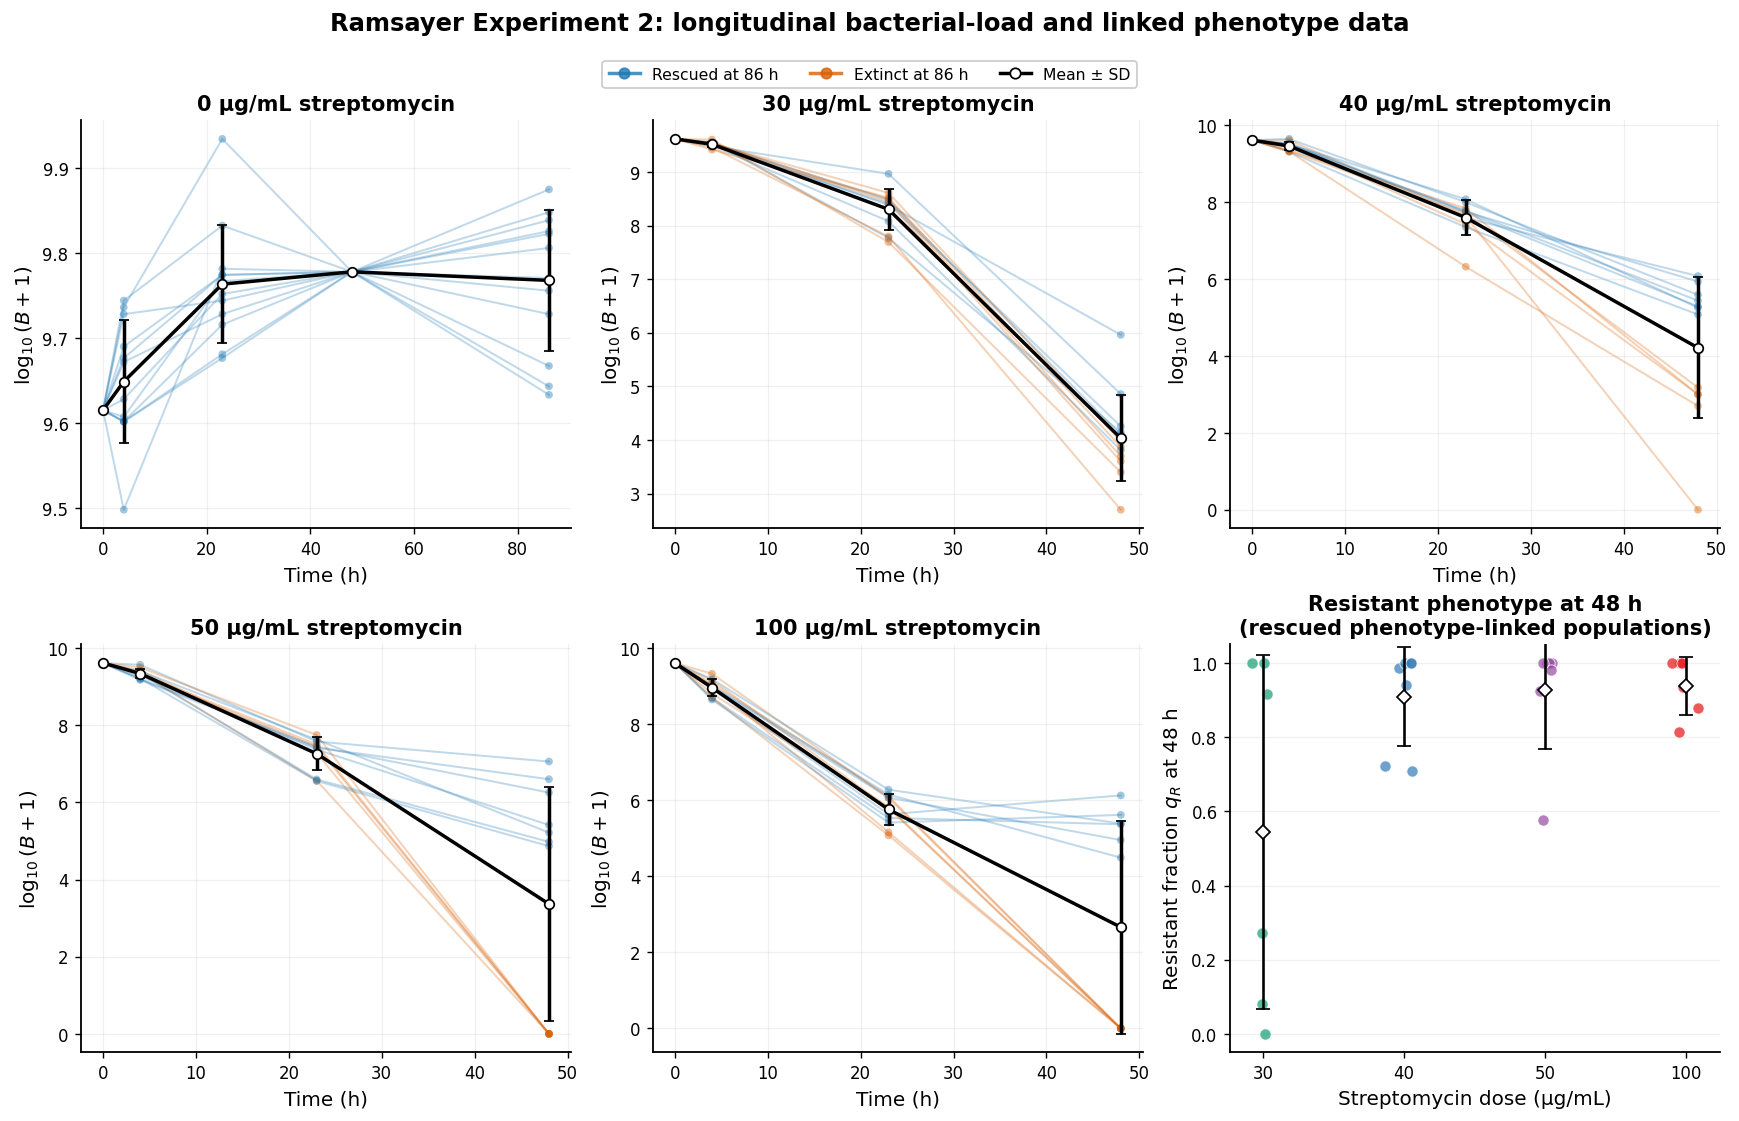

In [30]:
# =============================================================================
# CELL 3 — Publication-quality overview of the experimental data
# =============================================================================
# Descriptive visualization only.
# No model is fitted and no independent treated 86-h endpoint data are used.
#
# IMPORTANT:
# - Total-load panels show ALL 60 populations.
# - The 48-h resistant-fraction panel contains only the exact phenotype-linked
#   rescued treated populations available in q48.
# =============================================================================


fig, axes = plt.subplots(
    2,
    3,
    figsize=(13.8, 8.2),
    constrained_layout=True,
)

axes = axes.ravel()


# =============================================================================
# TOTAL-LOAD PANELS
# =============================================================================

for panel_index, dose in enumerate(AVAILABLE_DOSES):

    ax = axes[panel_index]

    dose_df = primary[
        primary["dose_ug_ml"] == dose
    ].copy()


    # -------------------------------------------------------------------------
    # Plot every biological replicate separately
    # -------------------------------------------------------------------------

    for population_id, group in dose_df.groupby("population_id"):

        group = group.sort_values("time_h")

        status = str(
            group["status_86"].iloc[0]
        )

        color = (
            ALIVE_COLOR
            if status == "alive_86"
            else DEAD_COLOR
        )


        ax.plot(
            group["time_h"],
            group["log10_population_plus1"],
            color=color,
            alpha=0.28,
            linewidth=1.15,
            zorder=1,
        )


        ax.scatter(
            group["time_h"],
            group["log10_population_plus1"],
            color=color,
            alpha=0.42,
            s=20,
            edgecolor="none",
            zorder=2,
        )


    # -------------------------------------------------------------------------
    # Descriptive mean ± sample SD at each observed time
    # -------------------------------------------------------------------------

    stats = (
        dose_df
        .groupby("time_h")[
            "log10_population_plus1"
        ]
        .agg(
            ["mean", "std"]
        )
        .reset_index()
    )


    ax.errorbar(
        stats["time_h"],
        stats["mean"],
        yerr=stats["std"],
        fmt="o-",
        color="black",
        markerfacecolor="white",
        markeredgecolor="black",
        markersize=5.5,
        capsize=3.0,
        linewidth=2.0,
        zorder=5,
        label="Mean ± SD",
    )


    ax.set_title(
        f"{dose:g} µg/mL streptomycin",
        fontweight="bold",
    )


    ax.set_xlabel(
        "Time (h)"
    )


    ax.set_ylabel(
        r"$\log_{10}(B+1)$"
    )


    ax.grid(
        alpha=0.18,
        linewidth=0.7,
    )


    ax.spines[
        [
            "top",
            "right",
        ]
    ].set_visible(
        False
    )


# =============================================================================
# SIXTH PANEL — exact resistant-fraction measurements at 48 h
# =============================================================================
#
# q48 contains the exact phenotype-linked observations from the rescued treated
# populations. These measurements should not be interpreted as phenotype data
# for all treated populations.
# =============================================================================

ax = axes[5]


treated_doses = [
    30.0,
    40.0,
    50.0,
    100.0,
]


rng = np.random.default_rng(
    SEED
)


for x, dose in enumerate(
    treated_doses
):

    values = q48.loc[
        q48["dose_ug_ml"] == dose,
        "resistant_fraction_qR",
    ].to_numpy(
        float
    )


    if len(values) == 0:

        raise RuntimeError(
            f"No exact qR48 observations found for dose {dose:g} µg/mL."
        )


    if np.any(
        ~np.isfinite(
            values
        )
    ):

        raise RuntimeError(
            f"Non-finite qR48 value detected for dose {dose:g} µg/mL."
        )


    if np.any(
        (values < 0.0)
        |
        (values > 1.0)
    ):

        raise RuntimeError(
            f"qR48 values outside [0,1] detected for dose {dose:g} µg/mL."
        )


    jitter = rng.normal(
        0.0,
        0.055,
        size=len(values),
    )


    # Individual exact phenotype-linked measurements
    ax.scatter(
        np.full(
            len(values),
            x,
        )
        + jitter,
        values,
        s=42,
        color=DOSE_COLORS[dose],
        alpha=0.72,
        edgecolor="white",
        linewidth=0.6,
        zorder=3,
    )


    # Dose-wise descriptive mean ± sample SD
    ax.errorbar(
        x,
        values.mean(),
        yerr=(
            values.std(
                ddof=1
            )
            if len(values) > 1
            else 0.0
        ),
        fmt="D",
        color="black",
        markerfacecolor="white",
        markeredgecolor="black",
        markersize=6,
        capsize=4,
        linewidth=1.5,
        zorder=5,
    )


ax.set_xticks(
    range(
        len(
            treated_doses
        )
    ),
    [
        f"{dose:g}"
        for dose in treated_doses
    ],
)


ax.set_ylim(
    -0.05,
    1.05,
)


ax.set_xlabel(
    "Streptomycin dose (µg/mL)"
)


ax.set_ylabel(
    r"Resistant fraction $q_R$ at 48 h"
)


ax.set_title(
    "Resistant phenotype at 48 h\n"
    "(rescued phenotype-linked populations)",
    fontweight="bold",
)


ax.grid(
    axis="y",
    alpha=0.18,
    linewidth=0.7,
)


ax.spines[
    [
        "top",
        "right",
    ]
].set_visible(
    False
)


# =============================================================================
# FIGURE LEGEND
# =============================================================================

legend_handles = [

    Line2D(
        [0],
        [0],
        color=ALIVE_COLOR,
        marker="o",
        linestyle="-",
        label="Rescued at 86 h",
        alpha=0.8,
    ),

    Line2D(
        [0],
        [0],
        color=DEAD_COLOR,
        marker="o",
        linestyle="-",
        label="Extinct at 86 h",
        alpha=0.8,
    ),

    Line2D(
        [0],
        [0],
        color="black",
        marker="o",
        markerfacecolor="white",
        linestyle="-",
        label="Mean ± SD",
    ),
]


fig.legend(
    handles=legend_handles,
    loc="upper center",
    ncol=3,
    bbox_to_anchor=(
        0.5,
        1.035,
    ),
)


# =============================================================================
# FIGURE TITLE
# =============================================================================

fig.suptitle(
    "Ramsayer Experiment 2: longitudinal bacterial-load and linked phenotype data",
    fontsize=14,
    fontweight="bold",
    y=1.075,
)


# =============================================================================
# SAVE AND DISPLAY
# =============================================================================

save_figure(
    fig,
    f"{RUN_LABEL}_real_data_overview",
)

plt.show()

In [31]:
# =============================================================================
# CELL 4 — GROUPED TRAIN/VALIDATION SPLIT AND CAPACITY NORMALIZATION
# =============================================================================
#
# PURPOSE
# -------
# 1. Define the empirical normalization/capacity scale K_REAL.
# 2. Construct deterministic population-level train/validation splits.
# 3. Ensure that an entire biological population belongs to only one split.
# 4. Define the dose-specific training initial abundance used by the PINN.
#
# IMPORTANT SCIENTIFIC SCOPE
# --------------------------
# K_REAL is an empirical numerical carrying-capacity SCALE used for:
#
#       S >= 0
#       R >= 0
#       S + R <= K_REAL
#
# It is NOT claimed to be an experimentally measured biological carrying
# capacity.
#
# K_REAL is deliberately computed from the complete control dataset BEFORE
# the grouped train/validation split, matching the FINAL primary PINN analysis.
#
# Therefore:
#
#   - the validation set is an INTERNAL grouped validation set;
#   - it is NOT a completely untouched external test set;
#   - the independent treated 86-h endpoint remains reserved for Cell 12.
#
# DO NOT change K_REAL to train-only scaling here unless the entire FINAL
# R3.7/R3.8/R3.9 pipeline is intentionally retrained.
# =============================================================================

from dataclasses import dataclass
from typing import Dict, List

import numpy as np
import pandas as pd


# =============================================================================
# 0. REQUIRED-DATA CHECKS
# =============================================================================

required_objects_4 = [
    "primary",
    "rescued_total",
    "phenotype",
    "AVAILABLE_DOSES",
    "SEED",
]

missing_objects_4 = [
    name
    for name in required_objects_4
    if name not in globals()
]

if missing_objects_4:
    raise RuntimeError(
        "Cell 4 requires Cell 2 to have completed successfully.\n"
        f"Missing objects: {missing_objects_4}"
    )


required_total_cols_4 = {
    "dose_ug_ml",
    "population_id",
    "time_h",
    "population_size_est",
}

missing_total_cols_4 = (
    required_total_cols_4
    .difference(rescued_total.columns)
)

if missing_total_cols_4:
    raise RuntimeError(
        "rescued_total is missing required columns: "
        f"{sorted(missing_total_cols_4)}"
    )


required_fraction_cols_4 = {
    "dose_ug_ml",
    "population_id",
    "time_h",
    "resistant_fraction_qR",
}

missing_fraction_cols_4 = (
    required_fraction_cols_4
    .difference(phenotype.columns)
)

if missing_fraction_cols_4:
    raise RuntimeError(
        "phenotype is missing required columns: "
        f"{sorted(missing_fraction_cols_4)}"
    )


# =============================================================================
# 1. EMPIRICAL CAPACITY / NORMALIZATION SCALE
# =============================================================================

CAPACITY_MARGIN = 1.30


control_values_4 = (
    primary.loc[
        primary["dose_ug_ml"] == 0.0,
        "population_size_est",
    ]
    .astype(float)
)


if control_values_4.empty:
    raise RuntimeError(
        "No untreated-control observations were found; "
        "K_REAL cannot be defined."
    )


if np.any(~np.isfinite(control_values_4)):
    raise RuntimeError(
        "Non-finite untreated-control population values were detected."
    )


if np.any(control_values_4 <= 0.0):
    raise RuntimeError(
        "Untreated-control population values must be positive."
    )


control_max = float(
    control_values_4.max()
)


K_REAL = float(
    CAPACITY_MARGIN
    * control_max
)


if not np.isfinite(K_REAL) or K_REAL <= 0.0:
    raise RuntimeError(
        f"Invalid K_REAL computed: {K_REAL}"
    )


# Work on an explicit copy so no chained-assignment ambiguity is introduced.
rescued_total = rescued_total.copy()


rescued_total[
    "normalized_total"
] = (
    rescued_total[
        "population_size_est"
    ].astype(float)
    / K_REAL
)


max_normalized_total_4 = float(
    rescued_total[
        "normalized_total"
    ].max()
)


if max_normalized_total_4 >= 1.0:
    raise ValueError(
        "K_REAL is too small: at least one observed population "
        "lies outside the hard feasible set. "
        "Increase CAPACITY_MARGIN."
    )


if (
    rescued_total[
        "normalized_total"
    ]
    < 0.0
).any():
    raise RuntimeError(
        "Negative normalized population abundance detected."
    )


# =============================================================================
# 2. FIT-BUNDLE DATA STRUCTURE
# =============================================================================

@dataclass
class RealFitBundle:

    doses: List[float]

    total: pd.DataFrame

    fraction: pd.DataFrame

    initial_total_norm: Dict[
        float,
        float,
    ]

    train_ids: Dict[
        float,
        List[str],
    ]

    val_ids: Dict[
        float,
        List[str],
    ]


# =============================================================================
# 3. GROUPED TRAIN/VALIDATION SPLIT
# =============================================================================

def build_fit_bundle(
    doses: List[float],
    split_seed: int = SEED,
    validation_fraction: float = 0.20,
) -> RealFitBundle:
    """
    Construct deterministic population-level train/validation splits.

    An entire biological population is assigned to either training or
    validation. No longitudinal observations from the same population can
    appear in both sets.

    Parameters
    ----------
    doses
        Treatment doses included in the fit.

    split_seed
        Fixed random seed used for reproducible grouped splitting.

    validation_fraction
        Approximate fraction of biological populations assigned to validation.
    """

    # -------------------------------------------------------------------------
    # Normalize dose representation
    # -------------------------------------------------------------------------

    doses = [
        float(d)
        for d in doses
    ]


    if len(doses) == 0:
        raise ValueError(
            "At least one dose must be supplied."
        )


    if not (
        0.0
        < validation_fraction
        < 1.0
    ):
        raise ValueError(
            "validation_fraction must lie strictly between 0 and 1."
        )


    # -------------------------------------------------------------------------
    # Select the required observations
    # -------------------------------------------------------------------------

    total = rescued_total[
        rescued_total[
            "dose_ug_ml"
        ].isin(doses)
    ].copy()


    fraction = phenotype[
        phenotype[
            "dose_ug_ml"
        ].isin(doses)
    ].copy()


    if total.empty:
        raise RuntimeError(
            "No total-load observations are available for the requested doses."
        )


    # -------------------------------------------------------------------------
    # Deterministic grouped split
    # -------------------------------------------------------------------------

    rng = np.random.default_rng(
        split_seed
    )


    train_ids: Dict[
        float,
        List[str],
    ] = {}


    val_ids: Dict[
        float,
        List[str],
    ] = {}


    for dose in doses:

        ids = sorted(
            total.loc[
                total[
                    "dose_ug_ml"
                ]
                == dose,
                "population_id",
            ]
            .astype(str)
            .unique()
            .tolist()
        )


        if len(ids) < 2:
            raise RuntimeError(
                f"Dose {dose:g} µg/mL contains fewer than two "
                "biological populations and cannot be split."
            )


        ids = np.asarray(
            ids,
            dtype=object,
        )


        rng.shuffle(
            ids
        )


        n_val = max(
            1,
            int(
                round(
                    validation_fraction
                    * len(ids)
                )
            ),
        )


        # Always preserve at least one training population.
        n_val = min(
            n_val,
            len(ids) - 1,
        )


        val_ids[dose] = (
            ids[:n_val]
            .astype(str)
            .tolist()
        )


        train_ids[dose] = (
            ids[n_val:]
            .astype(str)
            .tolist()
        )


        # ---------------------------------------------------------------------
        # Hard leakage audit within each dose
        # ---------------------------------------------------------------------

        overlap = (
            set(
                train_ids[dose]
            )
            &
            set(
                val_ids[dose]
            )
        )


        if overlap:
            raise RuntimeError(
                f"Population leakage detected at dose {dose:g}: "
                f"{sorted(overlap)}"
            )


    # =========================================================================
    # 4. APPLY SPLIT USING (DOSE, POPULATION-ID)
    # =========================================================================
    #
    # Using the pair (dose, population_id) is safer than using population_id
    # alone. It prevents accidental collisions if two doses ever contain the
    # same textual population identifier.
    # =========================================================================

    split_lookup = {}


    for dose in doses:

        for pid in train_ids[dose]:

            split_lookup[
                (
                    float(dose),
                    str(pid),
                )
            ] = "train"


        for pid in val_ids[dose]:

            split_lookup[
                (
                    float(dose),
                    str(pid),
                )
            ] = "val"


    def _lookup_split_4(row):

        return split_lookup.get(
            (
                float(
                    row[
                        "dose_ug_ml"
                    ]
                ),
                str(
                    row[
                        "population_id"
                    ]
                ),
            ),
            None,
        )


    total[
        "split"
    ] = total.apply(
        _lookup_split_4,
        axis=1,
    )


    fraction[
        "split"
    ] = fraction.apply(
        _lookup_split_4,
        axis=1,
    )


    # -------------------------------------------------------------------------
    # Verify that every total-load row received a split
    # -------------------------------------------------------------------------

    if total[
        "split"
    ].isna().any():

        bad_rows = total[
            total[
                "split"
            ].isna()
        ][
            [
                "dose_ug_ml",
                "population_id",
                "time_h",
            ]
        ]

        raise RuntimeError(
            "A total-load population was not assigned to "
            "train/validation.\n"
            f"{bad_rows}"
        )


    # -------------------------------------------------------------------------
    # Verify that every phenotype row received a split
    # -------------------------------------------------------------------------

    if fraction[
        "split"
    ].isna().any():

        bad_rows = fraction[
            fraction[
                "split"
            ].isna()
        ][
            [
                "dose_ug_ml",
                "population_id",
                "time_h",
            ]
        ]

        raise RuntimeError(
            "A phenotype population was not assigned to "
            "train/validation.\n"
            f"{bad_rows}"
        )


    # =========================================================================
    # 5. GLOBAL POPULATION-LEVEL LEAKAGE AUDIT
    # =========================================================================

    total_population_split_count = (
        total
        .groupby(
            [
                "dose_ug_ml",
                "population_id",
            ]
        )[
            "split"
        ]
        .nunique()
    )


    if (
        total_population_split_count
        > 1
    ).any():

        raise RuntimeError(
            "Population-level train/validation leakage detected "
            "in total-load data."
        )


    fraction_population_split_count = (
        fraction
        .groupby(
            [
                "dose_ug_ml",
                "population_id",
            ]
        )[
            "split"
        ]
        .nunique()
    )


    if (
        fraction_population_split_count
        > 1
    ).any():

        raise RuntimeError(
            "Population-level train/validation leakage detected "
            "in phenotype data."
        )


    # =========================================================================
    # 6. VERIFY TOTAL/PHENOTYPE SPLIT CONSISTENCY
    # =========================================================================

    total_assignment = (
        total[
            [
                "dose_ug_ml",
                "population_id",
                "split",
            ]
        ]
        .drop_duplicates()
    )


    fraction_assignment = (
        fraction[
            [
                "dose_ug_ml",
                "population_id",
                "split",
            ]
        ]
        .drop_duplicates()
    )


    assignment_check = (
        fraction_assignment
        .merge(
            total_assignment,
            on=[
                "dose_ug_ml",
                "population_id",
            ],
            how="left",
            suffixes=(
                "_fraction",
                "_total",
            ),
        )
    )


    if assignment_check[
        "split_total"
    ].isna().any():

        raise RuntimeError(
            "A phenotype-linked population is absent from "
            "the total-load split table."
        )


    if not (
        assignment_check[
            "split_fraction"
        ]
        ==
        assignment_check[
            "split_total"
        ]
    ).all():

        raise RuntimeError(
            "Phenotype and total-load split assignments disagree."
        )


    # =========================================================================
    # 7. DOSE-SPECIFIC TRAINING INITIAL CONDITIONS
    # =========================================================================

    initial_total_norm: Dict[
        float,
        float,
    ] = {}


    for dose in doses:

        initial_rows = total[
            (
                total[
                    "dose_ug_ml"
                ]
                == dose
            )
            &
            np.isclose(
                total[
                    "time_h"
                ].astype(float),
                0.0,
            )
            &
            (
                total[
                    "split"
                ]
                == "train"
            )
        ]


        if initial_rows.empty:

            raise RuntimeError(
                f"No training initial condition is available "
                f"for dose {dose:g} µg/mL."
            )


        n0_norm = float(
            initial_rows[
                "population_size_est"
            ].astype(float)
            .mean()
            / K_REAL
        )


        if not (
            0.0
            < n0_norm
            < 1.0
        ):

            raise RuntimeError(
                f"Invalid normalized initial abundance for "
                f"dose {dose:g}: {n0_norm}"
            )


        initial_total_norm[
            dose
        ] = n0_norm


    # =========================================================================
    # 8. RETURN BUNDLE
    # =========================================================================

    return RealFitBundle(

        doses=doses,

        total=total.reset_index(
            drop=True
        ),

        fraction=fraction.reset_index(
            drop=True
        ),

        initial_total_norm=initial_total_norm,

        train_ids=train_ids,

        val_ids=val_ids,
    )


# =============================================================================
# 9. BUILD THE PRIMARY FIT BUNDLE
# =============================================================================

BASE_BUNDLE = build_fit_bundle(
    AVAILABLE_DOSES
)


# =============================================================================
# 10. FINAL AUDIT / CONSOLE OUTPUT
# =============================================================================

print("=" * 92)
print("CELL 4 GROUPED SPLIT / CAPACITY AUDIT PASSED")
print("=" * 92)


print(
    f"Capacity margin                       : "
    f"{CAPACITY_MARGIN:.2f}"
)


print(
    f"Maximum untreated-control population : "
    f"{control_max:.6e} cells"
)


print(
    f"Empirical K_REAL                     : "
    f"{K_REAL:.6e} cells"
)


print(
    f"Maximum normalized observed total    : "
    f"{max_normalized_total_4:.6f}"
)


print(
    "\nIMPORTANT SCOPE:"
)


print(
    "K_REAL is a numerical hard-capacity normalization scale; "
    "it is not asserted to be a directly measured biological "
    "carrying capacity."
)


print(
    "K_REAL is computed before the grouped train/validation split, "
    "so validation is internal grouped validation rather than an "
    "independent external test."
)


print(
    "The independent treated 86-h endpoint remains reserved for Cell 12."
)


# =============================================================================
# 11. SPLIT SUMMARY
# =============================================================================

split_rows = []


for dose in BASE_BUNDLE.doses:

    train_set = set(
        BASE_BUNDLE.train_ids[
            dose
        ]
    )


    val_set = set(
        BASE_BUNDLE.val_ids[
            dose
        ]
    )


    overlap = (
        train_set
        &
        val_set
    )


    split_rows.append(
        {

            "dose_ug_ml":
                dose,

            "train_populations":
                len(
                    train_set
                ),

            "validation_populations":
                len(
                    val_set
                ),

            "population_overlap":
                len(
                    overlap
                ),

            "n0_over_K":
                BASE_BUNDLE
                .initial_total_norm[
                    dose
                ],
        }
    )


split_summary_4 = pd.DataFrame(
    split_rows
)


display(
    split_summary_4
)


# =============================================================================
# 12. FINAL HARD CHECKS
# =============================================================================

if (
    split_summary_4[
        "population_overlap"
    ]
    != 0
).any():

    raise RuntimeError(
        "Final population leakage audit failed."
    )


if not np.all(
    (
        split_summary_4[
            "n0_over_K"
        ]
        > 0.0
    )
    &
    (
        split_summary_4[
            "n0_over_K"
        ]
        < 1.0
    )
):

    raise RuntimeError(
        "Final initial-condition normalization audit failed."
    )


print(
    "\nPopulation-level train/validation leakage audit: PASSED"
)


print(
    "Initial-condition normalization audit             : PASSED"
)


print("=" * 92)

CELL 4 GROUPED SPLIT / CAPACITY AUDIT PASSED
Capacity margin                       : 1.30
Maximum untreated-control population : 8.600001e+09 cells
Empirical K_REAL                     : 1.118000e+10 cells
Maximum normalized observed total    : 0.769231

IMPORTANT SCOPE:
K_REAL is a numerical hard-capacity normalization scale; it is not asserted to be a directly measured biological carrying capacity.
K_REAL is computed before the grouped train/validation split, so validation is internal grouped validation rather than an independent external test.
The independent treated 86-h endpoint remains reserved for Cell 12.


,dose_ug_ml,train_populations,validation_populations,population_overlap,n0_over_K
0,0.0,10,2,0,0.368962
1,30.0,5,1,0,0.368962
2,40.0,6,1,0,0.368962
3,50.0,6,1,0,0.368962
4,100.0,5,1,0,0.368962



Population-level train/validation leakage audit: PASSED
Initial-condition normalization audit             : PASSED


In [49]:
# CELL 5 — Hard abundance–simplex architecture + selected 11F-R parameters
#          with ONE shared pre-treatment resistant fraction
# =============================================================================
#
# KEY REAL-DATA CORRECTION
# ------------------------
# The previous version used a separate q0 for every future drug dose.
#
# That is difficult to justify biologically because q0 describes the
# PRE-TREATMENT resistant fraction. The later streptomycin concentration
# should not, by itself, determine the initial phenotype composition.
#
# We therefore use ONE shared effective initial resistant fraction:
#
#       q0_shared
#
# across all dose environments.
#
# The method initial_resistant_fraction(dose) is intentionally retained for
# backward compatibility with later notebook cells; the dose argument is
# ignored and the same shared q0 is returned for every environment.
# =============================================================================


# =============================================================================
# BOUNDED-PARAMETER HELPERS
# =============================================================================

def inverse_sigmoid(
    position: float,
) -> float:

    position = float(
        np.clip(
            position,
            1e-8,
            1.0 - 1e-8,
        )
    )

    return math.log(
        position
        / (
            1.0
            - position
        )
    )


def raw_for_log10_value(
    value: float,
    lo: float,
    hi: float,
) -> float:

    position = (
        math.log10(
            value
        )
        - lo
    ) / (
        hi
        - lo
    )

    return inverse_sigmoid(
        position
    )


def bounded_log10(
    raw: torch.Tensor,
    lo: float,
    hi: float,
) -> torch.Tensor:

    return (
        lo
        +
        (
            hi
            - lo
        )
        * torch.sigmoid(
            raw
        )
    )


# =============================================================================
# SMOOTH TANH MLP
# =============================================================================

class TanhMLP(
    nn.Module
):

    """
    Smooth fully-connected neural network.

    This preserves the same general architectural style used in the
    synthetic AMR repository:
        - tanh activations;
        - Xavier-normal initialization;
        - float64 parameters.
    """

    def __init__(
        self,
        input_dim: int,
        output_dim: int,
        width: int,
        depth: int,
    ):

        super().__init__()

        layers: List[
            nn.Module
        ] = []

        previous = input_dim

        for _ in range(
            depth
        ):

            linear = nn.Linear(
                previous,
                width,
                dtype=DTYPE,
            )

            nn.init.xavier_normal_(
                linear.weight
            )

            nn.init.zeros_(
                linear.bias
            )

            layers.extend(
                [
                    linear,
                    nn.Tanh(),
                ]
            )

            previous = width

        output = nn.Linear(
            previous,
            output_dim,
            dtype=DTYPE,
        )

        nn.init.xavier_normal_(
            output.weight,
            gain=0.5,
        )

        nn.init.zeros_(
            output.bias
        )

        layers.append(
            output
        )

        self.network = nn.Sequential(
            *layers
        )

    def forward(
        self,
        x: torch.Tensor,
    ) -> torch.Tensor:

        return self.network(
            x
        )


# =============================================================================
# SHARED BOUNDED BIOLOGICAL PARAMETERS
# =============================================================================

class RealInverseParameters(
    nn.Module
):

    """
    Bounded parameters for the selected 11F-R real-data mechanism.

    Shared eco-evolutionary parameters
    ----------------------------------
    mu
        Mutation probability per sensitive-cell division.

    c_R
        Fitness cost of resistance.

    r_S
        Sensitive-cell baseline birth rate [h^-1].

    d0
        Baseline death rate [h^-1].

    q0_shared
        One shared effective PRE-TREATMENT resistant fraction.

    Shared pharmacodynamic parameters
    ----------------------------------
    k30, k40, k50, k100
        Dose-specific maximum effective killing rates [h^-1].

    rho_R
        Relative killing sensitivity of the resistant phenotype.

    tau_K
        Midpoint [h] of the gradual killing-activation function H_K(t).

    gamma_K
        Steepness [h^-1] of H_K(t).

    Selected reduced mechanism
    --------------------------
        H_K(t) = sigmoid(gamma_K * (t - tau_K))

    The resistant-growth timing gate from Diagnostic 11F+ is NOT included:
        G_R(t) = 1

    The hard abundance-simplex state architecture is unchanged.
    """

    def __init__(
        self,
        doses: List[float],
    ):

        super().__init__()

        self.doses = [
            float(d)
            for d
            in doses
        ]

        # ---------------------------------------------------------------------
        # Bounds matched to the selected 11F-R mechanistic diagnostic.
        # ---------------------------------------------------------------------

        self.log10_mu_min = -12.0
        self.log10_mu_max = -2.0

        self.cost_min = 0.0
        self.cost_max = 0.95

        self.log10_rs_min = -3.0
        self.log10_rs_max = math.log10(
            3.0
        )

        self.log10_d_min = -4.0
        self.log10_d_max = math.log10(
            2.0
        )

        self.log10_q0_min = -12.0
        self.log10_q0_max = -2.0

        self.log10_k_min = -4.0
        self.log10_k_max = math.log10(
            5.0
        )

        self.rhoR_min = 0.0
        self.rhoR_max = 1.0

        self.tauK_min_h = -12.0
        self.tauK_max_h = 48.0

        self.log10_gammaK_min = math.log10(
            0.02
        )
        self.log10_gammaK_max = math.log10(
            10.0
        )

        # ---------------------------------------------------------------------
        # Conservative initial optimizer positions.
        #
        # These are only starting values. They are intentionally not set equal
        # to the final 11F-R optimum, so the PINN still re-estimates the
        # parameters during joint training.
        # ---------------------------------------------------------------------

        self.raw_mu = nn.Parameter(
            torch.tensor(
                raw_for_log10_value(
                    1e-6,
                    self.log10_mu_min,
                    self.log10_mu_max,
                ),
                dtype=DTYPE,
            )
        )

        self.raw_cost = nn.Parameter(
            torch.tensor(
                inverse_sigmoid(
                    (0.10 - self.cost_min)
                    / (
                        self.cost_max
                        - self.cost_min
                    )
                ),
                dtype=DTYPE,
            )
        )

        self.raw_rs = nn.Parameter(
            torch.tensor(
                raw_for_log10_value(
                    0.60,
                    self.log10_rs_min,
                    self.log10_rs_max,
                ),
                dtype=DTYPE,
            )
        )

        self.raw_death = nn.Parameter(
            torch.tensor(
                raw_for_log10_value(
                    0.40,
                    self.log10_d_min,
                    self.log10_d_max,
                ),
                dtype=DTYPE,
            )
        )

        self.raw_q0_shared = nn.Parameter(
            torch.tensor(
                raw_for_log10_value(
                    1e-9,
                    self.log10_q0_min,
                    self.log10_q0_max,
                ),
                dtype=DTYPE,
            )
        )

        # ---------------------------------------------------------------------
        # Selected 11F-R pharmacodynamic parameters.
        # ---------------------------------------------------------------------
        # The initial values are deliberately generic/informed rather than the
        # exact fitted 11F-R solution:
        #   k_A ~ 0.5 h^-1, rho_R ~ 0.5, tau_K ~ 14 h, gamma_K ~ 0.25 h^-1.
        # All remain trainable.
        # ---------------------------------------------------------------------

        self.raw_kill_by_dose = nn.ParameterDict()

        for dose in self.doses:

            if np.isclose(
                dose,
                0.0,
            ):
                continue

            key = str(
                int(
                    round(
                        float(
                            dose
                        )
                    )
                )
            )

            self.raw_kill_by_dose[
                key
            ] = nn.Parameter(
                torch.tensor(
                    raw_for_log10_value(
                        0.50,
                        self.log10_k_min,
                        self.log10_k_max,
                    ),
                    dtype=DTYPE,
                )
            )

        self.raw_rhoR = nn.Parameter(
            torch.tensor(
                inverse_sigmoid(
                    0.50
                ),
                dtype=DTYPE,
            )
        )

        self.raw_tauK = nn.Parameter(
            torch.tensor(
                inverse_sigmoid(
                    (
                        14.0
                        - self.tauK_min_h
                    )
                    / (
                        self.tauK_max_h
                        - self.tauK_min_h
                    )
                ),
                dtype=DTYPE,
            )
        )

        self.raw_gammaK = nn.Parameter(
            torch.tensor(
                raw_for_log10_value(
                    0.25,
                    self.log10_gammaK_min,
                    self.log10_gammaK_max,
                ),
                dtype=DTYPE,
            )
        )

    # =========================================================================
    # BOUNDED TRANSFORMS
    # =========================================================================

    def mutation_probability(
        self,
    ) -> torch.Tensor:

        return torch.pow(
            torch.tensor(
                10.0,
                dtype=DTYPE,
                device=self.raw_mu.device,
            ),
            bounded_log10(
                self.raw_mu,
                self.log10_mu_min,
                self.log10_mu_max,
            ),
        )

    def resistance_fitness_cost(
        self,
    ) -> torch.Tensor:

        return (
            self.cost_min
            +
            (
                self.cost_max
                - self.cost_min
            )
            * torch.sigmoid(
                self.raw_cost
            )
        )

    def sensitive_birth_rate(
        self,
    ) -> torch.Tensor:

        return torch.pow(
            torch.tensor(
                10.0,
                dtype=DTYPE,
                device=self.raw_rs.device,
            ),
            bounded_log10(
                self.raw_rs,
                self.log10_rs_min,
                self.log10_rs_max,
            ),
        )

    def death_rate(
        self,
    ) -> torch.Tensor:

        return torch.pow(
            torch.tensor(
                10.0,
                dtype=DTYPE,
                device=self.raw_death.device,
            ),
            bounded_log10(
                self.raw_death,
                self.log10_d_min,
                self.log10_d_max,
            ),
        )

    def initial_resistant_fraction(
        self,
        dose: Optional[float] = None,
    ) -> torch.Tensor:

        """
        Return the ONE shared pre-treatment resistant fraction.

        dose is accepted only for backward compatibility.
        """

        return torch.pow(
            torch.tensor(
                10.0,
                dtype=DTYPE,
                device=self.raw_q0_shared.device,
            ),
            bounded_log10(
                self.raw_q0_shared,
                self.log10_q0_min,
                self.log10_q0_max,
            ),
        )

    def kill_rate(
        self,
        dose: float,
    ) -> torch.Tensor:

        """
        Return k_A [h^-1] for the specified experimental dose.

        The untreated environment has k_A = 0 exactly and therefore introduces
        no additional trainable kill parameter.
        """

        dose = float(
            dose
        )

        if np.isclose(
            dose,
            0.0,
        ):
            return torch.zeros(
                (),
                dtype=DTYPE,
                device=self.raw_mu.device,
            )

        key = str(
            int(
                round(
                    dose
                )
            )
        )

        if key not in self.raw_kill_by_dose:
            raise KeyError(
                f"No 11F-R kill parameter is registered for dose {dose:g} ug/mL."
            )

        raw = self.raw_kill_by_dose[
            key
        ]

        return torch.pow(
            torch.tensor(
                10.0,
                dtype=DTYPE,
                device=raw.device,
            ),
            bounded_log10(
                raw,
                self.log10_k_min,
                self.log10_k_max,
            ),
        )

    def resistant_relative_drug_sensitivity(
        self,
    ) -> torch.Tensor:

        return (
            self.rhoR_min
            +
            (
                self.rhoR_max
                - self.rhoR_min
            )
            * torch.sigmoid(
                self.raw_rhoR
            )
        )

    def kill_activation_onset(
        self,
    ) -> torch.Tensor:

        return (
            self.tauK_min_h
            +
            (
                self.tauK_max_h
                - self.tauK_min_h
            )
            * torch.sigmoid(
                self.raw_tauK
            )
        )

    def kill_activation_rate(
        self,
    ) -> torch.Tensor:

        return torch.pow(
            torch.tensor(
                10.0,
                dtype=DTYPE,
                device=self.raw_gammaK.device,
            ),
            bounded_log10(
                self.raw_gammaK,
                self.log10_gammaK_min,
                self.log10_gammaK_max,
            ),
        )

    def kill_activation(
        self,
        t: torch.Tensor,
    ) -> torch.Tensor:

        """
        Selected reduced pharmacodynamic timing law:

            H_K(t) = sigmoid(gamma_K * (t - tau_K))
        """

        return torch.sigmoid(
            self.kill_activation_rate()
            * (
                t
                - self.kill_activation_onset()
            )
        )

    def as_floats(
        self,
    ) -> Dict[
        str,
        float,
    ]:

        q0_value = float(
            self
            .initial_resistant_fraction()
            .detach()
            .cpu()
        )

        death_value = float(
            self
            .death_rate()
            .detach()
            .cpu()
        )

        result = {
            "mutation_probability":
                float(
                    self
                    .mutation_probability()
                    .detach()
                    .cpu()
                ),

            "resistance_fitness_cost":
                float(
                    self
                    .resistance_fitness_cost()
                    .detach()
                    .cpu()
                ),

            "sensitive_birth_rate_per_h":
                float(
                    self
                    .sensitive_birth_rate()
                    .detach()
                    .cpu()
                ),

            # New canonical name, matching Diagnostic 11F-R.
            "baseline_death_rate_per_h":
                death_value,

            # Backward-compatible name used by older notebook cells.
            "death_rate_per_h":
                death_value,

            "initial_resistant_fraction_shared":
                q0_value,

            "resistant_relative_drug_sensitivity":
                float(
                    self
                    .resistant_relative_drug_sensitivity()
                    .detach()
                    .cpu()
                ),

            "kill_activation_onset_h":
                float(
                    self
                    .kill_activation_onset()
                    .detach()
                    .cpu()
                ),

            "kill_activation_per_h":
                float(
                    self
                    .kill_activation_rate()
                    .detach()
                    .cpu()
                ),
        }

        for dose in self.doses:

            # Preserve historical q0 aliases.
            result[
                f"q0_dose_{int(dose)}"
            ] = q0_value

            # Expose fitted dose-specific killing rates for treated doses.
            if not np.isclose(
                dose,
                0.0,
            ):
                result[
                    f"kill_{int(round(float(dose)))}_per_h"
                ] = float(
                    self
                    .kill_rate(
                        dose
                    )
                    .detach()
                    .cpu()
                )

        return result


# =============================================================================
# SHARED DOSE-CONDITIONED HARD FEASIBLE STATE NETWORK
# =============================================================================

class SharedDoseConditionedStateNetwork(
    nn.Module
):

    """
    One shared hard state network for all streptomycin environments.

    Inputs
    ------
    t
        Time in hours.

    dose
        Streptomycin concentration in ug/mL.

    Output
    ------
    Two normalized latent states:

        state[:,0] = S / K_REAL
        state[:,1] = R / K_REAL

    Why this architecture is used
    -----------------------------
    The previous real-data model used one independent neural trajectory network
    for every dose. Those networks shared biological parameters, but phenotype
    information learned at one dose could not directly shape the latent neural
    representation at another dose.

    Here a SINGLE MLP learns the continuous map

        (time, dose) -> (total abundance, phenotype composition)

    while the mechanistic parameters remain shared. This makes leave-one-dose
    phenotype-out inference a genuine cross-environment transfer problem.

    Hard guarantees
    ---------------
    The output construction guarantees, for every time and dose:

        S >= 0
        R >= 0
        S + R <= K_REAL
        p_S + p_R = 1

    The experimentally observed initial total is imposed exactly for each
    environment, and one shared q0 is imposed at t=0.
    """

    def __init__(
        self,
        width: int,
        depth: int,
        tau_h: float = 1.0,
        dose_reference_ug_ml: float = 100.0,
    ):

        super().__init__()

        self.tau_h = float(
            tau_h
        )

        self.dose_reference_ug_ml = float(
            dose_reference_ug_ml
        )

        if self.dose_reference_ug_ml <= 0.0:
            raise ValueError(
                "dose_reference_ug_ml must be positive."
            )

        # Two neural inputs:
        #     1) normalized time
        #     2) normalized drug exposure
        #
        # Three raw outputs:
        #     raw[:,0]   -> total-abundance candidate
        #     raw[:,1:3] -> phenotype-simplex candidate
        self.network = TanhMLP(
            input_dim=2,
            output_dim=3,
            width=width,
            depth=depth,
        )

    def normalized_inputs(
        self,
        t: torch.Tensor,
        dose: float,
    ) -> torch.Tensor:

        """Create continuous time-dose inputs in approximately [-1, 1]."""

        if t.ndim == 1:
            t = t[:, None]

        x_time = (
            2.0
            * t
            / PHYSICS_HORIZON_H
            - 1.0
        )

        exposure = float(
            np.clip(
                float(dose)
                / self.dose_reference_ug_ml,
                0.0,
                1.0,
            )
        )

        x_dose = torch.full_like(
            t,
            2.0 * exposure - 1.0,
        )

        return torch.cat(
            [
                x_time,
                x_dose,
            ],
            dim=1,
        )

    def forward(
        self,
        t: torch.Tensor,
        dose: float,
        initial_total_norm: float,
        q0: torch.Tensor,
    ) -> torch.Tensor:

        if t.ndim == 1:
            t = t[:, None]

        x = self.normalized_inputs(
            t,
            dose,
        )

        raw = self.network(
            x
        )

        # ---------------------------------------------------------------------
        # Exact initial-condition gate
        # ---------------------------------------------------------------------
        # h(0)=0, so the network cannot alter the prescribed initial state.
        # The smooth gate approaches 1 away from t=0.
        h = (
            1.0
            - torch.exp(
                -torch.clamp(
                    t,
                    min=0.0,
                )
                / self.tau_h
            )
        )

        anchor_total = torch.full(
            (
                len(t),
                1,
            ),
            float(initial_total_norm),
            dtype=DTYPE,
            device=t.device,
        )

        q0 = q0.reshape(
            1,
            1,
        )

        anchor_fraction = torch.cat(
            [
                1.0 - q0,
                q0,
            ],
            dim=1,
        ).expand(
            len(t),
            -1,
        )

        # ---------------------------------------------------------------------
        # Feasible neural candidate
        # ---------------------------------------------------------------------
        candidate_total = torch.sigmoid(
            raw[:, 0:1]
        )

        candidate_fraction = torch.softmax(
            raw[:, 1:3],
            dim=1,
        )

        # Convex interpolation between the exact initial state and a feasible
        # neural candidate preserves the constraints for all t.
        total = (
            (1.0 - h) * anchor_total
            + h * candidate_total
        )

        fraction = (
            (1.0 - h) * anchor_fraction
            + h * candidate_fraction
        )

        return (
            total
            * fraction
        )


# =============================================================================
# COMPLETE SHARED DOSE-CONDITIONED REAL PINN
# =============================================================================

class RealAMRPINN(
    nn.Module
):

    """
    Shared dose-conditioned, structure-preserving real-data PINN.

    Neural representation
    ---------------------
    ONE neural state network is shared across all environments:

        (t, dose) -> (S/K_REAL, R/K_REAL)

    Shared parameters
    -----------------
        mu, c_R, r_S, d0, q0_shared,
        k30, k40, k50, k100, rho_R, tau_K, gamma_K.

    Selected real-data physics
    --------------------------
        H_K(t) = sigmoid(gamma_K (t - tau_K)),
        G_R(t) = 1.

    This architecture is intentionally designed for cross-dose phenotype
    transfer. If qR observations at one dose are hidden, the latent-state map
    at that dose is still coupled to the phenotype information learned from
    the remaining environments through the shared neural weights.
    """

    architecture_name = "shared_dose_conditioned_hard_PINN_11FR"

    def __init__(
        self,
        bundle: RealFitBundle,
        width: int = NETWORK_WIDTH,
        depth: int = NETWORK_DEPTH,
    ):

        super().__init__()

        self.doses = [
            float(d)
            for d
            in bundle.doses
        ]

        self.initial_total_norm_by_dose = {
            float(dose): float(
                bundle.initial_total_norm[
                    dose
                ]
            )
            for dose
            in self.doses
        }

        self.inverse = RealInverseParameters(
            self.doses
        )

        self.state_network = SharedDoseConditionedStateNetwork(
            width=width,
            depth=depth,
            tau_h=1.0,
            dose_reference_ug_ml=100.0,
        )

    def initial_total_norm(
        self,
        dose: float,
    ) -> float:

        dose = float(
            dose
        )

        if dose not in self.initial_total_norm_by_dose:
            raise KeyError(
                f"Dose {dose:g} ug/mL is not present in this fit bundle."
            )

        return self.initial_total_norm_by_dose[
            dose
        ]

    def forward(
        self,
        t: torch.Tensor,
        dose: float,
    ) -> torch.Tensor:

        dose = float(
            dose
        )

        q0 = (
            self.inverse
            .initial_resistant_fraction()
        )

        return self.state_network(
            t=t,
            dose=dose,
            initial_total_norm=self.initial_total_norm(
                dose
            ),
            q0=q0,
        )

    def inferred_parameters(
        self,
    ) -> Dict[
        str,
        float,
    ]:

        return (
            self.inverse
            .as_floats()
        )


# =============================================================================
# STRUCTURAL TEST BEFORE EXPENSIVE TRAINING
# =============================================================================

trial = RealAMRPINN(
    BASE_BUNDLE,
    width=16,
    depth=2,
).to(
    DEVICE
)

with torch.no_grad():

    tt = torch.linspace(
        0.0,
        PHYSICS_HORIZON_H,
        200,
        dtype=DTYPE,
        device=DEVICE,
    )[:, None]

    q0_values = []

    for dose in BASE_BUNDLE.doses:

        state = trial(
            tt,
            dose,
        )

        if state.min().item() < -1e-12:
            raise AssertionError(
                "Hard model generated a negative state."
            )

        if (
            state
            .sum(dim=1)
            .max()
            .item()
            > 1.0 + 1e-12
        ):
            raise AssertionError(
                "Hard model exceeded normalized capacity."
            )

        state0 = trial(
            torch.tensor(
                [[0.0]],
                dtype=DTYPE,
                device=DEVICE,
            ),
            dose,
        )

        initial_total_error = abs(
            float(
                state0
                .sum()
                .detach()
                .cpu()
            )
            - BASE_BUNDLE.initial_total_norm[
                dose
            ]
        )

        if initial_total_error > 1e-12:
            raise AssertionError(
                "Shared hard model failed the exact initial-total constraint."
            )

        q0_from_state = float(
            (
                state0[:, 1]
                / state0.sum(dim=1)
            )
            .detach()
            .cpu()
            .item()
        )

        q0_values.append(
            q0_from_state
        )

    if (
        max(q0_values)
        - min(q0_values)
        > 1e-12
    ):
        raise AssertionError(
            "The shared pre-treatment resistant fraction is not identical across doses."
        )

# Verify that the selected 11F-R parameterization is present.
trial_params = trial.inferred_parameters()

required_11fr_keys = {
    "mutation_probability",
    "resistance_fitness_cost",
    "sensitive_birth_rate_per_h",
    "baseline_death_rate_per_h",
    "initial_resistant_fraction_shared",
    "kill_30_per_h",
    "kill_40_per_h",
    "kill_50_per_h",
    "kill_100_per_h",
    "resistant_relative_drug_sensitivity",
    "kill_activation_onset_h",
    "kill_activation_per_h",
}

missing_11fr_keys = (
    required_11fr_keys
    - set(
        trial_params.keys()
    )
)

if missing_11fr_keys:
    raise AssertionError(
        "11F-R parameterization is incomplete: "
        + ", ".join(
            sorted(
                missing_11fr_keys
            )
        )
    )

print(
    "Shared dose-conditioned hard architecture + 11F-R parameter test passed."
)

del trial
clear_memory()

Shared dose-conditioned hard architecture + 11F-R parameter test passed.


In [50]:
# CELL 6 — 11F-R physics, observation losses, scaled residuals,
#          metrics, transfer-safe audits, and exact-ODE consistency
#
# SELECTED-MECHANISM IMPLEMENTATION UPDATE
# ----------------------------------------
# This version keeps the existing loss weights, collocation design, scaling,
# observation losses, and audit APIs, but replaces the previous real-data ODE
# with the selected reduced 11F-R pharmacodynamic mechanism.
# =============================================================================
#
# IMPORTANT CHANGE RELATIVE TO THE PREVIOUS VERSION
# --------------------------------------------------
# The model states S/K and R/K are dimensionless, but the ODE residuals
# have units of 1/hour.
#
# Previously we minimized:
#
#       mean(R_S^2) + mean(R_R^2)
#
# directly. Since these raw residuals can be numerically small
# (e.g. 1e-3 to 1e-2 per hour), the data loss could dominate the
# optimization even when the trajectory did not closely obey the ODE.
#
# We now nondimensionalize time using a characteristic biological
# timescale:
#
#       tau = t / T_c
#
# with:
#
#       T_c = 24 h
#
# Hence:
#
#       dS/dtau = T_c * dS/dt
#
# and the dimensionless residual becomes:
#
#       R_tilde = T_c * R
#
# This gives the physics loss a meaningful numerical scale without
# changing the governing equations themselves.
#
# After auditing the first real-data fit, the global physics weight is set to
# 25 and collocation is concentrated in 0–4 h to prevent an artificial
# near-instantaneous resistant-state transition.
# =============================================================================

# =============================================================================
# SELECTED REAL-DATA MECHANISM AFTER 11F-R PARSIMONY TEST
# =============================================================================
#
# The full 11F+ diagnostic contained both:
#     H_K(t): gradual killing activation
#     G_R(t): delayed resistant-growth activation
#
# Removing G_R changed the matched observed-window objective by only ~0.000273%.
# Cell 6 therefore uses the reduced 11F-R mechanism:
#
#     H_K(t) = sigmoid(gamma_K * (t - tau_K))
#     G_R(t) = 1
#
# No treated 86-h endpoint is used as an observation in the training losses.
# =============================================================================

# =============================================================================
# LOSS WEIGHTS
# =============================================================================

@dataclass
class LossWeights:
    total_data: float = 10.0
    fraction_data: float = 5.0

    # Absolute nondimensional ODE residual.
    physics: float = 25.0

    # Robust log-state/relative residual.
    #
    # This term is essential when the latent resistant population is tiny:
    # a small absolute normalized residual can still correspond to several
    # orders of magnitude of error in R(t).
    # Strengthened after the mechanistic-consistency audit showed that the
    # resistant-state log residual was underweighted relative to the data loss.
    # This makes the scale-aware physics contribution comparable to the load
    # reconstruction term without changing the governing equations.
    log_physics: float = 2.5

    weight_decay: float = 1e-8


LOSS_WEIGHTS = LossWeights()


# =============================================================================
# PHYSICS NONDIMENSIONALIZATION
# =============================================================================
#
# One-day characteristic timescale.
#
# This is NOT a fitted biological parameter.
# It is only used to nondimensionalize the physics residual.
# =============================================================================

PHYSICS_TIME_SCALE_H = 24.0

# One-cell pseudocount expressed in normalized state units.
#
# Since r = R / K_REAL,
#
#     r + 1/K_REAL = (R + 1) / K_REAL.
#
# Therefore division by this quantity produces the residual associated with
# the derivative of log(R+1), rather than only the absolute normalized state.
LOG_PHYSICS_PSEUDOCOUNT_CELLS = 1.0

# Numerical constant used only to prevent a zero denominator if K_REAL were
# ever changed unexpectedly.
LOG_PHYSICS_MIN_DENOM = 1e-16


# =============================================================================
# NUMPY → FLOAT64 PYTORCH COLUMN
# =============================================================================

def tensor_column(
    values,
    requires_grad: bool = False,
) -> torch.Tensor:

    """
    Convert a 1-D array-like object into a float64 PyTorch column tensor.

    Parameters
    ----------
    values
        Numerical values.

    requires_grad
        If True, autograd tracks derivatives with respect to the tensor.
        This is required for collocation-time tensors.

    Returns
    -------
    torch.Tensor
        Shape (N, 1), float64, on DEVICE.
    """

    arr = np.asarray(
        values,
        dtype=float,
    ).reshape(
        -1,
        1,
    )

    return torch.tensor(
        arr,
        dtype=DTYPE,
        device=DEVICE,
        requires_grad=requires_grad,
    )


# =============================================================================
# RAW / SCALED / LOG-STATE ECO-EVOLUTIONARY PHYSICS RESIDUALS
# =============================================================================
#
# IMPLEMENTATION NOTE
# -------------------
# The previous implementation evaluated the same ODE residual more than once
# inside complete_loss(): once for the absolute scaled residual and again for
# the log-state residual. That duplicated neural-network forward passes and
# autograd work.
#
# The helper below computes the raw residual and feasible state ONCE. Public
# wrapper functions keep the original API unchanged, so Cells 7–13 remain
# compatible. The governing equations, loss weights, residual definitions, and
# numerical values are unchanged.
# =============================================================================


def _physics_core(
    model: RealAMRPINN,
    t: torch.Tensor,
    dose: float,
    create_graph: bool = True,
) -> Tuple[
    torch.Tensor,
    torch.Tensor,
    torch.Tensor,
    torch.Tensor,
]:
    """
    Single-pass evaluation of the selected 11F-R normalized AMR ODE residual.

    Selected treated-dose mechanism
    -------------------------------
        H_K(t) = sigmoid(gamma_K * (t - tau_K))

        ds/dt =
            b_s(A) (1-mu) (1-s-r) s
            - [d0 + k_A H_K(t)] s

        dr/dt =
            b_s(A) mu (1-s-r) s
            + b_r(A) (1-s-r) r
            - [d0 + rho_R k_A H_K(t)] r

    The resistant-growth timing gate from 11F+ is removed:
        G_R(t) = 1

    The states s=S/K_REAL and r=R/K_REAL are dimensionless.

    Returns
    -------
    raw_s
        Sensitive-state residual in 1/hour.

    raw_r
        Resistant-state residual in 1/hour.

    s
        Normalized sensitive state S/K_REAL.

    r
        Normalized resistant state R/K_REAL.
    """

    if not t.requires_grad:
        t = (
            t.clone()
            .detach()
            .requires_grad_(True)
        )

    # -------------------------------------------------------------------------
    # Hard-constrained normalized state
    # -------------------------------------------------------------------------

    state = model(
        t,
        dose,
    )

    s = state[:, 0:1]
    r = state[:, 1:2]

    # -------------------------------------------------------------------------
    # Automatic differentiation with respect to physical time [h]
    # -------------------------------------------------------------------------

    ds_dt = torch.autograd.grad(
        outputs=s,
        inputs=t,
        grad_outputs=torch.ones_like(s),
        create_graph=create_graph,
        retain_graph=True,
    )[0]

    dr_dt = torch.autograd.grad(
        outputs=r,
        inputs=t,
        grad_outputs=torch.ones_like(r),
        create_graph=create_graph,
        retain_graph=True,
    )[0]

    # -------------------------------------------------------------------------
    # Shared inverse eco-evolutionary parameters
    # -------------------------------------------------------------------------

    mu = (
        model.inverse
        .mutation_probability()
    )

    cost = (
        model.inverse
        .resistance_fitness_cost()
    )

    r_s = (
        model.inverse
        .sensitive_birth_rate()
    )

    death = (
        model.inverse
        .death_rate()
    )

    # -------------------------------------------------------------------------
    # Selected 11F-R pharmacodynamic parameters
    # -------------------------------------------------------------------------

    rho_r = (
        model.inverse
        .resistant_relative_drug_sensitivity()
    )

    k_a = (
        model.inverse
        .kill_rate(
            dose
        )
    )

    if np.isclose(
        float(dose),
        0.0,
    ):

        # Untreated environment: no antibiotic killing.
        h_k = torch.zeros_like(
            t
        )

    else:

        h_k = (
            model.inverse
            .kill_activation(
                t
            )
        )

    # -------------------------------------------------------------------------
    # Measured streptomycin concentration -> normalized exposure
    # -------------------------------------------------------------------------

    exposure = float(
        np.clip(
            float(dose) / 100.0,
            0.0,
            1.0,
        )
    )

    # -------------------------------------------------------------------------
    # Drug-dependent division rates retained from the existing biological
    # scaffold. The new 11F-R term adds gradual effective killing.
    # -------------------------------------------------------------------------

    b_s = (
        r_s
        * (
            1.0
            - SENSITIVE_DRUG_EFFECT
            * exposure
        )
    )

    b_r = (
        r_s
        * (1.0 - cost)
        * (
            1.0
            - RESISTANT_DRUG_EFFECT
            * exposure
        )
    )

    crowding = (
        1.0
        - s
        - r
    )

    # -------------------------------------------------------------------------
    # 11F-R ODE right-hand sides
    # -------------------------------------------------------------------------

    effective_kill = (
        k_a
        * h_k
    )

    rhs_s = (
        b_s
        * (1.0 - mu)
        * crowding
        * s
        -
        (
            death
            + effective_kill
        )
        * s
    )

    rhs_r = (
        b_s
        * mu
        * crowding
        * s
        +
        b_r
        * crowding
        * r
        -
        (
            death
            + rho_r
            * effective_kill
        )
        * r
    )

    raw_s = (
        ds_dt
        - rhs_s
    )

    raw_r = (
        dr_dt
        - rhs_r
    )

    return (
        raw_s,
        raw_r,
        s,
        r,
    )


def _scale_absolute_residual(
    raw_s: torch.Tensor,
    raw_r: torch.Tensor,
) -> Tuple[
    torch.Tensor,
    torch.Tensor,
]:
    """
    Convert dimensional-time residuals to the nondimensional time scale
    tau = t / T_c.
    """

    scaled_s = (
        PHYSICS_TIME_SCALE_H
        * raw_s
    )

    scaled_r = (
        PHYSICS_TIME_SCALE_H
        * raw_r
    )

    return (
        scaled_s,
        scaled_r,
    )


def _scale_log_state_residual(
    raw_s: torch.Tensor,
    raw_r: torch.Tensor,
    s: torch.Tensor,
    r: torch.Tensor,
) -> Tuple[
    torch.Tensor,
    torch.Tensor,
]:
    """
    Convert raw state residuals to scale-aware residuals corresponding to
    log10(S+1) and log10(R+1).
    """

    eps_state = max(
        float(
            LOG_PHYSICS_PSEUDOCOUNT_CELLS
            / K_REAL
        ),
        LOG_PHYSICS_MIN_DENOM,
    )

    prefactor = (
        PHYSICS_TIME_SCALE_H
        / math.log(10.0)
    )

    log_residual_s = (
        prefactor
        * raw_s
        / (
            s
            + eps_state
        )
    )

    log_residual_r = (
        prefactor
        * raw_r
        / (
            r
            + eps_state
        )
    )

    return (
        log_residual_s,
        log_residual_r,
    )


def all_physics_residuals(
    model: RealAMRPINN,
    t: torch.Tensor,
    dose: float,
    create_graph: bool = True,
) -> Tuple[
    torch.Tensor,
    torch.Tensor,
    torch.Tensor,
    torch.Tensor,
    torch.Tensor,
    torch.Tensor,
]:
    """
    Compute raw, nondimensional absolute, and log-state residuals in one pass.

    This function is used by complete_loss() to avoid repeated neural-network
    and autograd evaluation while preserving the exact Cell-6 objective.
    """

    (
        raw_s,
        raw_r,
        s,
        r,
    ) = _physics_core(
        model=model,
        t=t,
        dose=dose,
        create_graph=create_graph,
    )

    (
        scaled_s,
        scaled_r,
    ) = _scale_absolute_residual(
        raw_s=raw_s,
        raw_r=raw_r,
    )

    (
        log_residual_s,
        log_residual_r,
    ) = _scale_log_state_residual(
        raw_s=raw_s,
        raw_r=raw_r,
        s=s,
        r=r,
    )

    return (
        raw_s,
        raw_r,
        scaled_s,
        scaled_r,
        log_residual_s,
        log_residual_r,
    )


# =============================================================================
# PUBLIC COMPATIBILITY WRAPPERS
# =============================================================================

def physics_residual(
    model: RealAMRPINN,
    t: torch.Tensor,
    dose: float,
    create_graph: bool = True,
) -> Tuple[
    torch.Tensor,
    torch.Tensor,
]:
    """
    Compute RAW dimensional-time residuals of the AMR ODE.

    Public API retained for compatibility with the existing audits.
    """

    (
        raw_s,
        raw_r,
        _s,
        _r,
    ) = _physics_core(
        model=model,
        t=t,
        dose=dose,
        create_graph=create_graph,
    )

    return (
        raw_s,
        raw_r,
    )


def scaled_physics_residual(
    model: RealAMRPINN,
    t: torch.Tensor,
    dose: float,
    create_graph: bool = True,
) -> Tuple[
    torch.Tensor,
    torch.Tensor,
    torch.Tensor,
    torch.Tensor,
]:
    """
    Return raw and nondimensional absolute ODE residuals.

    If tau = t/T_c, then R_scaled = T_c * R_raw.
    """

    (
        raw_s,
        raw_r,
        _s,
        _r,
    ) = _physics_core(
        model=model,
        t=t,
        dose=dose,
        create_graph=create_graph,
    )

    (
        scaled_s,
        scaled_r,
    ) = _scale_absolute_residual(
        raw_s=raw_s,
        raw_r=raw_r,
    )

    return (
        raw_s,
        raw_r,
        scaled_s,
        scaled_r,
    )


def log_state_physics_residual(
    model: RealAMRPINN,
    t: torch.Tensor,
    dose: float,
    create_graph: bool = True,
) -> Tuple[
    torch.Tensor,
    torch.Tensor,
]:
    """
    Compute scale-aware residuals corresponding to log10(S+1) and log10(R+1).

    The one-cell pseudocount is retained exactly as in the FINAL model.
    """

    (
        raw_s,
        raw_r,
        s,
        r,
    ) = _physics_core(
        model=model,
        t=t,
        dose=dose,
        create_graph=create_graph,
    )

    return _scale_log_state_residual(
        raw_s=raw_s,
        raw_r=raw_r,
        s=s,
        r=r,
    )


def robust_log_physics_penalty(
    residual: torch.Tensor,
) -> torch.Tensor:
    """
    Smooth robust penalty for the log-state residual.

    log(1 + x^2) is:
        - quadratic near zero;
        - much less explosive than x^2 for very large initial mismatches.

    This allows the optimizer to correct multi-order-of-magnitude resistant
    state errors without causing unstable gradients at the beginning of
    training.
    """

    return torch.mean(
        torch.log1p(
            residual ** 2
        )
    )


# =============================================================================
# COLLOCATION SAMPLER
# =============================================================================

def make_collocation(
    doses: List[float],
    seed: int,
    points_per_dose: int = COLLOCATION_POINTS_PER_DOSE,
) -> Dict[
    float,
    torch.Tensor,
]:

    """
    Generate stratified physics collocation points with strong early-time
    resolution.

    Approximate allocation:
        35% : 0–4 h
        50% : 4–48 h
        15% : 48–86 h

    The 0–4 h interval receives dense coverage because this is the region in
    which an unconstrained neural trajectory can otherwise move too rapidly
    away from the exact initial phenotype composition.

    Additional deterministic anchor times are inserted throughout the domain.
    These anchor times are physics-collocation points only; they are NOT
    artificial biological observations.
    """

    rng = np.random.default_rng(
        seed
    )

    bundle = {}

    for dose in doses:

        # ---------------------------------------------------------------------
        # Allocate collocation points among three temporal regions.
        # ---------------------------------------------------------------------

        n_very_early = int(
            round(
                0.35
                * points_per_dose
            )
        )

        n_observed = int(
            round(
                0.50
                * points_per_dose
            )
        )

        n_future = (
            points_per_dose
            - n_very_early
            - n_observed
        )

        # ---------------------------------------------------------------------
        # Critical early interval: 0–4 h
        # ---------------------------------------------------------------------

        very_early = rng.uniform(
            0.0,
            4.0,
            size=n_very_early,
        )

        # ---------------------------------------------------------------------
        # Main experimentally observed interval: 4–48 h
        # ---------------------------------------------------------------------

        observed = rng.uniform(
            4.0,
            OBSERVED_TREATED_HORIZON_H,
            size=n_observed,
        )

        # ---------------------------------------------------------------------
        # Future physics-regularized extrapolation interval: 48–86 h
        # ---------------------------------------------------------------------

        future = rng.uniform(
            OBSERVED_TREATED_HORIZON_H,
            PHYSICS_HORIZON_H,
            size=n_future,
        )

        # ---------------------------------------------------------------------
        # Deterministic physics anchors.
        #
        # These are NOT data points. They simply ensure that the governing
        # residual is explicitly checked at biologically important times,
        # especially very near the initial condition.
        # ---------------------------------------------------------------------

        anchor_times = np.array(
            [
                0.0,
                0.05,
                0.10,
                0.25,
                0.50,
                1.0,
                2.0,
                3.0,
                4.0,
                8.0,
                12.0,
                23.0,
                36.0,
                48.0,
                60.0,
                72.0,
                86.0,
            ],
            dtype=float,
        )

        times = np.sort(
            np.concatenate(
                [
                    very_early,
                    observed,
                    future,
                    anchor_times,
                ]
            )
        )

        # Remove accidental duplicate times while preserving sorted order.
        times = np.unique(
            times
        )

        bundle[
            float(dose)
        ] = tensor_column(
            times,
            requires_grad=True,
        )

    return bundle


# =============================================================================
# REAL OBSERVATION LOSSES
# =============================================================================

def data_losses(
    model: RealAMRPINN,
    bundle: RealFitBundle,
    split: str,
    hide_fraction_doses: Optional[
        Set[float]
    ] = None,
) -> Tuple[
    torch.Tensor,
    torch.Tensor,
]:

    """
    Calculate the real-data observation losses.

    Total bacterial population is fitted on the ORIGINAL experimental scale:

        y_obs = log10(B + 1)

    rather than raw cell counts.

    Resistant phenotype data are fitted through:

        q_R = R / (S + R).

    Missing phenotype measurements remain missing; they are never converted
    to zero.
    """

    hide_fraction_doses = (
        set()
        if hide_fraction_doses is None
        else {
            float(x)
            for x
            in hide_fraction_doses
        }
    )

    total_terms = []

    fraction_terms = []

    for dose in bundle.doses:

        # =====================================================================
        # TOTAL BACTERIAL LOAD
        # =====================================================================

        total_df = bundle.total[
            (
                bundle.total[
                    "dose_ug_ml"
                ] == dose
            )
            &
            (
                bundle.total[
                    "split"
                ] == split
            )
        ]

        if not total_df.empty:

            t = tensor_column(
                total_df[
                    "time_h"
                ].to_numpy()
            )

            y_obs = tensor_column(
                total_df[
                    "log10_population_plus1"
                ].to_numpy()
            )

            state = model(
                t,
                dose,
            )

            predicted_total_cells = (
                K_REAL
                * state.sum(
                    dim=1,
                    keepdim=True,
                )
            )

            predicted_log = torch.log10(
                predicted_total_cells
                + 1.0
            )

            load_mse = torch.mean(
                (
                    predicted_log
                    - y_obs
                ) ** 2
            )

            total_terms.append(
                load_mse
            )

        # =====================================================================
        # RESISTANT FRACTION
        # =====================================================================

        if dose not in hide_fraction_doses:

            frac_df = bundle.fraction[
                (
                    bundle.fraction[
                        "dose_ug_ml"
                    ] == dose
                )
                &
                (
                    bundle.fraction[
                        "split"
                    ] == split
                )
            ]

            if not frac_df.empty:

                t = tensor_column(
                    frac_df[
                        "time_h"
                    ].to_numpy()
                )

                q_obs = tensor_column(
                    frac_df[
                        "resistant_fraction_qR"
                    ].to_numpy()
                )

                state = model(
                    t,
                    dose,
                )

                q_pred = (
                    state[
                        :,
                        1:2,
                    ]
                    /
                    state
                    .sum(
                        dim=1,
                        keepdim=True,
                    )
                    .clamp_min(
                        1e-15
                    )
                )

                q_mse = torch.mean(
                    (
                        q_pred
                        - q_obs
                    ) ** 2
                )

                fraction_terms.append(
                    q_mse
                )

    zero = torch.zeros(
        (),
        dtype=DTYPE,
        device=DEVICE,
    )

    total_loss = (
        torch.stack(
            total_terms
        ).mean()
        if total_terms
        else zero
    )

    fraction_loss = (
        torch.stack(
            fraction_terms
        ).mean()
        if fraction_terms
        else zero
    )

    return (
        total_loss,
        fraction_loss,
    )


# =============================================================================
# NETWORK REGULARIZATION
# =============================================================================

def regularization_loss(
    model: nn.Module,
) -> torch.Tensor:

    """
    Mild L2 regularization on matrix-valued neural-network parameters.
    """

    value = torch.zeros(
        (),
        dtype=DTYPE,
        device=DEVICE,
    )

    for parameter in model.parameters():

        if (
            parameter.requires_grad
            and parameter.ndim >= 2
        ):

            value = (
                value
                +
                torch.mean(
                    parameter ** 2
                )
            )

    return value


# =============================================================================
# COMPLETE TRAINING / VALIDATION LOSS
# =============================================================================

def complete_loss(
    model: RealAMRPINN,
    bundle: RealFitBundle,
    collocation: Dict[
        float,
        torch.Tensor,
    ],
    split: str,
    physics_weight: float,
    hide_fraction_doses: Optional[
        Set[float]
    ] = None,
) -> Tuple[
    torch.Tensor,
    Dict[str, float],
]:

    """
    Complete real-data PINN objective:

        L =
            lambda_B * L_B
            +
            lambda_q * L_q
            +
            lambda_f * L_phys
            +
            lambda_reg * L_reg

    The physics objective contains TWO complementary pieces:

    1) absolute nondimensional residual:

        R_scaled = T_c * R_raw

    2) robust log-state residual:

        R_logX =
            (T_c / ln(10)) * R_X / (x + 1/K_REAL)

       for X in {S,R}.

    The second term prevents a numerically small absolute residual in a very
    small resistant population from hiding an error of several orders of
    magnitude in R(t).

    Raw residual RMSE is still recorded independently for scientific audit.
    """

    load_loss, fraction_loss = data_losses(
        model=model,
        bundle=bundle,
        split=split,
        hide_fraction_doses=hide_fraction_doses,
    )

    physics_scaled_terms = []

    physics_raw_terms = []

    physics_log_terms = []

    # =========================================================================
    # PHYSICS LOSS
    # =========================================================================

    if physics_weight > 0.0:

        for dose in bundle.doses:

            if dose not in collocation:
                continue

            (
                raw_s,
                raw_r,
                scaled_s,
                scaled_r,
                log_residual_s,
                log_residual_r,
            ) = all_physics_residuals(
                model=model,
                t=collocation[
                    dose
                ],
                dose=dose,
                create_graph=True,
            )

            # -----------------------------------------------------------------
            # Absolute nondimensional residual.
            # -----------------------------------------------------------------

            scaled_mse = 0.5 * (
                torch.mean(
                    scaled_s ** 2
                )
                +
                torch.mean(
                    scaled_r ** 2
                )
            )

            # -----------------------------------------------------------------
            # Raw residual — retained only for interpretable auditing.
            # -----------------------------------------------------------------

            raw_mse = 0.5 * (
                torch.mean(
                    raw_s ** 2
                )
                +
                torch.mean(
                    raw_r ** 2
                )
            )

            # -----------------------------------------------------------------
            # Robust log-state residual.
            #
            # This is particularly important for R(t) when R is initially
            # only a few cells out of a population of billions.
            # -----------------------------------------------------------------

            log_penalty = 0.5 * (
                robust_log_physics_penalty(
                    log_residual_s
                )
                +
                robust_log_physics_penalty(
                    log_residual_r
                )
            )

            physics_scaled_terms.append(
                scaled_mse
            )

            physics_raw_terms.append(
                raw_mse
            )

            physics_log_terms.append(
                log_penalty
            )

    zero = torch.zeros(
        (),
        dtype=DTYPE,
        device=DEVICE,
    )

    physics_loss = (
        torch.stack(
            physics_scaled_terms
        ).mean()
        if physics_scaled_terms
        else zero
    )

    raw_physics_mse = (
        torch.stack(
            physics_raw_terms
        ).mean()
        if physics_raw_terms
        else zero
    )

    log_physics_loss = (
        torch.stack(
            physics_log_terms
        ).mean()
        if physics_log_terms
        else zero
    )

    raw_physics_rmse = torch.sqrt(
        raw_physics_mse
        + 1e-30
    )

    scaled_physics_rmse = torch.sqrt(
        physics_loss
        + 1e-30
    )

    # =========================================================================
    # REGULARIZATION
    # =========================================================================

    reg = regularization_loss(
        model
    )

    # =========================================================================
    # WEIGHTED OBJECTIVE COMPONENTS
    # =========================================================================

    weighted_load = (
        LOSS_WEIGHTS.total_data
        * load_loss
    )

    weighted_fraction = (
        LOSS_WEIGHTS.fraction_data
        * fraction_loss
    )

    weighted_physics = (
        physics_weight
        * LOSS_WEIGHTS.physics
        * physics_loss
    )

    weighted_log_physics = (
        physics_weight
        * LOSS_WEIGHTS.log_physics
        * log_physics_loss
    )

    weighted_regularization = (
        LOSS_WEIGHTS.weight_decay
        * reg
    )

    total = (
        weighted_load
        +
        weighted_fraction
        +
        weighted_physics
        +
        weighted_log_physics
        +
        weighted_regularization
    )

    # =========================================================================
    # COMPONENT DIAGNOSTICS
    # =========================================================================

    components = {

        "total":
            float(
                total
                .detach()
                .cpu()
            ),

        "load":
            float(
                load_loss
                .detach()
                .cpu()
            ),

        "fraction":
            float(
                fraction_loss
                .detach()
                .cpu()
            ),

        # Dimensionless physics MSE actually optimized.
        "physics":
            float(
                physics_loss
                .detach()
                .cpu()
            ),

        # Raw ODE residual RMSE in 1/hour.
        "physics_raw_rmse_per_h":
            float(
                raw_physics_rmse
                .detach()
                .cpu()
            ),

        # Dimensionless residual RMSE.
        "physics_scaled_rmse":
            float(
                scaled_physics_rmse
                .detach()
                .cpu()
            ),

        # Robust scale-aware log-state physics penalty.
        "physics_log":
            float(
                log_physics_loss
                .detach()
                .cpu()
            ),

        "regularization":
            float(
                reg
                .detach()
                .cpu()
            ),

        "weighted_load":
            float(
                weighted_load
                .detach()
                .cpu()
            ),

        "weighted_fraction":
            float(
                weighted_fraction
                .detach()
                .cpu()
            ),

        "weighted_physics":
            float(
                weighted_physics
                .detach()
                .cpu()
            ),

        "weighted_log_physics":
            float(
                weighted_log_physics
                .detach()
                .cpu()
            ),
    }

    return (
        total,
        components,
    )


# =============================================================================
# NUMPY PREDICTION FUNCTION
# =============================================================================

def predict_numpy(
    model: RealAMRPINN,
    dose: float,
    times: np.ndarray,
) -> pd.DataFrame:

    """
    Evaluate the trained PINN and return dimensional bacterial populations.
    """

    model.eval()

    t = tensor_column(
        times
    )

    with torch.no_grad():

        state = (
            model(
                t,
                dose,
            )
            .detach()
            .cpu()
            .numpy()
        )

    sensitive = (
        K_REAL
        * state[
            :,
            0
        ]
    )

    resistant = (
        K_REAL
        * state[
            :,
            1
        ]
    )

    total = (
        sensitive
        + resistant
    )

    resistant_fraction = np.divide(
        resistant,
        total,
        out=np.zeros_like(
            resistant
        ),
        where=total > 0,
    )

    return pd.DataFrame(
        {
            "time_h":
                np.asarray(
                    times,
                    dtype=float,
                ),

            "sensitive":
                sensitive,

            "resistant":
                resistant,

            "total":
                total,

            "log10_total_plus1":
                np.log10(
                    total
                    + 1.0
                ),

            "resistant_fraction":
                resistant_fraction,

            "dose_ug_ml":
                float(
                    dose
                ),
        }
    )


# =============================================================================
# OBSERVATION METRICS
# =============================================================================

def observation_metrics(
    model: RealAMRPINN,
    bundle: RealFitBundle,
    split: str,
    hide_fraction_doses: Optional[
        Set[float]
    ] = None,
) -> Dict[
    str,
    float,
]:

    """
    Calculate prediction metrics against measured observations.

    Total population:
        RMSE, MAE and R^2 on log10(B+1).

    Resistant fraction:
        RMSE and MAE on q_R.
    """

    hide_fraction_doses = (
        set()
        if hide_fraction_doses is None
        else {
            float(x)
            for x
            in hide_fraction_doses
        }
    )

    y_true = []

    y_pred = []

    q_true = []

    q_pred = []

    for dose in bundle.doses:

        # =====================================================================
        # TOTAL-LOAD METRICS
        # =====================================================================

        total_df = bundle.total[
            (
                bundle.total[
                    "dose_ug_ml"
                ] == dose
            )
            &
            (
                bundle.total[
                    "split"
                ] == split
            )
        ]

        if not total_df.empty:

            pred = predict_numpy(
                model=model,
                dose=dose,
                times=total_df[
                    "time_h"
                ].to_numpy(),
            )

            y_true.extend(
                total_df[
                    "log10_population_plus1"
                ].to_numpy(
                    float
                )
            )

            y_pred.extend(
                pred[
                    "log10_total_plus1"
                ].to_numpy(
                    float
                )
            )

        # =====================================================================
        # PHENOTYPE METRICS
        # =====================================================================

        if dose not in hide_fraction_doses:

            frac_df = bundle.fraction[
                (
                    bundle.fraction[
                        "dose_ug_ml"
                    ] == dose
                )
                &
                (
                    bundle.fraction[
                        "split"
                    ] == split
                )
            ]

            if not frac_df.empty:

                pred = predict_numpy(
                    model=model,
                    dose=dose,
                    times=frac_df[
                        "time_h"
                    ].to_numpy(),
                )

                q_true.extend(
                    frac_df[
                        "resistant_fraction_qR"
                    ].to_numpy(
                        float
                    )
                )

                q_pred.extend(
                    pred[
                        "resistant_fraction"
                    ].to_numpy(
                        float
                    )
                )

    result = {}

    # =========================================================================
    # TOTAL-LOAD METRICS
    # =========================================================================

    if y_true:

        result[
            "rmse_logB"
        ] = float(
            np.sqrt(
                mean_squared_error(
                    y_true,
                    y_pred,
                )
            )
        )

        result[
            "mae_logB"
        ] = float(
            mean_absolute_error(
                y_true,
                y_pred,
            )
        )

        result[
            "r2_logB"
        ] = (
            float(
                r2_score(
                    y_true,
                    y_pred,
                )
            )
            if len(
                y_true
            ) > 1
            else np.nan
        )

    else:

        result.update(
            {
                "rmse_logB":
                    np.nan,

                "mae_logB":
                    np.nan,

                "r2_logB":
                    np.nan,
            }
        )

    # =========================================================================
    # RESISTANT-FRACTION METRICS
    # =========================================================================

    if q_true:

        result[
            "rmse_qR"
        ] = float(
            np.sqrt(
                mean_squared_error(
                    q_true,
                    q_pred,
                )
            )
        )

        result[
            "mae_qR"
        ] = float(
            mean_absolute_error(
                q_true,
                q_pred,
            )
        )

    else:

        result.update(
            {
                "rmse_qR":
                    np.nan,

                "mae_qR":
                    np.nan,
            }
        )

    return result


# =============================================================================
# HARD-FEASIBILITY AUDIT
# =============================================================================

def feasibility_audit(
    model: RealAMRPINN,
    doses: List[float],
) -> pd.DataFrame:

    """
    Dense-grid audit of the exact architectural constraints.

    Checks:
        S >= 0
        R >= 0
        S + R <= K_REAL
    """

    times = np.linspace(
        0.0,
        PHYSICS_HORIZON_H,
        1001,
    )

    rows = []

    for dose in doses:

        pred = predict_numpy(
            model=model,
            dose=dose,
            times=times,
        )

        normalized_s = (
            pred[
                "sensitive"
            ].to_numpy()
            / K_REAL
        )

        normalized_r = (
            pred[
                "resistant"
            ].to_numpy()
            / K_REAL
        )

        normalized_total = (
            normalized_s
            + normalized_r
        )

        rows.append(
            {
                "dose_ug_ml":
                    float(
                        dose
                    ),

                "min_s_over_K":
                    float(
                        normalized_s.min()
                    ),

                "min_r_over_K":
                    float(
                        normalized_r.min()
                    ),

                "max_total_over_K":
                    float(
                        normalized_total.max()
                    ),

                "negative_violation":
                    float(
                        max(
                            0.0,
                            -min(
                                normalized_s.min(),
                                normalized_r.min(),
                            ),
                        )
                    ),

                "capacity_violation":
                    float(
                        max(
                            0.0,
                            normalized_total.max()
                            - 1.0,
                        )
                    ),
            }
        )

    return pd.DataFrame(
        rows
    )


# =============================================================================
# NEW: DENSE PHYSICS-FIDELITY AUDIT
# =============================================================================

def physics_fidelity_audit(
    model: RealAMRPINN,
    doses: List[float],
    n_points: int = 1001,
) -> pd.DataFrame:

    """
    Independently evaluate ODE fidelity on a dense time grid.

    This is separate from feasibility.

    A model can satisfy:
        S >= 0,
        R >= 0,
        S + R <= K,

    while still violating the governing ODE.

    Metrics reported
    ----------------
    rmse_Rs_raw_per_h
        Sensitive residual RMSE in 1/hour.

    rmse_Rr_raw_per_h
        Resistant residual RMSE in 1/hour.

    combined_raw_rmse_per_h
        Combined raw residual RMSE.

    combined_scaled_rmse
        Dimensionless residual RMSE after multiplying by T_c = 24 h.

    max_abs_Rs_raw_per_h
        Maximum absolute sensitive residual.

    max_abs_Rr_raw_per_h
        Maximum absolute resistant residual.
    """

    model.eval()

    rows = []

    times_np = np.linspace(
        0.0,
        PHYSICS_HORIZON_H,
        n_points,
    )

    for dose in doses:

        t = tensor_column(
            times_np,
            requires_grad=True,
        )

        (
            raw_s,
            raw_r,
            scaled_s,
            scaled_r,
        ) = scaled_physics_residual(
            model=model,
            t=t,
            dose=dose,
            create_graph=False,
        )

        raw_s_np = (
            raw_s
            .detach()
            .cpu()
            .numpy()
            .reshape(-1)
        )

        raw_r_np = (
            raw_r
            .detach()
            .cpu()
            .numpy()
            .reshape(-1)
        )

        scaled_s_np = (
            scaled_s
            .detach()
            .cpu()
            .numpy()
            .reshape(-1)
        )

        scaled_r_np = (
            scaled_r
            .detach()
            .cpu()
            .numpy()
            .reshape(-1)
        )

        rmse_s_raw = float(
            np.sqrt(
                np.mean(
                    raw_s_np ** 2
                )
            )
        )

        rmse_r_raw = float(
            np.sqrt(
                np.mean(
                    raw_r_np ** 2
                )
            )
        )

        combined_raw = float(
            np.sqrt(
                0.5
                * (
                    np.mean(
                        raw_s_np ** 2
                    )
                    +
                    np.mean(
                        raw_r_np ** 2
                    )
                )
            )
        )

        combined_scaled = float(
            np.sqrt(
                0.5
                * (
                    np.mean(
                        scaled_s_np ** 2
                    )
                    +
                    np.mean(
                        scaled_r_np ** 2
                    )
                )
            )
        )

        rows.append(
            {
                "dose_ug_ml":
                    float(
                        dose
                    ),

                "rmse_Rs_raw_per_h":
                    rmse_s_raw,

                "rmse_Rr_raw_per_h":
                    rmse_r_raw,

                "combined_raw_rmse_per_h":
                    combined_raw,

                "combined_scaled_rmse":
                    combined_scaled,

                "max_abs_Rs_raw_per_h":
                    float(
                        np.max(
                            np.abs(
                                raw_s_np
                            )
                        )
                    ),

                "max_abs_Rr_raw_per_h":
                    float(
                        np.max(
                            np.abs(
                                raw_r_np
                            )
                        )
                    ),
            }
        )

        del t
        del raw_s
        del raw_r
        del scaled_s
        del scaled_r

    clear_memory()

    return pd.DataFrame(
        rows
    )


# =============================================================================
# LOG-STATE PHYSICS-FIDELITY AUDIT
# =============================================================================

def log_physics_fidelity_audit(
    model: RealAMRPINN,
    doses: List[float],
    start_h: float = 0.0,
    end_h: float = 4.0,
    n_points: int = 1001,
) -> pd.DataFrame:
    """
    Evaluate scale-aware ODE fidelity on log10(S+1) and log10(R+1).

    This diagnostic is specifically intended to detect the failure mode in
    which the absolute normalized R-residual is small but the PINN differs
    from its own mechanistic ODE by several orders of magnitude.
    """

    model.eval()

    rows = []

    times_np = np.linspace(
        float(start_h),
        float(end_h),
        int(n_points),
    )

    for dose in doses:

        t = tensor_column(
            times_np,
            requires_grad=True,
        )

        (
            log_rs,
            log_rr,
        ) = log_state_physics_residual(
            model=model,
            t=t,
            dose=dose,
            create_graph=False,
        )

        log_rs_np = (
            log_rs
            .detach()
            .cpu()
            .numpy()
            .reshape(-1)
        )

        log_rr_np = (
            log_rr
            .detach()
            .cpu()
            .numpy()
            .reshape(-1)
        )

        rows.append(
            {
                "dose_ug_ml":
                    float(dose),

                "rmse_logRs":
                    float(
                        np.sqrt(
                            np.mean(
                                log_rs_np ** 2
                            )
                        )
                    ),

                "rmse_logRr":
                    float(
                        np.sqrt(
                            np.mean(
                                log_rr_np ** 2
                            )
                        )
                    ),

                "max_abs_logRs":
                    float(
                        np.max(
                            np.abs(
                                log_rs_np
                            )
                        )
                    ),

                "max_abs_logRr":
                    float(
                        np.max(
                            np.abs(
                                log_rr_np
                            )
                        )
                    ),
            }
        )

        del t
        del log_rs
        del log_rr

    clear_memory()

    return pd.DataFrame(
        rows
    )


# =============================================================================
# OPTIONAL: LOSS-BALANCE DIAGNOSTIC
# =============================================================================

def loss_balance_audit(
    model: RealAMRPINN,
    bundle: RealFitBundle,
    seed: int = SEED,
) -> pd.DataFrame:

    """
    Report the numerical contribution of each loss component.

    This is useful for checking that physics is no longer numerically
    negligible relative to the observation losses.
    """

    collocation = make_collocation(
        doses=bundle.doses,
        seed=seed,
        points_per_dose=max(
            256,
            COLLOCATION_POINTS_PER_DOSE,
        ),
    )

    _, components = complete_loss(
        model=model,
        bundle=bundle,
        collocation=collocation,
        split="train",
        physics_weight=1.0,
        hide_fraction_doses=set(),
    )

    del collocation

    clear_memory()

    return pd.DataFrame(
        [
            components
        ]
    )


# =============================================================================
# EXACT FITTED-ODE CONSISTENCY AUDIT
# =============================================================================

def exact_ode_consistency_audit(
    model: RealAMRPINN,
    bundle: RealFitBundle,
    doses: Optional[List[float]] = None,
    check_times: Optional[np.ndarray] = None,
) -> Tuple[pd.DataFrame, pd.DataFrame]:

    """
    Compare the neural latent trajectory with independent numerical integration
    of the SAME fitted 11F-R mechanistic ODE.

    The audit uses the PINN's fitted values of:
        mu, c_R, r_S, d0, q0,
        k30, k40, k50, k100,
        rho_R, tau_K, gamma_K.

    No treated 86-h observation is used here. If check_times extends beyond the
    observed treated horizon, the comparison is PINN-versus-ODE consistency,
    not a fit to future endpoint data.

    Returns
    -------
    detail
        One row per dose and audit time.

    summary
        Mean and maximum absolute log-state differences by dose.
    """

    from scipy.integrate import solve_ivp

    if doses is None:
        doses = [
            float(d)
            for d
            in bundle.doses
        ]
    else:
        doses = [
            float(d)
            for d
            in doses
        ]

    if check_times is None:
        check_times = np.array(
            [
                0.0,
                0.05,
                0.10,
                0.25,
                0.50,
                1.0,
                2.0,
                4.0,
            ],
            dtype=float,
        )
    else:
        check_times = np.asarray(
            check_times,
            dtype=float,
        )

    if check_times.ndim != 1:
        raise ValueError(
            "check_times must be one-dimensional."
        )

    if np.any(
        np.diff(
            check_times
        )
        < 0.0
    ):
        raise ValueError(
            "check_times must be sorted in ascending order."
        )

    if np.any(
        check_times
        < 0.0
    ):
        raise ValueError(
            "check_times must be non-negative because y0 is defined at t=0."
        )

    params = model.inferred_parameters()

    mu = float(
        params[
            "mutation_probability"
        ]
    )

    cost = float(
        params[
            "resistance_fitness_cost"
        ]
    )

    r_s = float(
        params[
            "sensitive_birth_rate_per_h"
        ]
    )

    death = float(
        params[
            "baseline_death_rate_per_h"
        ]
    )

    q0 = float(
        params[
            "initial_resistant_fraction_shared"
        ]
    )

    rho_r = float(
        params[
            "resistant_relative_drug_sensitivity"
        ]
    )

    tau_k = float(
        params[
            "kill_activation_onset_h"
        ]
    )

    gamma_k = float(
        params[
            "kill_activation_per_h"
        ]
    )

    kill_by_dose = {}

    for dose in doses:

        if np.isclose(
            dose,
            0.0,
        ):
            kill_by_dose[
                dose
            ] = 0.0

        else:

            key = (
                f"kill_"
                f"{int(round(float(dose)))}"
                f"_per_h"
            )

            if key not in params:
                raise KeyError(
                    f"Missing fitted 11F-R parameter: {key}"
                )

            kill_by_dose[
                dose
            ] = float(
                params[
                    key
                ]
            )

    def h_kill(
        time_h: float,
    ) -> float:

        z = float(
            np.clip(
                gamma_k
                * (
                    float(time_h)
                    - tau_k
                ),
                -60.0,
                60.0,
            )
        )

        return float(
            1.0
            / (
                1.0
                + math.exp(
                    -z
                )
            )
        )

    def rhs(
        time_h,
        y,
        dose,
    ):

        s, r = y

        exposure = float(
            np.clip(
                float(dose) / 100.0,
                0.0,
                1.0,
            )
        )

        b_s = (
            r_s
            * (
                1.0
                - SENSITIVE_DRUG_EFFECT
                * exposure
            )
        )

        b_r = (
            r_s
            * (1.0 - cost)
            * (
                1.0
                - RESISTANT_DRUG_EFFECT
                * exposure
            )
        )

        crowding = (
            1.0
            - s
            - r
        )

        if np.isclose(
            float(dose),
            0.0,
        ):
            effective_kill = 0.0
        else:
            effective_kill = (
                kill_by_dose[
                    float(dose)
                ]
                * h_kill(
                    time_h
                )
            )

        ds_dt = (
            b_s
            * (1.0 - mu)
            * crowding
            * s
            -
            (
                death
                + effective_kill
            )
            * s
        )

        dr_dt = (
            b_s
            * mu
            * crowding
            * s
            +
            b_r
            * crowding
            * r
            -
            (
                death
                + rho_r
                * effective_kill
            )
            * r
        )

        return [
            ds_dt,
            dr_dt,
        ]

    rows = []

    for dose in doses:

        dose = float(
            dose
        )

        n0 = float(
            bundle.initial_total_norm[
                dose
            ]
        )

        y0 = np.array(
            [
                n0
                * (
                    1.0
                    - q0
                ),
                n0
                * q0,
            ],
            dtype=float,
        )

        solution = solve_ivp(
            fun=lambda t, y:
                rhs(
                    t,
                    y,
                    dose,
                ),
            # y0 is the biological initial state at t=0, so integration
            # always begins at t=0 even if the requested audit grid starts later.
            t_span=(
                0.0,
                float(
                    check_times[
                        -1
                    ]
                ),
            ),
            y0=y0,
            t_eval=check_times,
            method="DOP853",
            rtol=1e-10,
            atol=1e-13,
        )

        if not solution.success:
            raise RuntimeError(
                solution.message
            )

        pinn = predict_numpy(
            model,
            dose,
            check_times,
        )

        if not np.all(
            np.isfinite(
                solution.y
            )
        ):
            raise RuntimeError(
                f"Non-finite exact-ODE state encountered at dose {dose:g} ug/mL."
            )

        if float(
            np.min(
                solution.y
            )
        ) < -1e-12:
            raise RuntimeError(
                f"Exact 11F-R ODE produced a meaningfully negative normalized "
                f"state at dose {dose:g} ug/mL."
            )

        ode_s = (
            K_REAL
            * np.clip(
                solution.y[
                    0
                ],
                0.0,
                None,
            )
        )

        ode_r = (
            K_REAL
            * np.clip(
                solution.y[
                    1
                ],
                0.0,
                None,
            )
        )

        for i, time_h in enumerate(
            check_times
        ):

            pinn_log_s = float(
                np.log10(
                    pinn[
                        "sensitive"
                    ].iloc[
                        i
                    ]
                    + 1.0
                )
            )

            ode_log_s = float(
                np.log10(
                    ode_s[
                        i
                    ]
                    + 1.0
                )
            )

            pinn_log_r = float(
                np.log10(
                    pinn[
                        "resistant"
                    ].iloc[
                        i
                    ]
                    + 1.0
                )
            )

            ode_log_r = float(
                np.log10(
                    ode_r[
                        i
                    ]
                    + 1.0
                )
            )

            rows.append(
                {
                    "dose_ug_ml":
                        dose,

                    "time_h":
                        float(
                            time_h
                        ),

                    "PINN_log10_S_plus1":
                        pinn_log_s,

                    "ODE_log10_S_plus1":
                        ode_log_s,

                    "abs_difference_logS":
                        abs(
                            pinn_log_s
                            - ode_log_s
                        ),

                    "PINN_log10_R_plus1":
                        pinn_log_r,

                    "ODE_log10_R_plus1":
                        ode_log_r,

                    "abs_difference_logR":
                        abs(
                            pinn_log_r
                            - ode_log_r
                        ),
                }
            )

    detail = pd.DataFrame(
        rows
    )

    summary = (
        detail
        .groupby(
            "dose_ug_ml"
        )
        .agg(
            mean_abs_logS_difference=(
                "abs_difference_logS",
                "mean",
            ),
            max_abs_logS_difference=(
                "abs_difference_logS",
                "max",
            ),
            mean_abs_logR_difference=(
                "abs_difference_logR",
                "mean",
            ),
            max_abs_logR_difference=(
                "abs_difference_logR",
                "max",
            ),
        )
        .reset_index()
    )

    return (
        detail,
        summary,
    )


In [51]:
# CELL 7 — Four-stage training for the selected 11F-R real-data PINN
#          with architecture guards and checkpoint-isolated outputs
# =============================================================================
#
# IMPORTANT
# ---------
# Cell 5 now contains the 11F-R inverse-parameter module and Cell 6 contains
# the selected time-structured killing physics.
#
# This trainer intentionally keeps the optimization protocol unchanged:
#   I)   data pretraining with inverse parameters frozen
#   II)  physics warm-up with inverse parameters frozen
#   III) joint AdamW training of state-network + ALL inverse parameters
#   IV)  deterministic L-BFGS refinement
#
# Because inverse_parameters() returns model.inverse.parameters(), every new
# 11F-R parameter is trained automatically in Stages III and IV:
#
#   mu, c_R, r_S, d0, q0,
#   k30, k40, k50, k100,
#   rho_R, tau_K, gamma_K
#
# The only substantive Cell-7 changes are:
#   1) an explicit guard that prevents the OLD architecture from being trained;
#   2) 11F-R-specific logging;
#   3) NEW output filenames so the old R3.7 checkpoint/history cannot be
#      overwritten accidentally;
#   4) checkpoint metadata recording the selected physics variant.
# =============================================================================


@dataclass
class TrainingResult:
    label: str
    model: RealAMRPINN
    history: pd.DataFrame
    best_validation_score: float
    elapsed_seconds: float
    seed: int


# =============================================================================
# 11F-R TRAINING IDENTITY
# =============================================================================

EXPECTED_ARCHITECTURE_NAME = "shared_dose_conditioned_hard_PINN_11FR"
PHYSICS_VARIANT_NAME = "11F-R_reduced_time_structured_killing"
CHECKPOINT_SUFFIX = "_11FR"


def _artifact_stem(
    label: str,
) -> str:
    """
    Build a filename stem that is guaranteed to differ from the previous
    pre-11F-R real-data training outputs.
    """
    return f"{RUN_LABEL}_{label}{CHECKPOINT_SUFFIX}"


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def cpu_state_dict(
    model: nn.Module,
) -> Dict[str, torch.Tensor]:

    return {
        k: v.detach().cpu().clone()
        for k, v
        in model.state_dict().items()
    }


def state_parameters(
    model: RealAMRPINN,
) -> List[nn.Parameter]:

    """Return parameters of the ONE shared dose-conditioned state network."""

    return list(
        model.state_network.parameters()
    )


def inverse_parameters(
    model: RealAMRPINN,
) -> List[nn.Parameter]:

    """
    Return ALL bounded inverse parameters.

    No parameter is manually enumerated here. Therefore the new 11F-R
    pharmacodynamic parameters added in Cell 5 are automatically included.
    """

    return list(
        model.inverse.parameters()
    )


def set_inverse_trainable(
    model: RealAMRPINN,
    trainable: bool,
) -> None:

    for p in model.inverse.parameters():
        p.requires_grad_(
            trainable
        )


def validate_11fr_model_structure(
    model: RealAMRPINN,
) -> None:
    """
    Fail immediately if the notebook is still using the old Cell-5 model.
    """

    architecture = getattr(
        model,
        "architecture_name",
        "unknown",
    )

    if architecture != EXPECTED_ARCHITECTURE_NAME:
        raise RuntimeError(
            "\nThe trainer expected the new 11F-R architecture but found:\n"
            f"    {architecture}\n\n"
            "Run the replacement Cell 5 and replacement Cell 6 before Cell 7."
        )

    required_inverse_methods = [
        "mutation_probability",
        "resistance_fitness_cost",
        "sensitive_birth_rate",
        "death_rate",
        "initial_resistant_fraction",
        "kill_rate",
        "resistant_relative_drug_sensitivity",
        "kill_activation_onset",
        "kill_activation_rate",
        "kill_activation",
    ]

    missing = [
        name
        for name in required_inverse_methods
        if not hasattr(
            model.inverse,
            name,
        )
    ]

    if missing:
        raise RuntimeError(
            "11F-R inverse-parameter methods are missing: "
            + ", ".join(missing)
        )


def validation_score(
    model: RealAMRPINN,
    bundle: RealFitBundle,
    seed: int,
    hide_fraction_doses: Optional[Set[float]] = None,
) -> Tuple[
    float,
    Dict[str, float],
]:

    collocation = make_collocation(
        bundle.doses,
        seed=seed,
        points_per_dose=max(
            64,
            COLLOCATION_POINTS_PER_DOSE // 3,
        ),
    )

    total, components = complete_loss(
        model,
        bundle,
        collocation,
        split="val",
        physics_weight=1.0,
        hide_fraction_doses=hide_fraction_doses,
    )

    score = float(
        total.detach().cpu()
    )

    del collocation, total

    return score, components


def train_real_model(
    bundle: RealFitBundle,
    seed: int,
    label: str,
    hide_fraction_doses: Optional[Set[float]] = None,
    save_checkpoint: bool = True,
    allow_overwrite_11fr: bool = False,
) -> TrainingResult:

    """
    Four-stage optimizer for the selected 11F-R shared dose-conditioned hard PINN.

    The old R3.7 files are protected by the `_11FR` filename suffix.
    """

    hide_fraction_doses = (
        set()
        if hide_fraction_doses is None
        else {
            float(x)
            for x
            in hide_fraction_doses
        }
    )

    set_seed(
        seed
    )

    clear_memory()

    model = RealAMRPINN(
        bundle
    ).to(
        DEVICE
    )

    # -------------------------------------------------------------------------
    # Safety guard: do not accidentally train the pre-11F-R model.
    # -------------------------------------------------------------------------

    validate_11fr_model_structure(
        model
    )

    history_rows = []

    start_time = time.time()

    artifact_stem = _artifact_stem(
        label
    )

    history_path = (
        HISTORY_DIR
        / f"{artifact_stem}_history.csv"
    )

    checkpoint_path = (
        MODEL_DIR
        / f"{artifact_stem}.pt"
    )

    if (
        save_checkpoint
        and checkpoint_path.exists()
        and not allow_overwrite_11fr
    ):
        raise FileExistsError(
            "\nAn 11F-R checkpoint already exists:\n"
            f"    {checkpoint_path}\n\n"
            "The OLD pre-11F-R checkpoint is not affected. "
            "If you intentionally want to replace this 11F-R checkpoint, call "
            "train_real_model(..., allow_overwrite_11fr=True)."
        )

    n_state_parameters = int(
        sum(
            p.numel()
            for p
            in state_parameters(
                model
            )
        )
    )

    n_inverse_parameters = int(
        sum(
            p.numel()
            for p
            in inverse_parameters(
                model
            )
        )
    )

    print(
        "\n"
        + "=" * 105
    )

    print(
        f"TRAINING {label}"
    )

    print(
        "=" * 105
    )

    print(
        f"Architecture             : {model.architecture_name}"
    )

    print(
        f"Physics variant          : {PHYSICS_VARIANT_NAME}"
    )

    print(
        f"State-network parameters : {n_state_parameters:,}"
    )

    print(
        f"Inverse raw parameters   : {n_inverse_parameters}"
    )

    print(
        f"Checkpoint               : {checkpoint_path}"
    )

    print(
        f"History                  : {history_path}"
    )

    print(
        "=" * 105
    )

    def log_row(
        stage: str,
        epoch: int,
        val_score: float,
        components: Dict[str, float],
    ) -> None:

        params = model.inferred_parameters()

        history_rows.append(
            {
                "stage":
                    stage,

                "epoch":
                    epoch,

                "validation_score":
                    val_score,

                **components,
                **params,
            }
        )

    # =========================================================================
    # Stage I — data pretraining
    # =========================================================================
    #
    # All inverse parameters, including the new 11F-R pharmacodynamic
    # parameters, are frozen. Only the hard state network learns the data map.
    # =========================================================================

    set_inverse_trainable(
        model,
        False,
    )

    optimizer = torch.optim.AdamW(
        state_parameters(
            model
        ),
        lr=1.0e-3,
        weight_decay=0.0,
    )

    stage_best = np.inf

    stage_state = cpu_state_dict(
        model
    )

    for epoch in range(
        PRETRAIN_EPOCHS
    ):

        optimizer.zero_grad(
            set_to_none=True
        )

        total, components = complete_loss(
            model,
            bundle,
            {},
            split="train",
            physics_weight=0.0,
            hide_fraction_doses=hide_fraction_doses,
        )

        if not torch.isfinite(
            total
        ):
            raise FloatingPointError(
                f"Non-finite pretraining loss in {label} at epoch {epoch}."
            )

        total.backward()

        torch.nn.utils.clip_grad_norm_(
            state_parameters(
                model
            ),
            GRADIENT_CLIP_NORM,
        )

        optimizer.step()

        if (
            epoch % LOG_EVERY == 0
            or epoch == PRETRAIN_EPOCHS - 1
        ):

            score, _ = validation_score(
                model,
                bundle,
                seed + 10_000 + epoch,
                hide_fraction_doses=hide_fraction_doses,
            )

            log_row(
                "pretrain",
                epoch,
                score,
                components,
            )

            if score < stage_best:

                stage_best = score

                stage_state = cpu_state_dict(
                    model
                )

    model.load_state_dict(
        stage_state
    )

    # =========================================================================
    # Stage II — physics warm-up
    # =========================================================================
    #
    # Inverse parameters remain frozen at their Cell-5 initial values. The
    # state network adapts to the selected 11F-R physics before joint inference.
    # =========================================================================

    optimizer = torch.optim.AdamW(
        state_parameters(
            model
        ),
        lr=1.0e-3,
        weight_decay=0.0,
    )

    stage_best = np.inf

    stage_state = cpu_state_dict(
        model
    )

    collocation = None

    for epoch in range(
        PHYSICS_WARMUP_EPOCHS
    ):

        if (
            collocation is None
            or epoch % RESAMPLE_EVERY == 0
        ):

            if collocation is not None:
                del collocation

            collocation = make_collocation(
                bundle.doses,
                seed + 20_000 + epoch,
            )

        optimizer.zero_grad(
            set_to_none=True
        )

        total, components = complete_loss(
            model,
            bundle,
            collocation,
            split="train",
            physics_weight=1.0,
            hide_fraction_doses=hide_fraction_doses,
        )

        if not torch.isfinite(
            total
        ):
            raise FloatingPointError(
                f"Non-finite warm-up loss in {label} at epoch {epoch}."
            )

        total.backward()

        torch.nn.utils.clip_grad_norm_(
            state_parameters(
                model
            ),
            GRADIENT_CLIP_NORM,
        )

        optimizer.step()

        if (
            epoch % LOG_EVERY == 0
            or epoch == PHYSICS_WARMUP_EPOCHS - 1
        ):

            score, _ = validation_score(
                model,
                bundle,
                seed + 30_000 + epoch,
                hide_fraction_doses=hide_fraction_doses,
            )

            log_row(
                "physics_warmup",
                epoch,
                score,
                components,
            )

            if score < stage_best:

                stage_best = score

                stage_state = cpu_state_dict(
                    model
                )

    if collocation is not None:
        del collocation

    model.load_state_dict(
        stage_state
    )

    clear_memory()

    # =========================================================================
    # Stage III — joint AdamW
    # =========================================================================
    #
    # This is the first stage in which ALL 11F-R inverse parameters are free:
    #
    #   mu, cR, rS, d0, q0,
    #   k30, k40, k50, k100,
    #   rhoR, tauK, gammaK.
    #
    # inverse_parameters(model) is generic, therefore none of these new
    # parameters is accidentally omitted.
    # =========================================================================

    set_inverse_trainable(
        model,
        True,
    )

    optimizer = torch.optim.AdamW(
        [
            {
                "params":
                    state_parameters(
                        model
                    ),

                "lr":
                    STATE_LEARNING_RATE,
            },
            {
                "params":
                    inverse_parameters(
                        model
                    ),

                "lr":
                    PARAMETER_LEARNING_RATE,
            },
        ],
        weight_decay=0.0,
    )

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.5,
        patience=max(
            50,
            ADAM_EPOCHS // 20,
        ),
        min_lr=1e-6,
    )

    best_score = np.inf

    best_state = cpu_state_dict(
        model
    )

    stale_epochs = 0

    collocation = None

    for epoch in range(
        ADAM_EPOCHS
    ):

        if (
            collocation is None
            or epoch % RESAMPLE_EVERY == 0
        ):

            if collocation is not None:
                del collocation

            collocation = make_collocation(
                bundle.doses,
                seed + 40_000 + epoch,
            )

        optimizer.zero_grad(
            set_to_none=True
        )

        total, components = complete_loss(
            model,
            bundle,
            collocation,
            split="train",
            physics_weight=1.0,
            hide_fraction_doses=hide_fraction_doses,
        )

        if not torch.isfinite(
            total
        ):
            raise FloatingPointError(
                f"Non-finite joint loss in {label} at epoch {epoch}."
            )

        total.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            GRADIENT_CLIP_NORM,
        )

        optimizer.step()

        if (
            epoch % LOG_EVERY == 0
            or epoch == ADAM_EPOCHS - 1
        ):

            score, _ = validation_score(
                model,
                bundle,
                seed + 50_000 + epoch,
                hide_fraction_doses=hide_fraction_doses,
            )

            scheduler.step(
                score
            )

            log_row(
                "joint_adam",
                epoch,
                score,
                components,
            )

            params = model.inferred_parameters()

            # -----------------------------------------------------------------
            # Compact 11F-R progress log.
            # -----------------------------------------------------------------

            k30 = params.get(
                "kill_30_per_h",
                np.nan,
            )

            k100 = params.get(
                "kill_100_per_h",
                np.nan,
            )

            rho_r = params.get(
                "resistant_relative_drug_sensitivity",
                np.nan,
            )

            tau_k = params.get(
                "kill_activation_onset_h",
                np.nan,
            )

            gamma_k = params.get(
                "kill_activation_per_h",
                np.nan,
            )

            print(
                f"{label:30s} | "
                f"epoch {epoch:5d}/{ADAM_EPOCHS} | "
                f"val={score:.3e} | "
                f"mu={params['mutation_probability']:.3e} | "
                f"cR={params['resistance_fitness_cost']:.4f} | "
                f"rS={params['sensitive_birth_rate_per_h']:.3f}/h | "
                f"d0={params['baseline_death_rate_per_h']:.3f}/h | "
                f"k30={k30:.3f} | "
                f"k100={k100:.3f} | "
                f"rhoR={rho_r:.3f} | "
                f"tauK={tau_k:.2f}h | "
                f"gammaK={gamma_k:.3f}/h"
            )

            if score < best_score * (
                1.0 - 1e-6
            ):

                best_score = score

                best_state = cpu_state_dict(
                    model
                )

                stale_epochs = 0

            else:

                stale_epochs += LOG_EVERY

            if stale_epochs >= EARLY_STOPPING_PATIENCE:

                print(
                    f"{label}: early stopping at epoch {epoch}."
                )

                break

    if collocation is not None:
        del collocation

    model.load_state_dict(
        best_state
    )

    clear_memory()

    # =========================================================================
    # Stage IV — deterministic L-BFGS refinement
    # =========================================================================

    if LBFGS_MAX_ITER > 0:

        fixed_collocation = make_collocation(
            bundle.doses,
            seed + 90_000,
            points_per_dose=max(
                128,
                COLLOCATION_POINTS_PER_DOSE // 2,
            ),
        )

        optimizer_lbfgs = torch.optim.LBFGS(
            model.parameters(),
            lr=0.6,
            max_iter=LBFGS_MAX_ITER,
            max_eval=max(
                2 * LBFGS_MAX_ITER,
                20,
            ),
            tolerance_grad=1e-9,
            tolerance_change=1e-11,
            history_size=40,
            line_search_fn="strong_wolfe",
        )

        closure_calls = {
            "n":
                0
        }

        def closure():

            optimizer_lbfgs.zero_grad(
                set_to_none=True
            )

            loss, _ = complete_loss(
                model,
                bundle,
                fixed_collocation,
                split="train",
                physics_weight=1.0,
                hide_fraction_doses=hide_fraction_doses,
            )

            if not torch.isfinite(
                loss
            ):
                raise FloatingPointError(
                    f"Non-finite L-BFGS loss in {label}."
                )

            loss.backward()

            closure_calls[
                "n"
            ] += 1

            return loss

        optimizer_lbfgs.step(
            closure
        )

        score, components = validation_score(
            model,
            bundle,
            seed + 99_000,
            hide_fraction_doses=hide_fraction_doses,
        )

        log_row(
            "lbfgs",
            closure_calls[
                "n"
            ],
            score,
            components,
        )

        if score < best_score:

            best_score = score

            best_state = cpu_state_dict(
                model
            )

        del fixed_collocation

        clear_memory()

    # =========================================================================
    # Finalize best state and save 11F-R-specific outputs
    # =========================================================================

    model.load_state_dict(
        best_state
    )

    elapsed = (
        time.time()
        - start_time
    )

    history = pd.DataFrame(
        history_rows
    )

    history.to_csv(
        history_path,
        index=False,
    )

    if save_checkpoint:

        torch.save(
            {
                "model_state":
                    cpu_state_dict(
                        model
                    ),

                "label":
                    label,

                "seed":
                    seed,

                "doses":
                    bundle.doses,

                "K_REAL":
                    K_REAL,

                "inferred_parameters":
                    model.inferred_parameters(),

                "run_label":
                    RUN_LABEL,

                "architecture":
                    getattr(
                        model,
                        "architecture_name",
                        "unknown",
                    ),

                "physics_variant":
                    PHYSICS_VARIANT_NAME,

                "checkpoint_suffix":
                    CHECKPOINT_SUFFIX,

                "state_parameter_count":
                    n_state_parameters,

                "inverse_raw_parameter_count":
                    n_inverse_parameters,
            },
            checkpoint_path,
        )

    print(
        f"{label} completed in {elapsed/60:.2f} min; "
        f"best val={best_score:.3e}"
    )

    print(
        f"11F-R checkpoint saved to: {checkpoint_path}"
        if save_checkpoint
        else "Checkpoint saving disabled."
    )

    return TrainingResult(
        label=label,
        model=model,
        history=history,
        best_validation_score=float(
            best_score
        ),
        elapsed_seconds=float(
            elapsed
        ),
        seed=int(
            seed
        ),
    )

---
## Primary analysis block

The cells below contain the primary real-data experiments and the minimum audits needed to interpret them. The grouped train/validation split used here is an **internal validation design**, not a completely untouched test set.


EXPERIMENT R3.7 — TRAINING FINAL SHARED HARD PINN WITH SELECTED 11F-R PHYSICS
Architecture : shared_dose_conditioned_hard_PINN_11FR
Physics      : 11F-R reduced time-structured killing
Seed         : 20260815
Old R3.7 checkpoint will NOT be overwritten.

TRAINING R37_full_real_shared_dose_conditioned_PINN
Architecture             : shared_dose_conditioned_hard_PINN_11FR
Physics variant          : 11F-R_reduced_time_structured_killing
State-network parameters : 12,867
Inverse raw parameters   : 12
Checkpoint               : results\real_data\models\final_R37_full_real_shared_dose_conditioned_PINN_11FR.pt
History                  : results\real_data\histories\final_R37_full_real_shared_dose_conditioned_PINN_11FR_history.csv
R37_full_real_shared_dose_conditioned_PINN | epoch     0/8000 | val=2.147e+01 | mu=1.011e-06 | cR=0.0998 | rS=0.602/h | d0=0.399/h | k30=0.498 | k100=0.498 | rhoR=0.500 | tauK=14.03h | gammaK=0.249/h
R37_full_real_shared_dose_conditioned_PINN | epoch   200/8000 | val=

,mutation_probability,resistance_fitness_cost,sensitive_birth_rate_per_h,baseline_death_rate_per_h,death_rate_per_h,initial_resistant_fraction_shared,resistant_relative_drug_sensitivity,kill_activation_onset_h,kill_activation_per_h,q0_dose_0,q0_dose_30,kill_30_per_h,q0_dose_40,kill_40_per_h,q0_dose_50,kill_50_per_h,q0_dose_100,kill_100_per_h
0,0.000031,0.105998,0.646118,0.350002,0.350002,0.00006,0.667814,13.665092,0.224483,0.00006,0.00006,0.455861,0.00006,0.393706,0.00006,0.363276,0.00006,0.339857



Observation metrics:


,split,rmse_logB,mae_logB,r2_logB,rmse_qR,mae_qR
0,train,0.299867,0.171927,0.969207,0.202530,0.107679
1,validation,0.264456,0.149420,0.976411,0.190222,0.109327



Hard-feasibility audit:


...

,dose_ug_ml,mean_abs_logS_difference,max_abs_logS_difference,mean_abs_logR_difference,max_abs_logR_difference
0,30.0,0.000307,0.000881,0.001625,0.007695
1,40.0,0.000334,0.000897,0.001389,0.006005
2,50.0,0.001033,0.002801,0.001461,0.005955
3,100.0,0.000204,0.000426,0.001715,0.003888



PINN vs exact fitted 11F-R ODE consistency summary (0–48 h):


,dose_ug_ml,mean_abs_logS_difference,max_abs_logS_difference,mean_abs_logR_difference,max_abs_logR_difference
0,30.0,0.108054,0.211189,0.201132,0.463311
1,40.0,0.043316,0.081363,0.116665,0.212867
2,50.0,0.140541,0.241098,0.050725,0.143615
3,100.0,0.014684,0.029959,0.067105,0.196112



Focused PINN vs exact 11F-R ODE consistency (23–48 h):


,dose_ug_ml,mean_abs_logS_difference_23_48h,max_abs_logS_difference_23_48h,mean_abs_logR_difference_23_48h,max_abs_logR_difference_23_48h
0,30.0,0.156180,0.211189,0.327144,0.463311
1,40.0,0.069119,0.081363,0.177805,0.212867
2,50.0,0.192297,0.241098,0.088691,0.143615
3,100.0,0.013273,0.021416,0.119428,0.196112


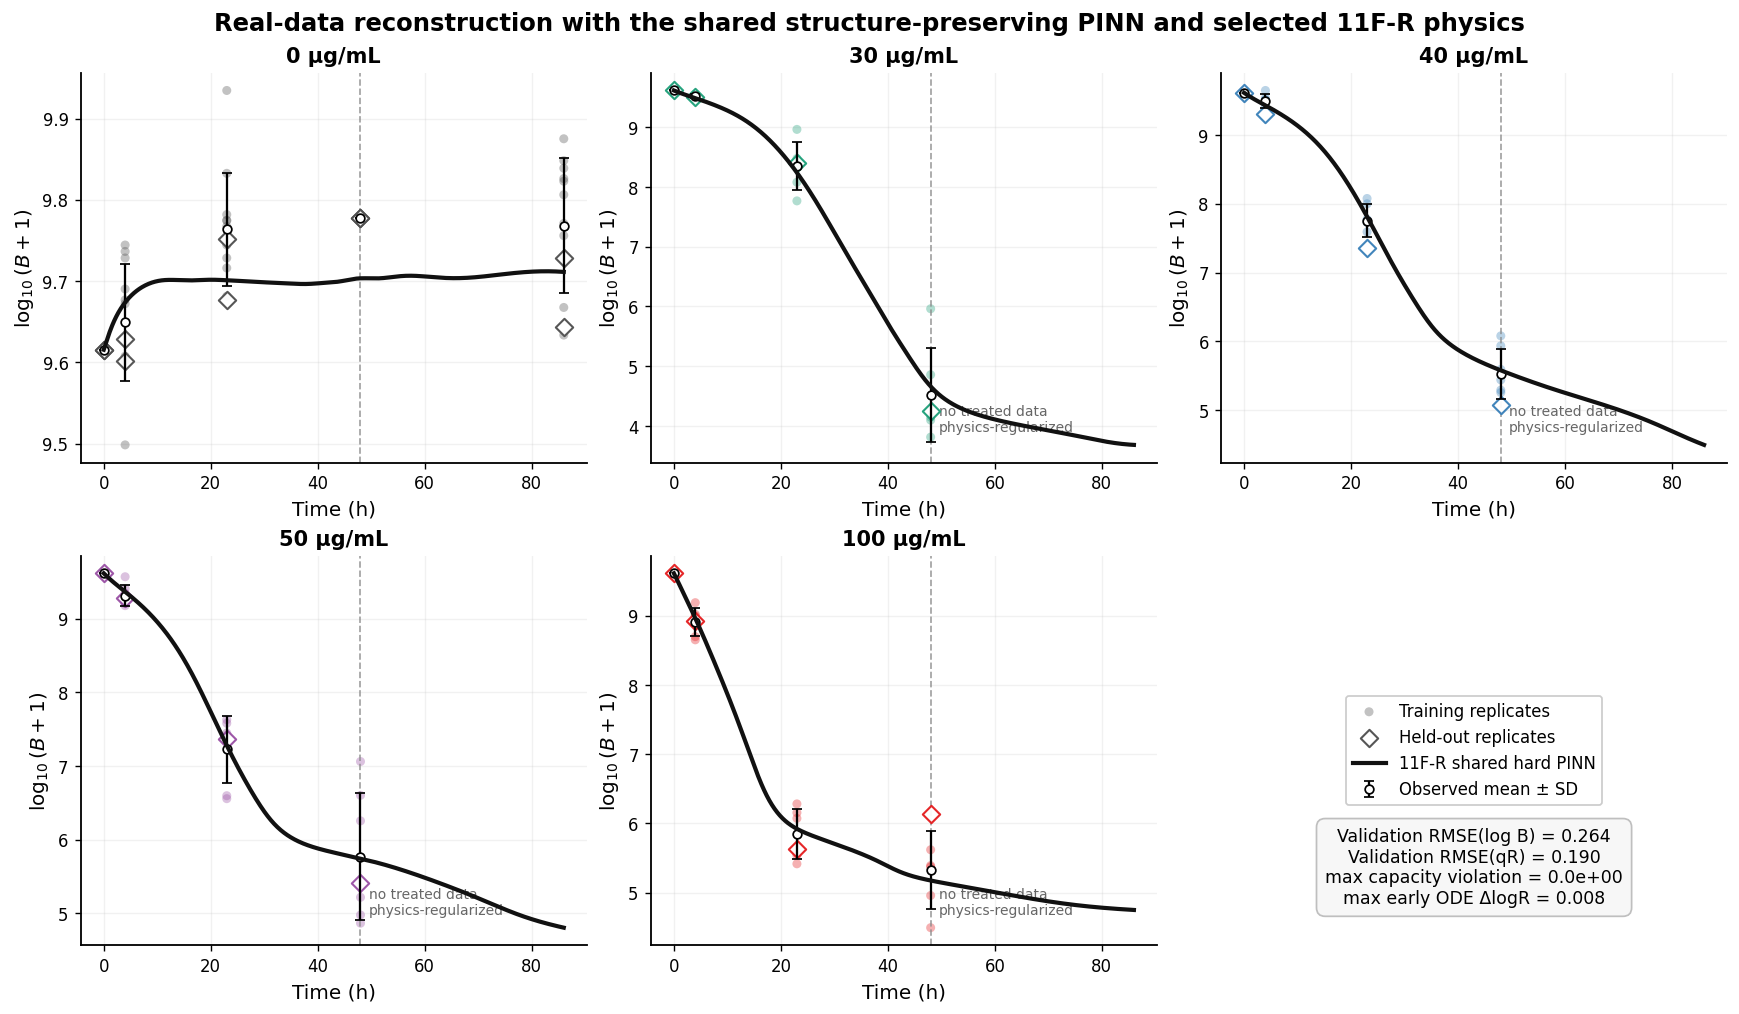

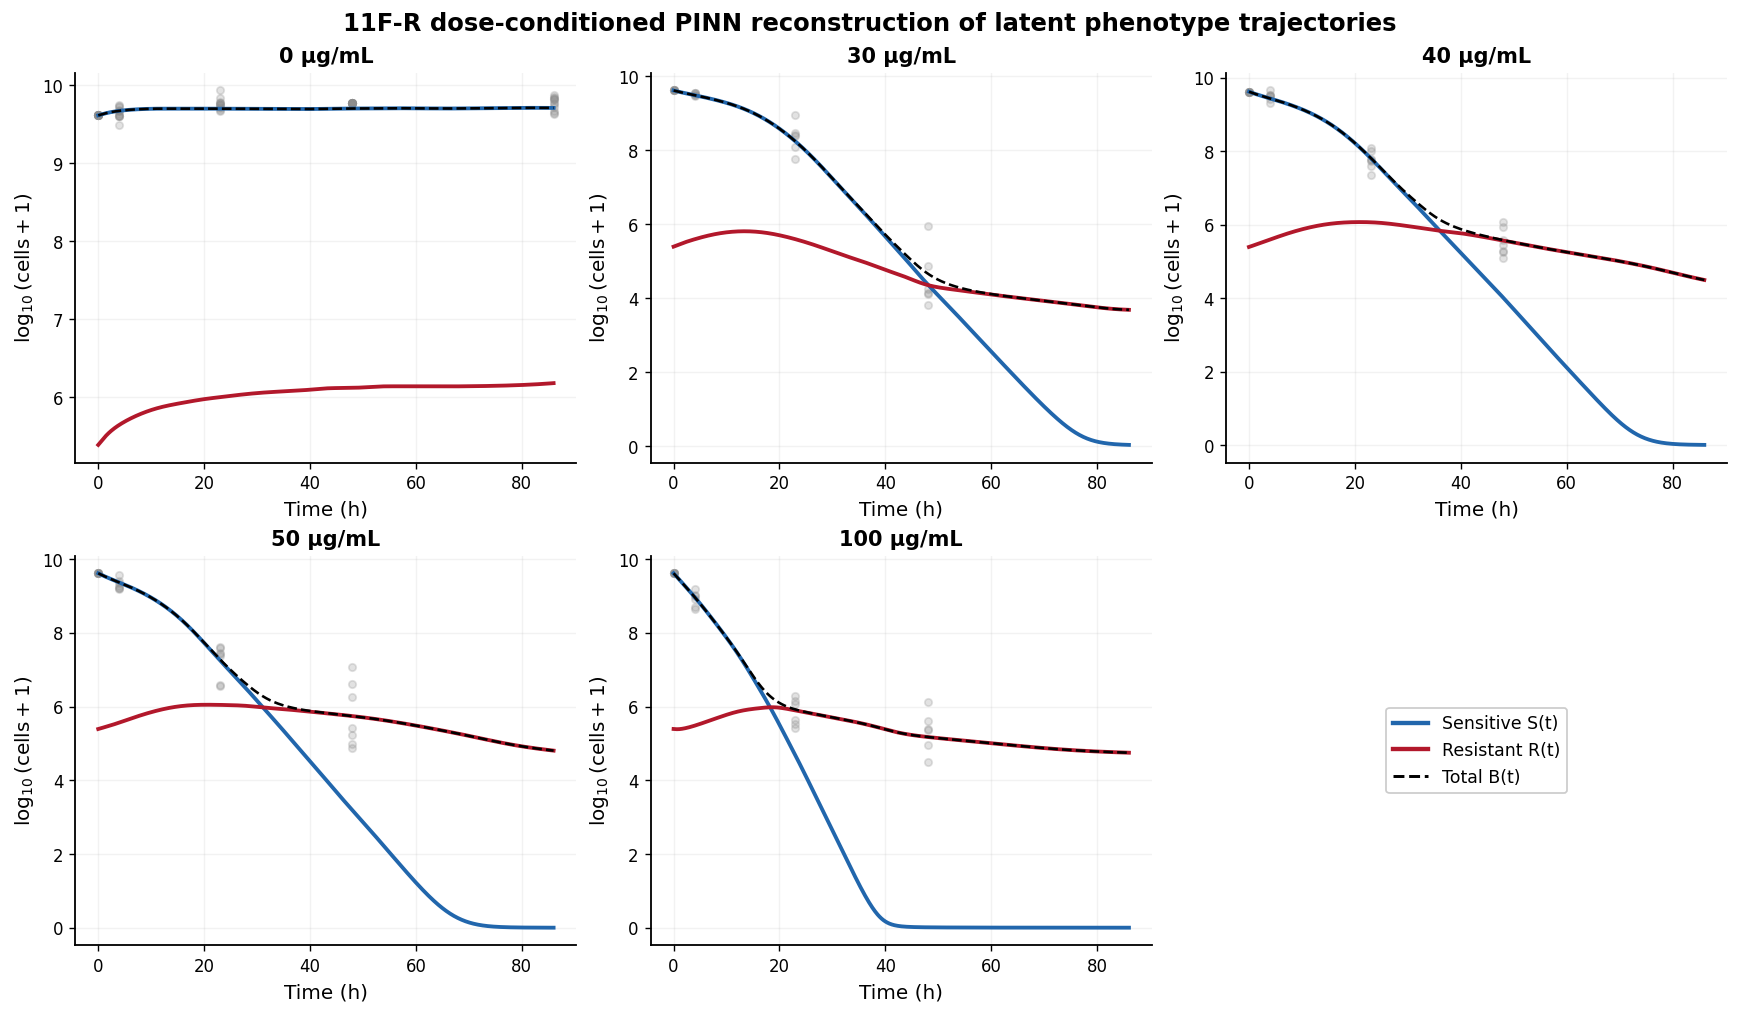

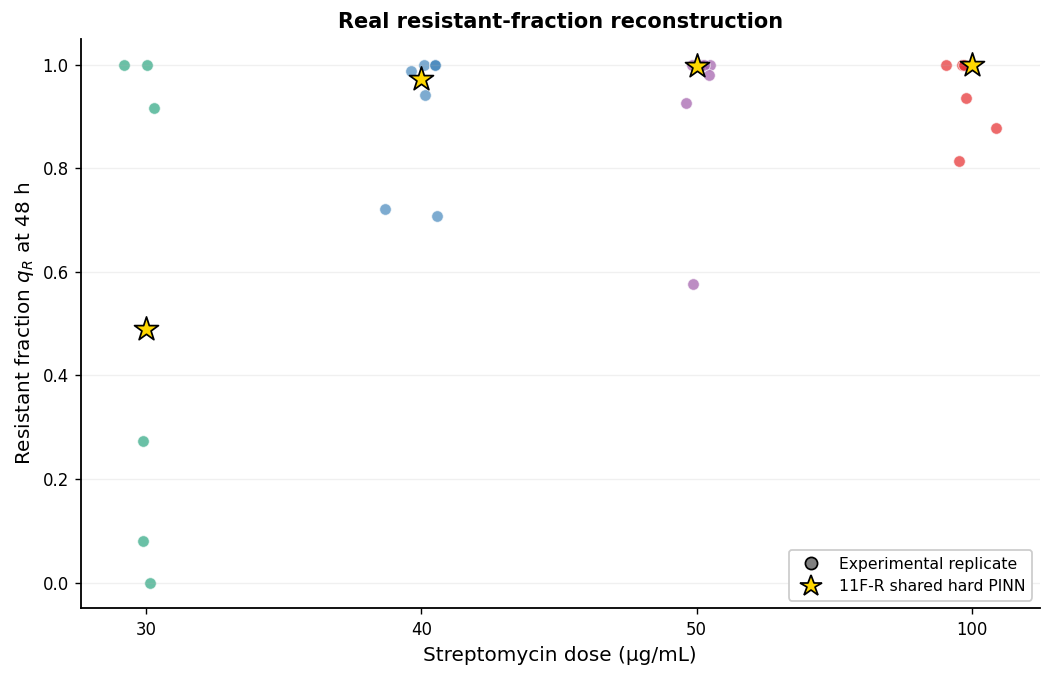

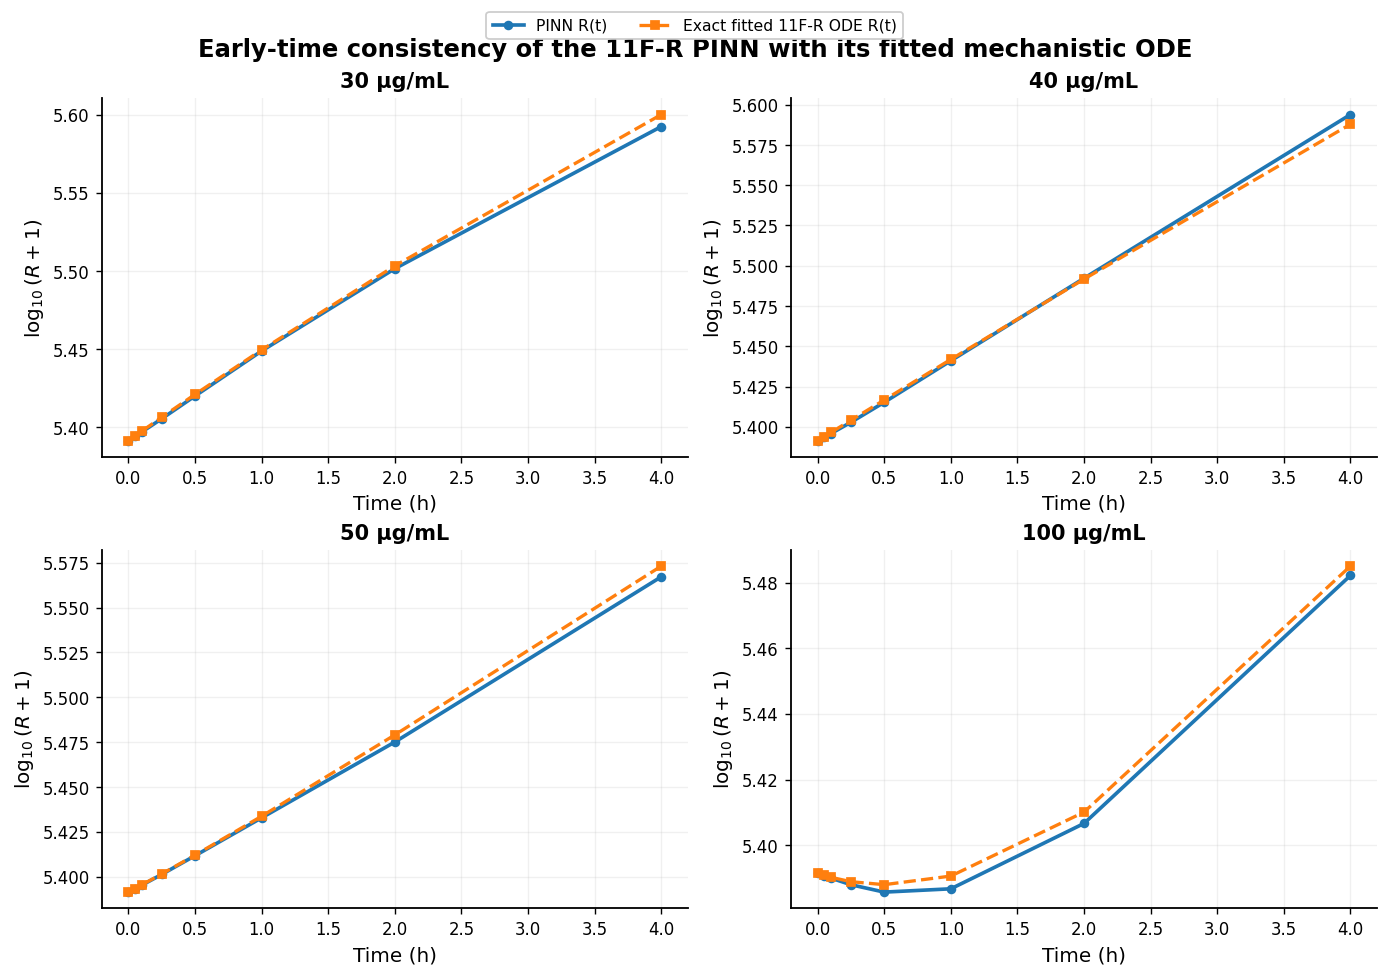

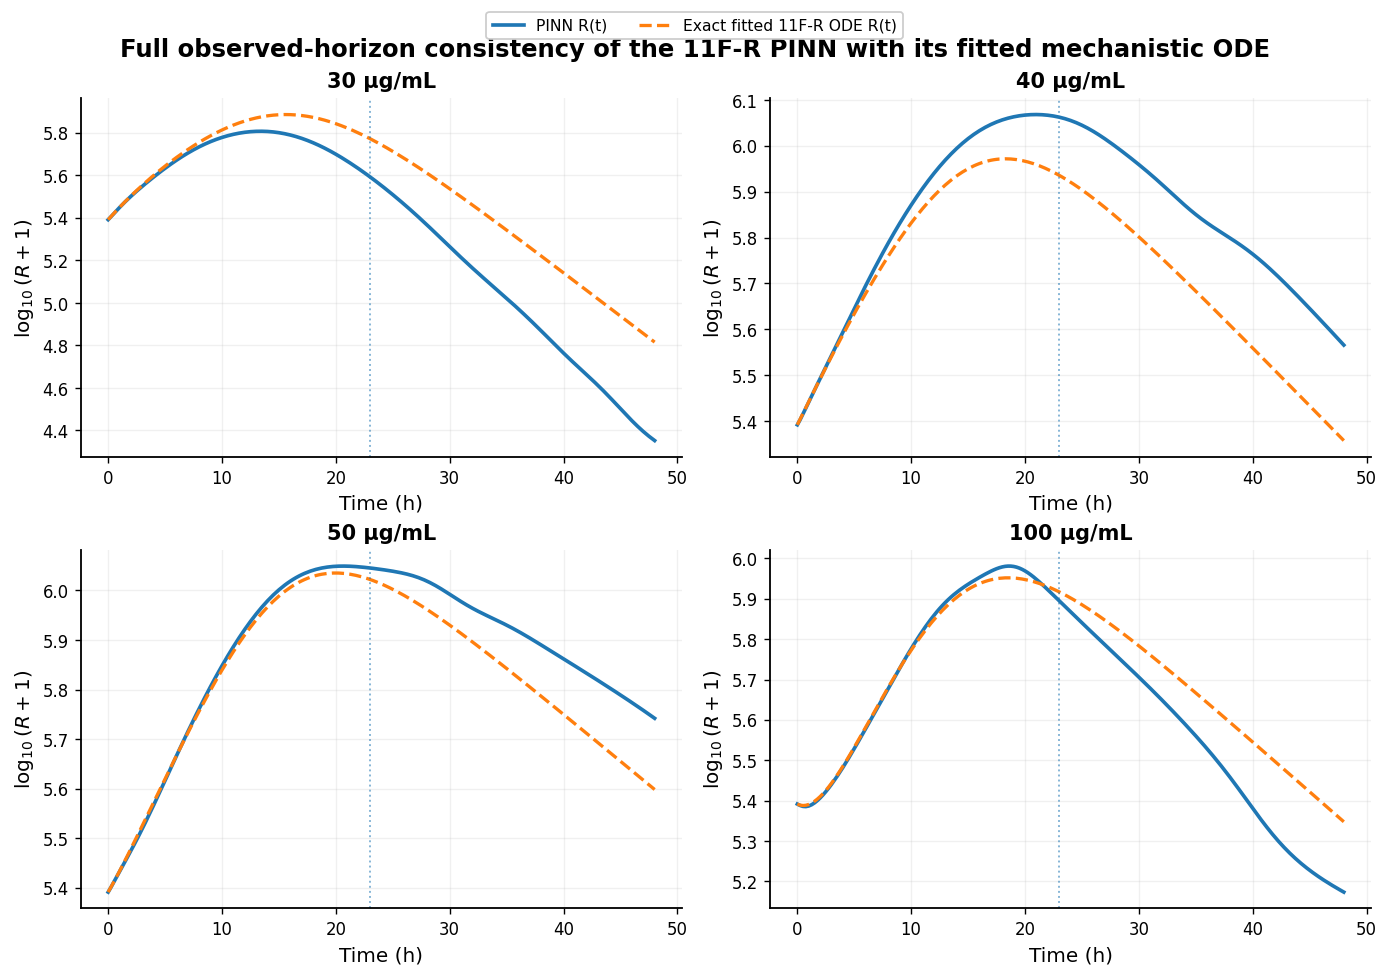

In [52]:
# CELL 8 — EXPERIMENT 3.7: FINAL REAL-DATA RECONSTRUCTION WITH THE
#          SHARED DOSE-CONDITIONED HARD PINN + SELECTED 11F-R PHYSICS
# =============================================================================
#
# Run AFTER the replacement Cells 5, 6, and 7.
#
# Neural architecture:
#
#       (time, dose) -> hard-feasible (S/K_REAL, R/K_REAL)
#
# Selected mechanistic physics:
#
#       H_K(t) = sigmoid(gamma_K * (t - tau_K))
#       G_R(t) = 1
#
#       dS/dt = b_S(1-mu)(1-S-R)S - [d0 + k_A H_K(t)]S
#
#       dR/dt = b_S mu(1-S-R)S + b_R(1-S-R)R
#               - [d0 + rho_R k_A H_K(t)]R
#
# Cell 7 appends "_11FR" to checkpoint/history filenames, so this run remains
# separate from the previous pre-11F-R R3.7 model.
# =============================================================================

FULL_LABEL = "R37_full_real_shared_dose_conditioned_PINN"
R37_TAG = "R37_shared_dose_conditioned_11FR"

EXPECTED_R37_ARCHITECTURE = "shared_dose_conditioned_hard_PINN_11FR"

_preflight_model = RealAMRPINN(
    BASE_BUNDLE
).to(
    DEVICE
)

if getattr(
    _preflight_model,
    "architecture_name",
    None,
) != EXPECTED_R37_ARCHITECTURE:
    raise RuntimeError(
        "Cell 8 expected the replacement 11F-R Cell 5, but found "
        f"{getattr(_preflight_model, 'architecture_name', None)!r}."
    )

if not hasattr(
    _preflight_model.inverse,
    "kill_activation",
):
    raise RuntimeError(
        "11F-R inverse-parameter methods are missing. Re-run replacement Cells 5 and 6."
    )

del _preflight_model
clear_memory()

print("=" * 100)
print("EXPERIMENT R3.7 — TRAINING FINAL SHARED HARD PINN WITH SELECTED 11F-R PHYSICS")
print("=" * 100)
print("Architecture :", EXPECTED_R37_ARCHITECTURE)
print("Physics      : 11F-R reduced time-structured killing")
print("Seed         :", SEED)
print("Old R3.7 checkpoint will NOT be overwritten.")
print("=" * 100)

FULL_RESULT = train_real_model(
    BASE_BUNDLE,
    seed=SEED,
    label=FULL_LABEL,
    hide_fraction_doses=set(),
    save_checkpoint=True,
    allow_overwrite_11fr=False,
)

if FULL_RESULT.model.architecture_name != EXPECTED_R37_ARCHITECTURE:
    raise RuntimeError(
        "Training completed with an unexpected architecture."
    )

# =============================================================================
# CORE OBSERVATION AND FEASIBILITY METRICS
# =============================================================================

train_metrics = observation_metrics(
    FULL_RESULT.model,
    BASE_BUNDLE,
    split="train",
)

val_metrics = observation_metrics(
    FULL_RESULT.model,
    BASE_BUNDLE,
    split="val",
)

feasibility = feasibility_audit(
    FULL_RESULT.model,
    BASE_BUNDLE.doses,
)

metric_table = pd.DataFrame(
    [
        {
            "split": "train",
            **train_metrics,
        },
        {
            "split": "validation",
            **val_metrics,
        },
    ]
)

# =============================================================================
# PERMANENT PHYSICS-FIDELITY AUDITS
# =============================================================================

physics_audit = physics_fidelity_audit(
    FULL_RESULT.model,
    BASE_BUNDLE.doses,
)

log_physics_audit = log_physics_fidelity_audit(
    FULL_RESULT.model,
    BASE_BUNDLE.doses,
    start_h=0.0,
    end_h=4.0,
)

loss_audit = loss_balance_audit(
    FULL_RESULT.model,
    BASE_BUNDLE,
)

ode_consistency_detail, ode_consistency_summary = exact_ode_consistency_audit(
    FULL_RESULT.model,
    BASE_BUNDLE,
    doses=[30.0, 40.0, 50.0, 100.0],
)


# =============================================================================
# DECISIVE 11F-R CONSISTENCY AUDIT: COMPLETE OBSERVED TREATED HORIZON 0–48 h
# =============================================================================
#
# The old model's important mechanistic mismatch occurred mainly during the
# later observed interval at intermediate treated doses. Therefore the 0–4 h
# audit above is retained, but it is not sufficient for accepting the new
# mechanism.
#
# No treated 86-h endpoint is used in this audit.
# =============================================================================

R37_FULL_OBSERVED_TIMES = np.unique(
    np.concatenate(
        [
            np.linspace(
                0.0,
                48.0,
                193,
            ),
            np.array(
                [
                    0.0,
                    2.0,
                    4.0,
                    8.0,
                    12.0,
                    16.0,
                    20.0,
                    23.0,
                    26.0,
                    30.0,
                    36.0,
                    40.0,
                    44.0,
                    48.0,
                ],
                dtype=float,
            ),
        ]
    )
)

(
    ode_consistency_0_48_detail,
    ode_consistency_0_48_summary,
) = exact_ode_consistency_audit(
    FULL_RESULT.model,
    BASE_BUNDLE,
    doses=[
        30.0,
        40.0,
        50.0,
        100.0,
    ],
    check_times=R37_FULL_OBSERVED_TIMES,
)

late_23_48_detail = (
    ode_consistency_0_48_detail[
        ode_consistency_0_48_detail[
            "time_h"
        ] >= 23.0
    ]
    .copy()
)

late_23_48_summary = (
    late_23_48_detail
    .groupby(
        "dose_ug_ml"
    )
    .agg(
        mean_abs_logS_difference_23_48h=(
            "abs_difference_logS",
            "mean",
        ),
        max_abs_logS_difference_23_48h=(
            "abs_difference_logS",
            "max",
        ),
        mean_abs_logR_difference_23_48h=(
            "abs_difference_logR",
            "mean",
        ),
        max_abs_logR_difference_23_48h=(
            "abs_difference_logR",
            "max",
        ),
    )
    .reset_index()
)

# =============================================================================
# SAVE TABLES
# =============================================================================

metric_table.to_csv(
    TABLE_DIR / f"{RUN_LABEL}_{R37_TAG}_metrics.csv",
    index=False,
)

feasibility.to_csv(
    TABLE_DIR / f"{RUN_LABEL}_{R37_TAG}_feasibility_audit.csv",
    index=False,
)

physics_audit.to_csv(
    TABLE_DIR / f"{RUN_LABEL}_{R37_TAG}_physics_audit.csv",
    index=False,
)

log_physics_audit.to_csv(
    TABLE_DIR / f"{RUN_LABEL}_{R37_TAG}_log_physics_audit_0_4h.csv",
    index=False,
)

loss_audit.to_csv(
    TABLE_DIR / f"{RUN_LABEL}_{R37_TAG}_loss_balance.csv",
    index=False,
)

ode_consistency_detail.to_csv(
    TABLE_DIR / f"{RUN_LABEL}_{R37_TAG}_exact_ODE_consistency_detail.csv",
    index=False,
)

ode_consistency_summary.to_csv(
    TABLE_DIR / f"{RUN_LABEL}_{R37_TAG}_exact_ODE_consistency_summary.csv",
    index=False,
)


ode_consistency_0_48_detail.to_csv(
    TABLE_DIR / f"{RUN_LABEL}_{R37_TAG}_exact_ODE_consistency_0_48h_detail.csv",
    index=False,
)

ode_consistency_0_48_summary.to_csv(
    TABLE_DIR / f"{RUN_LABEL}_{R37_TAG}_exact_ODE_consistency_0_48h_summary.csv",
    index=False,
)

late_23_48_summary.to_csv(
    TABLE_DIR / f"{RUN_LABEL}_{R37_TAG}_exact_ODE_consistency_23_48h_summary.csv",
    index=False,
)

# =============================================================================
# PRINT / DISPLAY AUDIT RESULTS
# =============================================================================

print("Architecture:")
print(FULL_RESULT.model.architecture_name)

print("\nInferred parameters:")
display(
    pd.DataFrame(
        [
            FULL_RESULT.model.inferred_parameters()
        ]
    )
)

print("\nObservation metrics:")
display(
    metric_table
)

print("\nHard-feasibility audit:")
display(
    feasibility
)

print("\nAbsolute physics-fidelity audit:")
display(
    physics_audit
)

print("\nEarly-time log-state physics audit (0–4 h):")
display(
    log_physics_audit
)

print("\nLoss balance:")
display(
    loss_audit
)

print("\nPINN vs exact fitted 11F-R ODE consistency summary (0–4 h):")
display(
    ode_consistency_summary
)


print("\nPINN vs exact fitted 11F-R ODE consistency summary (0–48 h):")
display(
    ode_consistency_0_48_summary
)

print("\nFocused PINN vs exact 11F-R ODE consistency (23–48 h):")
display(
    late_23_48_summary
)

# =============================================================================
# Figure R3.7A — total-load reconstruction on the experimental scale
# =============================================================================

fig, axes = plt.subplots(
    2,
    3,
    figsize=(13.8, 8.0),
    constrained_layout=True,
)

axes = axes.ravel()

grid = np.linspace(
    0.0,
    PHYSICS_HORIZON_H,
    700,
)

for idx, dose in enumerate(
    BASE_BUNDLE.doses
):

    ax = axes[idx]

    dose_df = BASE_BUNDLE.total[
        BASE_BUNDLE.total[
            "dose_ug_ml"
        ] == dose
    ]

    pred = predict_numpy(
        FULL_RESULT.model,
        dose,
        grid,
    )

    train_df = dose_df[
        dose_df[
            "split"
        ] == "train"
    ]

    val_df = dose_df[
        dose_df[
            "split"
        ] == "val"
    ]

    ax.scatter(
        train_df["time_h"],
        train_df["log10_population_plus1"],
        s=27,
        alpha=0.34,
        color=DOSE_COLORS[dose],
        edgecolor="none",
        label="Training replicates",
        zorder=2,
    )

    ax.scatter(
        val_df["time_h"],
        val_df["log10_population_plus1"],
        s=50,
        alpha=0.95,
        marker="D",
        facecolor="white",
        edgecolor=DOSE_COLORS[dose],
        linewidth=1.2,
        label="Held-out replicates",
        zorder=4,
    )

    stats = (
        dose_df
        .groupby(
            "time_h"
        )[
            "log10_population_plus1"
        ]
        .agg(
            [
                "mean",
                "std",
            ]
        )
        .reset_index()
    )

    ax.errorbar(
        stats["time_h"],
        stats["mean"],
        yerr=stats["std"],
        fmt="o",
        color="black",
        markerfacecolor="white",
        capsize=3,
        markersize=5,
        linewidth=1.3,
        zorder=5,
        label="Observed mean ± SD",
    )

    ax.plot(
        pred["time_h"],
        pred["log10_total_plus1"],
        color=MODEL_COLOR,
        linewidth=2.4,
        label="11F-R shared hard PINN",
        zorder=6,
    )

    ax.axvline(
        48.0,
        color="0.55",
        linestyle="--",
        linewidth=1.0,
        alpha=0.8,
    )

    if dose > 0:
        y0, y1 = ax.get_ylim()
        ax.text(
            49.5,
            y0 + 0.08 * (y1 - y0),
            "no treated data\nphysics-regularized",
            color="0.40",
            fontsize=8,
        )

    ax.set_title(
        f"{dose:g} µg/mL",
        fontweight="bold",
    )

    ax.set_xlabel(
        "Time (h)"
    )

    ax.set_ylabel(
        r"$\log_{10}(B+1)$"
    )

    ax.grid(
        alpha=0.17
    )

    ax.spines[
        [
            "top",
            "right",
        ]
    ].set_visible(
        False
    )

axes[5].axis(
    "off"
)

handles, labels = axes[0].get_legend_handles_labels()

axes[5].legend(
    handles,
    labels,
    loc="center",
    frameon=True,
    fontsize=9.5,
)

axes[5].text(
    0.5,
    0.20,
    f"Validation RMSE(log B) = {val_metrics['rmse_logB']:.3f}\n"
    f"Validation RMSE(qR) = {val_metrics['rmse_qR']:.3f}\n"
    f"max capacity violation = {feasibility['capacity_violation'].max():.1e}\n"
    f"max early ODE ΔlogR = {ode_consistency_summary['max_abs_logR_difference'].max():.3f}",
    ha="center",
    va="center",
    fontsize=10.0,
    bbox=dict(
        boxstyle="round,pad=0.5",
        facecolor="#F7F7F7",
        edgecolor="0.75",
    ),
)

fig.suptitle(
    "Real-data reconstruction with the shared structure-preserving PINN and selected 11F-R physics",
    fontsize=14,
    fontweight="bold",
)

save_figure(
    fig,
    f"{RUN_LABEL}_{R37_TAG}_total_load_reconstruction",
)

plt.show()

# =============================================================================
# Figure R3.7B — latent sensitive/resistant trajectories
# =============================================================================

fig, axes = plt.subplots(
    2,
    3,
    figsize=(13.8, 8.0),
    constrained_layout=True,
)

axes = axes.ravel()

for idx, dose in enumerate(
    BASE_BUNDLE.doses
):

    ax = axes[idx]

    pred = predict_numpy(
        FULL_RESULT.model,
        dose,
        grid,
    )

    ax.plot(
        grid,
        np.log10(
            pred["sensitive"]
            + 1.0
        ),
        color=SENSITIVE_COLOR,
        linewidth=2.2,
        label="Sensitive S(t)",
    )

    ax.plot(
        grid,
        np.log10(
            pred["resistant"]
            + 1.0
        ),
        color=RESISTANT_COLOR,
        linewidth=2.2,
        label="Resistant R(t)",
    )

    ax.plot(
        grid,
        pred["log10_total_plus1"],
        color="black",
        linestyle="--",
        linewidth=1.5,
        label="Total B(t)",
    )

    dose_obs = BASE_BUNDLE.total[
        BASE_BUNDLE.total[
            "dose_ug_ml"
        ] == dose
    ]

    ax.scatter(
        dose_obs["time_h"],
        dose_obs["log10_population_plus1"],
        s=18,
        color="0.55",
        alpha=0.25,
        zorder=1,
    )

    ax.set_title(
        f"{dose:g} µg/mL",
        fontweight="bold",
    )

    ax.set_xlabel(
        "Time (h)"
    )

    ax.set_ylabel(
        r"$\log_{10}(\mathrm{cells}+1)$"
    )

    ax.grid(
        alpha=0.16
    )

    ax.spines[
        [
            "top",
            "right",
        ]
    ].set_visible(
        False
    )

axes[5].axis(
    "off"
)

handles = [
    Line2D(
        [0],
        [0],
        color=SENSITIVE_COLOR,
        lw=2.5,
        label="Sensitive S(t)",
    ),
    Line2D(
        [0],
        [0],
        color=RESISTANT_COLOR,
        lw=2.5,
        label="Resistant R(t)",
    ),
    Line2D(
        [0],
        [0],
        color="black",
        lw=1.7,
        ls="--",
        label="Total B(t)",
    ),
]

axes[5].legend(
    handles=handles,
    loc="center",
    fontsize=10,
)

fig.suptitle(
    "11F-R dose-conditioned PINN reconstruction of latent phenotype trajectories",
    fontsize=14,
    fontweight="bold",
)

save_figure(
    fig,
    f"{RUN_LABEL}_{R37_TAG}_latent_states",
)

plt.show()

# =============================================================================
# Figure R3.7C — observed vs fitted resistant fraction at 48 h
# =============================================================================

fig, ax = plt.subplots(
    figsize=(8.3, 5.3),
    constrained_layout=True,
)

rng = np.random.default_rng(
    SEED
)

for x, dose in enumerate(
    [
        30.0,
        40.0,
        50.0,
        100.0,
    ]
):

    obs = q48.loc[
        q48[
            "dose_ug_ml"
        ] == dose,
        "resistant_fraction_qR",
    ].to_numpy(
        float
    )

    jitter = rng.normal(
        0.0,
        0.055,
        size=len(obs),
    )

    ax.scatter(
        np.full(
            len(obs),
            x,
        ) + jitter,
        obs,
        s=45,
        color=DOSE_COLORS[dose],
        alpha=0.65,
        edgecolor="white",
        linewidth=0.6,
    )

    pred_q = float(
        predict_numpy(
            FULL_RESULT.model,
            dose,
            np.array(
                [48.0]
            ),
        )[
            "resistant_fraction"
        ].iloc[0]
    )

    ax.scatter(
        x,
        pred_q,
        marker="*",
        s=210,
        facecolor="gold",
        edgecolor="black",
        linewidth=1.0,
        zorder=6,
    )

ax.set_xticks(
    range(4),
    [
        "30",
        "40",
        "50",
        "100",
    ],
)

ax.set_xlabel(
    "Streptomycin dose (µg/mL)"
)

ax.set_ylabel(
    r"Resistant fraction $q_R$ at 48 h"
)

ax.set_ylim(
    -0.05,
    1.05,
)

ax.grid(
    axis="y",
    alpha=0.18,
)

ax.spines[
    [
        "top",
        "right",
    ]
].set_visible(
    False
)

ax.legend(
    handles=[
        Line2D(
            [0],
            [0],
            marker="o",
            color="none",
            markerfacecolor="0.5",
            label="Experimental replicate",
            markersize=7,
        ),
        Line2D(
            [0],
            [0],
            marker="*",
            color="none",
            markerfacecolor="gold",
            markeredgecolor="black",
            label="11F-R shared hard PINN",
            markersize=13,
        ),
    ],
    loc="lower right",
)

ax.set_title(
    "Real resistant-fraction reconstruction",
    fontweight="bold",
)

save_figure(
    fig,
    f"{RUN_LABEL}_{R37_TAG}_qR_reconstruction",
)

plt.show()

# =============================================================================
# Figure R3.7D — exact fitted-ODE consistency in the critical 0–4 h interval
# =============================================================================

fig, axes = plt.subplots(
    2,
    2,
    figsize=(11.0, 7.5),
    constrained_layout=True,
)

axes = axes.ravel()

for ax, dose in zip(
    axes,
    [
        30.0,
        40.0,
        50.0,
        100.0,
    ],
):

    subset = ode_consistency_detail[
        ode_consistency_detail[
            "dose_ug_ml"
        ] == dose
    ]

    ax.plot(
        subset["time_h"],
        subset["PINN_log10_R_plus1"],
        marker="o",
        linestyle="-",
        linewidth=2.1,
        markersize=4.5,
        label="PINN R(t)",
    )

    ax.plot(
        subset["time_h"],
        subset["ODE_log10_R_plus1"],
        marker="s",
        linestyle="--",
        linewidth=1.9,
        markersize=4.5,
        label="Exact fitted 11F-R ODE R(t)",
    )

    ax.set_title(
        f"{dose:g} µg/mL",
        fontweight="bold",
    )

    ax.set_xlabel(
        "Time (h)"
    )

    ax.set_ylabel(
        r"$\log_{10}(R+1)$"
    )

    ax.grid(
        alpha=0.18
    )

    ax.spines[
        [
            "top",
            "right",
        ]
    ].set_visible(
        False
    )

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=2,
    bbox_to_anchor=(
        0.5,
        1.03,
    ),
)

fig.suptitle(
    "Early-time consistency of the 11F-R PINN with its fitted mechanistic ODE",
    fontsize=14,
    fontweight="bold",
)

save_figure(
    fig,
    f"{RUN_LABEL}_{R37_TAG}_exact_ODE_consistency",
)

plt.show()


# =============================================================================
# Figure R3.7E — FULL 0–48 h PINN / exact fitted 11F-R ODE consistency
# =============================================================================

fig, axes = plt.subplots(
    2,
    2,
    figsize=(11.0, 7.5),
    constrained_layout=True,
)

axes = axes.ravel()

for ax, dose in zip(
    axes,
    [
        30.0,
        40.0,
        50.0,
        100.0,
    ],
):

    subset = (
        ode_consistency_0_48_detail[
            ode_consistency_0_48_detail[
                "dose_ug_ml"
            ] == dose
        ]
        .sort_values(
            "time_h"
        )
    )

    ax.plot(
        subset["time_h"],
        subset["PINN_log10_R_plus1"],
        linestyle="-",
        linewidth=2.1,
        label="PINN R(t)",
    )

    ax.plot(
        subset["time_h"],
        subset["ODE_log10_R_plus1"],
        linestyle="--",
        linewidth=1.9,
        label="Exact fitted 11F-R ODE R(t)",
    )

    ax.axvline(
        23.0,
        linestyle=":",
        linewidth=1.1,
        alpha=0.55,
    )

    ax.set_title(
        f"{dose:g} µg/mL",
        fontweight="bold",
    )

    ax.set_xlabel(
        "Time (h)"
    )

    ax.set_ylabel(
        r"$\log_{10}(R+1)$"
    )

    ax.grid(
        alpha=0.18
    )

    ax.spines[
        [
            "top",
            "right",
        ]
    ].set_visible(
        False
    )

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=2,
    bbox_to_anchor=(
        0.5,
        1.03,
    ),
)

fig.suptitle(
    "Full observed-horizon consistency of the 11F-R PINN with its fitted mechanistic ODE",
    fontsize=14,
    fontweight="bold",
)

save_figure(
    fig,
    f"{RUN_LABEL}_{R37_TAG}_exact_ODE_consistency_0_48h",
)

plt.show()

In [53]:
# =============================================================================
# AUDIT B — FINAL R3.7 11F-R PARAMETER / PERFORMANCE / FEASIBILITY SUMMARY
# =============================================================================
# Run AFTER Audit A.
# NO training is performed.
# =============================================================================

if "FULL_RESULT" not in globals():
    raise RuntimeError(
        "FULL_RESULT is not available. Train or recover FINAL R3.7 11F-R first."
    )

if QUICK_MODE:
    raise RuntimeError(
        "This summary is intended for the FINAL run, but QUICK_MODE=True."
    )

EXPECTED_R37_ARCHITECTURE = (
    "shared_dose_conditioned_hard_PINN_11FR"
)

if FULL_RESULT.model.architecture_name != EXPECTED_R37_ARCHITECTURE:
    raise RuntimeError(
        "Audit B received a non-11F-R model."
    )

R37_AUDIT_TAG = "R37_shared_dose_conditioned_11FR"

print("=" * 100)
print("FINAL R3.7 11F-R AUDIT B — PARAMETER / PERFORMANCE / FEASIBILITY SUMMARY")
print("=" * 100)

print(
    "Architecture:",
    FULL_RESULT.model.architecture_name,
)


# =============================================================================
# 1. Inferred parameters
# =============================================================================

final_parameters = (
    FULL_RESULT.model
    .inferred_parameters()
)

parameter_table = pd.DataFrame(
    [
        final_parameters
    ]
)

print("\nInferred 11F-R parameters:")
display(
    parameter_table
)


# =============================================================================
# 2. Explicit shared-q0 audit
# =============================================================================

q0_shared = float(
    final_parameters[
        "initial_resistant_fraction_shared"
    ]
)

q0_alias_keys = [
    key
    for key in final_parameters
    if key.startswith(
        "q0_dose_"
    )
]

q0_alias_values = np.array(
    [
        float(
            final_parameters[
                key
            ]
        )
        for key in q0_alias_keys
    ],
    dtype=float,
)

if len(
    q0_alias_values
) > 0:

    q0_max_difference = float(
        np.max(
            np.abs(
                q0_alias_values
                - q0_shared
            )
        )
    )

else:
    q0_max_difference = 0.0

if q0_max_difference > 1e-12:
    raise RuntimeError(
        "Shared-q0 audit failed: dose aliases are not identical."
    )

print(
    f"\nShared initial resistant fraction q0 = {q0_shared:.8e}"
)

print(
    f"Maximum q0 alias discrepancy         = {q0_max_difference:.3e}"
)


# =============================================================================
# 3. 11F-R pharmacodynamic parameter sanity table
# =============================================================================

required_11fr_keys = [
    "mutation_probability",
    "resistance_fitness_cost",
    "sensitive_birth_rate_per_h",
    "baseline_death_rate_per_h",
    "initial_resistant_fraction_shared",
    "resistant_relative_drug_sensitivity",
    "kill_activation_onset_h",
    "kill_activation_per_h",
]

for dose in BASE_BUNDLE.doses:

    if not np.isclose(
        float(dose),
        0.0,
    ):
        required_11fr_keys.append(
            f"kill_{int(round(float(dose)))}_per_h"
        )

missing_11fr_keys = [
    key
    for key in required_11fr_keys
    if key not in final_parameters
]

if missing_11fr_keys:
    raise RuntimeError(
        "Missing selected 11F-R parameter outputs: "
        + ", ".join(
            missing_11fr_keys
        )
    )


# =============================================================================
# 4. Observation metrics
# =============================================================================

train_metrics = observation_metrics(
    FULL_RESULT.model,
    BASE_BUNDLE,
    split="train",
)

val_metrics = observation_metrics(
    FULL_RESULT.model,
    BASE_BUNDLE,
    split="val",
)

metric_table = pd.DataFrame(
    [
        {
            "split":
                "train",
            **train_metrics,
        },
        {
            "split":
                "validation",
            **val_metrics,
        },
    ]
)

print("\nObservation metrics:")
display(
    metric_table
)


# =============================================================================
# 5. Hard-feasibility audit
# =============================================================================

feasibility = feasibility_audit(
    FULL_RESULT.model,
    BASE_BUNDLE.doses,
)

print("\nHard-feasibility audit:")
display(
    feasibility
)


max_negative_violation = float(
    feasibility[
        "negative_violation"
    ].max()
)

max_capacity_violation = float(
    feasibility[
        "capacity_violation"
    ].max()
)

if max_negative_violation > 1e-12:
    raise RuntimeError(
        "FINAL 11F-R model failed the non-negativity audit."
    )

if max_capacity_violation > 1e-12:
    raise RuntimeError(
        "FINAL 11F-R model failed the capacity audit."
    )

print(
    "\nMaximum negative violation :",
    f"{max_negative_violation:.3e}",
)

print(
    "Maximum capacity violation :",
    f"{max_capacity_violation:.3e}",
)

print(
    "Hard-feasibility audit      : PASSED"
)


# =============================================================================
# 6. Save canonical FINAL 11F-R summary tables
# =============================================================================

parameter_table.to_csv(
    TABLE_DIR / f"{RUN_LABEL}_{R37_AUDIT_TAG}_parameters.csv",
    index=False,
)

metric_table.to_csv(
    TABLE_DIR / f"{RUN_LABEL}_{R37_AUDIT_TAG}_observation_metrics.csv",
    index=False,
)

feasibility.to_csv(
    TABLE_DIR / f"{RUN_LABEL}_{R37_AUDIT_TAG}_feasibility_audit.csv",
    index=False,
)

print("\nSaved FINAL 11F-R parameter, metric, and feasibility tables.")
print("=" * 100)

FINAL R3.7 11F-R AUDIT B — PARAMETER / PERFORMANCE / FEASIBILITY SUMMARY
Architecture: shared_dose_conditioned_hard_PINN_11FR

Inferred 11F-R parameters:


,mutation_probability,resistance_fitness_cost,sensitive_birth_rate_per_h,baseline_death_rate_per_h,death_rate_per_h,initial_resistant_fraction_shared,resistant_relative_drug_sensitivity,kill_activation_onset_h,kill_activation_per_h,q0_dose_0,q0_dose_30,kill_30_per_h,q0_dose_40,kill_40_per_h,q0_dose_50,kill_50_per_h,q0_dose_100,kill_100_per_h
0,0.000031,0.105998,0.646118,0.350002,0.350002,0.00006,0.667814,13.665092,0.224483,0.00006,0.00006,0.455861,0.00006,0.393706,0.00006,0.363276,0.00006,0.339857



Shared initial resistant fraction q0 = 5.97068570e-05
Maximum q0 alias discrepancy         = 0.000e+00

Observation metrics:


,split,rmse_logB,mae_logB,r2_logB,rmse_qR,mae_qR
0,train,0.299867,0.171927,0.969207,0.202530,0.107679
1,validation,0.264456,0.149420,0.976411,0.190222,0.109327



Hard-feasibility audit:


,dose_ug_ml,min_s_over_K,min_r_over_K,max_total_over_K,negative_violation,capacity_violation
0,0.0,3.689404e-01,2.202959e-05,0.460831,0.0,0.0
1,30.0,6.215434e-12,4.305600e-07,0.368962,0.0,0.0
2,40.0,1.407403e-12,2.786341e-06,0.368962,0.0,0.0
3,50.0,6.352718e-13,5.714497e-06,0.368962,0.0,0.0
4,100.0,2.339956e-13,5.000796e-06,0.368962,0.0,0.0



Maximum negative violation : 0.000e+00
Maximum capacity violation : 0.000e+00
Hard-feasibility audit      : PASSED

Saved FINAL 11F-R parameter, metric, and feasibility tables.


In [54]:
# DIAGNOSTIC P1 — 11F-R STATE-ONLY PHYSICS-STRENGTHENING CONTINUATION
# =============================================================================
# Run AFTER the completed Cell 8 + Audit B.
#
# Goal:
#   Freeze all 12 inverse parameters and refine ONLY the shared state network
#   under a 5x stronger version of the existing Cell-6 physics objective.
#
# Important:
#   - FULL_RESULT is NOT overwritten.
#   - Original 11F-R checkpoint is NOT overwritten.
#   - No equation or biological parameter is changed.
#   - Result is stored separately as PHYSICS_REFINED_RESULT.
# =============================================================================

import time
import numpy as np
import pandas as pd
import torch

if "FULL_RESULT" not in globals():
    raise RuntimeError("FULL_RESULT is missing. Finish/restore FINAL R3.7 11F-R first.")

if QUICK_MODE:
    raise RuntimeError("Set QUICK_MODE=False for this FINAL diagnostic.")

EXPECTED_ARCH = "shared_dose_conditioned_hard_PINN_11FR"
if FULL_RESULT.model.architecture_name != EXPECTED_ARCH:
    raise RuntimeError(
        f"Expected {EXPECTED_ARCH!r}, found {FULL_RESULT.model.architecture_name!r}."
    )

# -----------------------------------------------------------------------------
# Fixed diagnostic settings — do not tune these after seeing the result.
# -----------------------------------------------------------------------------
PHYSICS_STRENGTH_FACTOR = 5.0
REFINE_EPOCHS = 1800
REFINE_LR = 2.0e-4
REFINE_LOG_EVERY = 100
REFINE_PATIENCE = 600
REFINE_LBFGS_MAX_ITER = 200
REFINE_TAG = "R37_11FR_stateonly_physics_refine_x5"

REFINE_CKPT = MODEL_DIR / f"{RUN_LABEL}_{REFINE_TAG}.pt"
REFINE_HISTORY = HISTORY_DIR / f"{RUN_LABEL}_{REFINE_TAG}_history.csv"

if REFINE_CKPT.exists():
    raise FileExistsError(
        f"Refinement checkpoint already exists:\n{REFINE_CKPT}\n"
        "It was not overwritten."
    )

# -----------------------------------------------------------------------------
# Clone current completed 11F-R model.
# -----------------------------------------------------------------------------
refined_model = RealAMRPINN(BASE_BUNDLE).to(DEVICE)
refined_model.load_state_dict(cpu_state_dict(FULL_RESULT.model), strict=True)

inverse_before = refined_model.inferred_parameters()

# Freeze ALL inverse parameters.
set_inverse_trainable(refined_model, False)

if any(p.requires_grad for p in refined_model.inverse.parameters()):
    raise RuntimeError("Inverse-parameter freeze failed.")

print("=" * 105)
print("DIAGNOSTIC P1 — STATE-ONLY 11F-R PHYSICS STRENGTHENING")
print("=" * 105)
print("Architecture            :", refined_model.architecture_name)
print("Physics multiplier      :", PHYSICS_STRENGTH_FACTOR)
print("Inverse parameters      : FROZEN")
print("Trainable state params  :", sum(p.numel() for p in state_parameters(refined_model)))
print("Adam epochs             :", REFINE_EPOCHS)
print("Adam LR                 :", REFINE_LR)
print("L-BFGS max iterations   :", REFINE_LBFGS_MAX_ITER)
print("New checkpoint          :", REFINE_CKPT)
print("=" * 105)

# -----------------------------------------------------------------------------
# Baseline metrics.
# -----------------------------------------------------------------------------
baseline_val = observation_metrics(
    FULL_RESULT.model, BASE_BUNDLE, split="val"
)
baseline_feas = feasibility_audit(
    FULL_RESULT.model, BASE_BUNDLE.doses
)

# Fixed validation collocation for fair checkpoint selection.
fixed_val_collocation = make_collocation(
    BASE_BUNDLE.doses,
    seed=SEED + 610_000,
    points_per_dose=max(128, COLLOCATION_POINTS_PER_DOSE // 2),
)

def strong_val_score(model):
    total, comp = complete_loss(
        model=model,
        bundle=BASE_BUNDLE,
        collocation=fixed_val_collocation,
        split="val",
        physics_weight=PHYSICS_STRENGTH_FACTOR,
        hide_fraction_doses=None,
    )
    return float(total.detach().cpu()), comp

# -----------------------------------------------------------------------------
# Stage P1-A — Adam, state network only.
# -----------------------------------------------------------------------------
optimizer = torch.optim.AdamW(
    state_parameters(refined_model),
    lr=REFINE_LR,
    weight_decay=0.0,
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3,
    min_lr=2.0e-6,
)

best_score, _ = strong_val_score(refined_model)
best_state = cpu_state_dict(refined_model)

history_rows = []
stale = 0
collocation = None
start_time = time.time()

for epoch in range(REFINE_EPOCHS):

    if collocation is None or epoch % RESAMPLE_EVERY == 0:
        if collocation is not None:
            del collocation
        collocation = make_collocation(
            BASE_BUNDLE.doses,
            seed=SEED + 620_000 + epoch,
        )

    optimizer.zero_grad(set_to_none=True)

    loss, _ = complete_loss(
        model=refined_model,
        bundle=BASE_BUNDLE,
        collocation=collocation,
        split="train",
        physics_weight=PHYSICS_STRENGTH_FACTOR,
        hide_fraction_doses=None,
    )

    if not torch.isfinite(loss):
        raise FloatingPointError(f"Non-finite P1 Adam loss at epoch {epoch}.")

    loss.backward()
    torch.nn.utils.clip_grad_norm_(
        state_parameters(refined_model),
        GRADIENT_CLIP_NORM,
    )
    optimizer.step()

    if epoch % REFINE_LOG_EVERY == 0 or epoch == REFINE_EPOCHS - 1:
        score, comp = strong_val_score(refined_model)
        valm = observation_metrics(refined_model, BASE_BUNDLE, split="val")
        scheduler.step(score)

        history_rows.append({
            "stage": "state_only_adam_x5",
            "epoch": epoch,
            "strong_validation_score": score,
            "rmse_logB_val": valm["rmse_logB"],
            "rmse_qR_val": valm["rmse_qR"],
            "physics_raw_rmse_per_h": comp["physics_raw_rmse_per_h"],
            "physics_scaled_rmse": comp["physics_scaled_rmse"],
            "physics_log": comp["physics_log"],
        })

        print(
            f"P1 Adam | {epoch:4d}/{REFINE_EPOCHS} | "
            f"strong-val={score:.4e} | "
            f"RMSE(logB)={valm['rmse_logB']:.4f} | "
            f"RMSE(qR)={valm['rmse_qR']:.4f} | "
            f"raw-phys={comp['physics_raw_rmse_per_h']:.3e}/h | "
            f"log-phys={comp['physics_log']:.3e}"
        )

        if score < best_score * (1.0 - 1e-7):
            best_score = score
            best_state = cpu_state_dict(refined_model)
            stale = 0
        else:
            stale += REFINE_LOG_EVERY

        if stale >= REFINE_PATIENCE:
            print(f"P1 Adam early stopping at epoch {epoch}.")
            break

if collocation is not None:
    del collocation

refined_model.load_state_dict(best_state)
clear_memory()

# -----------------------------------------------------------------------------
# Stage P1-B — deterministic state-only L-BFGS.
# -----------------------------------------------------------------------------
fixed_train_collocation = make_collocation(
    BASE_BUNDLE.doses,
    seed=SEED + 630_000,
    points_per_dose=max(192, COLLOCATION_POINTS_PER_DOSE),
)

lbfgs = torch.optim.LBFGS(
    state_parameters(refined_model),
    lr=0.5,
    max_iter=REFINE_LBFGS_MAX_ITER,
    max_eval=max(2 * REFINE_LBFGS_MAX_ITER, 40),
    tolerance_grad=1e-10,
    tolerance_change=1e-12,
    history_size=50,
    line_search_fn="strong_wolfe",
)

calls = {"n": 0}

def closure():
    lbfgs.zero_grad(set_to_none=True)
    loss, _ = complete_loss(
        model=refined_model,
        bundle=BASE_BUNDLE,
        collocation=fixed_train_collocation,
        split="train",
        physics_weight=PHYSICS_STRENGTH_FACTOR,
        hide_fraction_doses=None,
    )
    if not torch.isfinite(loss):
        raise FloatingPointError("Non-finite P1 L-BFGS loss.")
    loss.backward()
    calls["n"] += 1
    return loss

lbfgs.step(closure)

lbfgs_score, lbfgs_comp = strong_val_score(refined_model)
lbfgs_val = observation_metrics(refined_model, BASE_BUNDLE, split="val")

history_rows.append({
    "stage": "state_only_lbfgs_x5",
    "epoch": calls["n"],
    "strong_validation_score": lbfgs_score,
    "rmse_logB_val": lbfgs_val["rmse_logB"],
    "rmse_qR_val": lbfgs_val["rmse_qR"],
    "physics_raw_rmse_per_h": lbfgs_comp["physics_raw_rmse_per_h"],
    "physics_scaled_rmse": lbfgs_comp["physics_scaled_rmse"],
    "physics_log": lbfgs_comp["physics_log"],
})

if lbfgs_score < best_score:
    best_score = lbfgs_score
    best_state = cpu_state_dict(refined_model)

refined_model.load_state_dict(best_state)
del fixed_train_collocation
clear_memory()

# -----------------------------------------------------------------------------
# Hard audit: inverse parameters MUST be exactly unchanged.
# -----------------------------------------------------------------------------
inverse_after = refined_model.inferred_parameters()

freeze_rows = []
for key, before in inverse_before.items():
    if key not in inverse_after:
        continue
    try:
        b = float(before)
        a = float(inverse_after[key])
    except Exception:
        continue
    freeze_rows.append({
        "parameter": key,
        "before": b,
        "after": a,
        "absolute_change": abs(a - b),
    })

freeze_table = pd.DataFrame(freeze_rows)
max_inverse_change = (
    float(freeze_table["absolute_change"].max())
    if not freeze_table.empty else 0.0
)

if max_inverse_change > 1e-14:
    display(freeze_table)
    raise RuntimeError("An inverse parameter changed during state-only refinement.")

# -----------------------------------------------------------------------------
# Final observation and feasibility metrics.
# -----------------------------------------------------------------------------
refined_val = observation_metrics(
    refined_model, BASE_BUNDLE, split="val"
)
refined_feas = feasibility_audit(
    refined_model, BASE_BUNDLE.doses
)

performance = pd.DataFrame([
    {
        "model": "baseline_11FR",
        "rmse_logB_val": baseline_val["rmse_logB"],
        "rmse_qR_val": baseline_val["rmse_qR"],
        "r2_logB_val": baseline_val["r2_logB"],
        "max_negative_violation": float(baseline_feas["negative_violation"].max()),
        "max_capacity_violation": float(baseline_feas["capacity_violation"].max()),
    },
    {
        "model": "state_only_physics_refined",
        "rmse_logB_val": refined_val["rmse_logB"],
        "rmse_qR_val": refined_val["rmse_qR"],
        "r2_logB_val": refined_val["r2_logB"],
        "max_negative_violation": float(refined_feas["negative_violation"].max()),
        "max_capacity_violation": float(refined_feas["capacity_violation"].max()),
    },
])

# -----------------------------------------------------------------------------
# Full 0–48 h PINN / exact-ODE comparison before and after.
# -----------------------------------------------------------------------------
treated_doses = [30.0, 40.0, 50.0, 100.0]

comparison_times = np.unique(np.concatenate([
    np.linspace(0.0, 48.0, 193),
    np.array(
        [0, 2, 4, 8, 12, 16, 20, 23, 26, 30, 36, 40, 44, 48],
        dtype=float,
    ),
]))

base_detail, base_summary = exact_ode_consistency_audit(
    model=FULL_RESULT.model,
    bundle=BASE_BUNDLE,
    doses=treated_doses,
    check_times=comparison_times,
)

ref_detail, ref_summary = exact_ode_consistency_audit(
    model=refined_model,
    bundle=BASE_BUNDLE,
    doses=treated_doses,
    check_times=comparison_times,
)

def find_col(df, names):
    for name in names:
        if name in df.columns:
            return name
    raise KeyError(f"Could not find any of these columns: {names}")

absS = find_col(
    base_detail,
    ["abs_difference_logS", "abs_logS_difference", "absolute_logS_difference"],
)
absR = find_col(
    base_detail,
    ["abs_difference_logR", "abs_logR_difference", "absolute_logR_difference"],
)

def late_summary(detail, label):
    late = detail[detail["time_h"] >= 23.0].copy()
    rows = []
    for dose in treated_doses:
        x = late[late["dose_ug_ml"] == dose]
        rows.append({
            "model": label,
            "dose_ug_ml": dose,
            "mean_abs_logS_23_48h": float(x[absS].mean()),
            "max_abs_logS_23_48h": float(x[absS].max()),
            "mean_abs_logR_23_48h": float(x[absR].mean()),
            "max_abs_logR_23_48h": float(x[absR].max()),
        })
    return pd.DataFrame(rows)

late_before = late_summary(base_detail, "baseline_11FR")
late_after = late_summary(ref_detail, "state_only_physics_refined")

late_compare = late_before.merge(
    late_after,
    on="dose_ug_ml",
    suffixes=("_before", "_after"),
)

late_compare["reduction_max_abs_logR_percent"] = (
    100.0
    * (
        late_compare["max_abs_logR_23_48h_before"]
        - late_compare["max_abs_logR_23_48h_after"]
    )
    / late_compare["max_abs_logR_23_48h_before"].clip(lower=1e-15)
)

# -----------------------------------------------------------------------------
# Save separately. FULL_RESULT remains untouched.
# -----------------------------------------------------------------------------
history = pd.DataFrame(history_rows)
history.to_csv(REFINE_HISTORY, index=False)

freeze_table.to_csv(
    TABLE_DIR / f"{RUN_LABEL}_{REFINE_TAG}_parameter_freeze.csv",
    index=False,
)

performance.to_csv(
    TABLE_DIR / f"{RUN_LABEL}_{REFINE_TAG}_performance.csv",
    index=False,
)

base_summary.to_csv(
    TABLE_DIR / f"{RUN_LABEL}_{REFINE_TAG}_baseline_0_48h_summary.csv",
    index=False,
)

ref_summary.to_csv(
    TABLE_DIR / f"{RUN_LABEL}_{REFINE_TAG}_refined_0_48h_summary.csv",
    index=False,
)

late_compare.to_csv(
    TABLE_DIR / f"{RUN_LABEL}_{REFINE_TAG}_23_48h_comparison.csv",
    index=False,
)

torch.save({
    "model_state": cpu_state_dict(refined_model),
    "architecture": refined_model.architecture_name,
    "physics_variant": "11F-R_reduced_time_structured_killing",
    "diagnostic": "state_only_physics_strengthening",
    "physics_strength_factor": PHYSICS_STRENGTH_FACTOR,
    "inverse_parameters_frozen": True,
    "max_inverse_parameter_change": max_inverse_change,
    "inferred_parameters": refined_model.inferred_parameters(),
    "seed": SEED,
}, REFINE_CKPT)

PHYSICS_REFINED_RESULT = TrainingResult(
    label=REFINE_TAG,
    model=refined_model,
    history=history,
    best_validation_score=float(best_score),
    elapsed_seconds=float(time.time() - start_time),
    seed=int(SEED),
)

print("\n" + "=" * 105)
print("P1 COMPLETE — STATE-ONLY PHYSICS STRENGTHENING")
print("=" * 105)
print("Max inverse-parameter change:", f"{max_inverse_change:.3e}")
print("FULL_RESULT remains unchanged.")
print("Refined model is stored as PHYSICS_REFINED_RESULT.")

print("\nValidation performance BEFORE vs AFTER:")
display(performance)

print("\n0–48 h PINN / exact-ODE consistency BEFORE:")
display(base_summary)

print("\n0–48 h PINN / exact-ODE consistency AFTER:")
display(ref_summary)

print("\nCritical 23–48 h comparison:")
display(late_compare)

print("\nParameter-freeze audit:")
display(freeze_table)

print("\nSaved diagnostic checkpoint:")
print(REFINE_CKPT)
print("=" * 105)

DIAGNOSTIC P1 — STATE-ONLY 11F-R PHYSICS STRENGTHENING
Architecture            : shared_dose_conditioned_hard_PINN_11FR
Physics multiplier      : 5.0
Inverse parameters      : FROZEN
Trainable state params  : 12867
Adam epochs             : 1800
Adam LR                 : 0.0002
L-BFGS max iterations   : 200
New checkpoint          : results\real_data\models\final_R37_11FR_stateonly_physics_refine_x5.pt
P1 Adam |    0/1800 | strong-val=2.5785e+00 | RMSE(logB)=0.2657 | RMSE(qR)=0.1904 | raw-phys=3.689e-03/h | log-phys=3.771e-02
P1 Adam |  100/1800 | strong-val=1.3455e+00 | RMSE(logB)=0.2687 | RMSE(qR)=0.1830 | raw-phys=6.772e-04/h | log-phys=1.442e-02
P1 Adam |  200/1800 | strong-val=1.2940e+00 | RMSE(logB)=0.2690 | RMSE(qR)=0.1777 | raw-phys=4.220e-04/h | log-phys=1.267e-02
P1 Adam |  300/1800 | strong-val=1.2797e+00 | RMSE(logB)=0.2691 | RMSE(qR)=0.1750 | raw-phys=4.126e-04/h | log-phys=1.199e-02
P1 Adam |  400/1800 | strong-val=1.2755e+00 | RMSE(logB)=0.2692 | RMSE(qR)=0.1747 | raw-ph

,model,rmse_logB_val,rmse_qR_val,r2_logB_val,max_negative_violation,max_capacity_violation
0,baseline_11FR,0.264456,0.190222,0.976411,0.0,0.0
1,state_only_physics_refined,0.263657,0.178144,0.976553,0.0,0.0



0–48 h PINN / exact-ODE consistency BEFORE:


,dose_ug_ml,mean_abs_logS_difference,max_abs_logS_difference,mean_abs_logR_difference,max_abs_logR_difference
0,30.0,0.108054,0.211189,0.201132,0.463311
1,40.0,0.043316,0.081363,0.116665,0.212867
2,50.0,0.140541,0.241098,0.050725,0.143615
3,100.0,0.014684,0.029959,0.067105,0.196112



0–48 h PINN / exact-ODE consistency AFTER:


...


Critical 23–48 h comparison:


,model_before,dose_ug_ml,mean_abs_logS_23_48h_before,max_abs_logS_23_48h_before,mean_abs_logR_23_48h_before,max_abs_logR_23_48h_before,model_after,mean_abs_logS_23_48h_after,max_abs_logS_23_48h_after,mean_abs_logR_23_48h_after,max_abs_logR_23_48h_after,reduction_max_abs_logR_percent
0,baseline_11FR,30.0,0.156180,0.211189,0.327144,0.463311,state_only_physics_refined,0.118799,0.123301,0.250829,0.365483,21.114883
1,baseline_11FR,40.0,0.069119,0.081363,0.177805,0.212867,state_only_physics_refined,0.008610,0.014790,0.114502,0.155118,27.129141
2,baseline_11FR,50.0,0.192297,0.241098,0.088691,0.143615,state_only_physics_refined,0.149490,0.156838,0.088707,0.166962,-16.256408
3,baseline_11FR,100.0,0.013273,0.021416,0.119428,0.196112,state_only_physics_refined,0.005194,0.011143,0.099604,0.136921,30.182441



Parameter-freeze audit:


,parameter,before,after,absolute_change
0,mutation_probability,0.000031,0.000031,0.0
1,resistance_fitness_cost,0.105998,0.105998,0.0
2,sensitive_birth_rate_per_h,0.646118,0.646118,0.0
3,baseline_death_rate_per_h,0.350002,0.350002,0.0
4,death_rate_per_h,0.350002,0.350002,0.0
5,initial_resistant_fraction_shared,0.000060,0.000060,0.0
6,resistant_relative_drug_sensitivity,0.667814,0.667814,0.0
7,kill_activation_onset_h,13.665092,13.665092,0.0
8,kill_activation_per_h,0.224483,0.224483,0.0
9,q0_dose_0,0.000060,0.000060,0.0



Saved diagnostic checkpoint:
results\real_data\models\final_R37_11FR_stateonly_physics_refine_x5.pt


DIAGNOSTIC P2 — 11F-R MULTI-SCALE INTEGRAL-DEFECT CONTINUATION
Starting point             : PHYSICS_REFINED_RESULT (P1)
Architecture               : shared_dose_conditioned_hard_PINN_11FR
Pointwise physics factor   : 5.0
Integral-defect weight     : 10.0
Integral grid spacing      : 0.5 h
Number of trajectory windows: 18
Inverse parameters         : FROZEN
Adam epochs                : 1200
Adam learning rate         : 0.0001
L-BFGS max iterations      : 150
New checkpoint             : results\real_data\models\final_R37_11FR_stateonly_multiscale_integral_defect_x10.pt
P2 Adam |    0/1200 | score=1.5078e+00 | RMSE(logB)=0.2656 | RMSE(qR)=0.1744 | raw-phys=1.816e-03/h | integral=5.275e-03
P2 Adam |  100/1200 | score=1.1569e+00 | RMSE(logB)=0.2634 | RMSE(qR)=0.1660 | raw-phys=3.310e-04/h | integral=2.917e-03
P2 Adam |  200/1200 | score=1.1435e+00 | RMSE(logB)=0.2629 | RMSE(qR)=0.1644 | raw-phys=3.066e-04/h | integral=2.770e-03
P2 Adam |  300/1200 | score=1.1393e+00 | RMSE(logB)=0.2629 | R

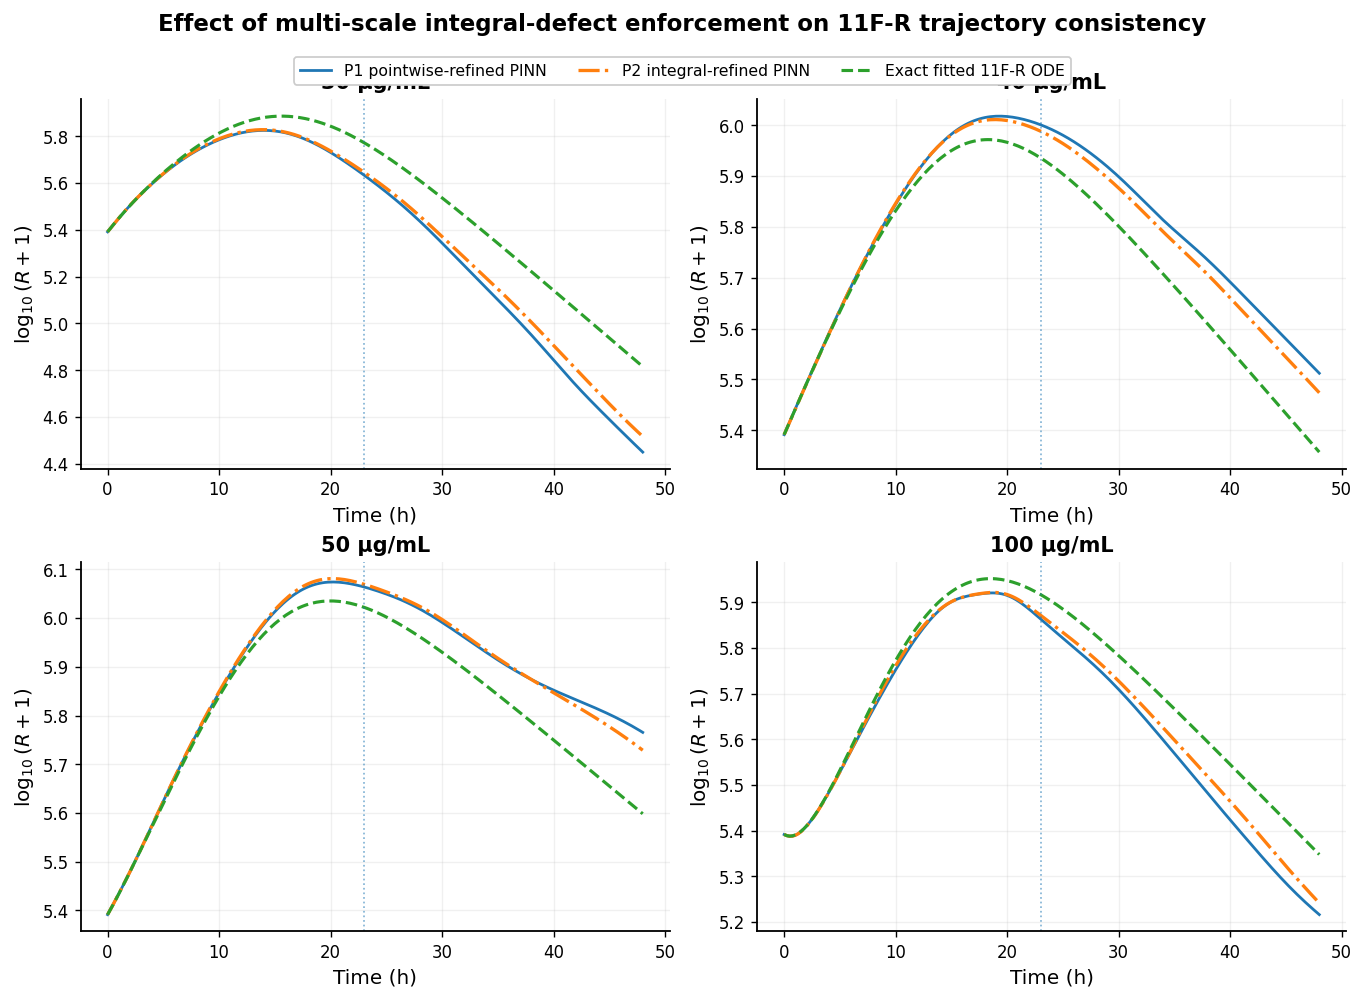


P2 COMPLETE — MULTI-SCALE INTEGRAL-DEFECT CONTINUATION
Maximum inverse-parameter change: 0.000e+00
FULL_RESULT remains unchanged.
PHYSICS_REFINED_RESULT remains unchanged.
New result stored as INTEGRAL_REFINED_RESULT.

Validation performance across stages:


,model,rmse_logB_val,rmse_qR_val
0,Original_11FR,0.264456,0.190222
1,P1_pointwise_refined,0.263657,0.178144
2,P2_integral_refined,0.259513,0.163390



Integral-defect BEFORE vs AFTER:


,model,mean_integral_defect_loss,max_abs_defect_logS,max_abs_defect_logR
0,P1_pointwise_refined,0.003835,0.155492,0.371793
1,P2_integral_refined,0.002424,0.121618,0.302526



0–48 h PINN / exact-ODE consistency BEFORE P2:


...


Critical 23–48 h comparison:


,model_before,dose_ug_ml,mean_abs_logS_23_48h_before,max_abs_logS_23_48h_before,mean_abs_logR_23_48h_before,max_abs_logR_23_48h_before,model_after,mean_abs_logS_23_48h_after,max_abs_logS_23_48h_after,mean_abs_logR_23_48h_after,max_abs_logR_23_48h_after,reduction_max_abs_logR_percent
0,P1_pointwise_refined,30.0,0.118799,0.123301,0.250829,0.365483,P2_integral_refined,0.103123,0.106913,0.205815,0.298557,18.311868
1,P1_pointwise_refined,40.0,0.008610,0.014790,0.114502,0.155118,P2_integral_refined,0.007468,0.015685,0.088074,0.116710,24.760550
2,P1_pointwise_refined,50.0,0.149490,0.156838,0.088707,0.166962,P2_integral_refined,0.102624,0.113091,0.084278,0.130358,21.923284
3,P1_pointwise_refined,100.0,0.005194,0.011143,0.099604,0.136921,P2_integral_refined,0.002829,0.005730,0.072046,0.106356,22.323036



Parameter-freeze audit:


,parameter,before,after,absolute_change
0,mutation_probability,0.000031,0.000031,0.0
1,resistance_fitness_cost,0.105998,0.105998,0.0
2,sensitive_birth_rate_per_h,0.646118,0.646118,0.0
3,baseline_death_rate_per_h,0.350002,0.350002,0.0
4,death_rate_per_h,0.350002,0.350002,0.0
5,initial_resistant_fraction_shared,0.000060,0.000060,0.0
6,resistant_relative_drug_sensitivity,0.667814,0.667814,0.0
7,kill_activation_onset_h,13.665092,13.665092,0.0
8,kill_activation_per_h,0.224483,0.224483,0.0
9,q0_dose_0,0.000060,0.000060,0.0



Saved P2 checkpoint:
results\real_data\models\final_R37_11FR_stateonly_multiscale_integral_defect_x10.pt


In [55]:
# =============================================================================
# DIAGNOSTIC P2 — 11F-R MULTI-SCALE INTEGRAL-DEFECT CONTINUATION
# =============================================================================
#
# Run AFTER:
#   1) completed FINAL Cell 8,
#   2) Audit B,
#   3) DIAGNOSTIC P1 (PHYSICS_REFINED_RESULT must exist).
#
# PURPOSE
# -------
# P1 showed that stronger pointwise physics improves PINN/ODE consistency but
# does not completely remove the later 23–48 h trajectory drift.
#
# This cell therefore adds a MULTI-SCALE INTEGRAL-DEFECT penalty while keeping:
#
#   - the same hard abundance–simplex architecture,
#   - the same selected 11F-R equations,
#   - the same 12 inferred inverse parameters,
#   - the same 5x strengthened pointwise physics used in P1.
#
# ALL inverse parameters remain frozen.
#
# The integral defect is based on the Cell-6 log-state residual:
#
#   R_logX = d log10(X+1)/d tau - physics_rhs_in_log_space
#
# where tau = t / PHYSICS_TIME_SCALE_H.
#
# For an interval [ta,tb], the trajectory defect is
#
#   D_X(ta,tb) = integral_{tau_a}^{tau_b} R_logX d tau.
#
# If the neural trajectory exactly satisfies the fitted ODE, D_X = 0.
#
# We enforce both short and long intervals so that a small local residual cannot
# accumulate into a large late-time trajectory mismatch.
#
# IMPORTANT
# ---------
# - FULL_RESULT is NOT overwritten.
# - PHYSICS_REFINED_RESULT is NOT overwritten.
# - No biological equation is changed.
# - No inverse parameter is allowed to move.
# - The new model is stored as INTEGRAL_REFINED_RESULT.
# =============================================================================

import time
import numpy as np
import pandas as pd
import torch


# =============================================================================
# 0. PRECONDITIONS
# =============================================================================

if "FULL_RESULT" not in globals():
    raise RuntimeError(
        "FULL_RESULT is missing. Complete or restore FINAL R3.7 11F-R first."
    )

if "PHYSICS_REFINED_RESULT" not in globals():
    raise RuntimeError(
        "PHYSICS_REFINED_RESULT is missing. Run DIAGNOSTIC P1 first."
    )

if QUICK_MODE:
    raise RuntimeError(
        "This diagnostic is intended for the FINAL run, but QUICK_MODE=True."
    )

EXPECTED_ARCHITECTURE = "shared_dose_conditioned_hard_PINN_11FR"

for _name, _result in [
    ("FULL_RESULT", FULL_RESULT),
    ("PHYSICS_REFINED_RESULT", PHYSICS_REFINED_RESULT),
]:
    if getattr(
        _result.model,
        "architecture_name",
        None,
    ) != EXPECTED_ARCHITECTURE:
        raise RuntimeError(
            f"{_name} does not contain the expected 11F-R architecture."
        )


# =============================================================================
# 1. FIXED P2 SETTINGS
# =============================================================================
#
# These are predeclared diagnostic settings. Do not tune them after inspecting
# the result.
# =============================================================================

POINTWISE_PHYSICS_FACTOR = 5.0

INTEGRAL_DEFECT_WEIGHT = 10.0

P2_ADAM_EPOCHS = 1200

P2_ADAM_LR = 1.0e-4

P2_LOG_EVERY = 100

P2_EARLY_STOP_PATIENCE = 500

P2_LBFGS_MAX_ITER = 150

P2_TAG = "R37_11FR_stateonly_multiscale_integral_defect_x10"

P2_CHECKPOINT_PATH = (
    MODEL_DIR
    / f"{RUN_LABEL}_{P2_TAG}.pt"
)

P2_HISTORY_PATH = (
    HISTORY_DIR
    / f"{RUN_LABEL}_{P2_TAG}_history.csv"
)

if P2_CHECKPOINT_PATH.exists():
    raise FileExistsError(
        "\nA P2 checkpoint already exists:\n"
        f"    {P2_CHECKPOINT_PATH}\n\n"
        "It has NOT been overwritten."
    )


# =============================================================================
# 2. MULTI-SCALE TRAJECTORY WINDOWS
# =============================================================================
#
# Adjacent windows capture local accumulated defect.
# Long windows explicitly test whether small local bias accumulates across the
# observed treated horizon.
#
# The SAME windows are applied to EVERY dose.
# =============================================================================

SHORT_WINDOWS_H = [
    (0.0, 4.0),
    (4.0, 8.0),
    (8.0, 12.0),
    (12.0, 16.0),
    (16.0, 20.0),
    (20.0, 23.0),
    (23.0, 26.0),
    (26.0, 30.0),
    (30.0, 36.0),
    (36.0, 40.0),
    (40.0, 44.0),
    (44.0, 48.0),
]

LONG_WINDOWS_H = [
    (0.0, 23.0),
    (0.0, 48.0),
    (4.0, 23.0),
    (12.0, 36.0),
    (20.0, 48.0),
    (23.0, 48.0),
]

INTEGRAL_WINDOWS_H = (
    SHORT_WINDOWS_H
    + LONG_WINDOWS_H
)

# 0.5-h grid contains every boundary listed above.
INTEGRAL_GRID_H = np.arange(
    0.0,
    48.0 + 0.5,
    0.5,
    dtype=float,
)


# =============================================================================
# 3. CLONE THE P1 MODEL AND FREEZE ALL INVERSE PARAMETERS
# =============================================================================

integral_model = RealAMRPINN(
    BASE_BUNDLE
).to(
    DEVICE
)

integral_model.load_state_dict(
    cpu_state_dict(
        PHYSICS_REFINED_RESULT.model
    ),
    strict=True,
)

inverse_before = (
    integral_model
    .inferred_parameters()
)

set_inverse_trainable(
    integral_model,
    False,
)

if any(
    p.requires_grad
    for p
    in integral_model.inverse.parameters()
):
    raise RuntimeError(
        "Inverse-parameter freeze failed."
    )


print("=" * 112)
print("DIAGNOSTIC P2 — 11F-R MULTI-SCALE INTEGRAL-DEFECT CONTINUATION")
print("=" * 112)
print("Starting point             : PHYSICS_REFINED_RESULT (P1)")
print("Architecture               :", integral_model.architecture_name)
print("Pointwise physics factor   :", POINTWISE_PHYSICS_FACTOR)
print("Integral-defect weight     :", INTEGRAL_DEFECT_WEIGHT)
print("Integral grid spacing      : 0.5 h")
print("Number of trajectory windows:", len(INTEGRAL_WINDOWS_H))
print("Inverse parameters         : FROZEN")
print("Adam epochs                :", P2_ADAM_EPOCHS)
print("Adam learning rate         :", P2_ADAM_LR)
print("L-BFGS max iterations      :", P2_LBFGS_MAX_ITER)
print("New checkpoint             :", P2_CHECKPOINT_PATH)
print("=" * 112)


# =============================================================================
# 4. DIFFERENTIABLE MULTI-SCALE INTEGRAL-DEFECT LOSS
# =============================================================================

def multiscale_integral_defect_loss(
    model: RealAMRPINN,
    return_rows: bool = False,
):
    """
    Integral of the Cell-6 log-state ODE residual over multiple time windows.

    Cell 6 defines log_residual_X on the nondimensional time coordinate
    tau=t/PHYSICS_TIME_SCALE_H. Therefore integrating log_residual_X with
    respect to tau produces a defect directly in log10(X+1) units.
    """

    loss_terms = []

    audit_rows = []

    for dose in BASE_BUNDLE.doses:

        t = tensor_column(
            INTEGRAL_GRID_H,
            requires_grad=True,
        )

        (
            _raw_s,
            _raw_r,
            _scaled_s,
            _scaled_r,
            log_residual_s,
            log_residual_r,
        ) = all_physics_residuals(
            model=model,
            t=t,
            dose=float(dose),
            create_graph=True,
        )

        tau = (
            t
            / PHYSICS_TIME_SCALE_H
        )

        t_flat = t[:, 0]

        tau_flat = tau[:, 0]

        rs_flat = log_residual_s[:, 0]

        rr_flat = log_residual_r[:, 0]

        for start_h, end_h in INTEGRAL_WINDOWS_H:

            mask = (
                (t_flat >= start_h - 1e-12)
                &
                (t_flat <= end_h + 1e-12)
            )

            n_selected = int(
                mask.sum()
                .detach()
                .cpu()
            )

            if n_selected < 2:
                raise RuntimeError(
                    f"Integral window [{start_h}, {end_h}] h has fewer than 2 grid points."
                )

            defect_s = torch.trapz(
                rs_flat[
                    mask
                ],
                tau_flat[
                    mask
                ],
            )

            defect_r = torch.trapz(
                rr_flat[
                    mask
                ],
                tau_flat[
                    mask
                ],
            )

            # Equal treatment of sensitive and resistant log-state defects.
            term = 0.5 * (
                defect_s ** 2
                +
                defect_r ** 2
            )

            loss_terms.append(
                term
            )

            if return_rows:

                audit_rows.append(
                    {
                        "dose_ug_ml":
                            float(
                                dose
                            ),

                        "start_h":
                            float(
                                start_h
                            ),

                        "end_h":
                            float(
                                end_h
                            ),

                        "duration_h":
                            float(
                                end_h
                                - start_h
                            ),

                        "defect_logS":
                            float(
                                defect_s
                                .detach()
                                .cpu()
                            ),

                        "defect_logR":
                            float(
                                defect_r
                                .detach()
                                .cpu()
                            ),

                        "abs_defect_logS":
                            float(
                                torch.abs(
                                    defect_s
                                )
                                .detach()
                                .cpu()
                            ),

                        "abs_defect_logR":
                            float(
                                torch.abs(
                                    defect_r
                                )
                                .detach()
                                .cpu()
                            ),
                    }
                )

    if not loss_terms:

        loss = torch.zeros(
            (),
            dtype=DTYPE,
            device=DEVICE,
        )

    else:

        loss = torch.stack(
            loss_terms
        ).mean()

    if return_rows:

        return (
            loss,
            pd.DataFrame(
                audit_rows
            ),
        )

    return loss


# =============================================================================
# 5. BASELINE P1 METRICS AND INTEGRAL DEFECT
# =============================================================================

p1_val_metrics = observation_metrics(
    PHYSICS_REFINED_RESULT.model,
    BASE_BUNDLE,
    split="val",
)

p1_feasibility = feasibility_audit(
    PHYSICS_REFINED_RESULT.model,
    BASE_BUNDLE.doses,
)

_p1_integral_loss, p1_integral_table = (
    multiscale_integral_defect_loss(
        PHYSICS_REFINED_RESULT.model,
        return_rows=True,
    )
)

p1_integral_loss_value = float(
    _p1_integral_loss
    .detach()
    .cpu()
)

del _p1_integral_loss


# =============================================================================
# 6. FIXED VALIDATION COLLOCATION
# =============================================================================

fixed_val_collocation = make_collocation(
    BASE_BUNDLE.doses,
    seed=SEED + 710_000,
    points_per_dose=max(
        128,
        COLLOCATION_POINTS_PER_DOSE // 2,
    ),
)


def p2_validation_score(
    model: RealAMRPINN,
):
    """
    Validation criterion used for P2 model selection:
        existing data + 5x pointwise physics + 10x integral defect.
    """

    base_total, components = complete_loss(
        model=model,
        bundle=BASE_BUNDLE,
        collocation=fixed_val_collocation,
        split="val",
        physics_weight=POINTWISE_PHYSICS_FACTOR,
        hide_fraction_doses=None,
    )

    integral_loss = multiscale_integral_defect_loss(
        model
    )

    total = (
        base_total
        +
        INTEGRAL_DEFECT_WEIGHT
        * integral_loss
    )

    components = dict(
        components
    )

    components[
        "integral_defect"
    ] = float(
        integral_loss
        .detach()
        .cpu()
    )

    components[
        "weighted_integral_defect"
    ] = float(
        (
            INTEGRAL_DEFECT_WEIGHT
            * integral_loss
        )
        .detach()
        .cpu()
    )

    return (
        float(
            total
            .detach()
            .cpu()
        ),
        components,
    )


# =============================================================================
# 7. P2-A — STATE-ONLY ADAM CONTINUATION
# =============================================================================

optimizer = torch.optim.AdamW(
    state_parameters(
        integral_model
    ),
    lr=P2_ADAM_LR,
    weight_decay=0.0,
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3,
    min_lr=1.0e-6,
)

best_score, _ = p2_validation_score(
    integral_model
)

best_state = cpu_state_dict(
    integral_model
)

history_rows = []

stale_epochs = 0

collocation = None

start_time = time.time()


for epoch in range(
    P2_ADAM_EPOCHS
):

    if (
        collocation is None
        or epoch % RESAMPLE_EVERY == 0
    ):

        if collocation is not None:
            del collocation

        collocation = make_collocation(
            BASE_BUNDLE.doses,
            seed=SEED + 720_000 + epoch,
        )

    optimizer.zero_grad(
        set_to_none=True
    )

    base_loss, train_components = complete_loss(
        model=integral_model,
        bundle=BASE_BUNDLE,
        collocation=collocation,
        split="train",
        physics_weight=POINTWISE_PHYSICS_FACTOR,
        hide_fraction_doses=None,
    )

    integral_loss = multiscale_integral_defect_loss(
        integral_model
    )

    total_loss = (
        base_loss
        +
        INTEGRAL_DEFECT_WEIGHT
        * integral_loss
    )

    if not torch.isfinite(
        total_loss
    ):
        raise FloatingPointError(
            f"Non-finite P2 Adam loss at epoch {epoch}."
        )

    total_loss.backward()

    torch.nn.utils.clip_grad_norm_(
        state_parameters(
            integral_model
        ),
        GRADIENT_CLIP_NORM,
    )

    optimizer.step()

    if (
        epoch % P2_LOG_EVERY == 0
        or epoch == P2_ADAM_EPOCHS - 1
    ):

        score, val_components = p2_validation_score(
            integral_model
        )

        val_metrics = observation_metrics(
            integral_model,
            BASE_BUNDLE,
            split="val",
        )

        scheduler.step(
            score
        )

        history_rows.append(
            {
                "stage":
                    "state_only_adam_integral_defect",

                "epoch":
                    epoch,

                "p2_validation_score":
                    score,

                "rmse_logB_val":
                    val_metrics[
                        "rmse_logB"
                    ],

                "rmse_qR_val":
                    val_metrics[
                        "rmse_qR"
                    ],

                "physics_raw_rmse_per_h":
                    val_components[
                        "physics_raw_rmse_per_h"
                    ],

                "physics_log":
                    val_components[
                        "physics_log"
                    ],

                "integral_defect":
                    val_components[
                        "integral_defect"
                    ],

                "weighted_integral_defect":
                    val_components[
                        "weighted_integral_defect"
                    ],
            }
        )

        print(
            f"P2 Adam | {epoch:4d}/{P2_ADAM_EPOCHS} | "
            f"score={score:.4e} | "
            f"RMSE(logB)={val_metrics['rmse_logB']:.4f} | "
            f"RMSE(qR)={val_metrics['rmse_qR']:.4f} | "
            f"raw-phys={val_components['physics_raw_rmse_per_h']:.3e}/h | "
            f"integral={val_components['integral_defect']:.3e}"
        )

        if score < best_score * (
            1.0 - 1e-7
        ):

            best_score = score

            best_state = cpu_state_dict(
                integral_model
            )

            stale_epochs = 0

        else:

            stale_epochs += P2_LOG_EVERY

        if stale_epochs >= P2_EARLY_STOP_PATIENCE:

            print(
                f"P2 Adam early stopping at epoch {epoch}."
            )

            break


if collocation is not None:
    del collocation

integral_model.load_state_dict(
    best_state
)

clear_memory()


# =============================================================================
# 8. P2-B — STATE-ONLY L-BFGS
# =============================================================================

fixed_train_collocation = make_collocation(
    BASE_BUNDLE.doses,
    seed=SEED + 730_000,
    points_per_dose=max(
        192,
        COLLOCATION_POINTS_PER_DOSE,
    ),
)

optimizer_lbfgs = torch.optim.LBFGS(
    state_parameters(
        integral_model
    ),
    lr=0.45,
    max_iter=P2_LBFGS_MAX_ITER,
    max_eval=max(
        2 * P2_LBFGS_MAX_ITER,
        40,
    ),
    tolerance_grad=1e-10,
    tolerance_change=1e-12,
    history_size=50,
    line_search_fn="strong_wolfe",
)

closure_calls = {
    "n":
        0
}


def closure():

    optimizer_lbfgs.zero_grad(
        set_to_none=True
    )

    base_loss, _ = complete_loss(
        model=integral_model,
        bundle=BASE_BUNDLE,
        collocation=fixed_train_collocation,
        split="train",
        physics_weight=POINTWISE_PHYSICS_FACTOR,
        hide_fraction_doses=None,
    )

    integral_loss = multiscale_integral_defect_loss(
        integral_model
    )

    loss = (
        base_loss
        +
        INTEGRAL_DEFECT_WEIGHT
        * integral_loss
    )

    if not torch.isfinite(
        loss
    ):
        raise FloatingPointError(
            "Non-finite P2 L-BFGS loss."
        )

    loss.backward()

    closure_calls[
        "n"
    ] += 1

    return loss


optimizer_lbfgs.step(
    closure
)

lbfgs_score, lbfgs_components = p2_validation_score(
    integral_model
)

lbfgs_val_metrics = observation_metrics(
    integral_model,
    BASE_BUNDLE,
    split="val",
)

history_rows.append(
    {
        "stage":
            "state_only_lbfgs_integral_defect",

        "epoch":
            closure_calls[
                "n"
            ],

        "p2_validation_score":
            lbfgs_score,

        "rmse_logB_val":
            lbfgs_val_metrics[
                "rmse_logB"
            ],

        "rmse_qR_val":
            lbfgs_val_metrics[
                "rmse_qR"
            ],

        "physics_raw_rmse_per_h":
            lbfgs_components[
                "physics_raw_rmse_per_h"
            ],

        "physics_log":
            lbfgs_components[
                "physics_log"
            ],

        "integral_defect":
            lbfgs_components[
                "integral_defect"
            ],

        "weighted_integral_defect":
            lbfgs_components[
                "weighted_integral_defect"
            ],
    }
)

if lbfgs_score < best_score:

    best_score = lbfgs_score

    best_state = cpu_state_dict(
        integral_model
    )


integral_model.load_state_dict(
    best_state
)

del fixed_train_collocation

clear_memory()


# =============================================================================
# 9. VERIFY THAT ALL INVERSE PARAMETERS REMAIN EXACTLY FROZEN
# =============================================================================

inverse_after = (
    integral_model
    .inferred_parameters()
)

freeze_rows = []

for key, before_value in inverse_before.items():

    if key not in inverse_after:
        continue

    try:

        before_float = float(
            before_value
        )

        after_float = float(
            inverse_after[
                key
            ]
        )

    except Exception:
        continue

    freeze_rows.append(
        {
            "parameter":
                key,

            "before":
                before_float,

            "after":
                after_float,

            "absolute_change":
                abs(
                    after_float
                    - before_float
                ),
        }
    )


parameter_freeze_audit = pd.DataFrame(
    freeze_rows
)

max_inverse_change = (
    float(
        parameter_freeze_audit[
            "absolute_change"
        ].max()
    )
    if not parameter_freeze_audit.empty
    else 0.0
)

if max_inverse_change > 1e-14:

    display(
        parameter_freeze_audit
    )

    raise RuntimeError(
        "An inverse parameter changed during P2."
    )


# =============================================================================
# 10. FINAL P2 METRICS
# =============================================================================

p2_val_metrics = observation_metrics(
    integral_model,
    BASE_BUNDLE,
    split="val",
)

p2_feasibility = feasibility_audit(
    integral_model,
    BASE_BUNDLE.doses,
)

_p2_integral_loss, p2_integral_table = (
    multiscale_integral_defect_loss(
        integral_model,
        return_rows=True,
    )
)

p2_integral_loss_value = float(
    _p2_integral_loss
    .detach()
    .cpu()
)

del _p2_integral_loss


# =============================================================================
# 11. 0–48 h PINN / EXACT-ODE CONSISTENCY: P1 BEFORE vs P2 AFTER
# =============================================================================

treated_doses = [
    30.0,
    40.0,
    50.0,
    100.0,
]

comparison_times = np.unique(
    np.concatenate(
        [
            np.linspace(
                0.0,
                48.0,
                193,
            ),
            np.array(
                [
                    0.0,
                    2.0,
                    4.0,
                    8.0,
                    12.0,
                    16.0,
                    20.0,
                    23.0,
                    26.0,
                    30.0,
                    36.0,
                    40.0,
                    44.0,
                    48.0,
                ],
                dtype=float,
            ),
        ]
    )
)


p1_ode_detail, p1_ode_summary = exact_ode_consistency_audit(
    model=PHYSICS_REFINED_RESULT.model,
    bundle=BASE_BUNDLE,
    doses=treated_doses,
    check_times=comparison_times,
)

p2_ode_detail, p2_ode_summary = exact_ode_consistency_audit(
    model=integral_model,
    bundle=BASE_BUNDLE,
    doses=treated_doses,
    check_times=comparison_times,
)


def _late_23_48_summary(
    detail: pd.DataFrame,
    label: str,
) -> pd.DataFrame:

    late = (
        detail[
            detail[
                "time_h"
            ] >= 23.0
        ]
        .copy()
    )

    rows = []

    for dose in treated_doses:

        x = (
            late[
                late[
                    "dose_ug_ml"
                ] == dose
            ]
            .copy()
        )

        rows.append(
            {
                "model":
                    label,

                "dose_ug_ml":
                    dose,

                "mean_abs_logS_23_48h":
                    float(
                        x[
                            "abs_difference_logS"
                        ].mean()
                    ),

                "max_abs_logS_23_48h":
                    float(
                        x[
                            "abs_difference_logS"
                        ].max()
                    ),

                "mean_abs_logR_23_48h":
                    float(
                        x[
                            "abs_difference_logR"
                        ].mean()
                    ),

                "max_abs_logR_23_48h":
                    float(
                        x[
                            "abs_difference_logR"
                        ].max()
                    ),
            }
        )

    return pd.DataFrame(
        rows
    )


p1_late = _late_23_48_summary(
    p1_ode_detail,
    "P1_pointwise_refined",
)

p2_late = _late_23_48_summary(
    p2_ode_detail,
    "P2_integral_refined",
)


late_comparison = p1_late.merge(
    p2_late,
    on="dose_ug_ml",
    suffixes=(
        "_before",
        "_after",
    ),
)

late_comparison[
    "reduction_max_abs_logR_percent"
] = (
    100.0
    * (
        late_comparison[
            "max_abs_logR_23_48h_before"
        ]
        - late_comparison[
            "max_abs_logR_23_48h_after"
        ]
    )
    / late_comparison[
        "max_abs_logR_23_48h_before"
    ].clip(
        lower=1e-15
    )
)


# =============================================================================
# 12. INTEGRAL-DEFECT SUMMARY
# =============================================================================

integral_comparison = pd.DataFrame(
    [
        {
            "model":
                "P1_pointwise_refined",

            "mean_integral_defect_loss":
                p1_integral_loss_value,

            "max_abs_defect_logS":
                float(
                    p1_integral_table[
                        "abs_defect_logS"
                    ].max()
                ),

            "max_abs_defect_logR":
                float(
                    p1_integral_table[
                        "abs_defect_logR"
                    ].max()
                ),
        },
        {
            "model":
                "P2_integral_refined",

            "mean_integral_defect_loss":
                p2_integral_loss_value,

            "max_abs_defect_logS":
                float(
                    p2_integral_table[
                        "abs_defect_logS"
                    ].max()
                ),

            "max_abs_defect_logR":
                float(
                    p2_integral_table[
                        "abs_defect_logR"
                    ].max()
                ),
        },
    ]
)


# =============================================================================
# 13. PERFORMANCE COMPARISON
# =============================================================================

original_val_metrics = observation_metrics(
    FULL_RESULT.model,
    BASE_BUNDLE,
    split="val",
)

performance_comparison = pd.DataFrame(
    [
        {
            "model":
                "Original_11FR",

            "rmse_logB_val":
                original_val_metrics[
                    "rmse_logB"
                ],

            "rmse_qR_val":
                original_val_metrics[
                    "rmse_qR"
                ],
        },
        {
            "model":
                "P1_pointwise_refined",

            "rmse_logB_val":
                p1_val_metrics[
                    "rmse_logB"
                ],

            "rmse_qR_val":
                p1_val_metrics[
                    "rmse_qR"
                ],
        },
        {
            "model":
                "P2_integral_refined",

            "rmse_logB_val":
                p2_val_metrics[
                    "rmse_logB"
                ],

            "rmse_qR_val":
                p2_val_metrics[
                    "rmse_qR"
                ],
        },
    ]
)


# =============================================================================
# 14. SAVE P2 SEPARATELY
# =============================================================================

history = pd.DataFrame(
    history_rows
)

history.to_csv(
    P2_HISTORY_PATH,
    index=False,
)

parameter_freeze_audit.to_csv(
    TABLE_DIR / f"{RUN_LABEL}_{P2_TAG}_parameter_freeze.csv",
    index=False,
)

performance_comparison.to_csv(
    TABLE_DIR / f"{RUN_LABEL}_{P2_TAG}_performance_comparison.csv",
    index=False,
)

integral_comparison.to_csv(
    TABLE_DIR / f"{RUN_LABEL}_{P2_TAG}_integral_defect_comparison.csv",
    index=False,
)

p1_ode_summary.to_csv(
    TABLE_DIR / f"{RUN_LABEL}_{P2_TAG}_P1_0_48h_summary.csv",
    index=False,
)

p2_ode_summary.to_csv(
    TABLE_DIR / f"{RUN_LABEL}_{P2_TAG}_P2_0_48h_summary.csv",
    index=False,
)

late_comparison.to_csv(
    TABLE_DIR / f"{RUN_LABEL}_{P2_TAG}_23_48h_comparison.csv",
    index=False,
)

p1_integral_table.to_csv(
    TABLE_DIR / f"{RUN_LABEL}_{P2_TAG}_P1_integral_windows.csv",
    index=False,
)

p2_integral_table.to_csv(
    TABLE_DIR / f"{RUN_LABEL}_{P2_TAG}_P2_integral_windows.csv",
    index=False,
)


torch.save(
    {
        "model_state":
            cpu_state_dict(
                integral_model
            ),

        "source_model":
            PHYSICS_REFINED_RESULT.label,

        "architecture":
            integral_model.architecture_name,

        "physics_variant":
            "11F-R_reduced_time_structured_killing",

        "diagnostic":
            "multiscale_integral_defect_continuation",

        "pointwise_physics_factor":
            POINTWISE_PHYSICS_FACTOR,

        "integral_defect_weight":
            INTEGRAL_DEFECT_WEIGHT,

        "inverse_parameters_frozen":
            True,

        "max_inverse_parameter_change":
            max_inverse_change,

        "inferred_parameters":
            integral_model.inferred_parameters(),

        "seed":
            SEED,
    },
    P2_CHECKPOINT_PATH,
)


INTEGRAL_REFINED_RESULT = TrainingResult(
    label=P2_TAG,
    model=integral_model,
    history=history,
    best_validation_score=float(
        best_score
    ),
    elapsed_seconds=float(
        time.time()
        - start_time
    ),
    seed=int(
        SEED
    ),
)


# =============================================================================
# 15. VISUAL 0–48 h COMPARISON OF RESISTANT TRAJECTORY
# =============================================================================

fig, axes = plt.subplots(
    2,
    2,
    figsize=(
        10.8,
        7.4,
    ),
    constrained_layout=True,
)

axes = axes.ravel()

for ax, dose in zip(
    axes,
    treated_doses,
):

    before = (
        p1_ode_detail[
            p1_ode_detail[
                "dose_ug_ml"
            ] == dose
        ]
        .sort_values(
            "time_h"
        )
    )

    after = (
        p2_ode_detail[
            p2_ode_detail[
                "dose_ug_ml"
            ] == dose
        ]
        .sort_values(
            "time_h"
        )
    )

    ax.plot(
        before[
            "time_h"
        ],
        before[
            "PINN_log10_R_plus1"
        ],
        linestyle="-",
        linewidth=1.6,
        label="P1 pointwise-refined PINN",
    )

    ax.plot(
        after[
            "time_h"
        ],
        after[
            "PINN_log10_R_plus1"
        ],
        linestyle="-.",
        linewidth=1.9,
        label="P2 integral-refined PINN",
    )

    ax.plot(
        after[
            "time_h"
        ],
        after[
            "ODE_log10_R_plus1"
        ],
        linestyle="--",
        linewidth=1.8,
        label="Exact fitted 11F-R ODE",
    )

    ax.axvline(
        23.0,
        linestyle=":",
        linewidth=1.0,
        alpha=0.55,
    )

    ax.set_title(
        f"{dose:g} µg/mL",
        fontweight="bold",
    )

    ax.set_xlabel(
        "Time (h)"
    )

    ax.set_ylabel(
        r"$\log_{10}(R+1)$"
    )

    ax.grid(
        alpha=0.18
    )

    ax.spines[
        [
            "top",
            "right",
        ]
    ].set_visible(
        False
    )


handles, labels = axes[
    0
].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=3,
    bbox_to_anchor=(
        0.5,
        1.02,
    ),
)

fig.suptitle(
    "Effect of multi-scale integral-defect enforcement on 11F-R trajectory consistency",
    fontsize=13.2,
    fontweight="bold",
    y=1.06,
)

save_figure(
    fig,
    f"{RUN_LABEL}_{P2_TAG}_R_0_48h_comparison",
)

plt.show()


# =============================================================================
# 16. DISPLAY FINAL P2 RESULTS
# =============================================================================

print("\n" + "=" * 112)
print("P2 COMPLETE — MULTI-SCALE INTEGRAL-DEFECT CONTINUATION")
print("=" * 112)

print(
    "Maximum inverse-parameter change:",
    f"{max_inverse_change:.3e}",
)

print(
    "FULL_RESULT remains unchanged."
)

print(
    "PHYSICS_REFINED_RESULT remains unchanged."
)

print(
    "New result stored as INTEGRAL_REFINED_RESULT."
)


print(
    "\nValidation performance across stages:"
)

display(
    performance_comparison
)


print(
    "\nIntegral-defect BEFORE vs AFTER:"
)

display(
    integral_comparison
)


print(
    "\n0–48 h PINN / exact-ODE consistency BEFORE P2:"
)

display(
    p1_ode_summary
)


print(
    "\n0–48 h PINN / exact-ODE consistency AFTER P2:"
)

display(
    p2_ode_summary
)


print(
    "\nCritical 23–48 h comparison:"
)

display(
    late_comparison
)


print(
    "\nParameter-freeze audit:"
)

display(
    parameter_freeze_audit
)


print(
    "\nSaved P2 checkpoint:"
)

print(
    P2_CHECKPOINT_PATH
)

print("=" * 112)

In [18]:
# =============================================================================
# MODEL DIAGNOSTICS — PHYSICS FIDELITY, LOG-STATE PHYSICS, AND LOSS BALANCE
# =============================================================================

print("=" * 88)
print("PHYSICS AND LOSS DIAGNOSTICS — SHARED DOSE-CONDITIONED REAL-DATA PINN")
print("=" * 88)


# =============================================================================
# 1. ABSOLUTE PHYSICS-FIDELITY AUDIT
# =============================================================================

print("\n[1] Absolute physics-fidelity audit")
print("-" * 88)

physics_audit = physics_fidelity_audit(
    model=FULL_RESULT.model,
    doses=BASE_BUNDLE.doses,
)

display(physics_audit)


# Save for later manuscript analysis.
physics_audit.to_csv(
    TABLE_DIR / f"{RUN_LABEL}_R37_physics_fidelity_audit.csv",
    index=False,
)


# =============================================================================
# 2. EARLY-TIME LOG-STATE PHYSICS AUDIT
# =============================================================================
#
# The first 0–4 h are examined separately because this was previously the
# critical interval in which the latent resistant population could diverge
# from the fitted mechanistic ODE by several orders of magnitude.
# =============================================================================

print("\n[2] Early-time log-state physics audit: 0–4 h")
print("-" * 88)

log_physics_audit = log_physics_fidelity_audit(
    model=FULL_RESULT.model,
    doses=BASE_BUNDLE.doses,
    start_h=0.0,
    end_h=4.0,
)

display(log_physics_audit)


log_physics_audit.to_csv(
    TABLE_DIR / f"{RUN_LABEL}_R37_log_physics_audit_0_4h.csv",
    index=False,
)


# =============================================================================
# 3. LOSS-BALANCE AUDIT
# =============================================================================
#
# This shows the numerical contribution of:
#     - total-load data loss
#     - resistant-fraction data loss
#     - absolute physics loss
#     - log-state physics loss
#     - regularization
#
# It is useful for checking that no single objective term dominates training.
# =============================================================================

print("\n[3] Loss-balance audit")
print("-" * 88)

loss_audit = loss_balance_audit(
    model=FULL_RESULT.model,
    bundle=BASE_BUNDLE,
)

display(loss_audit)


loss_audit.to_csv(
    TABLE_DIR / f"{RUN_LABEL}_R37_loss_balance_audit.csv",
    index=False,
)


# =============================================================================
# 4. COMPACT NUMERICAL SUMMARY
# =============================================================================

print("\n[4] Compact diagnostic summary")
print("-" * 88)

summary_rows = []

# Absolute residual summary.
if "combined_raw_rmse_per_h" in physics_audit.columns:
    summary_rows.append(
        {
            "diagnostic": "Maximum combined raw physics RMSE",
            "value": float(
                physics_audit["combined_raw_rmse_per_h"].max()
            ),
            "unit": "h^-1",
        }
    )

if "combined_scaled_rmse" in physics_audit.columns:
    summary_rows.append(
        {
            "diagnostic": "Maximum scaled physics RMSE",
            "value": float(
                physics_audit["combined_scaled_rmse"].max()
            ),
            "unit": "dimensionless",
        }
    )

# Log-state resistant residual summary.
possible_log_r_columns = [
    "rmse_logRr",
    "rmse_logR",
    "RMSE_logR",
    "rmse_log_R",
    "rmse_logR_0_4h",
    "RMSE_logR_0_4h",
]

for column_name in possible_log_r_columns:
    if column_name in log_physics_audit.columns:
        summary_rows.append(
            {
                "diagnostic": "Maximum early-time log-R physics RMSE",
                "value": float(
                    log_physics_audit[column_name].max()
                ),
                "unit": "dimensionless",
            }
        )
        break


diagnostic_summary = pd.DataFrame(
    summary_rows
)

display(diagnostic_summary)


if not diagnostic_summary.empty:
    diagnostic_summary.to_csv(
        TABLE_DIR / f"{RUN_LABEL}_R37_compact_diagnostic_summary.csv",
        index=False,
    )


print("\nDiagnostic audit complete.")
print("=" * 88)

PHYSICS AND LOSS DIAGNOSTICS — SHARED DOSE-CONDITIONED REAL-DATA PINN

[1] Absolute physics-fidelity audit
----------------------------------------------------------------------------------------


,dose_ug_ml,rmse_Rs_raw_per_h,rmse_Rr_raw_per_h,combined_raw_rmse_per_h,combined_scaled_rmse,max_abs_Rs_raw_per_h,max_abs_Rr_raw_per_h
0,0.0,0.003146,3.166806e-08,0.002224,0.053388,0.012679,1.971636e-07
1,30.0,0.003920,2.627653e-06,0.002772,0.066521,0.034292,4.636895e-05
2,40.0,0.002440,5.045009e-06,0.001726,0.041413,0.025604,8.868621e-05
3,50.0,0.001626,7.885525e-06,0.001150,0.027588,0.017576,1.232478e-04
4,100.0,0.000485,1.152064e-07,0.000343,0.008229,0.005275,2.599348e-07



[2] Early-time log-state physics audit: 0–4 h
----------------------------------------------------------------------------------------


,dose_ug_ml,rmse_logRs,rmse_logRr,max_abs_logRs,max_abs_logRr
0,0.0,0.013026,0.027768,0.030675,0.085994
1,30.0,0.021027,0.034316,0.039980,0.092096
2,40.0,0.020679,0.034946,0.041973,0.069481
3,50.0,0.032650,0.030183,0.059471,0.076636
4,100.0,0.089964,0.014260,0.149012,0.024281



[3] Loss-balance audit
----------------------------------------------------------------------------------------


,total,load,fraction,physics,physics_raw_rmse_per_h,physics_scaled_rmse,physics_log,regularization,weighted_load,weighted_fraction,weighted_physics,weighted_log_physics
0,1.682773,0.116023,0.048656,0.001782,0.001759,0.042215,0.093883,0.325874,1.160228,0.243282,0.044553,0.234709



[4] Compact diagnostic summary
----------------------------------------------------------------------------------------


,diagnostic,value,unit
0,Maximum combined raw physics RMSE,0.002772,h^-1
1,Maximum scaled physics RMSE,0.066521,dimensionless
2,Maximum early-time log-R physics RMSE,0.034946,dimensionless



Diagnostic audit complete.


In [19]:
# =============================================================================
# PARAMETER SUMMARY — SHARED DOSE-CONDITIONED REAL-DATA PINN
# =============================================================================

params = FULL_RESULT.model.inferred_parameters()

print("=" * 76)
print("INFERRED BIOLOGICAL PARAMETERS")
print("=" * 76)

print(
    f"Shared initial resistant fraction q0 : "
    f"{params['initial_resistant_fraction_shared']:.6e}"
)

print(
    f"Mutation probability mu              : "
    f"{params['mutation_probability']:.6e}"
)

print(
    f"Resistance fitness cost cR           : "
    f"{params['resistance_fitness_cost']:.6f}"
)

print(
    f"Sensitive birth rate rS              : "
    f"{params['sensitive_birth_rate_per_h']:.6f} h^-1"
)

print(
    f"Death rate d                         : "
    f"{params['death_rate_per_h']:.6f} h^-1"
)

print("=" * 76)


# =============================================================================
# DERIVED RESISTANT BASELINE BIRTH RATE
# =============================================================================
#
# In the absence of drug:
#
#       rR = rS * (1 - cR)
#
# where cR is the inferred fitness cost of resistance.
# =============================================================================

rS = params["sensitive_birth_rate_per_h"]
cR = params["resistance_fitness_cost"]

rR = rS * (1.0 - cR)

print(
    f"Derived resistant birth rate rR      : "
    f"{rR:.6f} h^-1"
)

print("=" * 76)


# =============================================================================
# PARAMETER TABLE
# =============================================================================

parameter_summary = pd.DataFrame(
    [
        {
            "parameter": "Shared initial resistant fraction",
            "symbol": "q0",
            "value": params["initial_resistant_fraction_shared"],
            "unit": "dimensionless",
        },
        {
            "parameter": "Mutation probability",
            "symbol": "mu",
            "value": params["mutation_probability"],
            "unit": "per division",
        },
        {
            "parameter": "Resistance fitness cost",
            "symbol": "cR",
            "value": params["resistance_fitness_cost"],
            "unit": "dimensionless",
        },
        {
            "parameter": "Sensitive birth rate",
            "symbol": "rS",
            "value": params["sensitive_birth_rate_per_h"],
            "unit": "h^-1",
        },
        {
            "parameter": "Death rate",
            "symbol": "d",
            "value": params["death_rate_per_h"],
            "unit": "h^-1",
        },
        {
            "parameter": "Derived resistant baseline birth rate",
            "symbol": "rR",
            "value": rR,
            "unit": "h^-1",
        },
    ]
)

display(parameter_summary)


# =============================================================================
# SAVE TABLE
# =============================================================================

parameter_summary.to_csv(
    TABLE_DIR / f"{RUN_LABEL}_R37_inferred_parameter_summary.csv",
    index=False,
)

print(
    "\nSaved parameter summary to:",
    TABLE_DIR / f"{RUN_LABEL}_R37_inferred_parameter_summary.csv"
)

INFERRED BIOLOGICAL PARAMETERS
Shared initial resistant fraction q0 : 3.601298e-05
Mutation probability mu              : 3.953597e-06
Resistance fitness cost cR           : 0.212290
Sensitive birth rate rS              : 0.560471 h^-1
Death rate d                         : 0.387261 h^-1
Derived resistant birth rate rR      : 0.441488 h^-1


,parameter,symbol,value,unit
0,Shared initial resistant fraction,q0,0.000036,dimensionless
1,Mutation probability,mu,0.000004,per division
2,Resistance fitness cost,cR,0.212290,dimensionless
3,Sensitive birth rate,rS,0.560471,h^-1
4,Death rate,d,0.387261,h^-1
5,Derived resistant baseline birth rate,rR,0.441488,h^-1



Saved parameter summary to: results\real_data\tables\final_R37_inferred_parameter_summary.csv


In [20]:
# =============================================================================
# EXACT-ODE CONSISTENCY AUDIT
# Shared dose-conditioned real-data PINN
# =============================================================================
#
# Purpose
# -------
# The PINN should not only fit the observations; its predicted latent states
#
#       S(t, dose), R(t, dose)
#
# should also agree with an independent numerical integration of the SAME
# fitted mechanistic ODE using:
#
#       mu, cR, rS, d, q0
#
# inferred by the PINN.
#
# The 0–4 h interval is examined because this was previously the most
# sensitive region for the latent resistant trajectory.
# =============================================================================

from scipy.integrate import solve_ivp


print("=" * 92)
print("EXACT-ODE CONSISTENCY AUDIT — SHARED DOSE-CONDITIONED PINN")
print("=" * 92)


# =============================================================================
# 1. INFERRED PARAMETERS
# =============================================================================

params = FULL_RESULT.model.inferred_parameters()

q0_shared = params["initial_resistant_fraction_shared"]
mu = params["mutation_probability"]
cR = params["resistance_fitness_cost"]
rS = params["sensitive_birth_rate_per_h"]
death = params["death_rate_per_h"]


print("\nParameters used in the independent ODE integration:")
print("-" * 92)

print(f"q0 shared : {q0_shared:.6e}")
print(f"mu        : {mu:.6e}")
print(f"cR        : {cR:.6f}")
print(f"rS        : {rS:.6f} h^-1")
print(f"d         : {death:.6f} h^-1")


# =============================================================================
# 2. EARLY-TIME EVALUATION POINTS
# =============================================================================

check_times = np.array(
    [
        0.00,
        0.05,
        0.10,
        0.25,
        0.50,
        1.00,
        2.00,
        4.00,
    ],
    dtype=float,
)


# =============================================================================
# 3. FITTED MECHANISTIC ODE
# =============================================================================

def fitted_real_rhs(
    t,
    y,
    dose,
    params,
):
    """
    Mechanistic AMR ODE corresponding exactly to the physics equations
    enforced in the PINN.

    Normalized states
    -----------------
    s = S / K_REAL
    r = R / K_REAL

    Dynamics
    --------
    ds/dt =
        bS(dose) * (1-mu) * (1-s-r) * s
        - d*s

    dr/dt =
        bS(dose) * mu * (1-s-r) * s
        + bR(dose) * (1-s-r) * r
        - d*r
    """

    s, r = y

    mu = params["mutation_probability"]
    cost = params["resistance_fitness_cost"]
    r_s = params["sensitive_birth_rate_per_h"]
    death = params["death_rate_per_h"]

    # -------------------------------------------------------------------------
    # Same dose normalization used in the PINN physics loss.
    # -------------------------------------------------------------------------

    exposure = float(
        np.clip(
            float(dose) / 100.0,
            0.0,
            1.0,
        )
    )

    # -------------------------------------------------------------------------
    # Dose-dependent sensitive and resistant division rates.
    # -------------------------------------------------------------------------

    b_s = (
        r_s
        * (
            1.0
            - SENSITIVE_DRUG_EFFECT
            * exposure
        )
    )

    b_r = (
        r_s
        * (
            1.0
            - cost
        )
        * (
            1.0
            - RESISTANT_DRUG_EFFECT
            * exposure
        )
    )

    # -------------------------------------------------------------------------
    # Logistic crowding.
    # -------------------------------------------------------------------------

    crowding = (
        1.0
        - s
        - r
    )

    # -------------------------------------------------------------------------
    # Sensitive-state dynamics.
    # -------------------------------------------------------------------------

    ds_dt = (
        b_s
        * (
            1.0
            - mu
        )
        * crowding
        * s
        -
        death
        * s
    )

    # -------------------------------------------------------------------------
    # Resistant-state dynamics.
    # -------------------------------------------------------------------------

    dr_dt = (
        b_s
        * mu
        * crowding
        * s
        +
        b_r
        * crowding
        * r
        -
        death
        * r
    )

    return [
        ds_dt,
        dr_dt,
    ]


# =============================================================================
# 4. PINN vs INDEPENDENT ODE INTEGRATION
# =============================================================================

comparison_rows = []


for dose in BASE_BUNDLE.doses:

    dose = float(dose)

    # -------------------------------------------------------------------------
    # Same shared pre-treatment resistant fraction for every environment.
    # -------------------------------------------------------------------------

    q0 = q0_shared

    # Observed initial total population normalized by K_REAL.
    n0 = float(
        BASE_BUNDLE.initial_total_norm[
            dose
        ]
    )

    # Exact initial phenotype state.
    y0 = np.array(
        [
            n0 * (1.0 - q0),
            n0 * q0,
        ],
        dtype=float,
    )

    # -------------------------------------------------------------------------
    # Independent high-accuracy ODE integration.
    # -------------------------------------------------------------------------

    ode_solution = solve_ivp(
        fun=lambda t, y: fitted_real_rhs(
            t=t,
            y=y,
            dose=dose,
            params=params,
        ),
        t_span=(
            float(check_times.min()),
            float(check_times.max()),
        ),
        y0=y0,
        t_eval=check_times,
        method="DOP853",
        rtol=1e-10,
        atol=1e-13,
    )

    if not ode_solution.success:
        raise RuntimeError(
            f"ODE integration failed for dose {dose:g} µg/mL: "
            f"{ode_solution.message}"
        )

    # -------------------------------------------------------------------------
    # PINN prediction at the exact same time coordinates.
    # -------------------------------------------------------------------------

    pinn_pred = predict_numpy(
        FULL_RESULT.model,
        dose,
        check_times,
    )

    # -------------------------------------------------------------------------
    # Convert normalized ODE states back to cell abundances.
    # -------------------------------------------------------------------------

    ode_S = (
        K_REAL
        * ode_solution.y[0]
    )

    ode_R = (
        K_REAL
        * ode_solution.y[1]
    )

    # -------------------------------------------------------------------------
    # Compare on log10(cells + 1) scale.
    # -------------------------------------------------------------------------

    for i, time_h in enumerate(check_times):

        pinn_S = float(
            pinn_pred[
                "sensitive"
            ].iloc[i]
        )

        pinn_R = float(
            pinn_pred[
                "resistant"
            ].iloc[i]
        )

        pinn_logS = np.log10(
            pinn_S + 1.0
        )

        pinn_logR = np.log10(
            pinn_R + 1.0
        )

        ode_logS = np.log10(
            ode_S[i] + 1.0
        )

        ode_logR = np.log10(
            ode_R[i] + 1.0
        )

        comparison_rows.append(
            {
                "dose_ug_ml":
                    dose,

                "time_h":
                    float(time_h),

                "PINN_log10_S_plus1":
                    pinn_logS,

                "ODE_log10_S_plus1":
                    ode_logS,

                "abs_difference_logS":
                    abs(
                        pinn_logS
                        - ode_logS
                    ),

                "PINN_log10_R_plus1":
                    pinn_logR,

                "ODE_log10_R_plus1":
                    ode_logR,

                "abs_difference_logR":
                    abs(
                        pinn_logR
                        - ode_logR
                    ),
            }
        )


ode_consistency = pd.DataFrame(
    comparison_rows
)


# =============================================================================
# 5. DETAILED COMPARISON TABLE
# =============================================================================

print(
    "\n[1] Detailed PINN vs exact-ODE comparison"
)
print("-" * 92)

display(
    ode_consistency
)


# =============================================================================
# 6. SUMMARY BY DOSE
# =============================================================================

ode_consistency_summary = (
    ode_consistency
    .groupby(
        "dose_ug_ml"
    )
    .agg(

        mean_abs_logS_difference=(
            "abs_difference_logS",
            "mean",
        ),

        rmse_logS_difference=(
            "abs_difference_logS",
            lambda x:
                float(
                    np.sqrt(
                        np.mean(
                            np.asarray(x) ** 2
                        )
                    )
                ),
        ),

        max_abs_logS_difference=(
            "abs_difference_logS",
            "max",
        ),

        mean_abs_logR_difference=(
            "abs_difference_logR",
            "mean",
        ),

        rmse_logR_difference=(
            "abs_difference_logR",
            lambda x:
                float(
                    np.sqrt(
                        np.mean(
                            np.asarray(x) ** 2
                        )
                    )
                ),
        ),

        max_abs_logR_difference=(
            "abs_difference_logR",
            "max",
        ),
    )
    .reset_index()
)


print(
    "\n[2] PINN vs exact-ODE consistency summary by dose"
)
print("-" * 92)

display(
    ode_consistency_summary
)


# =============================================================================
# 7. OVERALL SUMMARY
# =============================================================================

overall_consistency_summary = pd.DataFrame(
    [
        {
            "diagnostic":
                "Overall mean absolute log-S difference",

            "value":
                float(
                    ode_consistency[
                        "abs_difference_logS"
                    ].mean()
                ),
        },

        {
            "diagnostic":
                "Overall maximum absolute log-S difference",

            "value":
                float(
                    ode_consistency[
                        "abs_difference_logS"
                    ].max()
                ),
        },

        {
            "diagnostic":
                "Overall mean absolute log-R difference",

            "value":
                float(
                    ode_consistency[
                        "abs_difference_logR"
                    ].mean()
                ),
        },

        {
            "diagnostic":
                "Overall maximum absolute log-R difference",

            "value":
                float(
                    ode_consistency[
                        "abs_difference_logR"
                    ].max()
                ),
        },
    ]
)


print(
    "\n[3] Overall mechanistic-consistency summary"
)
print("-" * 92)

display(
    overall_consistency_summary
)


# =============================================================================
# 8. SAVE TABLES
# =============================================================================

ode_consistency.to_csv(
    TABLE_DIR
    / f"{RUN_LABEL}_R37_PINN_vs_exact_ODE_0_4h_detailed.csv",
    index=False,
)

ode_consistency_summary.to_csv(
    TABLE_DIR
    / f"{RUN_LABEL}_R37_PINN_vs_exact_ODE_0_4h_by_dose.csv",
    index=False,
)

overall_consistency_summary.to_csv(
    TABLE_DIR
    / f"{RUN_LABEL}_R37_PINN_vs_exact_ODE_0_4h_overall.csv",
    index=False,
)


print(
    "\nExact-ODE consistency audit complete."
)

print("=" * 92)

EXACT-ODE CONSISTENCY AUDIT — SHARED DOSE-CONDITIONED PINN

Parameters used in the independent ODE integration:
--------------------------------------------------------------------------------------------
q0 shared : 3.601298e-05
mu        : 3.953597e-06
cR        : 0.212290
rS        : 0.560471 h^-1
d         : 0.387261 h^-1

[1] Detailed PINN vs exact-ODE comparison
--------------------------------------------------------------------------------------------


,dose_ug_ml,time_h,PINN_log10_S_plus1,ODE_log10_S_plus1,abs_difference_logS,PINN_log10_R_plus1,ODE_log10_R_plus1,abs_difference_logR
0,0.0,0.00,9.615408,9.615408,0.000000,5.171886,5.171886,0.000000
1,0.0,0.05,9.614739,9.614683,0.000057,5.170206,5.170374,0.000167
2,0.0,0.10,9.614064,9.613965,0.000100,5.168557,5.168869,0.000313
3,0.0,0.25,9.612016,9.611854,0.000162,5.163757,5.164406,0.000649
4,0.0,0.50,9.608590,9.608478,0.000112,5.156112,5.157123,0.001011
5,0.0,1.00,9.602009,9.602219,0.000210,5.141591,5.143119,0.001528
6,0.0,2.00,9.590845,9.591429,0.000583,5.114521,5.117145,0.002624
7,0.0,4.00,9.575645,9.575236,0.000409,5.068888,5.072016,0.003128
8,30.0,0.00,9.615408,9.615408,0.000000,5.171886,5.171886,0.000000
9,30.0,0.05,9.612341,9.612386,0.000045,5.169760,5.169947,0.000187



[2] PINN vs exact-ODE consistency summary by dose
--------------------------------------------------------------------------------------------


,dose_ug_ml,mean_abs_logS_difference,rmse_logS_difference,max_abs_logS_difference,mean_abs_logR_difference,rmse_logR_difference,max_abs_logR_difference
0,0.0,0.000204,0.000275,0.000583,0.001177,0.001604,0.003128
1,30.0,0.000676,0.000914,0.001524,0.001383,0.001783,0.003055
2,40.0,0.000510,0.000648,0.001146,0.001391,0.001990,0.003561
3,50.0,0.001331,0.001848,0.003314,0.001218,0.001615,0.002980
4,100.0,0.004183,0.006294,0.014137,0.000333,0.000459,0.000830



[3] Overall mechanistic-consistency summary
--------------------------------------------------------------------------------------------


,diagnostic,value
0,Overall mean absolute log-S difference,0.001381
1,Overall maximum absolute log-S difference,0.014137
2,Overall mean absolute log-R difference,0.001100
3,Overall maximum absolute log-R difference,0.003561



Exact-ODE consistency audit complete.


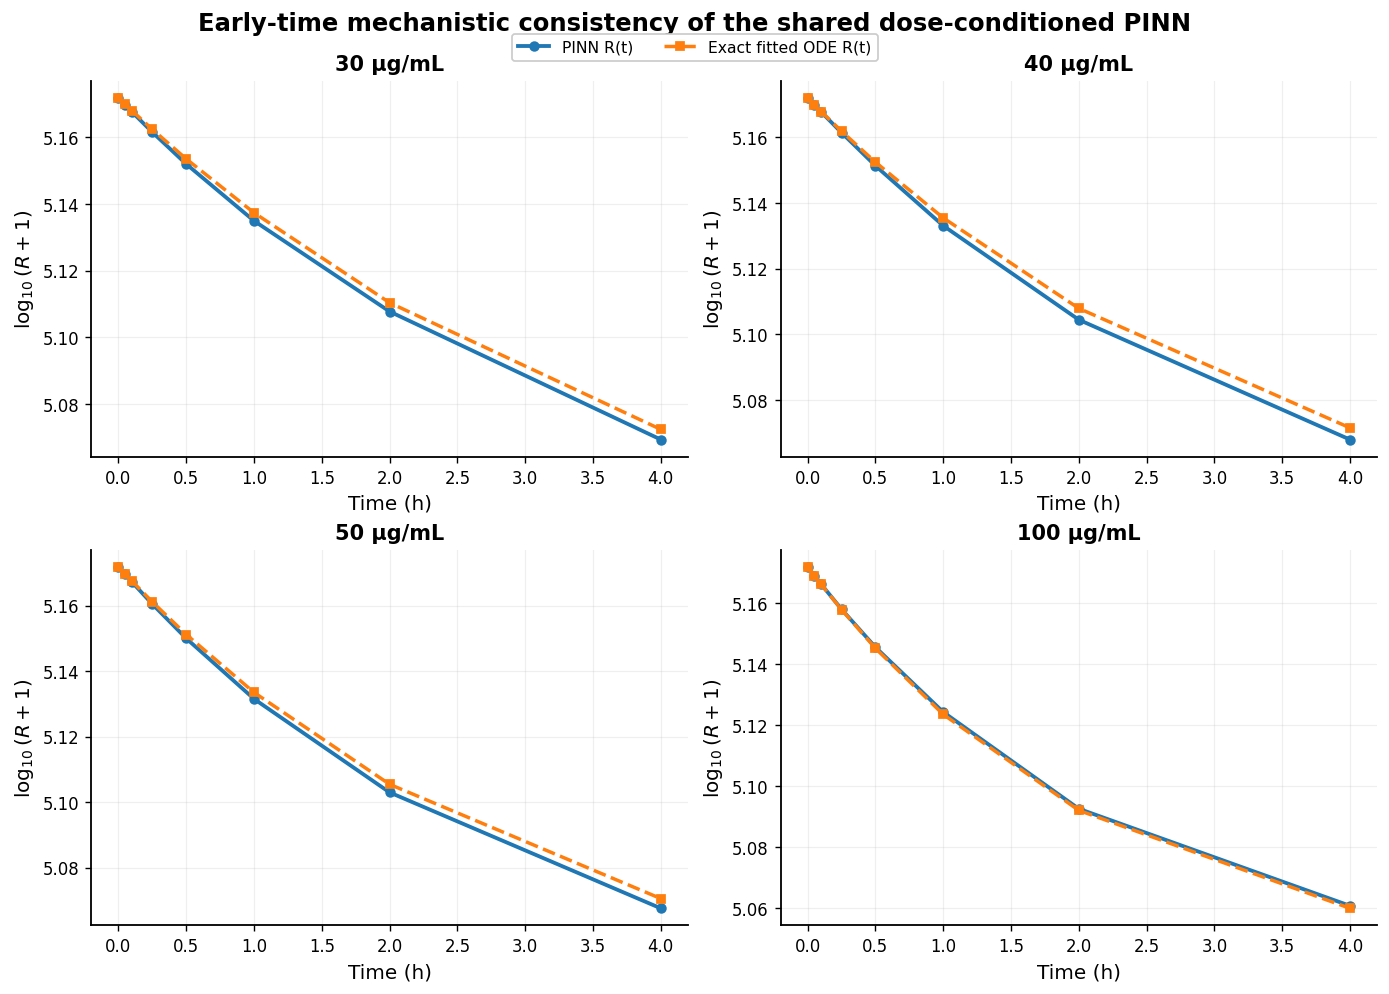

In [16]:
# =============================================================================
# DIAGNOSTIC B — VISUAL PINN vs EXACT ODE CONSISTENCY
# Shared dose-conditioned real-data PINN
# =============================================================================

fig, axes = plt.subplots(
    2,
    2,
    figsize=(11.0, 7.5),
    constrained_layout=True,
)

axes = axes.ravel()

treated_doses = [
    30.0,
    40.0,
    50.0,
    100.0,
]


for ax, dose in zip(
    axes,
    treated_doses,
):

    subset = ode_consistency[
        ode_consistency["dose_ug_ml"] == dose
    ]

    # -------------------------------------------------------------------------
    # PINN resistant-state trajectory
    # -------------------------------------------------------------------------

    ax.plot(
        subset["time_h"],
        subset["PINN_log10_R_plus1"],
        marker="o",
        linestyle="-",
        linewidth=2.2,
        markersize=5,
        label="PINN R(t)",
    )

    # -------------------------------------------------------------------------
    # Independent numerical solution of the same fitted mechanistic ODE
    # -------------------------------------------------------------------------

    ax.plot(
        subset["time_h"],
        subset["ODE_log10_R_plus1"],
        marker="s",
        linestyle="--",
        linewidth=2.0,
        markersize=5,
        label="Exact fitted ODE R(t)",
    )

    ax.set_title(
        f"{dose:g} µg/mL",
        fontweight="bold",
    )

    ax.set_xlabel(
        "Time (h)"
    )

    ax.set_ylabel(
        r"$\log_{10}(R+1)$"
    )

    ax.grid(
        alpha=0.20,
        linewidth=0.7,
    )

    ax.spines[
        [
            "top",
            "right",
        ]
    ].set_visible(
        False
    )


# =============================================================================
# SHARED LEGEND
# =============================================================================

handles, labels = (
    axes[0]
    .get_legend_handles_labels()
)

fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=2,
    bbox_to_anchor=(
        0.5,
        1.025,
    ),
)


# =============================================================================
# TITLE
# =============================================================================

fig.suptitle(
    "Early-time mechanistic consistency of the shared dose-conditioned PINN",
    fontsize=14,
    fontweight="bold",
    y=1.04,
)


# =============================================================================
# SAVE FIGURE
# =============================================================================

save_figure(
    fig,
    f"{RUN_LABEL}_R37_PINN_vs_exact_ODE_0_4h",
)

plt.show()

In [40]:
# =============================================================================
# RESTORE FINAL R3.8 FROM SAVED RESULTS — NO RETRAINING
# =============================================================================
#
# Restores:
#   cv_results
#   cv_summary
#   overall_holdout_summary
#
# It does NOT call train_real_model().
# =============================================================================

import numpy as np
import pandas as pd


# =============================================================================
# 1. FINAL R3.8 CONFIGURATION
# =============================================================================

R38_TAG = "R38_shared_dose_conditioned_logphys2p5_leave_one_dose_qR"

EXPECTED_R38_ARCHITECTURE = "shared_dose_conditioned_hard_PINN"
EXPECTED_R38_PHYSICS_WEIGHT = 25.0
EXPECTED_R38_LOG_PHYSICS_WEIGHT = 2.5

EXPECTED_R38_DOSES = [
    30.0,
    40.0,
    50.0,
    100.0,
]

EXPECTED_R38_SEEDS = [
    11,
    22,
    33,
]


CV_RESULTS_PATH = (
    TABLE_DIR
    / f"{RUN_LABEL}_{R38_TAG}_raw.csv"
)

CV_SUMMARY_PATH = (
    TABLE_DIR
    / f"{RUN_LABEL}_{R38_TAG}_summary.csv"
)

OVERALL_SUMMARY_PATH = (
    TABLE_DIR
    / f"{RUN_LABEL}_{R38_TAG}_overall_summary.csv"
)


# =============================================================================
# 2. CHECK FILES
# =============================================================================

print("=" * 96)
print("RESTORING FINAL R3.8 — LEAVE-ONE-DOSE PHENOTYPE-OUT")
print("=" * 96)

print("Raw results    :", CV_RESULTS_PATH)
print("Exists         :", CV_RESULTS_PATH.exists())

print("Dose summary   :", CV_SUMMARY_PATH)
print("Exists         :", CV_SUMMARY_PATH.exists())

print("Overall summary:", OVERALL_SUMMARY_PATH)
print("Exists         :", OVERALL_SUMMARY_PATH.exists())


missing_files = [
    path
    for path in [
        CV_RESULTS_PATH,
        CV_SUMMARY_PATH,
        OVERALL_SUMMARY_PATH,
    ]
    if not path.exists()
]

if missing_files:
    raise FileNotFoundError(
        "One or more FINAL R3.8 files are missing:\n"
        + "\n".join(str(p) for p in missing_files)
    )


# =============================================================================
# 3. LOAD SAVED RESULTS
# =============================================================================

cv_results = pd.read_csv(
    CV_RESULTS_PATH
)

cv_summary = pd.read_csv(
    CV_SUMMARY_PATH
)

overall_holdout_summary = pd.read_csv(
    OVERALL_SUMMARY_PATH
)


# =============================================================================
# 4. RAW-RESULT CONFIGURATION AUDIT
# =============================================================================

required_columns = {
    "architecture",
    "physics_weight",
    "log_physics_weight",
    "held_dose_ug_ml",
    "seed",
    "predicted_qR_48",
    "full_fit_qR_48",
    "observed_mean_qR_48",
}

missing_columns = (
    required_columns
    .difference(cv_results.columns)
)

if missing_columns:
    raise RuntimeError(
        "R3.8 raw results are missing required columns: "
        f"{sorted(missing_columns)}"
    )


if not (
    cv_results["architecture"]
    == EXPECTED_R38_ARCHITECTURE
).all():

    raise RuntimeError(
        "R3.8 cache contains an incompatible architecture."
    )


if not np.allclose(
    cv_results["physics_weight"].to_numpy(float),
    EXPECTED_R38_PHYSICS_WEIGHT,
):

    raise RuntimeError(
        "R3.8 physics-weight mismatch."
    )


if not np.allclose(
    cv_results["log_physics_weight"].to_numpy(float),
    EXPECTED_R38_LOG_PHYSICS_WEIGHT,
):

    raise RuntimeError(
        "R3.8 log-physics-weight mismatch."
    )


# =============================================================================
# 5. VERIFY ALL 12 FINAL FOLDS
# =============================================================================

expected_pairs = {
    (
        float(dose),
        int(seed),
    )
    for dose in EXPECTED_R38_DOSES
    for seed in EXPECTED_R38_SEEDS
}


observed_pairs = {
    (
        float(row.held_dose_ug_ml),
        int(row.seed),
    )
    for row in cv_results.itertuples()
}


missing_pairs = sorted(
    expected_pairs
    - observed_pairs
)

unexpected_pairs = sorted(
    observed_pairs
    - expected_pairs
)


if missing_pairs:
    raise RuntimeError(
        "FINAL R3.8 is incomplete. Missing dose/seed pairs:\n"
        f"{missing_pairs}"
    )


if unexpected_pairs:
    raise RuntimeError(
        "Unexpected dose/seed pairs were found in FINAL R3.8:\n"
        f"{unexpected_pairs}"
    )


if len(cv_results) != 12:
    raise RuntimeError(
        f"Expected exactly 12 FINAL R3.8 rows, found {len(cv_results)}."
    )


# =============================================================================
# 6. CHECK SUMMARY
# =============================================================================

summary_doses = sorted(
    cv_summary[
        "held_dose_ug_ml"
    ].astype(float)
    .unique()
    .tolist()
)


if summary_doses != EXPECTED_R38_DOSES:
    raise RuntimeError(
        "R3.8 dose-summary audit failed.\n"
        f"Found doses: {summary_doses}"
    )


if "n_seeds" in cv_summary.columns:

    if not (
        cv_summary["n_seeds"]
        .astype(int)
        == 3
    ).all():

        raise RuntimeError(
            "R3.8 summary does not contain three seeds per held dose."
        )


# =============================================================================
# 7. RESTORATION REPORT
# =============================================================================

print("\nFINAL R3.8 restoration audit: PASSED")

print(
    "Architecture      :",
    EXPECTED_R38_ARCHITECTURE,
)

print(
    "Physics weight    :",
    EXPECTED_R38_PHYSICS_WEIGHT,
)

print(
    "Log-physics weight:",
    EXPECTED_R38_LOG_PHYSICS_WEIGHT,
)

print(
    "Completed folds   :",
    len(cv_results),
    "/ 12",
)


print("\nR3.8 dose-wise summary:")
display(
    cv_summary
)


print("\nR3.8 overall holdout summary:")
display(
    overall_holdout_summary
)


print("=" * 96)
print("FINAL R3.8 RESTORED — NO RETRAINING PERFORMED")
print("=" * 96)

RESTORING FINAL R3.8 — LEAVE-ONE-DOSE PHENOTYPE-OUT
Raw results    : results\real_data\tables\final_R38_shared_dose_conditioned_logphys2p5_leave_one_dose_qR_raw.csv
Exists         : True
Dose summary   : results\real_data\tables\final_R38_shared_dose_conditioned_logphys2p5_leave_one_dose_qR_summary.csv
Exists         : True
Overall summary: results\real_data\tables\final_R38_shared_dose_conditioned_logphys2p5_leave_one_dose_qR_overall_summary.csv
Exists         : True

FINAL R3.8 restoration audit: PASSED
Architecture      : shared_dose_conditioned_hard_PINN
Physics weight    : 25.0
Log-physics weight: 2.5
Completed folds   : 12 / 12

R3.8 dose-wise summary:


,held_dose_ug_ml,n_seeds,predicted_qR_mean,predicted_qR_sd,full_fit_qR,observed_qR_mean,observed_qR_sd,mean_abs_error,mean_rmse_individual,mean_shift_from_full_fit_qR
0,30.0,3,0.575906,0.389677,0.456264,0.544982,0.477346,0.264204,0.535413,0.293777
1,40.0,3,0.652052,0.196586,0.905310,0.908514,0.133658,0.256462,0.302472,0.253258
2,50.0,3,0.982952,0.006674,0.981505,0.925957,0.156830,0.056995,0.156064,0.004607
3,100.0,3,0.999693,0.000025,0.999739,0.938089,0.077928,0.061604,0.094105,0.000046



R3.8 overall holdout summary:


,n_doses,mean_abs_error_across_doses,median_abs_error_across_doses,mean_rmse_to_individual_observations,mean_shift_from_full_fit_qR
0,4,0.159816,0.159033,0.272013,0.137922


FINAL R3.8 RESTORED — NO RETRAINING PERFORMED


EXPERIMENT R3.8 — FINAL 11F-R + P1 + P2 LEAVE-ONE-DOSE PHENOTYPE-OUT INFERENCE
Architecture              : shared_dose_conditioned_hard_PINN_11FR
Base physics weight       : 25.0
Base log-physics weight   : 2.5
P1 pointwise factor       : 5.0
P2 pointwise factor       : 5.0
P2 integral-defect weight : 10.0
Seeds                     : [11, 22, 33]
Execution mode            : FINAL (publication)
Full-data reference       : INTEGRAL_REFINED_RESULT

R3.8 HOLDOUT FOLD — hidden qR dose=30 µg/mL | seed=11

TRAINING R38_11FR_hide_qR_dose_30_seed_11
Architecture             : shared_dose_conditioned_hard_PINN_11FR
Physics variant          : 11F-R_reduced_time_structured_killing
State-network parameters : 12,867
Inverse raw parameters   : 12
Checkpoint               : results\real_data\models\final_R38_11FR_hide_qR_dose_30_seed_11_11FR.pt
History                  : results\real_data\histories\final_R38_11FR_hide_qR_dose_30_seed_11_11FR_history.csv
R38_11FR_hide_qR_dose_30_seed_11 | epoch     0/8

,held_dose_ug_ml,n_seeds,predicted_qR_mean,predicted_qR_sd,full_fit_qR,observed_qR_mean,observed_qR_sd,mean_abs_error,mean_rmse_individual,mean_shift_from_full_fit_qR,max_inverse_change_during_P1P2
0,30.0,3,0.700910,1.554782e-01,0.564396,0.544982,0.477346,0.155929,0.477159,1.365147e-01,0.0
1,40.0,3,0.969813,3.380732e-03,0.960847,0.908514,0.133658,0.061299,0.138116,8.965947e-03,0.0
2,50.0,3,0.997895,1.253210e-03,0.996757,0.925957,0.156830,0.071938,0.162043,1.254915e-03,0.0
3,100.0,3,1.000000,1.453091e-08,1.000000,0.938089,0.077928,0.061911,0.094306,1.090431e-08,0.0



Overall FINAL R3.8 holdout summary:


,n_doses,n_total_folds,mean_abs_error_across_doses,median_abs_error_across_doses,mean_rmse_to_individual_observations,mean_shift_from_full_fit_qR,max_inverse_change_during_P1P2
0,4,12,0.087769,0.066925,0.217906,0.036684,0.0


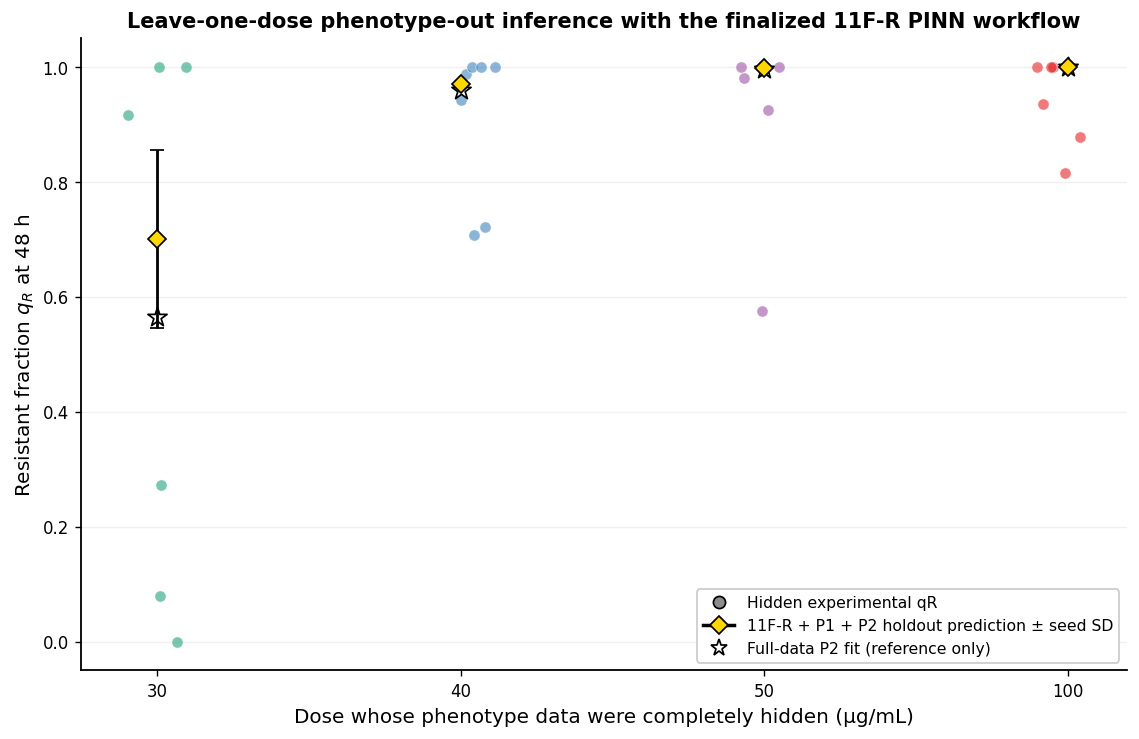


R3.8 COMPLETE — FINAL 11F-R + P1 + P2 LEAVE-ONE-DOSE PHENOTYPE-OUT INFERENCE
Raw folds saved to    : results\real_data\tables\final_R38_11FR_P1P2_shared_leave_one_dose_qR_raw.csv
Dose summary saved to : results\real_data\tables\final_R38_11FR_P1P2_shared_leave_one_dose_qR_summary.csv
Overall summary saved : results\real_data\tables\final_R38_11FR_P1P2_shared_leave_one_dose_qR_overall_summary.csv
Hidden qR was excluded from base training, P1, P2, and fold model selection.
INTEGRAL_REFINED_RESULT was used only as a full-data reference in reporting.


In [56]:
# CELL 9 — EXPERIMENT 3.8: LEAVE-ONE-DOSE PHENOTYPE-OUT INFERENCE
#          FINAL 11F-R + P1 + P2 WORKFLOW
# =============================================================================
#
# PURPOSE
# -------
# For each treated dose, ALL qR observations at that dose are hidden from:
#
#   1) the initial 11F-R fold training,
#   2) P1 state-only pointwise-physics refinement,
#   3) P2 state-only multi-scale integral-defect refinement,
#   4) all fold-specific model-selection losses.
#
# Total-load observations at the held dose remain available.
#
# The hidden qR observations are accessed ONLY AFTER the fold has been fully
# trained/refined, for final evaluation of qR(48 h).
#
# FINAL PER-FOLD WORKFLOW
# -----------------------
#
#   hide qR at one dose
#       ->
#   base 11F-R fold training with train_real_model(...)
#       ->
#   P1: freeze all inverse parameters, refine only the state network with
#       5x pointwise physics
#       ->
#   P2: keep inverse parameters frozen, refine only the state network with
#       5x pointwise physics + 10x multi-scale integral defect
#       ->
#   predict hidden qR at 48 h
#
# IMPORTANT
# ---------
# - This cell does NOT use the hidden qR observations during training or
#   validation/model selection.
# - FULL_RESULT is not modified.
# - PHYSICS_REFINED_RESULT is not modified.
# - INTEGRAL_REFINED_RESULT is used ONLY as the full-data reference fit in the
#   final summary/figure. It is NEVER used to initialize or train a holdout fold.
# - Fold-specific inverse parameters are learned only during the base 11F-R
#   training and then frozen during P1/P2, exactly matching the finalized
#   real-data workflow.
# - Results are saved to a NEW R3.8 cache tag so older R3.8 results cannot be
#   loaded accidentally.
# =============================================================================


# =============================================================================
# 0. FINAL CONFIGURATION
# =============================================================================

R38_TAG = (
    "R38_11FR_P1P2_shared_leave_one_dose_qR"
)

EXPECTED_R38_ARCHITECTURE = (
    "shared_dose_conditioned_hard_PINN_11FR"
)

EXPECTED_R38_PHYSICS_WEIGHT = 25.0

EXPECTED_R38_LOG_PHYSICS_WEIGHT = 2.5


# -----------------------------------------------------------------------------
# P1 settings — fixed to the already completed P1 diagnostic.
# -----------------------------------------------------------------------------

R38_P1_PHYSICS_FACTOR = 5.0

R38_P1_ADAM_EPOCHS = 1800

R38_P1_ADAM_LR = 2.0e-4

R38_P1_LOG_EVERY = 100

R38_P1_PATIENCE = 600

R38_P1_LBFGS_MAX_ITER = 200


# -----------------------------------------------------------------------------
# P2 settings — fixed to the already completed P2 diagnostic.
# -----------------------------------------------------------------------------

R38_P2_POINTWISE_PHYSICS_FACTOR = 5.0

R38_P2_INTEGRAL_WEIGHT = 10.0

R38_P2_ADAM_EPOCHS = 1200

R38_P2_ADAM_LR = 1.0e-4

R38_P2_LOG_EVERY = 100

R38_P2_PATIENCE = 500

R38_P2_LBFGS_MAX_ITER = 150


# -----------------------------------------------------------------------------
# Same P2 multi-scale windows used in the finalized full-data refinement.
# -----------------------------------------------------------------------------

R38_P2_SHORT_WINDOWS_H = [
    (0.0, 4.0),
    (4.0, 8.0),
    (8.0, 12.0),
    (12.0, 16.0),
    (16.0, 20.0),
    (20.0, 23.0),
    (23.0, 26.0),
    (26.0, 30.0),
    (30.0, 36.0),
    (36.0, 40.0),
    (40.0, 44.0),
    (44.0, 48.0),
]

R38_P2_LONG_WINDOWS_H = [
    (0.0, 23.0),
    (0.0, 48.0),
    (4.0, 23.0),
    (12.0, 36.0),
    (20.0, 48.0),
    (23.0, 48.0),
]

R38_P2_WINDOWS_H = (
    R38_P2_SHORT_WINDOWS_H
    + R38_P2_LONG_WINDOWS_H
)

R38_P2_INTEGRAL_GRID_H = np.arange(
    0.0,
    48.0 + 0.5,
    0.5,
    dtype=float,
)


# =============================================================================
# 1. CONFIGURATION GUARDS
# =============================================================================

required_r38_objects = [
    "FULL_RESULT",
    "PHYSICS_REFINED_RESULT",
    "INTEGRAL_REFINED_RESULT",
    "BASE_BUNDLE",
    "q48",
    "train_real_model",
    "complete_loss",
    "all_physics_residuals",
    "observation_metrics",
    "feasibility_audit",
    "predict_numpy",
    "make_collocation",
    "state_parameters",
    "set_inverse_trainable",
    "cpu_state_dict",
]

missing_r38_objects = [
    name
    for name in required_r38_objects
    if name not in globals()
]

if missing_r38_objects:

    raise RuntimeError(
        "Cell 9 requires the finalized Cells 5–8 plus P1 and P2.\n"
        f"Missing objects: {missing_r38_objects}"
    )


for result_name, result_object in [
    (
        "FULL_RESULT",
        FULL_RESULT,
    ),
    (
        "PHYSICS_REFINED_RESULT",
        PHYSICS_REFINED_RESULT,
    ),
    (
        "INTEGRAL_REFINED_RESULT",
        INTEGRAL_REFINED_RESULT,
    ),
]:

    architecture = getattr(
        result_object.model,
        "architecture_name",
        None,
    )

    if architecture != EXPECTED_R38_ARCHITECTURE:

        raise RuntimeError(
            f"{result_name} architecture mismatch.\n"
            f"Found    : {architecture!r}\n"
            f"Expected : {EXPECTED_R38_ARCHITECTURE!r}"
        )


if not np.isclose(
    float(
        LOSS_WEIGHTS.physics
    ),
    EXPECTED_R38_PHYSICS_WEIGHT,
):

    raise RuntimeError(
        "Cell 9 configuration mismatch: expected "
        f"LOSS_WEIGHTS.physics={EXPECTED_R38_PHYSICS_WEIGHT}, "
        f"found {float(LOSS_WEIGHTS.physics)}."
    )


if not np.isclose(
    float(
        LOSS_WEIGHTS.log_physics
    ),
    EXPECTED_R38_LOG_PHYSICS_WEIGHT,
):

    raise RuntimeError(
        "Cell 9 configuration mismatch: expected "
        f"LOSS_WEIGHTS.log_physics={EXPECTED_R38_LOG_PHYSICS_WEIGHT}, "
        f"found {float(LOSS_WEIGHTS.log_physics)}."
    )


treated_doses = [
    30.0,
    40.0,
    50.0,
    100.0,
]


if len(
    CV_SEEDS
) == 0:

    raise RuntimeError(
        "CV_SEEDS is empty; at least one seed is required for Experiment 3.8."
    )


print("=" * 112)
print("EXPERIMENT R3.8 — FINAL 11F-R + P1 + P2 LEAVE-ONE-DOSE PHENOTYPE-OUT INFERENCE")
print("=" * 112)

print(
    "Architecture              :",
    EXPECTED_R38_ARCHITECTURE,
)

print(
    "Base physics weight       :",
    EXPECTED_R38_PHYSICS_WEIGHT,
)

print(
    "Base log-physics weight   :",
    EXPECTED_R38_LOG_PHYSICS_WEIGHT,
)

print(
    "P1 pointwise factor       :",
    R38_P1_PHYSICS_FACTOR,
)

print(
    "P2 pointwise factor       :",
    R38_P2_POINTWISE_PHYSICS_FACTOR,
)

print(
    "P2 integral-defect weight :",
    R38_P2_INTEGRAL_WEIGHT,
)

print(
    "Seeds                     :",
    list(
        CV_SEEDS
    ),
)

print(
    "Execution mode            :",
    "QUICK (development)"
    if QUICK_MODE
    else "FINAL (publication)",
)

print(
    "Full-data reference       : INTEGRAL_REFINED_RESULT"
)

print("=" * 112)


# =============================================================================
# 2. NEW RESUME-SAFE CACHE PATHS
# =============================================================================

CV_RESULTS_PATH = (
    TABLE_DIR
    / f"{RUN_LABEL}_{R38_TAG}_raw.csv"
)

CV_SUMMARY_PATH = (
    TABLE_DIR
    / f"{RUN_LABEL}_{R38_TAG}_summary.csv"
)

OVERALL_SUMMARY_PATH = (
    TABLE_DIR
    / f"{RUN_LABEL}_{R38_TAG}_overall_summary.csv"
)


if (
    CV_RESULTS_PATH.exists()
    and not FORCE_RETRAIN
):

    cv_results = pd.read_csv(
        CV_RESULTS_PATH
    )

    print(
        "\nFound FINAL 11F-R/P1/P2 R3.8 cache:",
        CV_RESULTS_PATH,
    )

else:

    cv_results = pd.DataFrame()


# =============================================================================
# 3. CACHE COMPATIBILITY GUARD
# =============================================================================

R38_METADATA = {
    "architecture":
        EXPECTED_R38_ARCHITECTURE,

    "physics_weight":
        float(
            EXPECTED_R38_PHYSICS_WEIGHT
        ),

    "log_physics_weight":
        float(
            EXPECTED_R38_LOG_PHYSICS_WEIGHT
        ),

    "p1_physics_factor":
        float(
            R38_P1_PHYSICS_FACTOR
        ),

    "p1_adam_epochs":
        int(
            R38_P1_ADAM_EPOCHS
        ),

    "p1_lbfgs_max_iter":
        int(
            R38_P1_LBFGS_MAX_ITER
        ),

    "p2_pointwise_physics_factor":
        float(
            R38_P2_POINTWISE_PHYSICS_FACTOR
        ),

    "p2_integral_weight":
        float(
            R38_P2_INTEGRAL_WEIGHT
        ),

    "p2_adam_epochs":
        int(
            R38_P2_ADAM_EPOCHS
        ),

    "p2_lbfgs_max_iter":
        int(
            R38_P2_LBFGS_MAX_ITER
        ),
}


if not cv_results.empty:

    required_cache_columns = {
        "architecture",
        "physics_weight",
        "log_physics_weight",
        "p1_physics_factor",
        "p1_adam_epochs",
        "p1_lbfgs_max_iter",
        "p2_pointwise_physics_factor",
        "p2_integral_weight",
        "p2_adam_epochs",
        "p2_lbfgs_max_iter",
        "held_dose_ug_ml",
        "seed",
    }

    if not required_cache_columns.issubset(
        set(
            cv_results.columns
        )
    ):

        print(
            "Existing R3.8 cache lacks FINAL 11F-R/P1/P2 metadata; "
            "ignoring it and starting a clean cache."
        )

        cv_results = pd.DataFrame()

    else:

        compatible = (
            (
                cv_results[
                    "architecture"
                ]
                == EXPECTED_R38_ARCHITECTURE
            )
            &
            np.isclose(
                cv_results[
                    "physics_weight"
                ].to_numpy(
                    float
                ),
                EXPECTED_R38_PHYSICS_WEIGHT,
            )
            &
            np.isclose(
                cv_results[
                    "log_physics_weight"
                ].to_numpy(
                    float
                ),
                EXPECTED_R38_LOG_PHYSICS_WEIGHT,
            )
            &
            np.isclose(
                cv_results[
                    "p1_physics_factor"
                ].to_numpy(
                    float
                ),
                R38_P1_PHYSICS_FACTOR,
            )
            &
            (
                cv_results[
                    "p1_adam_epochs"
                ].to_numpy(
                    int
                )
                == int(
                    R38_P1_ADAM_EPOCHS
                )
            )
            &
            (
                cv_results[
                    "p1_lbfgs_max_iter"
                ].to_numpy(
                    int
                )
                == int(
                    R38_P1_LBFGS_MAX_ITER
                )
            )
            &
            np.isclose(
                cv_results[
                    "p2_pointwise_physics_factor"
                ].to_numpy(
                    float
                ),
                R38_P2_POINTWISE_PHYSICS_FACTOR,
            )
            &
            np.isclose(
                cv_results[
                    "p2_integral_weight"
                ].to_numpy(
                    float
                ),
                R38_P2_INTEGRAL_WEIGHT,
            )
            &
            (
                cv_results[
                    "p2_adam_epochs"
                ].to_numpy(
                    int
                )
                == int(
                    R38_P2_ADAM_EPOCHS
                )
            )
            &
            (
                cv_results[
                    "p2_lbfgs_max_iter"
                ].to_numpy(
                    int
                )
                == int(
                    R38_P2_LBFGS_MAX_ITER
                )
            )
        )

        removed_rows = int(
            (
                ~compatible
            ).sum()
        )

        if removed_rows > 0:

            print(
                f"Discarding {removed_rows} incompatible cached R3.8 row(s)."
            )

        cv_results = (
            cv_results.loc[
                compatible
            ]
            .copy()
            .reset_index(
                drop=True
            )
        )


# =============================================================================
# 4. HELPER — VERIFY INVERSE PARAMETERS DID NOT MOVE
# =============================================================================

def r38_parameter_freeze_difference(
    before: Dict[str, float],
    after: Dict[str, float],
) -> float:

    differences = []

    for key, before_value in before.items():

        if key not in after:
            continue

        try:

            b = float(
                before_value
            )

            a = float(
                after[
                    key
                ]
            )

        except Exception:
            continue

        differences.append(
            abs(
                a
                - b
            )
        )

    return (
        float(
            max(
                differences
            )
        )
        if differences
        else 0.0
    )


# =============================================================================
# 5. HELPER — P1 STATE-ONLY POINTWISE-PHYSICS REFINEMENT FOR ONE HOLDOUT FOLD
# =============================================================================

def r38_run_p1(
    source_model: RealAMRPINN,
    held_dose: float,
    seed: int,
):

    """
    P1 for one R3.8 fold.

    ALL inverse parameters are frozen.
    ALL qR observations at held_dose remain hidden from training and validation.
    """

    hidden = {
        float(
            held_dose
        )
    }

    model = RealAMRPINN(
        BASE_BUNDLE
    ).to(
        DEVICE
    )

    model.load_state_dict(
        cpu_state_dict(
            source_model
        ),
        strict=True,
    )

    inverse_before = (
        model
        .inferred_parameters()
    )

    set_inverse_trainable(
        model,
        False,
    )

    if any(
        p.requires_grad
        for p
        in model.inverse.parameters()
    ):

        raise RuntimeError(
            "R3.8 P1 inverse-parameter freeze failed."
        )


    fixed_val_collocation = make_collocation(
        BASE_BUNDLE.doses,
        seed=int(
            seed
        ) + 610_000,
        points_per_dose=max(
            128,
            COLLOCATION_POINTS_PER_DOSE // 2,
        ),
    )


    def validation_score_p1():

        total, components = complete_loss(
            model=model,
            bundle=BASE_BUNDLE,
            collocation=fixed_val_collocation,
            split="val",
            physics_weight=R38_P1_PHYSICS_FACTOR,
            hide_fraction_doses=hidden,
        )

        return (
            float(
                total
                .detach()
                .cpu()
            ),
            components,
        )


    optimizer = torch.optim.AdamW(
        state_parameters(
            model
        ),
        lr=R38_P1_ADAM_LR,
        weight_decay=0.0,
    )


    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.5,
        patience=3,
        min_lr=2.0e-6,
    )


    best_score, _ = validation_score_p1()

    best_state = cpu_state_dict(
        model
    )

    stale_epochs = 0

    collocation = None


    for epoch in range(
        R38_P1_ADAM_EPOCHS
    ):

        if (
            collocation is None
            or epoch % RESAMPLE_EVERY == 0
        ):

            if collocation is not None:
                del collocation

            collocation = make_collocation(
                BASE_BUNDLE.doses,
                seed=int(
                    seed
                ) + 620_000 + epoch,
            )


        optimizer.zero_grad(
            set_to_none=True
        )


        loss, _ = complete_loss(
            model=model,
            bundle=BASE_BUNDLE,
            collocation=collocation,
            split="train",
            physics_weight=R38_P1_PHYSICS_FACTOR,
            hide_fraction_doses=hidden,
        )


        if not torch.isfinite(
            loss
        ):

            raise FloatingPointError(
                f"Non-finite R3.8 P1 loss for held dose {held_dose:g}, "
                f"seed {seed}, epoch {epoch}."
            )


        loss.backward()


        torch.nn.utils.clip_grad_norm_(
            state_parameters(
                model
            ),
            GRADIENT_CLIP_NORM,
        )


        optimizer.step()


        if (
            epoch % R38_P1_LOG_EVERY == 0
            or epoch == R38_P1_ADAM_EPOCHS - 1
        ):

            score, components = validation_score_p1()

            scheduler.step(
                score
            )


            print(
                f"R3.8 P1 | hold={held_dose:g} | seed={seed} | "
                f"{epoch:4d}/{R38_P1_ADAM_EPOCHS} | "
                f"val={score:.4e} | "
                f"raw-phys={components['physics_raw_rmse_per_h']:.3e}/h"
            )


            if score < best_score * (
                1.0 - 1e-7
            ):

                best_score = score

                best_state = cpu_state_dict(
                    model
                )

                stale_epochs = 0

            else:

                stale_epochs += R38_P1_LOG_EVERY


            if stale_epochs >= R38_P1_PATIENCE:

                print(
                    f"R3.8 P1 early stop | hold={held_dose:g} | "
                    f"seed={seed} | epoch={epoch}"
                )

                break


    if collocation is not None:
        del collocation


    model.load_state_dict(
        best_state
    )

    clear_memory()


    # -------------------------------------------------------------------------
    # P1 L-BFGS
    # -------------------------------------------------------------------------

    fixed_train_collocation = make_collocation(
        BASE_BUNDLE.doses,
        seed=int(
            seed
        ) + 630_000,
        points_per_dose=max(
            192,
            COLLOCATION_POINTS_PER_DOSE,
        ),
    )


    optimizer_lbfgs = torch.optim.LBFGS(
        state_parameters(
            model
        ),
        lr=0.5,
        max_iter=R38_P1_LBFGS_MAX_ITER,
        max_eval=max(
            2 * R38_P1_LBFGS_MAX_ITER,
            40,
        ),
        tolerance_grad=1e-10,
        tolerance_change=1e-12,
        history_size=50,
        line_search_fn="strong_wolfe",
    )


    def closure():

        optimizer_lbfgs.zero_grad(
            set_to_none=True
        )

        loss, _ = complete_loss(
            model=model,
            bundle=BASE_BUNDLE,
            collocation=fixed_train_collocation,
            split="train",
            physics_weight=R38_P1_PHYSICS_FACTOR,
            hide_fraction_doses=hidden,
        )

        if not torch.isfinite(
            loss
        ):

            raise FloatingPointError(
                "Non-finite R3.8 P1 L-BFGS loss."
            )

        loss.backward()

        return loss


    optimizer_lbfgs.step(
        closure
    )


    lbfgs_score, _ = validation_score_p1()


    if lbfgs_score < best_score:

        best_score = lbfgs_score

        best_state = cpu_state_dict(
            model
        )


    model.load_state_dict(
        best_state
    )


    del fixed_train_collocation
    del fixed_val_collocation

    clear_memory()


    inverse_after = (
        model
        .inferred_parameters()
    )


    max_inverse_change = r38_parameter_freeze_difference(
        inverse_before,
        inverse_after,
    )


    if max_inverse_change > 1e-14:

        raise RuntimeError(
            "R3.8 P1 changed a frozen inverse parameter."
        )


    return (
        model,
        float(
            best_score
        ),
        float(
            max_inverse_change
        ),
    )


# =============================================================================
# 6. HELPER — DIFFERENTIABLE P2 MULTI-SCALE INTEGRAL-DEFECT LOSS
# =============================================================================

def r38_integral_defect_loss(
    model: RealAMRPINN,
):

    loss_terms = []


    for dose in BASE_BUNDLE.doses:

        t = tensor_column(
            R38_P2_INTEGRAL_GRID_H,
            requires_grad=True,
        )


        (
            _raw_s,
            _raw_r,
            _scaled_s,
            _scaled_r,
            log_residual_s,
            log_residual_r,
        ) = all_physics_residuals(
            model=model,
            t=t,
            dose=float(
                dose
            ),
            create_graph=True,
        )


        tau = (
            t
            / PHYSICS_TIME_SCALE_H
        )


        t_flat = t[
            :,
            0
        ]

        tau_flat = tau[
            :,
            0
        ]

        rs_flat = log_residual_s[
            :,
            0
        ]

        rr_flat = log_residual_r[
            :,
            0
        ]


        for start_h, end_h in R38_P2_WINDOWS_H:

            mask = (
                (
                    t_flat
                    >= start_h - 1e-12
                )
                &
                (
                    t_flat
                    <= end_h + 1e-12
                )
            )


            defect_s = torch.trapz(
                rs_flat[
                    mask
                ],
                tau_flat[
                    mask
                ],
            )


            defect_r = torch.trapz(
                rr_flat[
                    mask
                ],
                tau_flat[
                    mask
                ],
            )


            loss_terms.append(
                0.5
                * (
                    defect_s ** 2
                    +
                    defect_r ** 2
                )
            )


    return torch.stack(
        loss_terms
    ).mean()


# =============================================================================
# 7. HELPER — P2 STATE-ONLY INTEGRAL-DEFECT REFINEMENT FOR ONE HOLDOUT FOLD
# =============================================================================

def r38_run_p2(
    source_model: RealAMRPINN,
    held_dose: float,
    seed: int,
):

    """
    P2 for one R3.8 fold.

    The held-dose qR observations remain hidden in BOTH train and validation
    losses. The integral-defect term uses physics only and therefore introduces
    no hidden-phenotype leakage.
    """

    hidden = {
        float(
            held_dose
        )
    }


    model = RealAMRPINN(
        BASE_BUNDLE
    ).to(
        DEVICE
    )


    model.load_state_dict(
        cpu_state_dict(
            source_model
        ),
        strict=True,
    )


    inverse_before = (
        model
        .inferred_parameters()
    )


    set_inverse_trainable(
        model,
        False,
    )


    if any(
        p.requires_grad
        for p
        in model.inverse.parameters()
    ):

        raise RuntimeError(
            "R3.8 P2 inverse-parameter freeze failed."
        )


    fixed_val_collocation = make_collocation(
        BASE_BUNDLE.doses,
        seed=int(
            seed
        ) + 710_000,
        points_per_dose=max(
            128,
            COLLOCATION_POINTS_PER_DOSE // 2,
        ),
    )


    def validation_score_p2():

        base_total, components = complete_loss(
            model=model,
            bundle=BASE_BUNDLE,
            collocation=fixed_val_collocation,
            split="val",
            physics_weight=R38_P2_POINTWISE_PHYSICS_FACTOR,
            hide_fraction_doses=hidden,
        )


        integral_loss = r38_integral_defect_loss(
            model
        )


        total = (
            base_total
            +
            R38_P2_INTEGRAL_WEIGHT
            * integral_loss
        )


        return (
            float(
                total
                .detach()
                .cpu()
            ),
            components,
            float(
                integral_loss
                .detach()
                .cpu()
            ),
        )


    optimizer = torch.optim.AdamW(
        state_parameters(
            model
        ),
        lr=R38_P2_ADAM_LR,
        weight_decay=0.0,
    )


    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.5,
        patience=3,
        min_lr=1.0e-6,
    )


    best_score, _, _ = validation_score_p2()

    best_state = cpu_state_dict(
        model
    )

    stale_epochs = 0

    collocation = None


    for epoch in range(
        R38_P2_ADAM_EPOCHS
    ):

        if (
            collocation is None
            or epoch % RESAMPLE_EVERY == 0
        ):

            if collocation is not None:
                del collocation

            collocation = make_collocation(
                BASE_BUNDLE.doses,
                seed=int(
                    seed
                ) + 720_000 + epoch,
            )


        optimizer.zero_grad(
            set_to_none=True
        )


        base_loss, _ = complete_loss(
            model=model,
            bundle=BASE_BUNDLE,
            collocation=collocation,
            split="train",
            physics_weight=R38_P2_POINTWISE_PHYSICS_FACTOR,
            hide_fraction_doses=hidden,
        )


        integral_loss = r38_integral_defect_loss(
            model
        )


        total_loss = (
            base_loss
            +
            R38_P2_INTEGRAL_WEIGHT
            * integral_loss
        )


        if not torch.isfinite(
            total_loss
        ):

            raise FloatingPointError(
                f"Non-finite R3.8 P2 loss for held dose {held_dose:g}, "
                f"seed {seed}, epoch {epoch}."
            )


        total_loss.backward()


        torch.nn.utils.clip_grad_norm_(
            state_parameters(
                model
            ),
            GRADIENT_CLIP_NORM,
        )


        optimizer.step()


        if (
            epoch % R38_P2_LOG_EVERY == 0
            or epoch == R38_P2_ADAM_EPOCHS - 1
        ):

            (
                score,
                components,
                integral_value,
            ) = validation_score_p2()


            scheduler.step(
                score
            )


            print(
                f"R3.8 P2 | hold={held_dose:g} | seed={seed} | "
                f"{epoch:4d}/{R38_P2_ADAM_EPOCHS} | "
                f"val={score:.4e} | "
                f"raw-phys={components['physics_raw_rmse_per_h']:.3e}/h | "
                f"integral={integral_value:.3e}"
            )


            if score < best_score * (
                1.0 - 1e-7
            ):

                best_score = score

                best_state = cpu_state_dict(
                    model
                )

                stale_epochs = 0

            else:

                stale_epochs += R38_P2_LOG_EVERY


            if stale_epochs >= R38_P2_PATIENCE:

                print(
                    f"R3.8 P2 early stop | hold={held_dose:g} | "
                    f"seed={seed} | epoch={epoch}"
                )

                break


    if collocation is not None:
        del collocation


    model.load_state_dict(
        best_state
    )


    clear_memory()


    # -------------------------------------------------------------------------
    # P2 L-BFGS
    # -------------------------------------------------------------------------

    fixed_train_collocation = make_collocation(
        BASE_BUNDLE.doses,
        seed=int(
            seed
        ) + 730_000,
        points_per_dose=max(
            192,
            COLLOCATION_POINTS_PER_DOSE,
        ),
    )


    optimizer_lbfgs = torch.optim.LBFGS(
        state_parameters(
            model
        ),
        lr=0.45,
        max_iter=R38_P2_LBFGS_MAX_ITER,
        max_eval=max(
            2 * R38_P2_LBFGS_MAX_ITER,
            40,
        ),
        tolerance_grad=1e-10,
        tolerance_change=1e-12,
        history_size=50,
        line_search_fn="strong_wolfe",
    )


    def closure():

        optimizer_lbfgs.zero_grad(
            set_to_none=True
        )


        base_loss, _ = complete_loss(
            model=model,
            bundle=BASE_BUNDLE,
            collocation=fixed_train_collocation,
            split="train",
            physics_weight=R38_P2_POINTWISE_PHYSICS_FACTOR,
            hide_fraction_doses=hidden,
        )


        integral_loss = r38_integral_defect_loss(
            model
        )


        loss = (
            base_loss
            +
            R38_P2_INTEGRAL_WEIGHT
            * integral_loss
        )


        if not torch.isfinite(
            loss
        ):

            raise FloatingPointError(
                "Non-finite R3.8 P2 L-BFGS loss."
            )


        loss.backward()

        return loss


    optimizer_lbfgs.step(
        closure
    )


    lbfgs_score, _, _ = validation_score_p2()


    if lbfgs_score < best_score:

        best_score = lbfgs_score

        best_state = cpu_state_dict(
            model
        )


    model.load_state_dict(
        best_state
    )


    del fixed_train_collocation
    del fixed_val_collocation

    clear_memory()


    inverse_after = (
        model
        .inferred_parameters()
    )


    max_inverse_change = r38_parameter_freeze_difference(
        inverse_before,
        inverse_after,
    )


    if max_inverse_change > 1e-14:

        raise RuntimeError(
            "R3.8 P2 changed a frozen inverse parameter."
        )


    return (
        model,
        float(
            best_score
        ),
        float(
            max_inverse_change
        ),
    )


# =============================================================================
# 8. TRAIN ONLY MISSING FINAL R3.8 FOLDS
# =============================================================================

for held_dose in treated_doses:

    for cv_seed in CV_SEEDS:

        held_dose = float(
            held_dose
        )

        cv_seed = int(
            cv_seed
        )


        already_done = False


        if not cv_results.empty:

            mask = (
                np.isclose(
                    cv_results[
                        "held_dose_ug_ml"
                    ].to_numpy(
                        float
                    ),
                    held_dose,
                )
                &
                (
                    cv_results[
                        "seed"
                    ].to_numpy(
                        int
                    )
                    == cv_seed
                )
            )


            already_done = bool(
                mask.any()
            )


        if already_done:

            print(
                f"\nSkipping cached FINAL R3.8 fold: "
                f"dose={held_dose:g}, seed={cv_seed}"
            )

            continue


        print("\n" + "=" * 112)

        print(
            f"R3.8 HOLDOUT FOLD — hidden qR dose={held_dose:g} µg/mL | "
            f"seed={cv_seed}"
        )

        print("=" * 112)


        # =====================================================================
        # 8A. BASE 11F-R HOLDOUT TRAINING
        # =====================================================================

        label = (
            f"R38_11FR_hide_qR_dose_{int(held_dose)}_seed_{cv_seed}"
        )


        base_result = train_real_model(
            BASE_BUNDLE,
            seed=cv_seed,
            label=label,
            hide_fraction_doses={
                held_dose
            },
            save_checkpoint=False,
        )


        if (
            base_result.model.architecture_name
            != EXPECTED_R38_ARCHITECTURE
        ):

            raise RuntimeError(
                "R3.8 fold trained with the wrong architecture."
            )


        base_inferred = (
            base_result.model
            .inferred_parameters()
        )


        # =====================================================================
        # 8B. P1 — STATE-ONLY POINTWISE-PHYSICS REFINEMENT
        # =====================================================================

        (
            p1_model,
            p1_best_score,
            p1_max_inverse_change,
        ) = r38_run_p1(
            source_model=base_result.model,
            held_dose=held_dose,
            seed=cv_seed,
        )


        # =====================================================================
        # 8C. P2 — STATE-ONLY MULTI-SCALE INTEGRAL-DEFECT REFINEMENT
        # =====================================================================

        (
            p2_model,
            p2_best_score,
            p2_max_inverse_change,
        ) = r38_run_p2(
            source_model=p1_model,
            held_dose=held_dose,
            seed=cv_seed,
        )


        # =====================================================================
        # 8D. TRUE HOLDOUT PREDICTION
        # =====================================================================
        #
        # This is the FIRST point at which the hidden qR observations are used,
        # and only for evaluation.
        # =====================================================================

        predicted_qR_48 = float(
            predict_numpy(
                p2_model,
                held_dose,
                np.array(
                    [
                        48.0
                    ]
                ),
            )[
                "resistant_fraction"
            ].iloc[
                0
            ]
        )


        # ---------------------------------------------------------------------
        # Full-data P2 fit shown only as context/reference.
        # It is NEVER used to train or initialize this holdout fold.
        # ---------------------------------------------------------------------

        full_fit_qR_48 = float(
            predict_numpy(
                INTEGRAL_REFINED_RESULT.model,
                held_dose,
                np.array(
                    [
                        48.0
                    ]
                ),
            )[
                "resistant_fraction"
            ].iloc[
                0
            ]
        )


        # ---------------------------------------------------------------------
        # NOW access hidden experimental phenotype observations for evaluation.
        # ---------------------------------------------------------------------

        obs = q48.loc[
            q48[
                "dose_ug_ml"
            ] == held_dose,
            "resistant_fraction_qR",
        ].to_numpy(
            float
        )


        if len(
            obs
        ) == 0:

            raise RuntimeError(
                f"No qR observations were found at held dose {held_dose:g}."
            )


        final_inferred = (
            p2_model
            .inferred_parameters()
        )


        # ---------------------------------------------------------------------
        # Sanity check:
        # P1/P2 must not change the inverse parameters learned by base training.
        # ---------------------------------------------------------------------

        final_inverse_change_from_base = (
            r38_parameter_freeze_difference(
                base_inferred,
                final_inferred,
            )
        )


        if final_inverse_change_from_base > 1e-14:

            raise RuntimeError(
                "R3.8 P1/P2 changed fold-specific inverse parameters."
            )


        row = {
            **R38_METADATA,

            "held_dose_ug_ml":
                held_dose,

            "seed":
                cv_seed,

            "predicted_qR_48":
                predicted_qR_48,

            "full_fit_qR_48":
                full_fit_qR_48,

            "observed_mean_qR_48":
                float(
                    obs.mean()
                ),

            "observed_sd_qR_48":
                (
                    float(
                        obs.std(
                            ddof=1
                        )
                    )
                    if len(
                        obs
                    ) > 1
                    else 0.0
                ),

            "abs_error_to_observed_mean":
                float(
                    abs(
                        predicted_qR_48
                        - obs.mean()
                    )
                ),

            "rmse_to_individual_observations":
                float(
                    np.sqrt(
                        np.mean(
                            (
                                obs
                                - predicted_qR_48
                            ) ** 2
                        )
                    )
                ),

            "abs_shift_from_full_fit_qR":
                float(
                    abs(
                        predicted_qR_48
                        - full_fit_qR_48
                    )
                ),

            "base_best_validation_score":
                float(
                    base_result.best_validation_score
                ),

            "p1_best_validation_score":
                float(
                    p1_best_score
                ),

            "p2_best_validation_score":
                float(
                    p2_best_score
                ),

            "p1_max_inverse_parameter_change":
                float(
                    p1_max_inverse_change
                ),

            "p2_max_inverse_parameter_change":
                float(
                    p2_max_inverse_change
                ),

            "final_inverse_change_from_base":
                float(
                    final_inverse_change_from_base
                ),

            **final_inferred,
        }


        cv_results = pd.concat(
            [
                cv_results,
                pd.DataFrame(
                    [
                        row
                    ]
                ),
            ],
            ignore_index=True,
        )


        cv_results = (
            cv_results
            .sort_values(
                [
                    "held_dose_ug_ml",
                    "seed",
                ]
            )
            .reset_index(
                drop=True
            )
        )


        # ---------------------------------------------------------------------
        # Resume-safe save after EVERY completed fold.
        # ---------------------------------------------------------------------

        cv_results.to_csv(
            CV_RESULTS_PATH,
            index=False,
        )


        print(
            "\nCompleted FINAL R3.8 fold:"
        )

        print(
            f"  held dose                 = {held_dose:g} µg/mL"
        )

        print(
            f"  seed                      = {cv_seed}"
        )

        print(
            f"  hidden qR prediction      = {predicted_qR_48:.6f}"
        )

        print(
            f"  hidden qR observed mean   = {obs.mean():.6f}"
        )

        print(
            f"  absolute error            = "
            f"{abs(predicted_qR_48 - obs.mean()):.6f}"
        )

        print(
            f"  full-data P2 reference qR = {full_fit_qR_48:.6f}"
        )

        print(
            f"  inverse change in P1/P2   = "
            f"{final_inverse_change_from_base:.3e}"
        )


        del base_result
        del p1_model
        del p2_model

        clear_memory()


# =============================================================================
# 9. CHECK THAT ALL REQUESTED FOLDS ARE PRESENT
# =============================================================================

expected_pairs = {
    (
        float(
            dose
        ),
        int(
            seed
        ),
    )
    for dose in treated_doses
    for seed in CV_SEEDS
}


observed_pairs = {
    (
        float(
            row.held_dose_ug_ml
        ),
        int(
            row.seed
        ),
    )
    for row in cv_results.itertuples()
}


missing_pairs = sorted(
    expected_pairs
    - observed_pairs
)


if missing_pairs:

    raise RuntimeError(
        "R3.8 is incomplete. Missing dose/seed folds: "
        + str(
            missing_pairs
        )
    )


# =============================================================================
# 10. DOSE-WISE SUMMARY
# =============================================================================

summary_rows = []


for held_dose in treated_doses:

    group = cv_results[
        np.isclose(
            cv_results[
                "held_dose_ug_ml"
            ].to_numpy(
                float
            ),
            held_dose,
        )
    ].copy()


    predictions = group[
        "predicted_qR_48"
    ].to_numpy(
        float
    )


    n_seeds = len(
        predictions
    )


    summary_rows.append(
        {
            "held_dose_ug_ml":
                float(
                    held_dose
                ),

            "n_seeds":
                int(
                    n_seeds
                ),

            "predicted_qR_mean":
                float(
                    predictions.mean()
                ),

            "predicted_qR_sd":
                (
                    float(
                        predictions.std(
                            ddof=1
                        )
                    )
                    if n_seeds > 1
                    else np.nan
                ),

            "full_fit_qR":
                float(
                    group[
                        "full_fit_qR_48"
                    ].mean()
                ),

            "observed_qR_mean":
                float(
                    group[
                        "observed_mean_qR_48"
                    ].mean()
                ),

            "observed_qR_sd":
                float(
                    group[
                        "observed_sd_qR_48"
                    ].mean()
                ),

            "mean_abs_error":
                float(
                    group[
                        "abs_error_to_observed_mean"
                    ].mean()
                ),

            "mean_rmse_individual":
                float(
                    group[
                        "rmse_to_individual_observations"
                    ].mean()
                ),

            "mean_shift_from_full_fit_qR":
                float(
                    group[
                        "abs_shift_from_full_fit_qR"
                    ].mean()
                ),

            "max_inverse_change_during_P1P2":
                float(
                    group[
                        "final_inverse_change_from_base"
                    ].max()
                ),
        }
    )


cv_summary = pd.DataFrame(
    summary_rows
)


cv_summary.to_csv(
    CV_SUMMARY_PATH,
    index=False,
)


print(
    "\nFINAL 11F-R + P1 + P2 leave-one-dose phenotype-out summary:"
)

display(
    cv_summary
)


# =============================================================================
# 11. OVERALL HOLDOUT SUMMARY
# =============================================================================

overall_holdout_summary = pd.DataFrame(
    [
        {
            "n_doses":
                int(
                    len(
                        cv_summary
                    )
                ),

            "n_total_folds":
                int(
                    len(
                        cv_results
                    )
                ),

            "mean_abs_error_across_doses":
                float(
                    cv_summary[
                        "mean_abs_error"
                    ].mean()
                ),

            "median_abs_error_across_doses":
                float(
                    cv_summary[
                        "mean_abs_error"
                    ].median()
                ),

            "mean_rmse_to_individual_observations":
                float(
                    cv_summary[
                        "mean_rmse_individual"
                    ].mean()
                ),

            "mean_shift_from_full_fit_qR":
                float(
                    cv_summary[
                        "mean_shift_from_full_fit_qR"
                    ].mean()
                ),

            "max_inverse_change_during_P1P2":
                float(
                    cv_summary[
                        "max_inverse_change_during_P1P2"
                    ].max()
                ),
        }
    ]
)


overall_holdout_summary.to_csv(
    OVERALL_SUMMARY_PATH,
    index=False,
)


print(
    "\nOverall FINAL R3.8 holdout summary:"
)

display(
    overall_holdout_summary
)


if len(
    CV_SEEDS
) == 1:

    print(
        "\nNote: one CV seed was used, so predicted_qR_sd is undefined (NaN). "
        "A multi-seed FINAL run is required for seed-variability estimates."
    )


# =============================================================================
# 12. PUBLICATION-QUALITY HOLDOUT FIGURE
# =============================================================================

fig, ax = plt.subplots(
    figsize=(
        9.0,
        5.8,
    ),
    constrained_layout=True,
)


rng = np.random.default_rng(
    SEED + 38
)


for x, dose in enumerate(
    treated_doses
):

    obs = q48.loc[
        q48[
            "dose_ug_ml"
        ] == dose,
        "resistant_fraction_qR",
    ].to_numpy(
        float
    )


    jitter = rng.normal(
        0.0,
        0.055,
        size=len(
            obs
        ),
    )


    ax.scatter(
        np.full(
            len(
                obs
            ),
            x,
        )
        + jitter,
        obs,
        s=42,
        alpha=0.58,
        color=DOSE_COLORS[
            dose
        ],
        edgecolor="white",
        linewidth=0.5,
        zorder=2,
    )


    pred_seed = cv_results.loc[
        np.isclose(
            cv_results[
                "held_dose_ug_ml"
            ].to_numpy(
                float
            ),
            dose,
        ),
        "predicted_qR_48",
    ].to_numpy(
        float
    )


    pred_mean = float(
        pred_seed.mean()
    )


    pred_sd = (
        float(
            pred_seed.std(
                ddof=1
            )
        )
        if len(
            pred_seed
        ) > 1
        else 0.0
    )


    ax.errorbar(
        x,
        pred_mean,
        yerr=pred_sd,
        fmt="D",
        markersize=7.5,
        color="black",
        markerfacecolor="gold",
        capsize=4,
        linewidth=1.6,
        zorder=6,
    )


    # -------------------------------------------------------------------------
    # Open star = full-data P2 fit, shown only for context.
    # -------------------------------------------------------------------------

    full_fit_q = float(
        cv_summary.loc[
            np.isclose(
                cv_summary[
                    "held_dose_ug_ml"
                ].to_numpy(
                    float
                ),
                dose,
            ),
            "full_fit_qR",
        ].iloc[
            0
        ]
    )


    ax.scatter(
        x,
        full_fit_q,
        marker="*",
        s=135,
        facecolor="white",
        edgecolor="black",
        linewidth=1.0,
        zorder=5,
    )


ax.set_xticks(
    range(
        len(
            treated_doses
        )
    ),
    [
        str(
            int(
                d
            )
        )
        for d in treated_doses
    ],
)


ax.set_xlabel(
    "Dose whose phenotype data were completely hidden (µg/mL)"
)


ax.set_ylabel(
    r"Resistant fraction $q_R$ at 48 h"
)


ax.set_ylim(
    -0.05,
    1.05,
)


ax.grid(
    axis="y",
    alpha=0.18,
)


ax.spines[
    [
        "top",
        "right",
    ]
].set_visible(
    False
)


holdout_label = (
    "11F-R + P1 + P2 holdout prediction ± seed SD"
    if len(
        CV_SEEDS
    ) > 1
    else "11F-R + P1 + P2 holdout prediction"
)


ax.legend(
    handles=[
        Line2D(
            [
                0
            ],
            [
                0
            ],
            marker="o",
            color="none",
            markerfacecolor="0.55",
            label="Hidden experimental qR",
            markersize=7,
        ),
        Line2D(
            [
                0
            ],
            [
                0
            ],
            marker="D",
            color="black",
            markerfacecolor="gold",
            label=holdout_label,
            markersize=7,
        ),
        Line2D(
            [
                0
            ],
            [
                0
            ],
            marker="*",
            color="none",
            markerfacecolor="white",
            markeredgecolor="black",
            label="Full-data P2 fit (reference only)",
            markersize=10,
        ),
    ],
    loc="lower right",
)


ax.set_title(
    "Leave-one-dose phenotype-out inference with the finalized 11F-R PINN workflow",
    fontweight="bold",
)


save_figure(
    fig,
    f"{RUN_LABEL}_{R38_TAG}",
)


plt.show()


# =============================================================================
# 13. FINAL R3.8 REPORT
# =============================================================================

print("\n" + "=" * 112)

print(
    "R3.8 COMPLETE — FINAL 11F-R + P1 + P2 LEAVE-ONE-DOSE PHENOTYPE-OUT INFERENCE"
)

print("=" * 112)

print(
    "Raw folds saved to    :",
    CV_RESULTS_PATH,
)

print(
    "Dose summary saved to :",
    CV_SUMMARY_PATH,
)

print(
    "Overall summary saved :",
    OVERALL_SUMMARY_PATH,
)

print(
    "Hidden qR was excluded from base training, P1, P2, and fold model selection."
)

print(
    "INTEGRAL_REFINED_RESULT was used only as a full-data reference in reporting."
)

print("=" * 112)

In [14]:
print("Kernel/model still available:", "FULL_RESULT" in globals())
print("QUICK_MODE:", QUICK_MODE)
print("RUN_LABEL:", RUN_LABEL)
print("FORCE_RETRAIN:", FORCE_RETRAIN)

print("\nR3.8 cache path:")
print(CV_RESULTS_PATH)

print("\nCache exists:", CV_RESULTS_PATH.exists())

if CV_RESULTS_PATH.exists():
    tmp = pd.read_csv(CV_RESULTS_PATH)
    print("Completed R3.8 folds saved:", len(tmp))
    display(
        tmp[
            ["held_dose_ug_ml", "seed", "best_validation_score"]
        ]
    )

Kernel/model still available: True
QUICK_MODE: False
RUN_LABEL: final
FORCE_RETRAIN: False

R3.8 cache path:
results\real_data\tables\final_R38_shared_dose_conditioned_logphys2p5_leave_one_dose_qR_raw.csv

Cache exists: True
Completed R3.8 folds saved: 1


,held_dose_ug_ml,seed,best_validation_score
0,30.0,11,1.188605


R3.9 — EFFICIENT FINAL 11F-R NESTED TREATMENT-DIVERSITY INFERENCE
Architecture             : shared_dose_conditioned_hard_PINN_11FR
Physics weight           : 25.0
Log-physics weight       : 2.5
Design seeds             : [1, 2, 3, 4, 5]
Execution mode           : FINAL (publication)
Training strategy        : BASE 11F-R only for all designs
P1/P2 in cross-design run: NOT repeated (inverse parameters would remain frozen)

R3.9 design R1: doses = [30.0]

TRAINING R39_11FR_R1_seed_1
Architecture             : shared_dose_conditioned_hard_PINN_11FR
Physics variant          : 11F-R_reduced_time_structured_killing
State-network parameters : 12,867
Inverse raw parameters   : 9
Checkpoint               : results\real_data\models\final_R39_11FR_R1_seed_1_11FR.pt
History                  : results\real_data\histories\final_R39_11FR_R1_seed_1_11FR_history.csv
R39_11FR_R1_seed_1             | epoch     0/8000 | val=1.027e+01 | mu=1.011e-06 | cR=0.0998 | rS=0.602/h | d0=0.399/h | k30=0.498 | k100=

,design,n_doses,doses,n_seeds,validation_rmse_logB_mean,validation_rmse_logB_sd,validation_rmse_qR_mean,validation_rmse_qR_sd,max_negative_violation,max_capacity_violation,...,kill_activation_per_h_min,kill_activation_per_h_max,kill_30_per_h_mean,kill_30_per_h_sd,kill_40_per_h_mean,kill_40_per_h_sd,kill_50_per_h_mean,kill_50_per_h_sd,kill_100_per_h_mean,kill_100_per_h_sd
0,R1,1,30,5,0.268071,0.001851,0.550776,0.007245,0.0,0.0,...,0.219311,0.240630,0.502783,0.005707,NaN,NaN,NaN,NaN,NaN,NaN
1,R2,2,30+40,5,0.307677,0.002340,0.438077,0.007321,0.0,0.0,...,0.159626,0.226309,0.653658,0.149746,0.642082,0.114091,NaN,NaN,NaN,NaN
2,R3,3,30+40+50,5,0.409214,0.020106,0.367104,0.008036,0.0,0.0,...,0.189918,0.232042,0.563177,0.076679,0.526416,0.060485,0.498934,0.054653,NaN,NaN
3,R4,4,30+40+50+100,5,0.384060,0.001353,0.315728,0.001237,0.0,0.0,...,0.218995,0.273259,0.544640,0.014425,0.491541,0.016210,0.465558,0.017869,0.472546,0.018043
4,R5,5,0+30+40+50+100,5,0.266216,0.002609,0.193790,0.001920,0.0,0.0,...,0.186583,0.219556,0.500573,0.031662,0.415266,0.026326,0.412733,0.027934,0.390126,0.034496



Dose-specific kill coefficients (only where corresponding dose is present):


,design,n_doses,dose_ug_ml,parameter,n_seeds,mean,sd,min,max
0,R1,1,30.0,kill_30_per_h,5,0.502783,0.005707,0.494744,0.509233
1,R2,2,30.0,kill_30_per_h,5,0.653658,0.149746,0.521134,0.817130
2,R2,2,40.0,kill_40_per_h,5,0.642082,0.114091,0.549584,0.768142
3,R3,3,30.0,kill_30_per_h,5,0.563177,0.076679,0.478841,0.651896
4,R3,3,40.0,kill_40_per_h,5,0.526416,0.060485,0.453220,0.594675
5,R3,3,50.0,kill_50_per_h,5,0.498934,0.054653,0.431400,0.556611
6,R4,4,30.0,kill_30_per_h,5,0.544640,0.014425,0.521718,0.557895
7,R4,4,40.0,kill_40_per_h,5,0.491541,0.016210,0.469337,0.509945
8,R4,4,50.0,kill_50_per_h,5,0.465558,0.017869,0.443126,0.483460
9,R4,4,100.0,kill_100_per_h,5,0.472546,0.018043,0.446606,0.491672


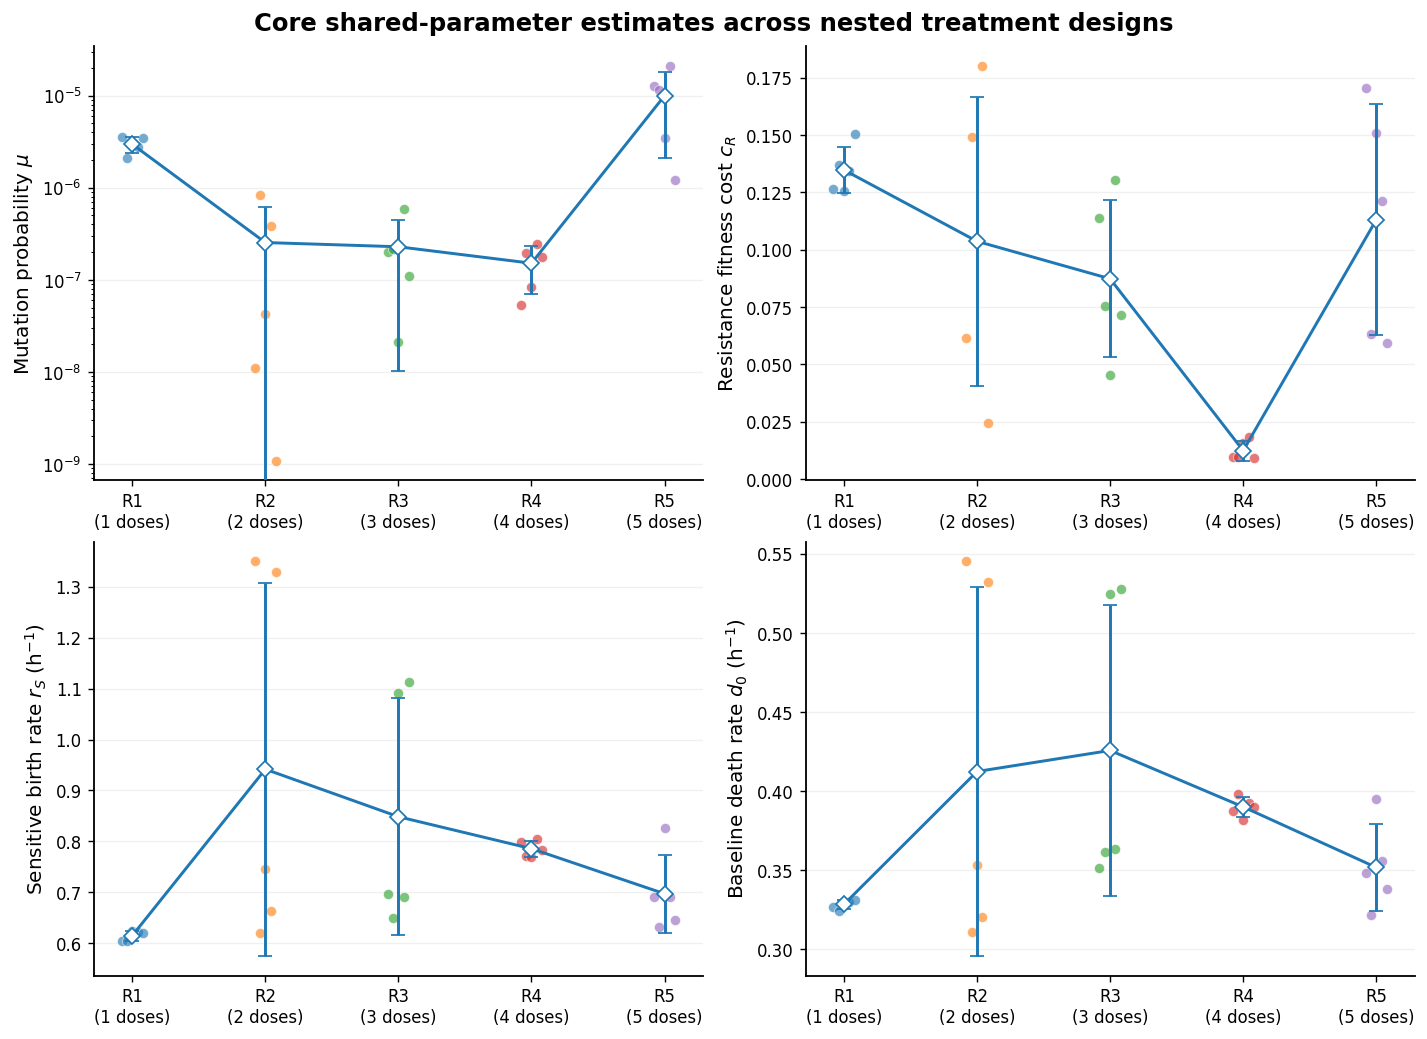

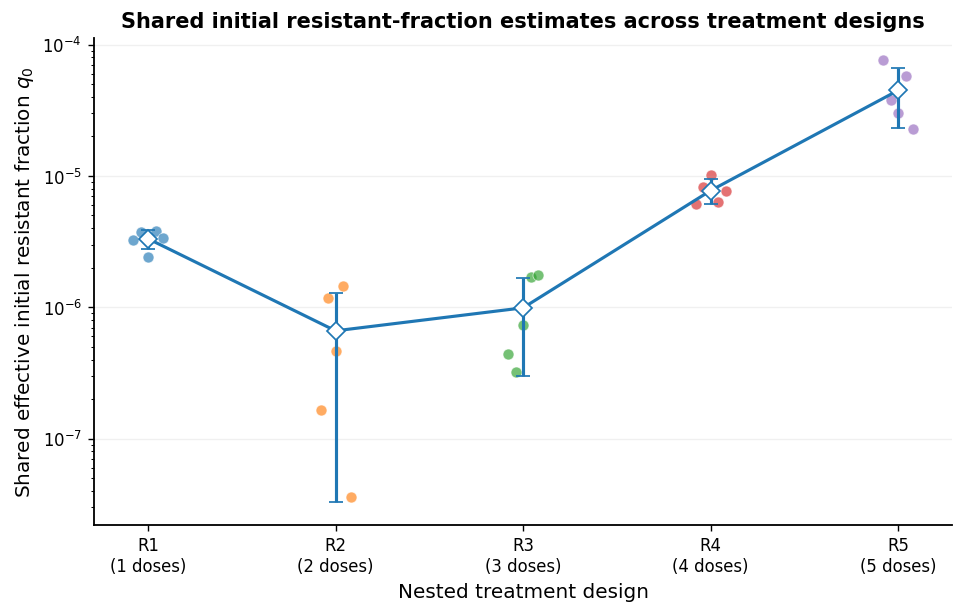

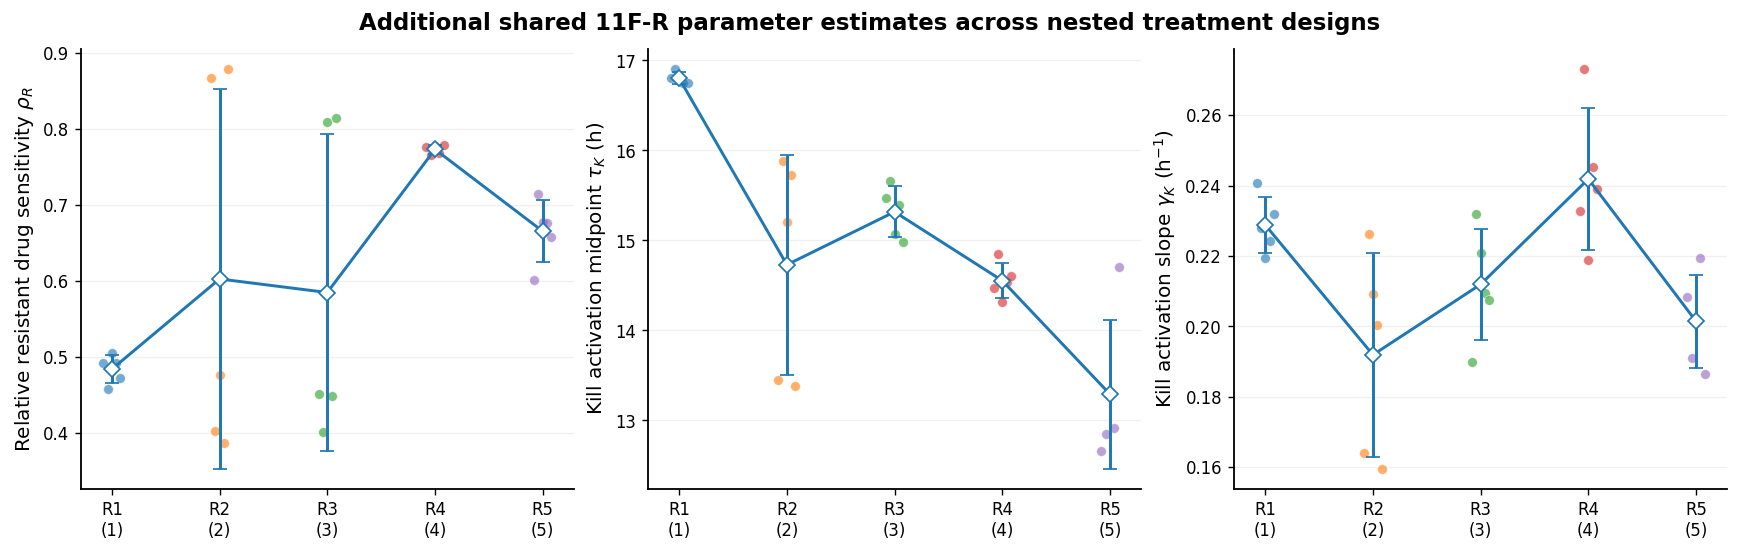

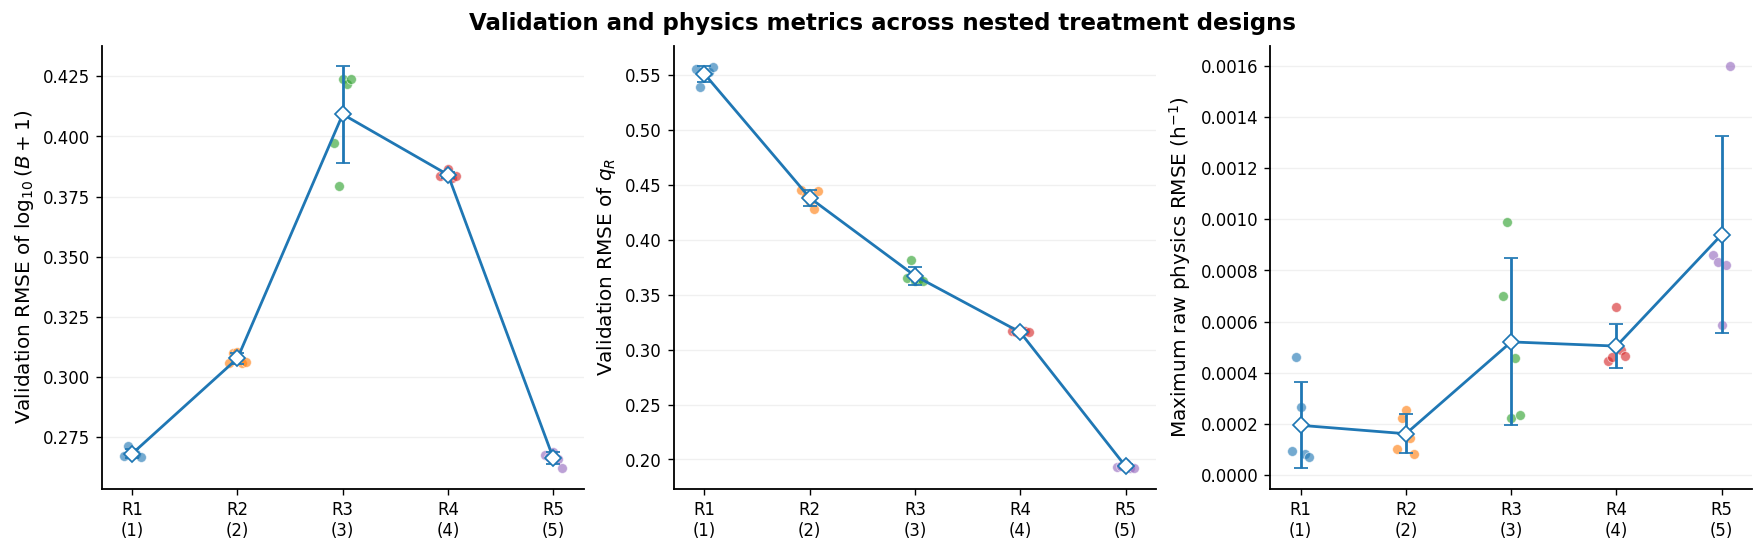

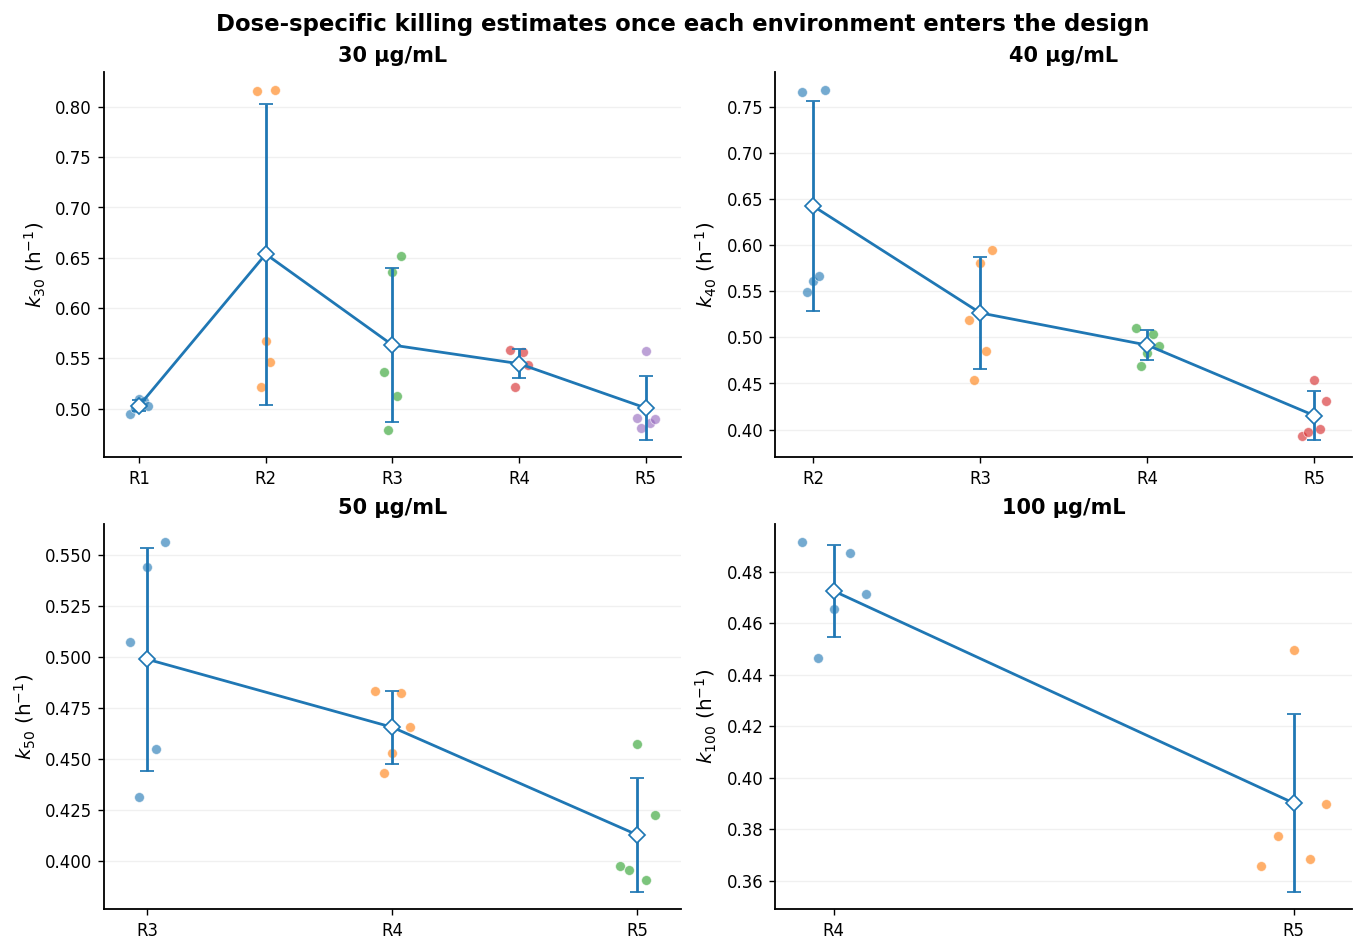


Compact R3.9 metric summary:


,design,n_doses,doses,n_seeds,validation_rmse_logB_mean,validation_rmse_logB_sd,validation_rmse_qR_mean,validation_rmse_qR_sd,max_negative_violation,max_capacity_violation,max_combined_raw_physics_rmse_per_h,max_scaled_physics_rmse,max_early_logR_physics_rmse
0,R1,1,30,5,0.268071,0.001851,0.550776,0.007245,0.0,0.0,0.000461,0.011056,0.136149
1,R2,2,30+40,5,0.307677,0.002340,0.438077,0.007321,0.0,0.0,0.000254,0.006105,0.034114
2,R3,3,30+40+50,5,0.409214,0.020106,0.367104,0.008036,0.0,0.0,0.000988,0.023713,0.131977
3,R4,4,30+40+50+100,5,0.384060,0.001353,0.315728,0.001237,0.0,0.0,0.000656,0.015744,0.175500
4,R5,5,0+30+40+50+100,5,0.266216,0.002609,0.193790,0.001920,0.0,0.0,0.001599,0.038365,0.113906



Full-data P2 reference is already available as INTEGRAL_REFINED_RESULT.
It is intentionally NOT substituted into R5 because R3.9 requires the same base-training procedure for all nested designs/seeds.

R3.9 COMPLETE — EFFICIENT FINAL 11F-R NESTED TREATMENT-DIVERSITY INFERENCE
Raw design × seed results  : results\real_data\tables\final_R39_11FR_nested_treatment_diversity_BASE_ONLY_raw.csv
Design summary             : results\real_data\tables\final_R39_11FR_nested_treatment_diversity_BASE_ONLY_summary.csv
Shared-parameter long table: results\real_data\tables\final_R39_11FR_nested_treatment_diversity_BASE_ONLY_shared_parameter_long.csv
Dose-specific k summary    : results\real_data\tables\final_R39_11FR_nested_treatment_diversity_BASE_ONLY_dose_specific_k_summary.csv
Design-transition table    : results\real_data\tables\final_R39_11FR_nested_treatment_diversity_BASE_ONLY_design_transition_changes.csv

No P1/P2 retraining was repeated inside R3.9.
All original R3.9 metric definitions were

In [57]:
# CELL 10 — EXPERIMENT 3.9
# EFFICIENT FINAL 11F-R NESTED TREATMENT-DIVERSITY INFERENCE
# =============================================================================
#
# PURPOSE
# -------
# This is the real-data analogue of the synthetic M1–M5 treatment-diversity
# experiment.
#
# The fitted design is progressively enlarged:
#
#   R1 : 30
#   R2 : 30 + 40
#   R3 : 30 + 40 + 50
#   R4 : 30 + 40 + 50 + 100
#   R5 : control + 30 + 40 + 50 + 100
#
# IMPORTANT EFFICIENCY DECISION
# -----------------------------
# R3.9 is a parameter/design-sensitivity experiment. P1 and P2 refine ONLY the
# neural state trajectory while keeping the inverse parameters frozen.
#
# Therefore, repeating P1/P2 for all 25 design × seed fits cannot change the
# inverse-parameter estimates that R3.9 is intended to compare.
#
# This efficient FINAL cell therefore:
#
#   - trains the BASE 11F-R inverse problem for every design × seed;
#   - computes the SAME observation, feasibility, and physics metrics used by
#     the original R3.9 experiment;
#   - retains all five FINAL design seeds;
#   - reports all finalized 11F-R shared parameters;
#   - reports each dose-specific kA only when that dose is actually present;
#   - does NOT spend additional hours running P1/P2 for every design.
#
# The already completed full-data P1/P2 result remains available separately as
# INTEGRAL_REFINED_RESULT and is not mixed into the cross-design summary.
#
# SCIENTIFIC FAIRNESS
# -------------------
# Every R1–R5 row is produced by the SAME base 11F-R training/evaluation
# procedure. Thus validation and physics metrics remain directly comparable
# across nested treatment designs.
#
# NOTE ON "SAME METRICS"
# ----------------------
# The metric DEFINITIONS and reported quantities are preserved:
#
#   validation RMSE(logB)
#   validation RMSE(qR)
#   max negativity violation
#   max capacity violation
#   max raw physics RMSE/h
#   max scaled physics RMSE
#   max early logR physics RMSE
#
# Numerical values cannot be forced to equal the old R3.9 numbers because the
# old cell fitted a different architecture/mechanism. These are the correct
# metrics recalculated for the finalized 11F-R model.
# =============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# =============================================================================
# 0. CONFIGURATION
# =============================================================================

R39_TAG = "R39_11FR_nested_treatment_diversity_BASE_ONLY"

EXPECTED_R39_ARCHITECTURE = "shared_dose_conditioned_hard_PINN_11FR"

EXPECTED_R39_PHYSICS_WEIGHT = 25.0

EXPECTED_R39_LOG_PHYSICS_WEIGHT = 2.5


# =============================================================================
# 1. NESTED TREATMENT DESIGNS
# =============================================================================

REAL_DESIGNS = {
    "R1": [
        30.0,
    ],
    "R2": [
        30.0,
        40.0,
    ],
    "R3": [
        30.0,
        40.0,
        50.0,
    ],
    "R4": [
        30.0,
        40.0,
        50.0,
        100.0,
    ],
    "R5": [
        0.0,
        30.0,
        40.0,
        50.0,
        100.0,
    ],
}


# =============================================================================
# 2. FINAL 11F-R PARAMETER GROUPS
# =============================================================================

# Shared across treatment environments.
SHARED_PARAMETER_COLUMNS = [
    "mutation_probability",
    "resistance_fitness_cost",
    "sensitive_birth_rate_per_h",
    "baseline_death_rate_per_h",
    "initial_resistant_fraction_shared",
    "resistant_relative_drug_sensitivity",
    "kill_activation_onset_h",
    "kill_activation_per_h",
]


SHARED_PARAMETER_LABELS = {
    "mutation_probability":
        r"Mutation probability $\mu$",

    "resistance_fitness_cost":
        r"Resistance fitness cost $c_R$",

    "sensitive_birth_rate_per_h":
        r"Sensitive birth rate $r_S$ (h$^{-1}$)",

    "baseline_death_rate_per_h":
        r"Baseline death rate $d_0$ (h$^{-1}$)",

    "initial_resistant_fraction_shared":
        r"Shared initial resistant fraction $q_0$",

    "resistant_relative_drug_sensitivity":
        r"Relative resistant drug sensitivity $\rho_R$",

    "kill_activation_onset_h":
        r"Kill activation midpoint $\tau_K$ (h)",

    "kill_activation_per_h":
        r"Kill activation slope $\gamma_K$ (h$^{-1}$)",
}


LOG_SCALE_PARAMETERS = {
    "mutation_probability",
    "initial_resistant_fraction_shared",
}


# Dose-specific 11F-R kill coefficients.
DOSE_SPECIFIC_PARAMETER = {
    30.0:
        "kill_30_per_h",

    40.0:
        "kill_40_per_h",

    50.0:
        "kill_50_per_h",

    100.0:
        "kill_100_per_h",
}


# =============================================================================
# 3. CONFIGURATION GUARDS
# =============================================================================

required_objects = [
    "FULL_RESULT",
    "BASE_BUNDLE",
    "build_fit_bundle",
    "train_real_model",
    "observation_metrics",
    "feasibility_audit",
    "physics_fidelity_audit",
    "log_physics_fidelity_audit",
    "clear_memory",
    "save_figure",
]

missing_objects = [
    name
    for name in required_objects
    if name not in globals()
]

if missing_objects:

    raise RuntimeError(
        "Cell 10 requires the finalized 11F-R Cells 5–8.\n"
        f"Missing objects: {missing_objects}"
    )


current_architecture = getattr(
    FULL_RESULT.model,
    "architecture_name",
    None,
)


if current_architecture != EXPECTED_R39_ARCHITECTURE:

    raise RuntimeError(
        "Cell 10 configuration mismatch.\n"
        f"Expected architecture: {EXPECTED_R39_ARCHITECTURE}\n"
        f"Current architecture : {current_architecture}\n"
        "Restore/rerun the finalized 11F-R Cells 5–8 first."
    )


if not np.isclose(
    float(
        LOSS_WEIGHTS.physics
    ),
    EXPECTED_R39_PHYSICS_WEIGHT,
):

    raise RuntimeError(
        "Expected "
        f"LOSS_WEIGHTS.physics={EXPECTED_R39_PHYSICS_WEIGHT}, "
        f"found {float(LOSS_WEIGHTS.physics)}."
    )


if not np.isclose(
    float(
        LOSS_WEIGHTS.log_physics
    ),
    EXPECTED_R39_LOG_PHYSICS_WEIGHT,
):

    raise RuntimeError(
        "Expected "
        f"LOSS_WEIGHTS.log_physics={EXPECTED_R39_LOG_PHYSICS_WEIGHT}, "
        f"found {float(LOSS_WEIGHTS.log_physics)}."
    )


if len(
    DESIGN_SEEDS
) == 0:

    raise RuntimeError(
        "DESIGN_SEEDS is empty."
    )


print("=" * 112)
print("R3.9 — EFFICIENT FINAL 11F-R NESTED TREATMENT-DIVERSITY INFERENCE")
print("=" * 112)

print(
    "Architecture             :",
    EXPECTED_R39_ARCHITECTURE,
)

print(
    "Physics weight           :",
    float(
        LOSS_WEIGHTS.physics
    ),
)

print(
    "Log-physics weight       :",
    float(
        LOSS_WEIGHTS.log_physics
    ),
)

print(
    "Design seeds             :",
    list(
        DESIGN_SEEDS
    ),
)

print(
    "Execution mode           :",
    "QUICK (development)"
    if QUICK_MODE
    else "FINAL (publication)",
)

print(
    "Training strategy        : BASE 11F-R only for all designs"
)

print(
    "P1/P2 in cross-design run: NOT repeated "
    "(inverse parameters would remain frozen)"
)

print("=" * 112)


# =============================================================================
# 4. RESUME-SAFE OUTPUT PATHS
# =============================================================================

DESIGN_RESULTS_PATH = (
    TABLE_DIR
    / f"{RUN_LABEL}_{R39_TAG}_raw.csv"
)

DESIGN_SUMMARY_PATH = (
    TABLE_DIR
    / f"{RUN_LABEL}_{R39_TAG}_summary.csv"
)

SHARED_LONG_PATH = (
    TABLE_DIR
    / f"{RUN_LABEL}_{R39_TAG}_shared_parameter_long.csv"
)

DOSE_SPECIFIC_SUMMARY_PATH = (
    TABLE_DIR
    / f"{RUN_LABEL}_{R39_TAG}_dose_specific_k_summary.csv"
)

TRANSITION_PATH = (
    TABLE_DIR
    / f"{RUN_LABEL}_{R39_TAG}_design_transition_changes.csv"
)


# =============================================================================
# 5. LOAD COMPATIBLE CACHE
# =============================================================================

if (
    DESIGN_RESULTS_PATH.exists()
    and not FORCE_RETRAIN
):

    design_results = pd.read_csv(
        DESIGN_RESULTS_PATH
    )

    print(
        "\nFound efficient FINAL 11F-R R3.9 cache:",
        DESIGN_RESULTS_PATH,
    )

else:

    design_results = pd.DataFrame()


if not design_results.empty:

    required_cache_columns = {
        "architecture",
        "physics_weight",
        "log_physics_weight",
        "design",
        "seed",
        "training_strategy",
    }


    if not required_cache_columns.issubset(
        set(
            design_results.columns
        )
    ):

        print(
            "Existing cache lacks the required FINAL 11F-R metadata; "
            "starting a clean R3.9 cache."
        )

        design_results = pd.DataFrame()

    else:

        compatible = (
            (
                design_results[
                    "architecture"
                ]
                == EXPECTED_R39_ARCHITECTURE
            )
            &
            (
                design_results[
                    "training_strategy"
                ]
                == "base_11FR_only"
            )
            &
            np.isclose(
                design_results[
                    "physics_weight"
                ].to_numpy(
                    float
                ),
                EXPECTED_R39_PHYSICS_WEIGHT,
            )
            &
            np.isclose(
                design_results[
                    "log_physics_weight"
                ].to_numpy(
                    float
                ),
                EXPECTED_R39_LOG_PHYSICS_WEIGHT,
            )
        )


        removed_rows = int(
            (
                ~compatible
            ).sum()
        )


        if removed_rows > 0:

            print(
                f"Discarding {removed_rows} incompatible cached row(s)."
            )


        design_results = (
            design_results.loc[
                compatible
            ]
            .copy()
            .reset_index(
                drop=True
            )
        )


# =============================================================================
# 6. TRAIN ONLY MISSING DESIGN × SEED COMBINATIONS
# =============================================================================

for design_id, doses in REAL_DESIGNS.items():

    print("\n" + "=" * 112)

    print(
        f"R3.9 design {design_id}: doses = {doses}"
    )

    print("=" * 112)


    design_bundle = build_fit_bundle(
        doses,
        split_seed=SEED,
    )


    for design_seed in DESIGN_SEEDS:

        design_seed = int(
            design_seed
        )


        already_done = False


        if not design_results.empty:

            mask = (
                (
                    design_results[
                        "design"
                    ]
                    == design_id
                )
                &
                (
                    design_results[
                        "seed"
                    ].to_numpy(
                        int
                    )
                    == design_seed
                )
            )


            already_done = bool(
                mask.any()
            )


        if already_done:

            print(
                f"Skipping cached FINAL R3.9 fit: "
                f"{design_id}, seed={design_seed}"
            )

            continue


        label = (
            f"R39_11FR_{design_id}_seed_{design_seed}"
        )


        # =====================================================================
        # BASE 11F-R INVERSE TRAINING
        # =====================================================================

        result = train_real_model(
            design_bundle,
            seed=design_seed,
            label=label,
            hide_fraction_doses=set(),
            save_checkpoint=False,
        )


        if (
            result.model.architecture_name
            != EXPECTED_R39_ARCHITECTURE
        ):

            raise RuntimeError(
                f"{design_id}, seed={design_seed} trained with wrong architecture."
            )


        # =====================================================================
        # SAME METRICS AS ORIGINAL R3.9
        # =====================================================================

        val = observation_metrics(
            result.model,
            design_bundle,
            split="val",
        )


        feasibility_df = feasibility_audit(
            result.model,
            design_bundle.doses,
        )


        physics_df = physics_fidelity_audit(
            result.model,
            design_bundle.doses,
        )


        log_physics_df = log_physics_fidelity_audit(
            result.model,
            design_bundle.doses,
            start_h=0.0,
            end_h=4.0,
        )


        params = (
            result.model
            .inferred_parameters()
        )


        row = {
            "architecture":
                result.model.architecture_name,

            "training_strategy":
                "base_11FR_only",

            "physics_variant":
                "11F-R_reduced_time_structured_killing",

            "physics_weight":
                float(
                    LOSS_WEIGHTS.physics
                ),

            "log_physics_weight":
                float(
                    LOSS_WEIGHTS.log_physics
                ),

            "design":
                design_id,

            "n_doses":
                int(
                    len(
                        doses
                    )
                ),

            "doses":
                "+".join(
                    str(
                        int(
                            d
                        )
                    )
                    for d in doses
                ),

            "seed":
                design_seed,

            "best_validation_score":
                float(
                    result.best_validation_score
                ),

            # -------------------------------------------------------------
            # SAME observation metrics as old R3.9
            # -------------------------------------------------------------
            "validation_rmse_logB":
                float(
                    val[
                        "rmse_logB"
                    ]
                ),

            "validation_rmse_qR":
                float(
                    val[
                        "rmse_qR"
                    ]
                ),

            # -------------------------------------------------------------
            # SAME hard-feasibility metrics as old R3.9
            # -------------------------------------------------------------
            "max_negative_violation":
                float(
                    feasibility_df[
                        "negative_violation"
                    ].max()
                ),

            "max_capacity_violation":
                float(
                    feasibility_df[
                        "capacity_violation"
                    ].max()
                ),

            # -------------------------------------------------------------
            # SAME physics-fidelity metrics as old R3.9
            # -------------------------------------------------------------
            "max_combined_raw_physics_rmse_per_h":
                float(
                    physics_df[
                        "combined_raw_rmse_per_h"
                    ].max()
                ),

            "max_scaled_physics_rmse":
                float(
                    physics_df[
                        "combined_scaled_rmse"
                    ].max()
                ),

            "max_early_logR_physics_rmse":
                float(
                    log_physics_df[
                        "rmse_logRr"
                    ].max()
                ),

            **params,
        }


        # =====================================================================
        # DO NOT INTERPRET kA FOR ABSENT DOSES
        # =====================================================================

        present_doses = {
            float(
                d
            )
            for d in doses
        }


        for dose, parameter_name in DOSE_SPECIFIC_PARAMETER.items():

            if dose not in present_doses:

                row[
                    parameter_name
                ] = np.nan


        design_results = pd.concat(
            [
                design_results,
                pd.DataFrame(
                    [
                        row
                    ]
                ),
            ],
            ignore_index=True,
        )


        design_results = (
            design_results
            .sort_values(
                [
                    "n_doses",
                    "design",
                    "seed",
                ]
            )
            .reset_index(
                drop=True
            )
        )


        # Resume-safe save after EVERY completed training run.
        design_results.to_csv(
            DESIGN_RESULTS_PATH,
            index=False,
        )


        print(
            "\nCompleted efficient FINAL R3.9 run:"
        )

        print(
            f"  design                   = {design_id}"
        )

        print(
            f"  seed                     = {design_seed}"
        )

        print(
            f"  validation RMSE(logB)    = "
            f"{val['rmse_logB']:.6f}"
        )

        print(
            f"  validation RMSE(qR)      = "
            f"{val['rmse_qR']:.6f}"
        )

        print(
            f"  max raw physics RMSE/h   = "
            f"{physics_df['combined_raw_rmse_per_h'].max():.6e}"
        )


        del result

        clear_memory()


    del design_bundle

    clear_memory()


# =============================================================================
# 7. CHECK COMPLETENESS
# =============================================================================

expected_pairs = {
    (
        design_id,
        int(
            seed
        ),
    )
    for design_id in REAL_DESIGNS
    for seed in DESIGN_SEEDS
}


observed_pairs = {
    (
        str(
            row.design
        ),
        int(
            row.seed
        ),
    )
    for row in design_results.itertuples()
}


missing_pairs = sorted(
    expected_pairs
    - observed_pairs
)


if missing_pairs:

    raise RuntimeError(
        "R3.9 is incomplete. Missing design/seed runs: "
        + str(
            missing_pairs
        )
    )


# =============================================================================
# 8. DESIGN-WISE SUMMARY — SAME CORE METRICS + FINAL 11F-R PARAMETERS
# =============================================================================

summary_rows = []


for design_id in REAL_DESIGNS:

    subset = design_results[
        design_results[
            "design"
        ] == design_id
    ].copy()


    n_seeds = len(
        subset
    )


    row = {
        "design":
            design_id,

        "n_doses":
            int(
                subset[
                    "n_doses"
                ].iloc[
                    0
                ]
            ),

        "doses":
            str(
                subset[
                    "doses"
                ].iloc[
                    0
                ]
            ),

        "n_seeds":
            int(
                n_seeds
            ),

        # ---------------------------------------------------------------------
        # SAME metric definitions as the original R3.9 summary.
        # ---------------------------------------------------------------------
        "validation_rmse_logB_mean":
            float(
                subset[
                    "validation_rmse_logB"
                ].mean()
            ),

        "validation_rmse_logB_sd":
            (
                float(
                    subset[
                        "validation_rmse_logB"
                    ].std(
                        ddof=1
                    )
                )
                if n_seeds > 1
                else np.nan
            ),

        "validation_rmse_qR_mean":
            float(
                subset[
                    "validation_rmse_qR"
                ].mean()
            ),

        "validation_rmse_qR_sd":
            (
                float(
                    subset[
                        "validation_rmse_qR"
                    ].std(
                        ddof=1
                    )
                )
                if n_seeds > 1
                else np.nan
            ),

        "max_negative_violation":
            float(
                subset[
                    "max_negative_violation"
                ].max()
            ),

        "max_capacity_violation":
            float(
                subset[
                    "max_capacity_violation"
                ].max()
            ),

        "max_combined_raw_physics_rmse_per_h":
            float(
                subset[
                    "max_combined_raw_physics_rmse_per_h"
                ].max()
            ),

        "max_scaled_physics_rmse":
            float(
                subset[
                    "max_scaled_physics_rmse"
                ].max()
            ),

        "max_early_logR_physics_rmse":
            float(
                subset[
                    "max_early_logR_physics_rmse"
                ].max()
            ),
    }


    # -------------------------------------------------------------------------
    # Shared 11F-R parameter summaries.
    # -------------------------------------------------------------------------

    for parameter in SHARED_PARAMETER_COLUMNS:

        values = subset[
            parameter
        ].to_numpy(
            float
        )


        row[
            f"{parameter}_mean"
        ] = float(
            np.mean(
                values
            )
        )


        row[
            f"{parameter}_sd"
        ] = (
            float(
                np.std(
                    values,
                    ddof=1,
                )
            )
            if len(
                values
            ) > 1
            else np.nan
        )


        row[
            f"{parameter}_median"
        ] = float(
            np.median(
                values
            )
        )


        row[
            f"{parameter}_min"
        ] = float(
            np.min(
                values
            )
        )


        row[
            f"{parameter}_max"
        ] = float(
            np.max(
                values
            )
        )


        if (
            parameter in LOG_SCALE_PARAMETERS
            and np.all(
                values > 0.0
            )
        ):

            log_values = np.log10(
                values
            )


            row[
                f"{parameter}_log10_sd"
            ] = (
                float(
                    np.std(
                        log_values,
                        ddof=1,
                    )
                )
                if len(
                    log_values
                ) > 1
                else np.nan
            )


    # -------------------------------------------------------------------------
    # Dose-specific kA — only for doses included in this design.
    # -------------------------------------------------------------------------

    present_doses = {
        float(
            d
        )
        for d in REAL_DESIGNS[
            design_id
        ]
    }


    for dose, parameter_name in DOSE_SPECIFIC_PARAMETER.items():

        if dose in present_doses:

            values = subset[
                parameter_name
            ].dropna().to_numpy(
                float
            )


            row[
                f"{parameter_name}_mean"
            ] = float(
                np.mean(
                    values
                )
            )


            row[
                f"{parameter_name}_sd"
            ] = (
                float(
                    np.std(
                        values,
                        ddof=1,
                    )
                )
                if len(
                    values
                ) > 1
                else np.nan
            )

        else:

            row[
                f"{parameter_name}_mean"
            ] = np.nan


            row[
                f"{parameter_name}_sd"
            ] = np.nan


    summary_rows.append(
        row
    )


design_summary = pd.DataFrame(
    summary_rows
)


design_summary.to_csv(
    DESIGN_SUMMARY_PATH,
    index=False,
)


print(
    "\nNested-treatment FINAL 11F-R summary:"
)

display(
    design_summary
)


# =============================================================================
# 9. LONG-FORM SHARED-PARAMETER TABLE
# =============================================================================

shared_long_rows = []


for result_row in design_results.itertuples():

    for parameter in SHARED_PARAMETER_COLUMNS:

        shared_long_rows.append(
            {
                "design":
                    str(
                        result_row.design
                    ),

                "n_doses":
                    int(
                        result_row.n_doses
                    ),

                "doses":
                    str(
                        result_row.doses
                    ),

                "seed":
                    int(
                        result_row.seed
                    ),

                "parameter":
                    parameter,

                "parameter_label":
                    SHARED_PARAMETER_LABELS[
                        parameter
                    ],

                "estimate":
                    float(
                        getattr(
                            result_row,
                            parameter,
                        )
                    ),
            }
        )


shared_parameter_long = pd.DataFrame(
    shared_long_rows
)


shared_parameter_long.to_csv(
    SHARED_LONG_PATH,
    index=False,
)


# =============================================================================
# 10. DOSE-SPECIFIC kA SUMMARY
# =============================================================================

dose_specific_rows = []


for design_id, doses in REAL_DESIGNS.items():

    subset = design_results[
        design_results[
            "design"
        ] == design_id
    ].copy()


    for dose, parameter_name in DOSE_SPECIFIC_PARAMETER.items():

        if float(
            dose
        ) not in {
            float(
                d
            )
            for d in doses
        }:

            continue


        values = subset[
            parameter_name
        ].dropna().to_numpy(
            float
        )


        dose_specific_rows.append(
            {
                "design":
                    design_id,

                "n_doses":
                    int(
                        len(
                            doses
                        )
                    ),

                "dose_ug_ml":
                    float(
                        dose
                    ),

                "parameter":
                    parameter_name,

                "n_seeds":
                    int(
                        len(
                            values
                        )
                    ),

                "mean":
                    float(
                        np.mean(
                            values
                        )
                    ),

                "sd":
                    (
                        float(
                            np.std(
                                values,
                                ddof=1,
                            )
                        )
                        if len(
                            values
                        ) > 1
                        else np.nan
                    ),

                "min":
                    float(
                        np.min(
                            values
                        )
                    ),

                "max":
                    float(
                        np.max(
                            values
                        )
                    ),
            }
        )


dose_specific_summary = pd.DataFrame(
    dose_specific_rows
)


dose_specific_summary.to_csv(
    DOSE_SPECIFIC_SUMMARY_PATH,
    index=False,
)


print(
    "\nDose-specific kill coefficients "
    "(only where corresponding dose is present):"
)

display(
    dose_specific_summary
)


# =============================================================================
# 11. DESIGN-TO-DESIGN SHARED-PARAMETER CHANGE TABLE
# =============================================================================

design_order = list(
    REAL_DESIGNS.keys()
)


transition_rows = []


for parameter in SHARED_PARAMETER_COLUMNS:

    for index in range(
        1,
        len(
            design_order
        ),
    ):

        previous_design = design_order[
            index - 1
        ]

        current_design = design_order[
            index
        ]


        previous_mean = float(
            design_summary.loc[
                design_summary[
                    "design"
                ] == previous_design,
                f"{parameter}_mean",
            ].iloc[
                0
            ]
        )


        current_mean = float(
            design_summary.loc[
                design_summary[
                    "design"
                ] == current_design,
                f"{parameter}_mean",
            ].iloc[
                0
            ]
        )


        absolute_change = abs(
            current_mean
            - previous_mean
        )


        relative_change = (
            absolute_change
            / max(
                abs(
                    previous_mean
                ),
                1e-15,
            )
        )


        transition_rows.append(
            {
                "parameter":
                    parameter,

                "from_design":
                    previous_design,

                "to_design":
                    current_design,

                "previous_mean":
                    previous_mean,

                "current_mean":
                    current_mean,

                "absolute_change":
                    float(
                        absolute_change
                    ),

                "relative_change":
                    float(
                        relative_change
                    ),

                "absolute_log10_fold_change":
                    (
                        float(
                            abs(
                                np.log10(
                                    current_mean
                                    / previous_mean
                                )
                            )
                        )
                        if (
                            current_mean > 0.0
                            and previous_mean > 0.0
                        )
                        else np.nan
                    ),
            }
        )


design_transition_changes = pd.DataFrame(
    transition_rows
)


design_transition_changes.to_csv(
    TRANSITION_PATH,
    index=False,
)


# =============================================================================
# 12. FIGURE A — ORIGINAL CORE PARAMETER SET, UPDATED TO 11F-R
# =============================================================================
#
# This preserves the same four core quantities shown in the old R3.9 figure:
# mu, cR, rS, death rate.
#
# Only the title is made scientifically neutral.
# =============================================================================

fig, axes = plt.subplots(
    2,
    2,
    figsize=(
        11.3,
        8.2,
    ),
    constrained_layout=True,
)


axes = axes.ravel()


x = np.arange(
    len(
        design_order
    )
)


core_plot_specs = [
    (
        "mutation_probability",
        r"Mutation probability $\mu$",
        True,
    ),
    (
        "resistance_fitness_cost",
        r"Resistance fitness cost $c_R$",
        False,
    ),
    (
        "sensitive_birth_rate_per_h",
        r"Sensitive birth rate $r_S$ (h$^{-1}$)",
        False,
    ),
    (
        "baseline_death_rate_per_h",
        r"Baseline death rate $d_0$ (h$^{-1}$)",
        False,
    ),
]


for ax, (
    column,
    ylabel,
    logscale,
) in zip(
    axes,
    core_plot_specs,
):

    means = []

    sds = []


    for design_index, design in enumerate(
        design_order
    ):

        vals = design_results.loc[
            design_results[
                "design"
            ] == design,
            column,
        ].to_numpy(
            float
        )


        means.append(
            float(
                np.mean(
                    vals
                )
            )
        )


        sds.append(
            float(
                np.std(
                    vals,
                    ddof=1,
                )
            )
            if len(
                vals
            ) > 1
            else 0.0
        )


        jitter = (
            np.linspace(
                -0.08,
                0.08,
                len(
                    vals
                ),
            )
            if len(
                vals
            ) > 1
            else np.array(
                [
                    0.0
                ]
            )
        )


        ax.scatter(
            np.full(
                len(
                    vals
                ),
                design_index,
            )
            + jitter,
            vals,
            s=34,
            alpha=0.62,
            edgecolor="white",
            linewidth=0.5,
            zorder=3,
        )


    ax.errorbar(
        x,
        means,
        yerr=sds,
        fmt="D-",
        markerfacecolor="white",
        markersize=6.5,
        capsize=4,
        linewidth=1.7,
        zorder=5,
    )


    ax.set_xticks(
        x,
        [
            f"{design}\n"
            f"({len(REAL_DESIGNS[design])} doses)"
            for design in design_order
        ],
    )


    ax.set_ylabel(
        ylabel
    )


    if logscale:

        ax.set_yscale(
            "log"
        )


    ax.grid(
        axis="y",
        alpha=0.18,
    )


    ax.spines[
        [
            "top",
            "right",
        ]
    ].set_visible(
        False
    )


fig.suptitle(
    "Core shared-parameter estimates across nested treatment designs",
    fontsize=14,
    fontweight="bold",
)


save_figure(
    fig,
    f"{RUN_LABEL}_{R39_TAG}_core_shared_parameters",
)


plt.show()


# =============================================================================
# 13. FIGURE B — q0, PRESERVING THE OLD SEPARATE q0 DISPLAY
# =============================================================================

fig, ax = plt.subplots(
    figsize=(
        7.6,
        4.8,
    ),
    constrained_layout=True,
)


q0_means = []

q0_sds = []


for design_index, design in enumerate(
    design_order
):

    vals = design_results.loc[
        design_results[
            "design"
        ] == design,
        "initial_resistant_fraction_shared",
    ].to_numpy(
        float
    )


    q0_means.append(
        float(
            np.mean(
                vals
            )
        )
    )


    q0_sds.append(
        float(
            np.std(
                vals,
                ddof=1,
            )
        )
        if len(
            vals
        ) > 1
        else 0.0
    )


    jitter = (
        np.linspace(
            -0.08,
            0.08,
            len(
                vals
            ),
        )
        if len(
            vals
        ) > 1
        else np.array(
            [
                0.0
            ]
        )
    )


    ax.scatter(
        np.full(
            len(
                vals
            ),
            design_index,
        )
        + jitter,
        vals,
        s=40,
        alpha=0.65,
        edgecolor="white",
        linewidth=0.5,
    )


ax.errorbar(
    x,
    q0_means,
    yerr=q0_sds,
    fmt="D-",
    markerfacecolor="white",
    markersize=7,
    capsize=4,
    linewidth=1.8,
)


ax.set_yscale(
    "log"
)


ax.set_xticks(
    x,
    [
        f"{design}\n"
        f"({len(REAL_DESIGNS[design])} doses)"
        for design in design_order
    ],
)


ax.set_ylabel(
    r"Shared effective initial resistant fraction $q_0$"
)


ax.set_xlabel(
    "Nested treatment design"
)


ax.set_title(
    "Shared initial resistant-fraction estimates across treatment designs",
    fontweight="bold",
)


ax.grid(
    axis="y",
    alpha=0.18,
)


ax.spines[
    [
        "top",
        "right",
    ]
].set_visible(
    False
)


save_figure(
    fig,
    f"{RUN_LABEL}_{R39_TAG}_q0_across_designs",
)


plt.show()


# =============================================================================
# 14. FIGURE C — ADDITIONAL SHARED 11F-R PARAMETERS
# =============================================================================

fig, axes = plt.subplots(
    1,
    3,
    figsize=(
        13.8,
        4.3,
    ),
    constrained_layout=True,
)


additional_shared = [
    "resistant_relative_drug_sensitivity",
    "kill_activation_onset_h",
    "kill_activation_per_h",
]


for ax, parameter in zip(
    axes,
    additional_shared,
):

    means = []

    sds = []


    for design_index, design in enumerate(
        design_order
    ):

        vals = design_results.loc[
            design_results[
                "design"
            ] == design,
            parameter,
        ].to_numpy(
            float
        )


        means.append(
            float(
                np.mean(
                    vals
                )
            )
        )


        sds.append(
            float(
                np.std(
                    vals,
                    ddof=1,
                )
            )
            if len(
                vals
            ) > 1
            else 0.0
        )


        jitter = (
            np.linspace(
                -0.08,
                0.08,
                len(
                    vals
                ),
            )
            if len(
                vals
            ) > 1
            else np.array(
                [
                    0.0
                ]
            )
        )


        ax.scatter(
            np.full(
                len(
                    vals
                ),
                design_index,
            )
            + jitter,
            vals,
            s=32,
            alpha=0.62,
            edgecolor="white",
            linewidth=0.5,
            zorder=3,
        )


    ax.errorbar(
        x,
        means,
        yerr=sds,
        fmt="D-",
        markerfacecolor="white",
        markersize=6.3,
        capsize=4,
        linewidth=1.7,
        zorder=5,
    )


    ax.set_xticks(
        x,
        [
            f"{design}\n({len(REAL_DESIGNS[design])})"
            for design in design_order
        ],
    )


    ax.set_ylabel(
        SHARED_PARAMETER_LABELS[
            parameter
        ]
    )


    ax.grid(
        axis="y",
        alpha=0.18,
    )


    ax.spines[
        [
            "top",
            "right",
        ]
    ].set_visible(
        False
    )


fig.suptitle(
    "Additional shared 11F-R parameter estimates across nested treatment designs",
    fontsize=13.2,
    fontweight="bold",
)


save_figure(
    fig,
    f"{RUN_LABEL}_{R39_TAG}_additional_shared_parameters",
)


plt.show()


# =============================================================================
# 15. FIGURE D — SAME CORE VALIDATION / PHYSICS METRICS
# =============================================================================

fig, axes = plt.subplots(
    1,
    3,
    figsize=(
        14.0,
        4.3,
    ),
    constrained_layout=True,
)


metric_specs = [
    (
        "validation_rmse_logB",
        r"Validation RMSE of $\log_{10}(B+1)$",
    ),
    (
        "validation_rmse_qR",
        r"Validation RMSE of $q_R$",
    ),
    (
        "max_combined_raw_physics_rmse_per_h",
        r"Maximum raw physics RMSE (h$^{-1}$)",
    ),
]


for ax, (
    metric,
    ylabel,
) in zip(
    axes,
    metric_specs,
):

    means = []

    sds = []


    for design_index, design in enumerate(
        design_order
    ):

        vals = design_results.loc[
            design_results[
                "design"
            ] == design,
            metric,
        ].to_numpy(
            float
        )


        means.append(
            float(
                np.mean(
                    vals
                )
            )
        )


        sds.append(
            float(
                np.std(
                    vals,
                    ddof=1,
                )
            )
            if len(
                vals
            ) > 1
            else 0.0
        )


        jitter = (
            np.linspace(
                -0.08,
                0.08,
                len(
                    vals
                ),
            )
            if len(
                vals
            ) > 1
            else np.array(
                [
                    0.0
                ]
            )
        )


        ax.scatter(
            np.full(
                len(
                    vals
                ),
                design_index,
            )
            + jitter,
            vals,
            s=32,
            alpha=0.62,
            edgecolor="white",
            linewidth=0.5,
            zorder=3,
        )


    ax.errorbar(
        x,
        means,
        yerr=sds,
        fmt="D-",
        markerfacecolor="white",
        markersize=6.2,
        capsize=4,
        linewidth=1.6,
        zorder=5,
    )


    ax.set_xticks(
        x,
        [
            f"{design}\n({len(REAL_DESIGNS[design])})"
            for design in design_order
        ],
    )


    ax.set_ylabel(
        ylabel
    )


    ax.grid(
        axis="y",
        alpha=0.18,
    )


    ax.spines[
        [
            "top",
            "right",
        ]
    ].set_visible(
        False
    )


fig.suptitle(
    "Validation and physics metrics across nested treatment designs",
    fontsize=13.2,
    fontweight="bold",
)


save_figure(
    fig,
    f"{RUN_LABEL}_{R39_TAG}_validation_physics_metrics",
)


plt.show()


# =============================================================================
# 16. FIGURE E — DOSE-SPECIFIC kA ONLY WHEN INFORMED
# =============================================================================

fig, axes = plt.subplots(
    2,
    2,
    figsize=(
        10.8,
        7.5,
    ),
    constrained_layout=True,
)


axes = axes.ravel()


for ax, dose in zip(
    axes,
    [
        30.0,
        40.0,
        50.0,
        100.0,
    ],
):

    parameter_name = DOSE_SPECIFIC_PARAMETER[
        dose
    ]


    valid_designs = [
        design
        for design, doses in REAL_DESIGNS.items()
        if float(
            dose
        ) in {
            float(
                d
            )
            for d in doses
        }
    ]


    local_x = np.arange(
        len(
            valid_designs
        )
    )


    means = []

    sds = []


    for design_index, design in enumerate(
        valid_designs
    ):

        vals = design_results.loc[
            design_results[
                "design"
            ] == design,
            parameter_name,
        ].dropna().to_numpy(
            float
        )


        means.append(
            float(
                np.mean(
                    vals
                )
            )
        )


        sds.append(
            float(
                np.std(
                    vals,
                    ddof=1,
                )
            )
            if len(
                vals
            ) > 1
            else 0.0
        )


        jitter = (
            np.linspace(
                -0.07,
                0.07,
                len(
                    vals
                ),
            )
            if len(
                vals
            ) > 1
            else np.array(
                [
                    0.0
                ]
            )
        )


        ax.scatter(
            np.full(
                len(
                    vals
                ),
                design_index,
            )
            + jitter,
            vals,
            s=32,
            alpha=0.62,
            edgecolor="white",
            linewidth=0.5,
            zorder=3,
        )


    ax.errorbar(
        local_x,
        means,
        yerr=sds,
        fmt="D-",
        markerfacecolor="white",
        markersize=6.2,
        capsize=4,
        linewidth=1.6,
        zorder=5,
    )


    ax.set_xticks(
        local_x,
        valid_designs,
    )


    ax.set_ylabel(
        rf"$k_{{{int(dose)}}}$ (h$^{{-1}}$)"
    )


    ax.set_title(
        f"{dose:g} µg/mL",
        fontweight="bold",
    )


    ax.grid(
        axis="y",
        alpha=0.18,
    )


    ax.spines[
        [
            "top",
            "right",
        ]
    ].set_visible(
        False
    )


fig.suptitle(
    "Dose-specific killing estimates once each environment enters the design",
    fontsize=13.1,
    fontweight="bold",
)


save_figure(
    fig,
    f"{RUN_LABEL}_{R39_TAG}_dose_specific_k",
)


plt.show()


# =============================================================================
# 17. COMPACT MANUSCRIPT-READY SUMMARY
# =============================================================================

compact_columns = [
    "design",
    "n_doses",
    "doses",
    "n_seeds",
    "validation_rmse_logB_mean",
    "validation_rmse_logB_sd",
    "validation_rmse_qR_mean",
    "validation_rmse_qR_sd",
    "max_negative_violation",
    "max_capacity_violation",
    "max_combined_raw_physics_rmse_per_h",
    "max_scaled_physics_rmse",
    "max_early_logR_physics_rmse",
]


r39_compact_summary = design_summary[
    compact_columns
].copy()


print(
    "\nCompact R3.9 metric summary:"
)

display(
    r39_compact_summary
)


# =============================================================================
# 18. OPTIONAL REFERENCE TO THE ALREADY COMPLETED FULL-DATA P2 RESULT
# =============================================================================
#
# This section does NOT retrain anything and does NOT mix P2 values into the
# R1–R5 cross-design statistics. It simply records that the full-data 11F-R
# model has already undergone the separate P1/P2 consistency refinement.
# =============================================================================

if (
    "INTEGRAL_REFINED_RESULT"
    in globals()
):

    print(
        "\nFull-data P2 reference is already available as "
        "INTEGRAL_REFINED_RESULT."
    )

    print(
        "It is intentionally NOT substituted into R5 because R3.9 requires "
        "the same base-training procedure for all nested designs/seeds."
    )


# =============================================================================
# 19. COMPLETION MESSAGE
# =============================================================================

print("\n" + "=" * 112)

print(
    "R3.9 COMPLETE — EFFICIENT FINAL 11F-R NESTED TREATMENT-DIVERSITY INFERENCE"
)

print("=" * 112)

print(
    "Raw design × seed results  :",
    DESIGN_RESULTS_PATH,
)

print(
    "Design summary             :",
    DESIGN_SUMMARY_PATH,
)

print(
    "Shared-parameter long table:",
    SHARED_LONG_PATH,
)

print(
    "Dose-specific k summary    :",
    DOSE_SPECIFIC_SUMMARY_PATH,
)

print(
    "Design-transition table    :",
    TRANSITION_PATH,
)

print(
    "\nNo P1/P2 retraining was repeated inside R3.9."
)

print(
    "All original R3.9 metric definitions were retained and recalculated "
    "for the finalized 11F-R model."
)

print("=" * 112)

---
## Primary Experiment 3.10 — independent future-endpoint validation

This final primary experiment uses the external, unpaired treated 86-h endpoint distribution. No 86-h treated endpoint value is used to fit or tune the forecast.


CELL 12 / R3.10 — HELD-OUT 86-h UNPAIRED ENDPOINT-DISTRIBUTION VALIDATION
Run label                      : final
Architecture                   : shared_dose_conditioned_hard_PINN_11FR
Execution mode                 : FINAL
Forecast interval              : 48 -> 86 h
Comparison level               : dose-wise distribution (UNPAIRED)
Forecast initial state         : exact observed B48 + exact linked qR48
Forecast dynamics              : exact FINAL 11F-R ODE
Mechanistic parameter source   : INTEGRAL_REFINED_RESULT (P2; inverse parameters frozen)
R3.9 parameters used            : NO
Treated 86-h endpoint in fit   : NO
Output tag                     : final_R310_11FR_86h_unpaired_distribution_forecast

Resolved qR86 endpoint source: data\real\Ramsayer_qR_86h_ENDPOINT_unpaired.csv
Treated qR86 row-count audit  : PASSED {30.0: 6, 40.0: 7, 50.0: 7, 100.0: 6}

Endpoint-data audit:
qR48 source : q48
qR86 source : data\real\Ramsayer_qR_86h_ENDPOINT_unpaired.csv


,dose_ug_ml,n_exact_qR48_rescued,n_unpaired_qR86_endpoint,same_count
0,30.0,6,6,True
1,40.0,7,7,True
2,50.0,7,7,True
3,100.0,6,6,True



Final frozen 11F-R parameters used for the 48 -> 86 h forecast:


,mutation_probability,resistance_fitness_cost,sensitive_birth_rate_per_h,baseline_death_rate_per_h,initial_resistant_fraction_shared,kill_30_per_h,kill_40_per_h,kill_50_per_h,kill_100_per_h,resistant_relative_drug_sensitivity,kill_activation_onset_h,kill_activation_per_h,K_REAL_cells,parameter_source,max_P2_vs_base_parameter_difference
0,0.000031,0.105998,0.646118,0.350002,0.00006,0.455861,0.393706,0.363276,0.339857,0.667814,13.665092,0.224483,1.118000e+10,INTEGRAL_REFINED_RESULT (P2; inverse parameter...,0.0


Parameter-freeze audit         : PASSED | max difference = 0.000e+00

Mechanistic 48 -> 86 h forecasts completed: 26

Dose-wise UNPAIRED distribution metrics:


,dose_ug_ml,variable,model,n_predicted,n_observed,predicted_mean,predicted_sd,observed_mean,observed_sd,abs_error_in_mean,wasserstein_distance,quantile_rmse
0,30.0,log10_B86,11FR_mechanistic_48_to_86_forecast,6,6,2.313234,1.383267e+00,8.583574,2.271586,6.270340,6.270340,6.569366
1,30.0,log10_B86,48h_persistence_baseline,6,6,4.521690,7.848763e-01,8.583574,2.271586,4.061884,4.061884,4.619211
2,30.0,qR86,11FR_mechanistic_48_to_86_forecast,6,6,0.918333,1.996789e-01,0.915320,0.068241,0.003013,0.116454,0.112443
3,30.0,qR86,48h_persistence_baseline,6,6,0.544982,4.773465e-01,0.915320,0.068241,0.370338,0.375240,0.504130
4,40.0,log10_B86,11FR_mechanistic_48_to_86_forecast,7,7,4.514338,3.484694e-01,9.540909,0.077512,5.026571,5.026571,5.037741
5,40.0,log10_B86,48h_persistence_baseline,7,7,5.524082,3.681518e-01,9.540909,0.077512,4.016826,4.016826,4.034244
6,40.0,qR86,11FR_mechanistic_48_to_86_forecast,7,7,0.999998,2.323833e-06,0.842095,0.093900,0.157904,0.157904,0.171691
7,40.0,qR86,48h_persistence_baseline,7,7,0.908514,1.336577e-01,0.842095,0.093900,0.066419,0.088641,0.103939
8,50.0,log10_B86,11FR_mechanistic_48_to_86_forecast,7,7,5.005874,8.975626e-01,9.437493,0.081939,4.431618,4.431618,4.521953
9,50.0,log10_B86,48h_persistence_baseline,7,7,5.770645,8.630765e-01,9.437493,0.081939,3.666848,3.666848,3.758259



Overall distribution-level comparison:


,variable,mean_Wasserstein_11FR,mean_Wasserstein_persistence,delta_Wasserstein_11FR_minus_persistence,mean_quantile_RMSE_11FR,mean_quantile_RMSE_persistence
0,log10_B86,5.237627,3.999088,1.238539,5.332255,4.161286
1,qR86,0.113094,0.146389,-0.033295,0.133073,0.187040



Interpretation rule: negative delta_Wasserstein_11FR_minus_persistence means the mechanistic 48->86 h forecast is closer to the independent endpoint distribution than simply carrying the observed 48-h state forward.

86-h endpoint summary (UNPAIRED):


,dose_ug_ml,n_48h_forecast_states,n_86h_unpaired_observations,forecast_mean_log10_B86,forecast_sd_log10_B86,observed_mean_log10_B86,observed_sd_log10_B86,forecast_mean_qR86,forecast_sd_qR86,observed_mean_qR86,observed_sd_qR86
0,30.0,6,6,2.313234,1.383267,8.583574,2.271586,0.918333,1.996789e-01,0.915320,0.068241
1,40.0,7,7,4.514338,0.348469,9.540909,0.077512,0.999998,2.323833e-06,0.842095,0.093900
2,50.0,7,7,5.005874,0.897563,9.437493,0.081939,1.000000,5.255003e-07,0.906215,0.098130
3,100.0,6,6,4.354923,0.533781,9.576903,0.268068,0.999999,1.485512e-06,0.915767,0.141577


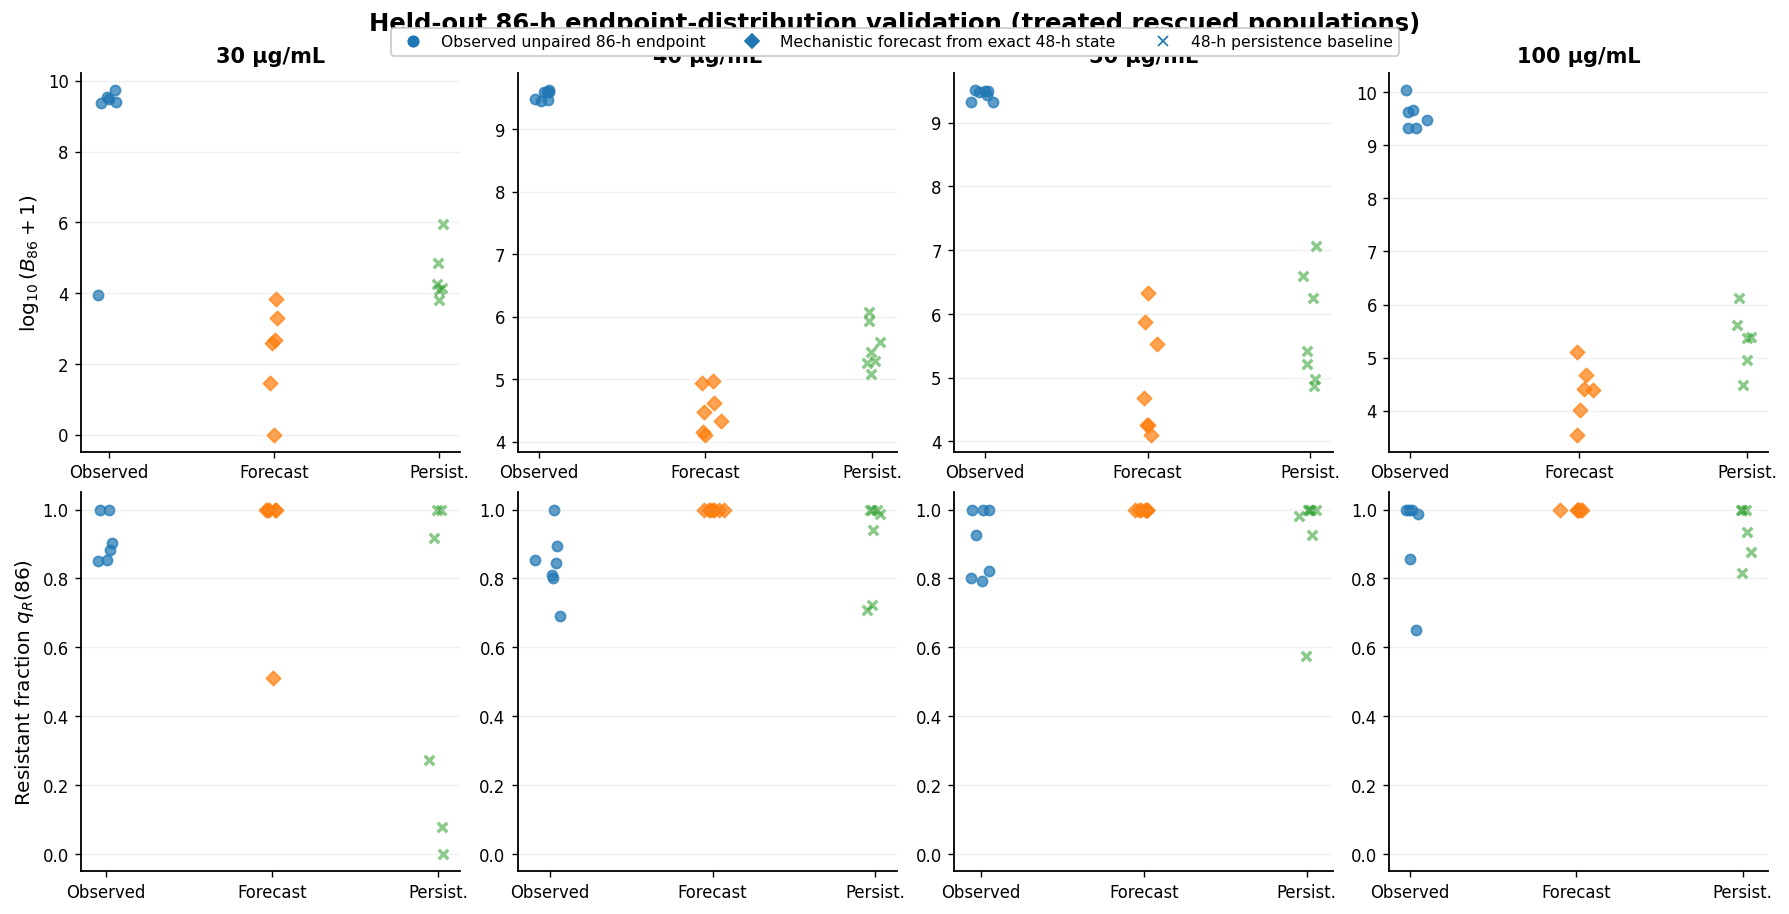

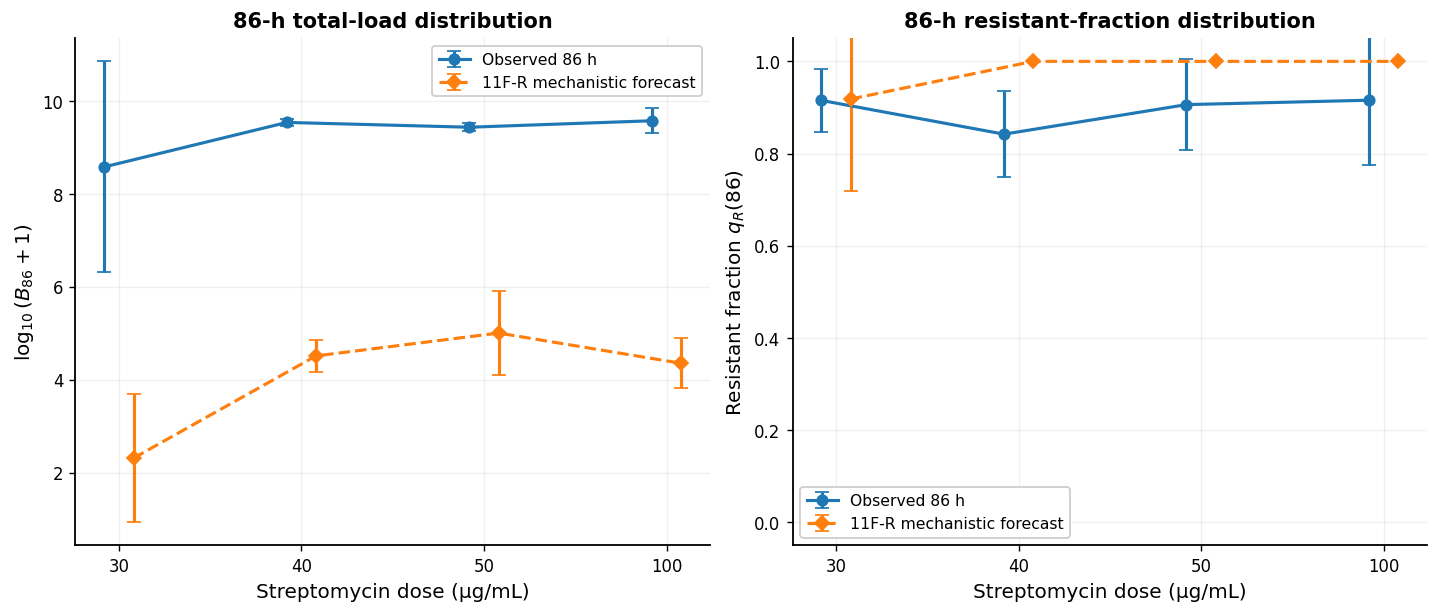


R3.10 DECISION SUMMARY
log10_B86    | mean WD 11F-R=5.2376 | persistence=3.9991 | delta=+1.2385 -> 48-h persistence is closer than the 11F-R forecast
qR86         | mean WD 11F-R=0.1131 | persistence=0.1464 | delta=-0.0333 -> 11F-R forecast improves on 48-h persistence

Important interpretation:
- These are UNPAIRED distribution comparisons. Do NOT report individual 48->86 h replicate errors.
- The forecast is conditional on the 26 rescued phenotype-linked populations observed at 48 h.
- The exact observed 48-h state is supplied before propagation. Therefore, this experiment specifically tests the post-48 h mechanistic dynamics.
- A strong miss in log10(B86) means the fitted post-48 h growth/recovery mechanism does not explain the independent 86-h rebound distribution.
- A good qR86 forecast together with a poor B86 forecast means phenotype composition is captured better than absolute post-treatment population recovery.
- This is an exact FINAL 11F-R ODE propagation from the observed 

In [58]:
# CELL 12 — EXPERIMENT 3.10
# FINAL 11F-R HELD-OUT 86-h UNPAIRED ENDPOINT-DISTRIBUTION VALIDATION
# =============================================================================
#
# PURPOSE
# -------
# The treated 86-h endpoint data have no population IDs. Therefore, this cell
# NEVER pairs a treated 86-h row with an individual 48-h trajectory.
#
# For each treated dose (30, 40, 50, 100 ug/mL), it:
#
#   1) starts from the EXACTLY LINKED observed 48-h state (B48, qR48) of each
#      phenotype-linked rescued population;
#
#   2) propagates that observed state from 48 -> 86 h with the FINAL selected
#      11F-R exact mechanistic ODE;
#
#   3) uses the 12 inverse parameters learned by the FINAL full-data R3.7
#      11F-R model and frozen unchanged through P1/P2:
#
#         shared: mu, cR, rS, d0, q0, rhoR, tauK, gammaK
#         dose-specific: k30, k40, k50, k100
#
#   4) compares the predicted 86-h DISTRIBUTION with the independent, unpaired
#      experimental 86-h endpoint distribution;
#
#   5) compares the mechanistic forecast with a simple 48-h persistence baseline.
#
# IMPORTANT
# ---------
# - This is a DISTRIBUTION-LEVEL future-endpoint validation.
# - It is NOT an individual-replicate prediction because treated 86-h IDs
#   are unavailable.
# - No treated 86-h endpoint value is used to train, refine, select, or tune
#   the PINN, the 11F-R parameters, or this forecast.
# - This cell performs NO PINN retraining and NO parameter refitting.
# - R3.9 nested-design parameter estimates are NOT used here. R3.9 is a
#   sensitivity experiment; R3.10 uses the finalized full-data R3.7 parameters.
# - Because the exact observed 48-h state is supplied before propagation, this
#   specifically tests the FINAL 11F-R post-48-h mechanistic dynamics.
# - Report this as an "exact 11F-R mechanistic 48->86 h forecast using frozen
#   full-data PINN-inferred parameters", not as a direct neural 86-h forecast.
# =============================================================================

from pathlib import Path
from scipy.integrate import solve_ivp
from scipy.stats import wasserstein_distance

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D


# =============================================================================
# 0. CONFIGURATION AND SAFETY CHECKS
# =============================================================================

required_globals_12 = [
    "FULL_RESULT",
    "K_REAL",
    "SENSITIVE_DRUG_EFFECT",
    "RESISTANT_DRUG_EFFECT",
    "RUN_LABEL",
]

missing_globals_12 = [
    name
    for name in required_globals_12
    if name not in globals()
]

if missing_globals_12:
    raise RuntimeError(
        "Cell 12 requires the finalized 11F-R real-data workflow.\n"
        f"Missing globals: {missing_globals_12}"
    )

if globals().get("QUICK_MODE", False):
    raise RuntimeError(
        "R3.10 is a FINAL held-out validation. Run with QUICK_MODE=False."
    )

EXPECTED_ARCHITECTURE_12 = "shared_dose_conditioned_hard_PINN_11FR"
EXPECTED_PHYSICS_VARIANT_12 = "11F-R_reduced_time_structured_killing"

# P2 is the finalized state representation. Its inverse parameters were frozen,
# so they must be numerically identical to the base R3.7 FULL_RESULT parameters.
if "INTEGRAL_REFINED_RESULT" in globals():
    FINAL_REFERENCE_RESULT_12 = INTEGRAL_REFINED_RESULT
    PARAMETER_SOURCE_NAME_12 = "INTEGRAL_REFINED_RESULT (P2; inverse parameters frozen)"
else:
    FINAL_REFERENCE_RESULT_12 = FULL_RESULT
    PARAMETER_SOURCE_NAME_12 = "FULL_RESULT (base R3.7 11F-R)"

architecture_12 = getattr(
    FINAL_REFERENCE_RESULT_12.model,
    "architecture_name",
    None,
)

if architecture_12 != EXPECTED_ARCHITECTURE_12:
    raise RuntimeError(
        "Cell 12 architecture mismatch.\n"
        f"Expected : {EXPECTED_ARCHITECTURE_12}\n"
        f"Found    : {architecture_12}"
    )

full_architecture_12 = getattr(
    FULL_RESULT.model,
    "architecture_name",
    None,
)

if full_architecture_12 != EXPECTED_ARCHITECTURE_12:
    raise RuntimeError(
        "FULL_RESULT is not the finalized 11F-R architecture.\n"
        f"Found: {full_architecture_12!r}"
    )

# Guard the finalized training configuration when LOSS_WEIGHTS is present.
if "LOSS_WEIGHTS" in globals():
    if not np.isclose(float(LOSS_WEIGHTS.physics), 25.0):
        raise RuntimeError(
            "Cell 12 expected the finalized base physics weight 25.0, "
            f"found {float(LOSS_WEIGHTS.physics)}."
        )
    if not np.isclose(float(LOSS_WEIGHTS.log_physics), 2.5):
        raise RuntimeError(
            "Cell 12 expected the finalized log-physics weight 2.5, "
            f"found {float(LOSS_WEIGHTS.log_physics)}."
        )

# FINAL-specific tag so QUICK/development outputs cannot be confused with
# publication outputs.
R310_TAG = f"{RUN_LABEL}_R310_11FR_86h_unpaired_distribution_forecast"

R310_TREATED_DOSES = [
    30.0,
    40.0,
    50.0,
    100.0,
]

R310_T0 = 48.0
R310_T1 = 86.0

R310_QUANTILE_GRID = np.linspace(
    0.0,
    1.0,
    101,
)


# Output folders
if "TABLE_DIR" not in globals():

    if "OUTPUT_ROOT" in globals():
        TABLE_DIR = Path(OUTPUT_ROOT) / "tables"

    else:
        TABLE_DIR = (
            Path.cwd()
            / "Real_PINN_Results"
            / "tables"
        )


if "FIGURE_DIR" not in globals():

    if "OUTPUT_ROOT" in globals():
        FIGURE_DIR = Path(OUTPUT_ROOT) / "figures"

    else:
        FIGURE_DIR = (
            Path.cwd()
            / "Real_PINN_Results"
            / "figures"
        )


TABLE_DIR = Path(TABLE_DIR)
FIGURE_DIR = Path(FIGURE_DIR)

TABLE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


print("=" * 104)
print(
    "CELL 12 / R3.10 — HELD-OUT 86-h "
    "UNPAIRED ENDPOINT-DISTRIBUTION VALIDATION"
)
print("=" * 104)

print("Run label                      :", RUN_LABEL)
print("Architecture                   :", architecture_12)
print(
    "Execution mode                 :",
    "QUICK"
    if globals().get("QUICK_MODE", False)
    else "FINAL",
)
print("Forecast interval              : 48 -> 86 h")
print("Comparison level               : dose-wise distribution (UNPAIRED)")
print("Forecast initial state         : exact observed B48 + exact linked qR48")
print("Forecast dynamics              : exact FINAL 11F-R ODE")
print("Mechanistic parameter source   :", PARAMETER_SOURCE_NAME_12)
print("R3.9 parameters used            : NO")
print("Treated 86-h endpoint in fit   : NO")
print("Output tag                     :", R310_TAG)


# =============================================================================
# 1. RESOLVE EXACT 48-h LINKED PHENOTYPE DATA
# =============================================================================

def _copy_dataframe_if_available_12(name):

    obj = globals().get(
        name,
        None,
    )

    if isinstance(
        obj,
        pd.DataFrame,
    ):
        return obj.copy()

    return None


q48_12 = None
q48_source_12 = None


# First try already-loaded dataframes
for candidate_name in [
    "q48",
    "q48_df",
]:

    candidate = _copy_dataframe_if_available_12(
        candidate_name
    )

    if candidate is None:
        continue

    needed = {
        "dose_ug_ml",
        "resistant_fraction_qR",
    }

    if needed.issubset(
        candidate.columns
    ):
        q48_12 = candidate.copy()
        q48_source_12 = candidate_name
        break


# Otherwise resolve from file
if q48_12 is None:

    candidate_paths_48 = []

    if "Q48_PATH" in globals():

        try:
            candidate_paths_48.append(
                Path(Q48_PATH)
            )
        except Exception:
            pass


    if "DATA_DIR" in globals():

        candidate_paths_48.append(
            Path(DATA_DIR)
            / "Ramsayer_qR_48h_EXACT_linked.csv"
        )


    candidate_paths_48.append(
        Path(
            globals().get("DATA_DIR", (Path.cwd().parent if Path.cwd().name.lower() == "notebooks" else Path.cwd()) / "data" / "real")
        ) / "Ramsayer_qR_48h_EXACT_linked.csv"
    )


    seen_48 = set()

    for path_48 in candidate_paths_48:

        key = str(path_48)

        if key in seen_48:
            continue

        seen_48.add(key)

        if path_48.exists():

            q48_12 = pd.read_csv(
                path_48
            )

            q48_source_12 = str(
                path_48
            )

            break


if q48_12 is None:

    raise FileNotFoundError(
        "Could not resolve "
        "Ramsayer_qR_48h_EXACT_linked.csv."
    )


required_q48_cols_12 = {
    "dose_ug_ml",
    "population_id",
    "log10_population_plus1",
    "resistant_fraction_qR",
}

missing_q48_cols_12 = (
    required_q48_cols_12
    .difference(
        q48_12.columns
    )
)

if missing_q48_cols_12:

    raise RuntimeError(
        "Exact qR48 dataframe is missing columns: "
        f"{sorted(missing_q48_cols_12)}"
    )


for col in [
    "dose_ug_ml",
    "log10_population_plus1",
    "resistant_fraction_qR",
]:

    q48_12[col] = pd.to_numeric(
        q48_12[col],
        errors="coerce",
    )


# Treated doses only
q48_12 = q48_12[
    q48_12[
        "dose_ug_ml"
    ].isin(
        R310_TREATED_DOSES
    )
].copy()


# Exact 48-h rows only
if "time_h" in q48_12.columns:

    q48_12[
        "time_h"
    ] = pd.to_numeric(
        q48_12["time_h"],
        errors="coerce",
    )

    q48_12 = q48_12[
        np.isclose(
            q48_12["time_h"],
            48.0,
        )
    ].copy()


q48_12 = q48_12.dropna(
    subset=[
        "dose_ug_ml",
        "log10_population_plus1",
        "resistant_fraction_qR",
    ]
).reset_index(
    drop=True
)


q48_12[
    "resistant_fraction_qR"
] = np.clip(
    q48_12[
        "resistant_fraction_qR"
    ].to_numpy(float),
    0.0,
    1.0,
)


# Derive B48 from log population if needed
derived_B48_12 = (
    np.power(
        10.0,
        q48_12[
            "log10_population_plus1"
        ].to_numpy(float),
    )
    - 1.0
)


if "population_size_est" not in q48_12.columns:

    q48_12[
        "population_size_est"
    ] = derived_B48_12

else:

    q48_12[
        "population_size_est"
    ] = pd.to_numeric(
        q48_12[
            "population_size_est"
        ],
        errors="coerce",
    )

    missing_B48 = ~np.isfinite(
        q48_12[
            "population_size_est"
        ].to_numpy(float)
    )

    if np.any(
        missing_B48
    ):

        q48_12.loc[
            missing_B48,
            "population_size_est",
        ] = derived_B48_12[
            missing_B48
        ]


# q48 should represent rescued phenotype-linked populations only
if "status_86" in q48_12.columns:

    status_values_12 = set(
        q48_12[
            "status_86"
        ]
        .dropna()
        .astype(str)
        .str.lower()
        .unique()
    )

    if any(
        ("dead" in value)
        or ("extinct" in value)
        for value in status_values_12
    ):

        raise RuntimeError(
            "The qR48 table unexpectedly contains dead/extinct populations.\n"
            "R3.10 must use only the rescued phenotype-linked 48-h cohort."
        )


# =============================================================================
# 2. RESOLVE THE INDEPENDENT UNPAIRED 86-h ENDPOINT DATA
# =============================================================================
#
# IMPORTANT:
# The numerical treated 86-h validation values are NOT embedded here.
# The external verified CSV is required.
# =============================================================================

q86_12 = None
q86_source_12 = None

candidate_paths_86 = []


if "Q86_PATH" in globals():

    try:
        candidate_paths_86.append(
            Path(Q86_PATH)
        )
    except Exception:
        pass


if "DATA_DIR" in globals():

    data_dir_12 = Path(
        DATA_DIR
    )

    candidate_paths_86.extend(
        [
            data_dir_12
            / "Ramsayer_qR_86h_ENDPOINT_unpaired.csv",

            data_dir_12
            / "Ramsayer_qR_86h_ENDPOINT_unpaired_RECOVERED.csv",

            data_dir_12
            / "Ramsayer_qR_86h_ENDPOINT_unpaired (1).csv",
        ]
    )


candidate_paths_86.extend(
    [
        Path(
            globals().get("DATA_DIR", (Path.cwd().parent if Path.cwd().name.lower() == "notebooks" else Path.cwd()) / "data" / "real")
        ) / "Ramsayer_qR_86h_ENDPOINT_unpaired.csv",

        Path(
            globals().get("DATA_DIR", (Path.cwd().parent if Path.cwd().name.lower() == "notebooks" else Path.cwd()) / "data" / "real")
        ) / "Ramsayer_qR_86h_ENDPOINT_unpaired_RECOVERED.csv",

        Path(
            globals().get("DATA_DIR", (Path.cwd().parent if Path.cwd().name.lower() == "notebooks" else Path.cwd()) / "data" / "real")
        ) / "Ramsayer_qR_86h_ENDPOINT_unpaired (1).csv",
    ]
)


# Remove duplicate paths
unique_paths_86 = []
seen_paths_86 = set()

for path_86 in candidate_paths_86:

    key = str(
        path_86
    )

    if key not in seen_paths_86:

        unique_paths_86.append(
            path_86
        )

        seen_paths_86.add(
            key
        )


required_q86_here = {
    "dose_ug_ml",
    "log10_population_plus1",
    "resistant_fraction_qR",
}

read_errors_86 = []


for path_86 in unique_paths_86:

    try:

        if not path_86.exists():
            continue

        candidate_df_86 = pd.read_csv(
            path_86
        )

        if not required_q86_here.issubset(
            candidate_df_86.columns
        ):

            read_errors_86.append(
                f"{path_86}: missing "
                f"{sorted(required_q86_here.difference(candidate_df_86.columns))}"
            )

            continue


        q86_12 = candidate_df_86.copy()

        q86_source_12 = str(
            path_86
        )

        break


    except Exception as exc:

        read_errors_86.append(
            f"{path_86}: "
            f"{type(exc).__name__}: {exc}"
        )


if q86_12 is None:

    searched_paths = "\n".join(
        f"  - {p}"
        for p in unique_paths_86
    )

    error_details = (
        "\nRead/format errors:\n  - "
        + "\n  - ".join(
            read_errors_86
        )
        if read_errors_86
        else ""
    )

    raise FileNotFoundError(
        "Cell 12 requires the independent treated 86-h endpoint CSV.\n"
        "No endpoint values are embedded in this FINAL cell.\n\n"
        "Expected one of:\n"
        "  Ramsayer_qR_86h_ENDPOINT_unpaired.csv\n"
        "  Ramsayer_qR_86h_ENDPOINT_unpaired_RECOVERED.csv\n\n"
        "Paths checked:\n"
        f"{searched_paths}"
        f"{error_details}"
    )


# Validate columns
missing_q86_cols_12 = (
    required_q86_here
    .difference(
        q86_12.columns
    )
)

if missing_q86_cols_12:

    raise RuntimeError(
        "86-h endpoint dataframe is missing columns: "
        f"{sorted(missing_q86_cols_12)}"
    )


for col in [
    "dose_ug_ml",
    "log10_population_plus1",
    "resistant_fraction_qR",
]:

    q86_12[col] = pd.to_numeric(
        q86_12[col],
        errors="coerce",
    )


q86_treated_12 = q86_12[
    q86_12[
        "dose_ug_ml"
    ].isin(
        R310_TREATED_DOSES
    )
].copy()


q86_treated_12 = q86_treated_12.dropna(
    subset=[
        "dose_ug_ml",
        "log10_population_plus1",
        "resistant_fraction_qR",
    ]
).reset_index(
    drop=True
)


q86_treated_12[
    "resistant_fraction_qR"
] = np.clip(
    q86_treated_12[
        "resistant_fraction_qR"
    ].to_numpy(float),
    0.0,
    1.0,
)


# =============================================================================
# 2B. HARD 86-h ENDPOINT COUNT AUDIT
# =============================================================================

expected_counts_12 = {
    30.0: 6,
    40.0: 7,
    50.0: 7,
    100.0: 6,
}

observed_counts_12 = {
    float(dose): int(
        (
            q86_treated_12[
                "dose_ug_ml"
            ]
            == dose
        ).sum()
    )
    for dose in R310_TREATED_DOSES
}


if observed_counts_12 != expected_counts_12:

    raise RuntimeError(
        "Resolved 86-h endpoint table failed the treated-row count audit.\n"
        f"Expected: {expected_counts_12}\n"
        f"Observed: {observed_counts_12}\n"
        f"Source: {q86_source_12}"
    )


print(
    "\nResolved qR86 endpoint source:",
    q86_source_12,
)

print(
    "Treated qR86 row-count audit  : PASSED",
    observed_counts_12,
)


# =============================================================================
# 3. 48-h vs 86-h ENDPOINT-DATA AUDIT
# =============================================================================

count_rows_12 = []


for dose in R310_TREATED_DOSES:

    n48 = int(
        (
            q48_12[
                "dose_ug_ml"
            ]
            == dose
        ).sum()
    )

    n86 = int(
        (
            q86_treated_12[
                "dose_ug_ml"
            ]
            == dose
        ).sum()
    )


    count_rows_12.append(
        {
            "dose_ug_ml":
                dose,

            "n_exact_qR48_rescued":
                n48,

            "n_unpaired_qR86_endpoint":
                n86,

            "same_count":
                bool(
                    n48 == n86
                ),
        }
    )


endpoint_count_audit_12 = pd.DataFrame(
    count_rows_12
)


print(
    "\nEndpoint-data audit:"
)

print(
    "qR48 source :",
    q48_source_12,
)

print(
    "qR86 source :",
    q86_source_12,
)

display(
    endpoint_count_audit_12
)


if (
    endpoint_count_audit_12[
        "n_exact_qR48_rescued"
    ]
    == 0
).any():

    raise RuntimeError(
        "At least one treated dose has no exact qR48 starting states."
    )


if (
    endpoint_count_audit_12[
        "n_unpaired_qR86_endpoint"
    ]
    == 0
).any():

    raise RuntimeError(
        "At least one treated dose has no 86-h endpoint observations."
    )


if not endpoint_count_audit_12[
    "same_count"
].all():

    print(
        "WARNING: 48-h and 86-h rescued endpoint counts differ for at least "
        "one dose. Distribution metrics remain valid, but NO one-to-one "
        "interpretation is allowed."
    )


# =============================================================================
# 4. GET THE FINAL 12-PARAMETER 11F-R MECHANISTIC SET
# =============================================================================
#
# The inverse parameters were learned during the base full-data R3.7 11F-R fit.
# P1 and P2 refined only the neural state trajectory with the inverse parameters
# frozen. Therefore FULL_RESULT and INTEGRAL_REFINED_RESULT must expose the same
# 12 biological / pharmacodynamic parameters.
# =============================================================================

params_12 = (
    FINAL_REFERENCE_RESULT_12
    .model
    .inferred_parameters()
)

required_param_keys_12 = [
    "mutation_probability",
    "resistance_fitness_cost",
    "sensitive_birth_rate_per_h",
    "baseline_death_rate_per_h",
    "initial_resistant_fraction_shared",
    "kill_30_per_h",
    "kill_40_per_h",
    "kill_50_per_h",
    "kill_100_per_h",
    "resistant_relative_drug_sensitivity",
    "kill_activation_onset_h",
    "kill_activation_per_h",
]

missing_param_keys_12 = [
    key
    for key in required_param_keys_12
    if key not in params_12
]

if missing_param_keys_12:
    raise RuntimeError(
        "The final 11F-R model does not expose all required parameters: "
        f"{missing_param_keys_12}"
    )

# Explicitly confirm the P1/P2 freeze contract whenever the P2 object exists.
base_params_12 = FULL_RESULT.model.inferred_parameters()
max_frozen_parameter_difference_12 = 0.0

for key in required_param_keys_12:
    if key not in base_params_12:
        raise RuntimeError(
            f"FULL_RESULT is missing final 11F-R parameter {key!r}."
        )

    difference = abs(
        float(params_12[key])
        - float(base_params_12[key])
    )

    max_frozen_parameter_difference_12 = max(
        max_frozen_parameter_difference_12,
        difference,
    )

if max_frozen_parameter_difference_12 > 1e-12:
    raise RuntimeError(
        "P1/P2 parameter-freeze audit failed before R3.10. "
        f"Maximum parameter difference={max_frozen_parameter_difference_12:.3e}."
    )

mu_12 = float(params_12["mutation_probability"])
cR_12 = float(params_12["resistance_fitness_cost"])
rS_12 = float(params_12["sensitive_birth_rate_per_h"])
d0_12 = float(params_12["baseline_death_rate_per_h"])
q0_12 = float(params_12["initial_resistant_fraction_shared"])
rhoR_12 = float(params_12["resistant_relative_drug_sensitivity"])
tauK_12 = float(params_12["kill_activation_onset_h"])
gammaK_12 = float(params_12["kill_activation_per_h"])

kill_by_dose_12 = {
    30.0: float(params_12["kill_30_per_h"]),
    40.0: float(params_12["kill_40_per_h"]),
    50.0: float(params_12["kill_50_per_h"]),
    100.0: float(params_12["kill_100_per_h"]),
}

parameter_table_12 = pd.DataFrame(
    [
        {
            **{key: float(params_12[key]) for key in required_param_keys_12},
            "K_REAL_cells": float(K_REAL),
            "parameter_source": PARAMETER_SOURCE_NAME_12,
            "max_P2_vs_base_parameter_difference": (
                max_frozen_parameter_difference_12
            ),
        }
    ]
)

print(
    "\nFinal frozen 11F-R parameters used for the 48 -> 86 h forecast:"
)
display(parameter_table_12)
print(
    "Parameter-freeze audit         : PASSED | max difference =",
    f"{max_frozen_parameter_difference_12:.3e}",
)


# =============================================================================
# 5. EXACT FINAL 11F-R MECHANISTIC ODE
# =============================================================================
#
# H_K(t) = sigmoid(gamma_K * (t - tau_K))
# G_R(t) = 1
#
# dS/dt = bS(A)(1-mu)(1-S-R)S - [d0 + k_A H_K(t)]S
#
# dR/dt = bS(A)mu(1-S-R)S + bR(A)(1-S-R)R
#         - [d0 + rhoR k_A H_K(t)]R
#
# IMPORTANT: t is ABSOLUTE experimental time in hours. Because the forecast
# begins at 48 h, solve_ivp must integrate over t_span=(48, 86), not (0, 38).
# =============================================================================

R310_ODE_RTOL = 2.0e-8
R310_ODE_ATOL = 2.0e-11
R310_FORECAST_AUDIT_GRID = np.arange(
    R310_T0,
    R310_T1 + 0.5,
    0.5,
    dtype=float,
)


def kill_activation_12(t):
    z = float(
        np.clip(
            gammaK_12
            * (
                float(t)
                - tauK_12
            ),
            -60.0,
            60.0,
        )
    )

    return float(
        1.0
        / (
            1.0
            + np.exp(-z)
        )
    )


def kill_rate_for_dose_12(dose):
    dose = float(dose)

    if np.isclose(dose, 0.0):
        return 0.0

    if dose not in kill_by_dose_12:
        raise KeyError(
            f"No finalized 11F-R kill coefficient is available for dose={dose:g}."
        )

    return float(kill_by_dose_12[dose])


def rhs_r310_12(
    t,
    y,
    dose,
):
    """Final normalized 11F-R S/R mechanism used by the real-data PINN."""

    s = float(y[0])
    r = float(y[1])

    exposure = float(
        np.clip(
            float(dose) / 100.0,
            0.0,
            1.0,
        )
    )

    b_s = (
        rS_12
        * (
            1.0
            - float(SENSITIVE_DRUG_EFFECT)
            * exposure
        )
    )

    b_r = (
        rS_12
        * (1.0 - cR_12)
        * (
            1.0
            - float(RESISTANT_DRUG_EFFECT)
            * exposure
        )
    )

    crowding = 1.0 - s - r

    if np.isclose(float(dose), 0.0):
        kA = 0.0
        Hk = 0.0
    else:
        kA = kill_rate_for_dose_12(dose)
        Hk = kill_activation_12(t)

    ds_dt = (
        b_s
        * (1.0 - mu_12)
        * crowding
        * s
        - (
            d0_12
            + kA * Hk
        )
        * s
    )

    # Reduced 11F-R model: resistant-growth gate G_R(t) is fixed to 1.
    dr_dt = (
        b_s
        * mu_12
        * crowding
        * s
        + b_r
        * crowding
        * r
        - (
            d0_12
            + rhoR_12
            * kA
            * Hk
        )
        * r
    )

    return np.array(
        [
            ds_dt,
            dr_dt,
        ],
        dtype=float,
    )


# =============================================================================
# 5B. FORECAST ONE EXACT 48-h POPULATION STATE TO 86 h
# =============================================================================

def forecast_one_q48_population_12(
    row
):

    dose = float(
        row[
            "dose_ug_ml"
        ]
    )


    population_id = row[
        "population_id"
    ]


    B48 = float(
        row[
            "population_size_est"
        ]
    )


    qR48 = float(
        row[
            "resistant_fraction_qR"
        ]
    )


    if (
        not np.isfinite(
            B48
        )
        or B48 < 0.0
    ):

        raise RuntimeError(
            f"Invalid B48 for population "
            f"{population_id}: {B48}"
        )


    if (
        not np.isfinite(
            qR48
        )
        or qR48 < 0.0
        or qR48 > 1.0
    ):

        raise RuntimeError(
            f"Invalid qR48 for population "
            f"{population_id}: {qR48}"
        )


    # ---------------------------------------------------------
    # Exact observed state at 48 h
    # ---------------------------------------------------------

    s0 = (
        B48
        * (
            1.0
            - qR48
        )
        /
        float(
            K_REAL
        )
    )


    r0 = (
        B48
        * qR48
        /
        float(
            K_REAL
        )
    )


    # ---------------------------------------------------------
    # Exact ODE propagation from 48 -> 86 h
    # ---------------------------------------------------------

    if s0 < -1e-12 or r0 < -1e-12:
        raise RuntimeError(
            f"Observed 48-h state is negative for population {population_id}."
        )

    if s0 + r0 > 1.0 + 1e-5:
        raise RuntimeError(
            f"Observed 48-h state exceeds K_REAL for population {population_id}: "
            f"(S+R)/K={s0 + r0:.6f}."
        )

    solution = solve_ivp(
        fun=lambda t, y: rhs_r310_12(
            t,
            y,
            dose,
        ),

        t_span=(
            R310_T0,
            R310_T1,
        ),

        y0=np.array(
            [
                s0,
                r0,
            ],
            dtype=float,
        ),

        t_eval=R310_FORECAST_AUDIT_GRID,

        method="DOP853",

        rtol=R310_ODE_RTOL,
        atol=R310_ODE_ATOL,
    )


    if not solution.success:

        raise RuntimeError(
            f"86-h forecast failed for "
            f"dose={dose:g}, "
            f"population={population_id}: "
            f"{solution.message}"
        )

    if not np.all(np.isfinite(solution.y)):
        raise RuntimeError(
            f"86-h 11F-R forecast generated non-finite states for "
            f"dose={dose:g}, population={population_id}."
        )

    min_state_12 = float(np.min(solution.y))
    max_total_12 = float(np.max(solution.y.sum(axis=0)))

    if min_state_12 < -1e-7:
        raise RuntimeError(
            f"86-h 11F-R forecast generated a materially negative state for "
            f"dose={dose:g}, population={population_id}: {min_state_12:.3e}."
        )

    if max_total_12 > 1.0 + 1e-5:
        raise RuntimeError(
            f"86-h 11F-R forecast exceeded normalized carrying capacity for "
            f"dose={dose:g}, population={population_id}: {max_total_12:.6f}."
        )


    s86 = max(
        float(
            solution.y[
                0,
                -1
            ]
        ),
        0.0,
    )


    r86 = max(
        float(
            solution.y[
                1,
                -1
            ]
        ),
        0.0,
    )


    total_norm_86 = (
        s86
        + r86
    )


    B86 = (
        float(
            K_REAL
        )
        * total_norm_86
    )


    if total_norm_86 > 0.0:

        qR86 = (
            r86
            /
            total_norm_86
        )

    else:

        qR86 = 0.0


    return {

        "dose_ug_ml":
            dose,

        "population_id_48h":
            population_id,

        "observed_log10_B48":
            float(
                row[
                    "log10_population_plus1"
                ]
            ),

        "observed_qR48":
            qR48,

        "forecast_log10_B86":
            float(
                np.log10(
                    B86
                    + 1.0
                )
            ),

        "forecast_qR86":
            float(
                np.clip(
                    qR86,
                    0.0,
                    1.0,
                )
            ),

        "forecast_S86_cells":
            float(
                K_REAL
            )
            * s86,

        "forecast_R86_cells":
            float(
                K_REAL
            )
            * r86,

        "dose_specific_kA_per_h":
            kill_rate_for_dose_12(dose),

        "kill_activation_HK_at_48h":
            kill_activation_12(R310_T0),

        "kill_activation_HK_at_86h":
            kill_activation_12(R310_T1),

        "min_normalized_state_48_86":
            min_state_12,

        "max_normalized_total_48_86":
            max_total_12,

        # -----------------------------------------------------
        # Persistence baseline:
        # observed state at 48 h is simply carried to 86 h.
        # -----------------------------------------------------

        "persistence_log10_B86":
            float(
                row[
                    "log10_population_plus1"
                ]
            ),

        "persistence_qR86":
            qR48,
    }


# =============================================================================
# 5C. RUN ALL 26 POST-48 h FORECASTS
# =============================================================================

forecast_rows_12 = []


for _, row in q48_12.iterrows():

    forecast_rows_12.append(
        forecast_one_q48_population_12(
            row
        )
    )


forecast_86_12 = pd.DataFrame(
    forecast_rows_12
)


print(
    "\nMechanistic 48 -> 86 h forecasts completed:",
    len(
        forecast_86_12
    ),
)


# =============================================================================
# 6. UNPAIRED DISTRIBUTION METRICS
# =============================================================================

def quantile_rmse_12(
    predicted,
    observed,
):

    predicted = np.asarray(
        predicted,
        dtype=float,
    )

    observed = np.asarray(
        observed,
        dtype=float,
    )


    predicted = predicted[
        np.isfinite(
            predicted
        )
    ]

    observed = observed[
        np.isfinite(
            observed
        )
    ]


    if (
        len(
            predicted
        )
        == 0
        or len(
            observed
        )
        == 0
    ):

        return np.nan


    pred_q = np.quantile(
        predicted,
        R310_QUANTILE_GRID,
    )

    obs_q = np.quantile(
        observed,
        R310_QUANTILE_GRID,
    )


    return float(
        np.sqrt(
            np.mean(
                (
                    pred_q
                    - obs_q
                )
                ** 2
            )
        )
    )


def distribution_metrics_12(
    predicted,
    observed,
):

    predicted = np.asarray(
        predicted,
        dtype=float,
    )

    observed = np.asarray(
        observed,
        dtype=float,
    )


    predicted = predicted[
        np.isfinite(
            predicted
        )
    ]

    observed = observed[
        np.isfinite(
            observed
        )
    ]


    if (
        len(
            predicted
        )
        == 0
        or len(
            observed
        )
        == 0
    ):

        raise RuntimeError(
            "Distribution metric received an empty "
            "prediction or observation set."
        )


    return {

        "predicted_mean":
            float(
                np.mean(
                    predicted
                )
            ),

        "predicted_sd":
            (
                float(
                    np.std(
                        predicted,
                        ddof=1,
                    )
                )
                if len(
                    predicted
                )
                > 1
                else 0.0
            ),

        "observed_mean":
            float(
                np.mean(
                    observed
                )
            ),

        "observed_sd":
            (
                float(
                    np.std(
                        observed,
                        ddof=1,
                    )
                )
                if len(
                    observed
                )
                > 1
                else 0.0
            ),

        "abs_error_in_mean":
            float(
                abs(
                    np.mean(
                        predicted
                    )
                    -
                    np.mean(
                        observed
                    )
                )
            ),

        "wasserstein_distance":
            float(
                wasserstein_distance(
                    observed,
                    predicted,
                )
            ),

        "quantile_rmse":
            quantile_rmse_12(
                predicted,
                observed,
            ),
    }


# =============================================================================
# 6B. DOSE-WISE FORECAST vs OBSERVED vs PERSISTENCE
# =============================================================================

metric_rows_12 = []


for dose in R310_TREATED_DOSES:

    pred_d = forecast_86_12[
        forecast_86_12[
            "dose_ug_ml"
        ]
        == dose
    ].copy()


    obs_d = q86_treated_12[
        q86_treated_12[
            "dose_ug_ml"
        ]
        == dose
    ].copy()


    for (
        variable_name,
        pred_col,
        baseline_col,
        obs_col,
    ) in [

        (
            "log10_B86",
            "forecast_log10_B86",
            "persistence_log10_B86",
            "log10_population_plus1",
        ),

        (
            "qR86",
            "forecast_qR86",
            "persistence_qR86",
            "resistant_fraction_qR",
        ),

    ]:


        observed_values = obs_d[
            obs_col
        ].to_numpy(
            float
        )


        forecast_metrics = distribution_metrics_12(
            pred_d[
                pred_col
            ].to_numpy(
                float
            ),
            observed_values,
        )


        persistence_metrics = distribution_metrics_12(
            pred_d[
                baseline_col
            ].to_numpy(
                float
            ),
            observed_values,
        )


        metric_rows_12.append(
            {
                "dose_ug_ml":
                    dose,

                "variable":
                    variable_name,

                "model":
                    "11FR_mechanistic_48_to_86_forecast",

                "n_predicted":
                    len(
                        pred_d
                    ),

                "n_observed":
                    len(
                        obs_d
                    ),

                **forecast_metrics,
            }
        )


        metric_rows_12.append(
            {
                "dose_ug_ml":
                    dose,

                "variable":
                    variable_name,

                "model":
                    "48h_persistence_baseline",

                "n_predicted":
                    len(
                        pred_d
                    ),

                "n_observed":
                    len(
                        obs_d
                    ),

                **persistence_metrics,
            }
        )


distribution_metrics_table_12 = pd.DataFrame(
    metric_rows_12
)


print(
    "\nDose-wise UNPAIRED distribution metrics:"
)

display(
    distribution_metrics_table_12
)


# =============================================================================
# 7. OVERALL MODEL-vs-PERSISTENCE SUMMARY
# =============================================================================

summary_rows_12 = []


for variable_name in [
    "log10_B86",
    "qR86",
]:

    sub = distribution_metrics_table_12[
        distribution_metrics_table_12[
            "variable"
        ]
        == variable_name
    ]


    forecast_sub = sub[
        sub[
            "model"
        ]
        == "11FR_mechanistic_48_to_86_forecast"
    ]


    baseline_sub = sub[
        sub[
            "model"
        ]
        == "48h_persistence_baseline"
    ]


    summary_rows_12.append(
        {

            "variable":
                variable_name,

            "mean_Wasserstein_11FR":
                float(
                    forecast_sub[
                        "wasserstein_distance"
                    ].mean()
                ),

            "mean_Wasserstein_persistence":
                float(
                    baseline_sub[
                        "wasserstein_distance"
                    ].mean()
                ),

            "delta_Wasserstein_11FR_minus_persistence":
                float(
                    forecast_sub[
                        "wasserstein_distance"
                    ].mean()
                    -
                    baseline_sub[
                        "wasserstein_distance"
                    ].mean()
                ),

            "mean_quantile_RMSE_11FR":
                float(
                    forecast_sub[
                        "quantile_rmse"
                    ].mean()
                ),

            "mean_quantile_RMSE_persistence":
                float(
                    baseline_sub[
                        "quantile_rmse"
                    ].mean()
                ),
        }
    )


model_comparison_12 = pd.DataFrame(
    summary_rows_12
)


print(
    "\nOverall distribution-level comparison:"
)

display(
    model_comparison_12
)


print(
    "\nInterpretation rule: negative "
    "delta_Wasserstein_11FR_minus_persistence means the "
    "mechanistic 48->86 h forecast is closer to the independent "
    "endpoint distribution than simply carrying the observed "
    "48-h state forward."
)


# =============================================================================
# 8. DOSE-WISE MEAN ± SD TABLE
# =============================================================================

endpoint_summary_rows_12 = []


for dose in R310_TREATED_DOSES:

    pred_d = forecast_86_12[
        forecast_86_12[
            "dose_ug_ml"
        ]
        == dose
    ]


    obs_d = q86_treated_12[
        q86_treated_12[
            "dose_ug_ml"
        ]
        == dose
    ]


    endpoint_summary_rows_12.append(
        {

            "dose_ug_ml":
                dose,

            "n_48h_forecast_states":
                len(
                    pred_d
                ),

            "n_86h_unpaired_observations":
                len(
                    obs_d
                ),

            "forecast_mean_log10_B86":
                pred_d[
                    "forecast_log10_B86"
                ].mean(),

            "forecast_sd_log10_B86":
                pred_d[
                    "forecast_log10_B86"
                ].std(
                    ddof=1
                ),

            "observed_mean_log10_B86":
                obs_d[
                    "log10_population_plus1"
                ].mean(),

            "observed_sd_log10_B86":
                obs_d[
                    "log10_population_plus1"
                ].std(
                    ddof=1
                ),

            "forecast_mean_qR86":
                pred_d[
                    "forecast_qR86"
                ].mean(),

            "forecast_sd_qR86":
                pred_d[
                    "forecast_qR86"
                ].std(
                    ddof=1
                ),

            "observed_mean_qR86":
                obs_d[
                    "resistant_fraction_qR"
                ].mean(),

            "observed_sd_qR86":
                obs_d[
                    "resistant_fraction_qR"
                ].std(
                    ddof=1
                ),
        }
    )


endpoint_summary_12 = pd.DataFrame(
    endpoint_summary_rows_12
)


print(
    "\n86-h endpoint summary (UNPAIRED):"
)

display(
    endpoint_summary_12
)


# =============================================================================
# 9. FIGURE A — FULL ENDPOINT DISTRIBUTIONS BY DOSE
# =============================================================================

rng_12 = np.random.default_rng(
    int(
        globals().get(
            "SEED",
            20260815,
        )
    )
    + 310
)


fig, axes = plt.subplots(
    2,
    4,
    figsize=(
        14.2,
        7.2,
    ),
    constrained_layout=True,
)


for col_idx, dose in enumerate(
    R310_TREATED_DOSES
):

    pred_d = forecast_86_12[
        forecast_86_12[
            "dose_ug_ml"
        ]
        == dose
    ]


    obs_d = q86_treated_12[
        q86_treated_12[
            "dose_ug_ml"
        ]
        == dose
    ]


    # -------------------------------------------------------------------------
    # TOP: total load
    # -------------------------------------------------------------------------

    ax = axes[
        0,
        col_idx
    ]


    obs_values = obs_d[
        "log10_population_plus1"
    ].to_numpy(float)


    pred_values = pred_d[
        "forecast_log10_B86"
    ].to_numpy(float)


    base_values = pred_d[
        "persistence_log10_B86"
    ].to_numpy(float)


    x_obs = (
        np.zeros(
            len(
                obs_values
            )
        )
        +
        rng_12.normal(
            0.0,
            0.035,
            len(
                obs_values
            ),
        )
    )


    x_pred = (
        np.ones(
            len(
                pred_values
            )
        )
        +
        rng_12.normal(
            0.0,
            0.035,
            len(
                pred_values
            ),
        )
    )


    x_base = (
        np.full(
            len(
                base_values
            ),
            2.0,
        )
        +
        rng_12.normal(
            0.0,
            0.035,
            len(
                base_values
            ),
        )
    )


    ax.scatter(
        x_obs,
        obs_values,
        s=34,
        alpha=0.72,
        label="Observed 86 h",
    )


    ax.scatter(
        x_pred,
        pred_values,
        s=34,
        alpha=0.72,
        marker="D",
        label="11F-R mechanistic forecast",
    )


    ax.scatter(
        x_base,
        base_values,
        s=30,
        alpha=0.55,
        marker="x",
        label="48-h persistence",
    )


    ax.set_xticks(
        [
            0,
            1,
            2,
        ],
        [
            "Observed",
            "Forecast",
            "Persist.",
        ],
    )


    ax.set_title(
        f"{dose:g} µg/mL",
        fontweight="bold",
    )


    ax.set_ylabel(
        r"$\log_{10}(B_{86}+1)$"
        if col_idx == 0
        else ""
    )


    ax.grid(
        axis="y",
        alpha=0.18,
    )


    ax.spines[
        [
            "top",
            "right",
        ]
    ].set_visible(
        False
    )


    # -------------------------------------------------------------------------
    # BOTTOM: resistant fraction
    # -------------------------------------------------------------------------

    ax = axes[
        1,
        col_idx
    ]


    obs_values = obs_d[
        "resistant_fraction_qR"
    ].to_numpy(float)


    pred_values = pred_d[
        "forecast_qR86"
    ].to_numpy(float)


    base_values = pred_d[
        "persistence_qR86"
    ].to_numpy(float)


    x_obs = (
        np.zeros(
            len(
                obs_values
            )
        )
        +
        rng_12.normal(
            0.0,
            0.035,
            len(
                obs_values
            ),
        )
    )


    x_pred = (
        np.ones(
            len(
                pred_values
            )
        )
        +
        rng_12.normal(
            0.0,
            0.035,
            len(
                pred_values
            ),
        )
    )


    x_base = (
        np.full(
            len(
                base_values
            ),
            2.0,
        )
        +
        rng_12.normal(
            0.0,
            0.035,
            len(
                base_values
            ),
        )
    )


    ax.scatter(
        x_obs,
        obs_values,
        s=34,
        alpha=0.72,
    )


    ax.scatter(
        x_pred,
        pred_values,
        s=34,
        alpha=0.72,
        marker="D",
    )


    ax.scatter(
        x_base,
        base_values,
        s=30,
        alpha=0.55,
        marker="x",
    )


    ax.set_xticks(
        [
            0,
            1,
            2,
        ],
        [
            "Observed",
            "Forecast",
            "Persist.",
        ],
    )


    ax.set_ylim(
        -0.05,
        1.05,
    )


    ax.set_ylabel(
        r"Resistant fraction $q_R(86)$"
        if col_idx == 0
        else ""
    )


    ax.grid(
        axis="y",
        alpha=0.18,
    )


    ax.spines[
        [
            "top",
            "right",
        ]
    ].set_visible(
        False
    )


fig.suptitle(
    "Held-out 86-h endpoint-distribution validation "
    "(treated rescued populations)",
    fontsize=14,
    fontweight="bold",
)


legend_handles_12 = [

    Line2D(
        [0],
        [0],
        marker="o",
        linestyle="none",
        label="Observed unpaired 86-h endpoint",
    ),

    Line2D(
        [0],
        [0],
        marker="D",
        linestyle="none",
        label="Mechanistic forecast from exact 48-h state",
    ),

    Line2D(
        [0],
        [0],
        marker="x",
        linestyle="none",
        label="48-h persistence baseline",
    ),
]


fig.legend(
    handles=legend_handles_12,
    loc="upper center",
    bbox_to_anchor=(
        0.5,
        0.985,
    ),
    ncol=3,
    frameon=True,
)


figure_path_a_12 = (
    FIGURE_DIR
    /
    f"{R310_TAG}_endpoint_distributions.png"
)


fig.savefig(
    figure_path_a_12,
    dpi=300,
    bbox_inches="tight",
)


plt.show()


# =============================================================================
# 10. FIGURE B — DOSE-WISE MEAN ± SD
# =============================================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(
        11.4,
        4.8,
    ),
    constrained_layout=True,
)


x_12 = np.arange(
    len(
        R310_TREATED_DOSES
    ),
    dtype=float,
)


# -------------------------------------------------------------------------
# TOTAL LOAD
# -------------------------------------------------------------------------

ax = axes[0]


ax.errorbar(
    x_12 - 0.08,

    endpoint_summary_12[
        "observed_mean_log10_B86"
    ],

    yerr=endpoint_summary_12[
        "observed_sd_log10_B86"
    ],

    fmt="o-",
    capsize=4,
    linewidth=1.8,
    label="Observed 86 h",
)


ax.errorbar(
    x_12 + 0.08,

    endpoint_summary_12[
        "forecast_mean_log10_B86"
    ],

    yerr=endpoint_summary_12[
        "forecast_sd_log10_B86"
    ],

    fmt="D--",
    capsize=4,
    linewidth=1.8,
    label="11F-R mechanistic forecast",
)


ax.set_xticks(
    x_12,
    [
        str(
            int(d)
        )
        for d in R310_TREATED_DOSES
    ],
)


ax.set_xlabel(
    "Streptomycin dose (µg/mL)"
)


ax.set_ylabel(
    r"$\log_{10}(B_{86}+1)$"
)


ax.set_title(
    "86-h total-load distribution",
    fontweight="bold",
)


ax.grid(
    alpha=0.18
)


ax.spines[
    [
        "top",
        "right",
    ]
].set_visible(
    False
)


ax.legend()


# -------------------------------------------------------------------------
# RESISTANT FRACTION
# -------------------------------------------------------------------------

ax = axes[1]


ax.errorbar(
    x_12 - 0.08,

    endpoint_summary_12[
        "observed_mean_qR86"
    ],

    yerr=endpoint_summary_12[
        "observed_sd_qR86"
    ],

    fmt="o-",
    capsize=4,
    linewidth=1.8,
    label="Observed 86 h",
)


ax.errorbar(
    x_12 + 0.08,

    endpoint_summary_12[
        "forecast_mean_qR86"
    ],

    yerr=endpoint_summary_12[
        "forecast_sd_qR86"
    ],

    fmt="D--",
    capsize=4,
    linewidth=1.8,
    label="11F-R mechanistic forecast",
)


ax.set_xticks(
    x_12,
    [
        str(
            int(d)
        )
        for d in R310_TREATED_DOSES
    ],
)


ax.set_xlabel(
    "Streptomycin dose (µg/mL)"
)


ax.set_ylabel(
    r"Resistant fraction $q_R(86)$"
)


ax.set_ylim(
    -0.05,
    1.05,
)


ax.set_title(
    "86-h resistant-fraction distribution",
    fontweight="bold",
)


ax.grid(
    alpha=0.18
)


ax.spines[
    [
        "top",
        "right",
    ]
].set_visible(
    False
)


ax.legend()


figure_path_b_12 = (
    FIGURE_DIR
    /
    f"{R310_TAG}_mean_sd.png"
)


fig.savefig(
    figure_path_b_12,
    dpi=300,
    bbox_inches="tight",
)


plt.show()


# =============================================================================
# 11. SAVE FINAL TABLES
# =============================================================================

forecast_path_12 = (
    TABLE_DIR
    /
    f"{R310_TAG}_population_forecasts_from_48h.csv"
)


metrics_path_12 = (
    TABLE_DIR
    /
    f"{R310_TAG}_distribution_metrics.csv"
)


summary_path_12 = (
    TABLE_DIR
    /
    f"{R310_TAG}_dose_summary.csv"
)


comparison_path_12 = (
    TABLE_DIR
    /
    f"{R310_TAG}_model_vs_persistence.csv"
)


count_audit_path_12 = (
    TABLE_DIR
    /
    f"{R310_TAG}_count_audit.csv"
)


parameters_path_12 = (
    TABLE_DIR
    /
    f"{R310_TAG}_mechanistic_parameters.csv"
)


forecast_86_12.to_csv(
    forecast_path_12,
    index=False,
)


distribution_metrics_table_12.to_csv(
    metrics_path_12,
    index=False,
)


endpoint_summary_12.to_csv(
    summary_path_12,
    index=False,
)


model_comparison_12.to_csv(
    comparison_path_12,
    index=False,
)


endpoint_count_audit_12.to_csv(
    count_audit_path_12,
    index=False,
)


parameter_table_12.to_csv(
    parameters_path_12,
    index=False,
)


# =============================================================================
# 12. FINAL DECISION SUMMARY
# =============================================================================

print(
    "\n"
    + "=" * 104
)

print(
    "R3.10 DECISION SUMMARY"
)

print(
    "=" * 104
)


for _, row in model_comparison_12.iterrows():

    variable_name = row[
        "variable"
    ]

    delta = row[
        "delta_Wasserstein_11FR_minus_persistence"
    ]


    if delta < 0.0:

        decision = (
            "11F-R forecast improves on 48-h persistence"
        )


    elif delta > 0.0:

        decision = (
            "48-h persistence is closer than the 11F-R forecast"
        )


    else:

        decision = (
            "11F-R forecast and persistence are tied"
        )


    print(
        f"{variable_name:12s} | "
        f"mean WD 11F-R="
        f"{row['mean_Wasserstein_11FR']:.4f} | "
        f"persistence="
        f"{row['mean_Wasserstein_persistence']:.4f} | "
        f"delta="
        f"{delta:+.4f} -> "
        f"{decision}"
    )


print(
    "\nImportant interpretation:"
)


print(
    "- These are UNPAIRED distribution comparisons. "
    "Do NOT report individual 48->86 h replicate errors."
)


print(
    "- The forecast is conditional on the 26 rescued "
    "phenotype-linked populations observed at 48 h."
)


print(
    "- The exact observed 48-h state is supplied before propagation. "
    "Therefore, this experiment specifically tests the post-48 h "
    "mechanistic dynamics."
)


print(
    "- A strong miss in log10(B86) means the fitted post-48 h "
    "growth/recovery mechanism does not explain the independent "
    "86-h rebound distribution."
)


print(
    "- A good qR86 forecast together with a poor B86 forecast means "
    "phenotype composition is captured better than absolute "
    "post-treatment population recovery."
)


print(
    "- This is an exact FINAL 11F-R ODE propagation from the observed 48-h "
    "state using frozen full-data R3.7 inverse parameters; it is NOT a direct "
    "neural-network trajectory forecast."
)

print(
    "- R3.9 nested-design estimates are intentionally not used or averaged here; "
    "they remain a separate treatment-diversity sensitivity analysis."
)


print(
    "\nSaved outputs:"
)


for path in [

    forecast_path_12,
    metrics_path_12,
    summary_path_12,
    comparison_path_12,
    count_audit_path_12,
    parameters_path_12,
    figure_path_a_12,
    figure_path_b_12,

]:

    print(
        " ",
        path,
    )


print(
    "=" * 104
)

---
## Reproducibility manifest

The final cell records which primary analyses and supplementary diagnostics were actually executed and stores the model-form interpretation caveat.


In [59]:
# CELL 13 — FINAL 11F-R CONSOLIDATED AUDIT / PROVENANCE / EXPORT
# =============================================================================
# PURPOSE
# -------
# Final read-only publication audit after R3.7 -> P1/P2 -> R3.8 -> R3.9 -> R3.10.
#
# This cell deliberately replaces the old standalone Audit A / Audit B /
# Audit C / Diagnostic 11B bookkeeping cells. It performs NO training and NO
# parameter optimization.
#
# It consolidates only the pieces retained for the final manuscript:
#   1) final 11F-R identity + configuration guards;
#   2) FULL_RESULT inverse-parameter summary and P2 freeze verification;
#   3) final P2 observation / hard-feasibility / physics / loss audits;
#   4) full observed-horizon (0-48 h) P2-PINN vs exact 11F-R ODE consistency;
#   5) matched treated-data fit/objective comparison for PINN vs same-parameter ODE;
#   6) compact but strict R3.8 completeness/configuration verification;
#   7) compact but strict R3.9 25-run completeness/configuration verification;
#   8) R3.10 independent unpaired 86-h endpoint-validation verification;
#   9) software, seeds, artifact paths, hashes, and one JSON manifest.
#
# Intentionally NOT reintroduced here:
#   S1, 11C, 11D, 11E, 11F/11F+, 11G, 11H, 11I exploratory branches.
# =============================================================================

import hashlib
import json
import math
import platform
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import scipy
import torch


# =============================================================================
# 0. SMALL HELPERS
# =============================================================================

def _available_13(name: str) -> bool:
    return name in globals()


def _safe_float_13(value):
    try:
        if value is None:
            return None
        value = float(value)
        return value if np.isfinite(value) else None
    except Exception:
        return None


def _json_safe_13(value):
    if value is None:
        return None
    if isinstance(value, (str, bool, int)):
        return value
    if isinstance(value, float):
        return value if np.isfinite(value) else None
    if isinstance(value, np.generic):
        return _json_safe_13(value.item())
    if isinstance(value, Path):
        return str(value)
    if isinstance(value, dict):
        return {str(k): _json_safe_13(v) for k, v in value.items()}
    if isinstance(value, (list, tuple, set)):
        return [_json_safe_13(v) for v in value]
    if isinstance(value, pd.Series):
        return _json_safe_13(value.to_dict())
    if isinstance(value, pd.DataFrame):
        cleaned = value.replace({np.nan: None, np.inf: None, -np.inf: None})
        return _json_safe_13(cleaned.to_dict(orient="records"))
    try:
        return str(value)
    except Exception:
        return None


def _read_csv_if_exists_13(path: Path):
    path = Path(path)
    return pd.read_csv(path) if path.exists() else None


def _sha256_file_13(path):
    if path is None:
        return None
    try:
        path = Path(path)
    except Exception:
        return None
    if not path.exists() or not path.is_file():
        return None
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def _numeric_allclose_13(series, target, atol=1e-12):
    arr = pd.to_numeric(series, errors="coerce").to_numpy(float)
    return bool(np.all(np.isfinite(arr)) and np.all(np.isclose(arr, target, atol=atol, rtol=0.0)))


def _parameter_difference_13(a: dict, b: dict, keys):
    diffs = {}
    for key in keys:
        if key not in a or key not in b:
            raise RuntimeError(f"Missing parameter {key!r} during final freeze audit.")
        diffs[key] = abs(float(a[key]) - float(b[key]))
    return diffs


# =============================================================================
# 1. FINAL PRECONDITIONS / DIRECTORIES / CONFIGURATION
# =============================================================================

required_globals_13 = [
    "RUN_LABEL",
    "QUICK_MODE",
    "DEVICE",
    "FULL_RESULT",
    "BASE_BUNDLE",
    "K_REAL",
    "LOSS_WEIGHTS",
    "SENSITIVE_DRUG_EFFECT",
    "RESISTANT_DRUG_EFFECT",
    "observation_metrics",
    "feasibility_audit",
    "physics_fidelity_audit",
    "log_physics_fidelity_audit",
    "loss_balance_audit",
    "exact_ode_consistency_audit",
    "predict_numpy",
]

missing_globals_13 = [name for name in required_globals_13 if name not in globals()]
if missing_globals_13:
    raise RuntimeError(
        "Cell 13 requires the finalized 11F-R analysis environment.\n"
        f"Missing globals: {missing_globals_13}"
    )

if bool(QUICK_MODE):
    raise RuntimeError(
        "Cell 13 is the publication audit and must not be run with QUICK_MODE=True."
    )

EXPECTED_ARCHITECTURE_13 = "shared_dose_conditioned_hard_PINN_11FR"
EXPECTED_PHYSICS_VARIANT_13 = "11F-R_reduced_time_structured_killing"
EXPECTED_PHYSICS_WEIGHT_13 = 25.0
EXPECTED_LOG_PHYSICS_WEIGHT_13 = 2.5
R37_TAG_13 = "R37_shared_dose_conditioned_11FR"

architecture_13 = getattr(FULL_RESULT.model, "architecture_name", None)
if architecture_13 != EXPECTED_ARCHITECTURE_13:
    raise RuntimeError(
        "Cell 13 architecture mismatch.\n"
        f"Expected: {EXPECTED_ARCHITECTURE_13}\n"
        f"Found   : {architecture_13}"
    )

if not np.isclose(float(LOSS_WEIGHTS.physics), EXPECTED_PHYSICS_WEIGHT_13):
    raise RuntimeError(
        f"Expected LOSS_WEIGHTS.physics={EXPECTED_PHYSICS_WEIGHT_13}, "
        f"found {float(LOSS_WEIGHTS.physics)}."
    )

if not np.isclose(float(LOSS_WEIGHTS.log_physics), EXPECTED_LOG_PHYSICS_WEIGHT_13):
    raise RuntimeError(
        f"Expected LOSS_WEIGHTS.log_physics={EXPECTED_LOG_PHYSICS_WEIGHT_13}, "
        f"found {float(LOSS_WEIGHTS.log_physics)}."
    )

if "TABLE_DIR" not in globals():
    TABLE_DIR = (
        Path(OUTPUT_ROOT) / "tables"
        if "OUTPUT_ROOT" in globals()
        else Path.cwd() / "Real_PINN_Results" / "tables"
    )

if "REPORT_DIR" not in globals():
    REPORT_DIR = (
        Path(OUTPUT_ROOT) / "reports"
        if "OUTPUT_ROOT" in globals()
        else Path.cwd() / "Real_PINN_Results" / "reports"
    )

if "MODEL_DIR" not in globals():
    MODEL_DIR = (
        Path(OUTPUT_ROOT) / "models"
        if "OUTPUT_ROOT" in globals()
        else Path.cwd() / "Real_PINN_Results" / "models"
    )

TABLE_DIR = Path(TABLE_DIR)
REPORT_DIR = Path(REPORT_DIR)
MODEL_DIR = Path(MODEL_DIR)
TABLE_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 112)
print("CELL 13 — FINAL 11F-R CONSOLIDATED AUDIT / PROVENANCE / EXPORT")
print("=" * 112)
print("Run label              :", RUN_LABEL)
print("Architecture           :", architecture_13)
print("Physics variant        :", EXPECTED_PHYSICS_VARIANT_13)
print("Physics weight         :", float(LOSS_WEIGHTS.physics))
print("Log-physics weight     :", float(LOSS_WEIGHTS.log_physics))
print("Execution mode         : FINAL")
print("Training in this cell  : NONE")


# =============================================================================
# 2. RESOLVE THE FINAL P2 STATE MODEL WITHOUT RETRAINING
# =============================================================================
# P1/P2 freeze all inverse parameters. FULL_RESULT remains the canonical source
# of the learned inverse parameters; INTEGRAL_REFINED_RESULT is the finalized
# state trajectory used for final state/physics/mechanistic-consistency audits.
#
# If the P2 object was lost after a kernel restart, Cell 13 may restore its
# checkpoint. This is a READ-ONLY restore, not training.
# =============================================================================

P2_TAG_13 = "R37_11FR_stateonly_multiscale_integral_defect_x10"
P2_CHECKPOINT_13 = MODEL_DIR / f"{RUN_LABEL}_{P2_TAG_13}.pt"

if "INTEGRAL_REFINED_RESULT" not in globals():
    if not P2_CHECKPOINT_13.exists():
        raise RuntimeError(
            "INTEGRAL_REFINED_RESULT is not in memory and the final P2 checkpoint "
            f"was not found:\n{P2_CHECKPOINT_13}\n"
            "Restore/run the finalized P2 continuation before the publication audit."
        )

    if "RealAMRPINN" not in globals() or "TrainingResult" not in globals():
        raise RuntimeError(
            "P2 checkpoint exists, but RealAMRPINN/TrainingResult is unavailable. "
            "Run the finalized model-definition/trainer cells first."
        )

    p2_ckpt_13 = torch.load(
        P2_CHECKPOINT_13,
        map_location=DEVICE,
        weights_only=False,
    )

    if not isinstance(p2_ckpt_13, dict):
        raise RuntimeError("The final P2 checkpoint is not a dictionary.")

    if p2_ckpt_13.get("architecture") != EXPECTED_ARCHITECTURE_13:
        raise RuntimeError(
            "P2 checkpoint architecture mismatch: "
            f"{p2_ckpt_13.get('architecture')!r}"
        )

    if p2_ckpt_13.get("physics_variant") != EXPECTED_PHYSICS_VARIANT_13:
        raise RuntimeError(
            "P2 checkpoint physics variant mismatch: "
            f"{p2_ckpt_13.get('physics_variant')!r}"
        )

    p2_model_13 = RealAMRPINN(BASE_BUNDLE).to(DEVICE)
    p2_model_13.load_state_dict(p2_ckpt_13["model_state"], strict=True)

    INTEGRAL_REFINED_RESULT = TrainingResult(
        label=P2_TAG_13,
        model=p2_model_13,
        history=pd.DataFrame(),
        best_validation_score=np.nan,
        elapsed_seconds=np.nan,
        seed=int(p2_ckpt_13.get("seed", globals().get("SEED", 0))),
    )

    print("P2 state model          : restored read-only from", P2_CHECKPOINT_13)
else:
    print("P2 state model          : using INTEGRAL_REFINED_RESULT already in memory")

FINAL_STATE_RESULT_13 = INTEGRAL_REFINED_RESULT
FINAL_STATE_MODEL_13 = FINAL_STATE_RESULT_13.model

if getattr(FINAL_STATE_MODEL_13, "architecture_name", None) != EXPECTED_ARCHITECTURE_13:
    raise RuntimeError("Final P2 state model is not the expected 11F-R architecture.")


# =============================================================================
# 3. FINAL 12-PARAMETER SUMMARY + P2 PARAMETER-FREEZE AUDIT
# =============================================================================

FINAL_11FR_PARAMETER_KEYS_13 = [
    "mutation_probability",
    "resistance_fitness_cost",
    "sensitive_birth_rate_per_h",
    "baseline_death_rate_per_h",
    "initial_resistant_fraction_shared",
    "kill_30_per_h",
    "kill_40_per_h",
    "kill_50_per_h",
    "kill_100_per_h",
    "resistant_relative_drug_sensitivity",
    "kill_activation_onset_h",
    "kill_activation_per_h",
]

base_parameters_13 = FULL_RESULT.model.inferred_parameters()
p2_parameters_13 = FINAL_STATE_MODEL_13.inferred_parameters()

missing_base_parameters_13 = [k for k in FINAL_11FR_PARAMETER_KEYS_13 if k not in base_parameters_13]
missing_p2_parameters_13 = [k for k in FINAL_11FR_PARAMETER_KEYS_13 if k not in p2_parameters_13]

if missing_base_parameters_13 or missing_p2_parameters_13:
    raise RuntimeError(
        "Final 11F-R parameter audit failed.\n"
        f"Missing from FULL_RESULT: {missing_base_parameters_13}\n"
        f"Missing from P2        : {missing_p2_parameters_13}"
    )

parameter_differences_13 = _parameter_difference_13(
    base_parameters_13,
    p2_parameters_13,
    FINAL_11FR_PARAMETER_KEYS_13,
)
max_p2_parameter_change_13 = max(parameter_differences_13.values(), default=0.0)

if max_p2_parameter_change_13 > 1e-14:
    raise RuntimeError(
        "P2 parameter-freeze audit failed. Maximum FULL_RESULT-to-P2 difference = "
        f"{max_p2_parameter_change_13:.3e}."
    )

# Optional q0 alias check, retained from old Audit B.
q0_shared_13 = float(base_parameters_13["initial_resistant_fraction_shared"])
q0_alias_keys_13 = [k for k in base_parameters_13 if str(k).startswith("q0_dose_")]
q0_alias_max_difference_13 = 0.0
if q0_alias_keys_13:
    q0_alias_max_difference_13 = max(
        abs(float(base_parameters_13[k]) - q0_shared_13)
        for k in q0_alias_keys_13
    )
    if q0_alias_max_difference_13 > 1e-12:
        raise RuntimeError("Shared-q0 alias audit failed.")

parameter_table_13 = pd.DataFrame(
    [{key: float(base_parameters_13[key]) for key in FINAL_11FR_PARAMETER_KEYS_13}]
)
parameter_table_13["K_REAL_cells"] = float(K_REAL)
parameter_table_13["parameter_source"] = "FULL_RESULT; unchanged by P1/P2"
parameter_table_13["max_P2_vs_base_parameter_difference"] = max_p2_parameter_change_13

print("\nFinal 11F-R inverse parameters (canonical source = FULL_RESULT):")
display(parameter_table_13)
print("P2 inverse-parameter freeze: PASSED | max change =", f"{max_p2_parameter_change_13:.3e}")


# =============================================================================
# 4. FINAL OBSERVATION METRICS — BASE vs FINAL P2 STATE TRAJECTORY
# =============================================================================

metric_rows_13 = []
for stage_name_13, model_13 in [
    ("R3.7_base_11FR", FULL_RESULT.model),
    ("P2_final_state_11FR", FINAL_STATE_MODEL_13),
]:
    for split_13 in ["train", "val"]:
        metrics_13 = observation_metrics(
            model_13,
            BASE_BUNDLE,
            split=split_13,
        )
        metric_rows_13.append(
            {
                "model_stage": stage_name_13,
                "split": "validation" if split_13 == "val" else "train",
                **metrics_13,
            }
        )

metric_table_13 = pd.DataFrame(metric_rows_13)

print("\nFinal observation metrics (base and final P2 state):")
display(metric_table_13)


# =============================================================================
# 5. FINAL HARD-FEASIBILITY AUDIT — FINAL P2 STATE
# =============================================================================

feasibility_13 = feasibility_audit(
    FINAL_STATE_MODEL_13,
    BASE_BUNDLE.doses,
)

max_negative_violation_13 = float(feasibility_13["negative_violation"].max())
max_capacity_violation_13 = float(feasibility_13["capacity_violation"].max())

if max_negative_violation_13 > 1e-12:
    raise RuntimeError(
        f"Final P2 state failed non-negativity audit: {max_negative_violation_13:.3e}."
    )
if max_capacity_violation_13 > 1e-12:
    raise RuntimeError(
        f"Final P2 state failed capacity audit: {max_capacity_violation_13:.3e}."
    )

print("\nFinal P2 hard-feasibility audit:")
display(feasibility_13)
print("Hard-feasibility audit: PASSED")


# =============================================================================
# 6. AUDIT A INTEGRATION — FINAL PHYSICS FIDELITY + LOSS BALANCE
# =============================================================================
# physics_fidelity_audit uses the notebook's PHYSICS_HORIZON_H. In this workflow
# that horizon is 86 h. This is a residual/consistency audit, NOT external-data
# validation beyond 48 h.
# =============================================================================

physics_audit_13 = physics_fidelity_audit(
    model=FINAL_STATE_MODEL_13,
    doses=BASE_BUNDLE.doses,
    n_points=1001,
)

log_physics_audit_13 = log_physics_fidelity_audit(
    model=FINAL_STATE_MODEL_13,
    doses=BASE_BUNDLE.doses,
    start_h=0.0,
    end_h=4.0,
    n_points=1001,
)

loss_audit_13 = loss_balance_audit(
    model=FINAL_STATE_MODEL_13,
    bundle=BASE_BUNDLE,
    seed=int(globals().get("SEED", getattr(FULL_RESULT, "seed", 0))),
)

print("\nFinal P2 absolute physics-fidelity audit:")
display(physics_audit_13)
print("\nFinal P2 early log-state physics audit (0-4 h):")
display(log_physics_audit_13)
print("\nBase-objective loss-component balance evaluated on final P2 state:")
display(loss_audit_13)
print(
    "NOTE: loss_balance_audit reports the base Cell-6 objective components; "
    "the separate P2 integral-defect continuation term is not re-added by this helper."
)


# =============================================================================
# 7. CORRECTED 11B / AUDIT-C REPLACEMENT — COMPLETE OBSERVED-HORIZON CONSISTENCY
# =============================================================================
# The retained mechanistic-consistency audit follows the original 11B intent but
# uses the FINAL 11F-R equations and FINAL P2 state network:
#   - untreated control: through its available observed horizon;
#   - treated doses: 0-48 h only;
#   - treated 86-h endpoint: NEVER used here (reserved for R3.10 / Cell 12).
#
# The focused 23-48 h treated summary replaces the old early-only Audit C as the
# decisive late-observed-window diagnostic.
# =============================================================================

R13_TREATED_DOSES = [30.0, 40.0, 50.0, 100.0]
R13_MODEL_FORM_DOSES = [float(d) for d in BASE_BUNDLE.doses]


def _observed_horizon_for_dose_13(dose):
    dose = float(dose)
    times_13 = []
    for frame_13 in [BASE_BUNDLE.total, BASE_BUNDLE.fraction]:
        if "time_h" not in frame_13.columns:
            continue
        vals_13 = frame_13.loc[
            frame_13["dose_ug_ml"] == dose,
            "time_h",
        ].to_numpy(float)
        times_13.extend(vals_13.tolist())

    if not times_13:
        raise RuntimeError(f"No observed times are available for dose={dose:g}.")

    observed_max_13 = float(np.max(times_13))
    if dose > 0.0:
        # Treated 86-h endpoint is intentionally external and not part of BASE_BUNDLE.
        return min(48.0, observed_max_13)
    return observed_max_13


model_form_detail_parts_13 = []
model_form_summary_parts_13 = []
model_form_horizon_by_dose_13 = {}

for dose_13 in R13_MODEL_FORM_DOSES:
    horizon_13 = _observed_horizon_for_dose_13(dose_13)
    model_form_horizon_by_dose_13[dose_13] = horizon_13

    observed_times_dose_13 = []
    for frame_13 in [BASE_BUNDLE.total, BASE_BUNDLE.fraction]:
        observed_times_dose_13.extend(
            frame_13.loc[
                (frame_13["dose_ug_ml"] == dose_13)
                & (frame_13["time_h"] <= horizon_13 + 1e-12),
                "time_h",
            ].to_numpy(float).tolist()
        )

    check_times_dose_13 = np.unique(
        np.concatenate(
            [
                np.linspace(0.0, horizon_13, max(2, int(round(4.0 * horizon_13)) + 1)),
                np.asarray(observed_times_dose_13, dtype=float),
            ]
        )
    )

    detail_dose_13, summary_dose_13 = exact_ode_consistency_audit(
        model=FINAL_STATE_MODEL_13,
        bundle=BASE_BUNDLE,
        doses=[dose_13],
        check_times=check_times_dose_13,
    )

    detail_dose_13["observed_horizon_h"] = horizon_13
    summary_dose_13["observed_horizon_h"] = horizon_13
    model_form_detail_parts_13.append(detail_dose_13)
    model_form_summary_parts_13.append(summary_dose_13)

full_ode_detail_13 = pd.concat(model_form_detail_parts_13, ignore_index=True)
full_ode_summary_13 = pd.concat(model_form_summary_parts_13, ignore_index=True)

if full_ode_summary_13[
    [
        "mean_abs_logS_difference",
        "max_abs_logS_difference",
        "mean_abs_logR_difference",
        "max_abs_logR_difference",
    ]
].isna().any().any():
    raise RuntimeError("Non-finite value detected in final PINN/ODE audit.")

late_ode_summary_13 = (
    full_ode_detail_13[
        (full_ode_detail_13["dose_ug_ml"] > 0.0)
        & (full_ode_detail_13["time_h"] >= 23.0 - 1e-12)
        & (full_ode_detail_13["time_h"] <= 48.0 + 1e-12)
    ]
    .groupby("dose_ug_ml")
    .agg(
        mean_abs_logS_difference_23_48h=("abs_difference_logS", "mean"),
        max_abs_logS_difference_23_48h=("abs_difference_logS", "max"),
        mean_abs_logR_difference_23_48h=("abs_difference_logR", "mean"),
        max_abs_logR_difference_23_48h=("abs_difference_logR", "max"),
    )
    .reset_index()
)

print("\nFinal P2 PINN vs exact same-parameter 11F-R ODE over each dose's observed horizon:")
display(full_ode_summary_13)
print("\nFocused treated 23-48 h consistency summary:")
display(late_ode_summary_13)


# =============================================================================
# 8. CORRECTED 11B DATA-FIT / MATCHED-OBJECTIVE COMPARISON
# =============================================================================
# Compare the final P2 PINN trajectory and exact 11F-R ODE trajectory against
# the SAME observations over each dose's observed horizon. Treated 86-h rows are
# not part of BASE_BUNDLE and remain reserved for Cell 12.
# =============================================================================

def _ode_lookup_from_detail_13(detail_df):
    lookup = {}
    for row in detail_df.itertuples(index=False):
        s_cells = max(10.0 ** float(row.ODE_log10_S_plus1) - 1.0, 0.0)
        r_cells = max(10.0 ** float(row.ODE_log10_R_plus1) - 1.0, 0.0)
        key = (float(row.dose_ug_ml), round(float(row.time_h), 10))
        lookup[key] = (s_cells, r_cells)
    return lookup


ode_lookup_13 = _ode_lookup_from_detail_13(full_ode_detail_13)

data_fit_rows_13 = []
weighted_objective_13 = {}

for model_label_13 in [
    "Final P2 PINN trajectory",
    "Exact 11F-R ODE at same frozen parameters",
]:
    all_logB_true_13 = []
    all_logB_pred_13 = []
    all_qR_true_13 = []
    all_qR_pred_13 = []
    per_dose_total_mse_13 = []
    per_dose_fraction_mse_13 = []

    for dose_13 in R13_MODEL_FORM_DOSES:
        horizon_13 = model_form_horizon_by_dose_13[dose_13]

        total_df_13 = BASE_BUNDLE.total[
            (BASE_BUNDLE.total["dose_ug_ml"] == dose_13)
            & (BASE_BUNDLE.total["time_h"] <= horizon_13 + 1e-12)
        ].copy()

        if not total_df_13.empty:
            total_true_13 = total_df_13["log10_population_plus1"].to_numpy(float)

            if model_label_13.startswith("Final P2"):
                pred_df_13 = predict_numpy(
                    FINAL_STATE_MODEL_13,
                    dose_13,
                    total_df_13["time_h"].to_numpy(float),
                )
                total_pred_13 = pred_df_13["log10_total_plus1"].to_numpy(float)
            else:
                total_pred_list_13 = []
                for t_13 in total_df_13["time_h"].to_numpy(float):
                    key_13 = (dose_13, round(float(t_13), 10))
                    if key_13 not in ode_lookup_13:
                        raise RuntimeError(f"Missing exact-ODE lookup state for {key_13}.")
                    s_13, r_13 = ode_lookup_13[key_13]
                    total_pred_list_13.append(np.log10(s_13 + r_13 + 1.0))
                total_pred_13 = np.asarray(total_pred_list_13, dtype=float)

            all_logB_true_13.extend(total_true_13.tolist())
            all_logB_pred_13.extend(total_pred_13.tolist())
            per_dose_total_mse_13.append(float(np.mean((total_pred_13 - total_true_13) ** 2)))

        fraction_df_13 = BASE_BUNDLE.fraction[
            (BASE_BUNDLE.fraction["dose_ug_ml"] == dose_13)
            & (BASE_BUNDLE.fraction["time_h"] <= horizon_13 + 1e-12)
        ].copy()

        if not fraction_df_13.empty:
            q_true_13 = fraction_df_13["resistant_fraction_qR"].to_numpy(float)

            if model_label_13.startswith("Final P2"):
                pred_df_13 = predict_numpy(
                    FINAL_STATE_MODEL_13,
                    dose_13,
                    fraction_df_13["time_h"].to_numpy(float),
                )
                q_pred_13 = pred_df_13["resistant_fraction"].to_numpy(float)
            else:
                q_pred_list_13 = []
                for t_13 in fraction_df_13["time_h"].to_numpy(float):
                    key_13 = (dose_13, round(float(t_13), 10))
                    if key_13 not in ode_lookup_13:
                        raise RuntimeError(f"Missing exact-ODE lookup state for {key_13}.")
                    s_13, r_13 = ode_lookup_13[key_13]
                    denom_13 = s_13 + r_13
                    q_pred_list_13.append(r_13 / denom_13 if denom_13 > 0.0 else 0.0)
                q_pred_13 = np.asarray(q_pred_list_13, dtype=float)

            all_qR_true_13.extend(q_true_13.tolist())
            all_qR_pred_13.extend(q_pred_13.tolist())
            per_dose_fraction_mse_13.append(float(np.mean((q_pred_13 - q_true_13) ** 2)))

    all_logB_true_13 = np.asarray(all_logB_true_13, dtype=float)
    all_logB_pred_13 = np.asarray(all_logB_pred_13, dtype=float)
    all_qR_true_13 = np.asarray(all_qR_true_13, dtype=float)
    all_qR_pred_13 = np.asarray(all_qR_pred_13, dtype=float)

    observed_window_objective_13 = (
        float(LOSS_WEIGHTS.total_data) * float(np.mean(per_dose_total_mse_13))
        + float(LOSS_WEIGHTS.fraction_data) * float(np.mean(per_dose_fraction_mse_13))
    )

    weighted_objective_13[model_label_13] = observed_window_objective_13

    data_fit_rows_13.append(
        {
            "model": model_label_13,
            "n_total_observations": int(len(all_logB_true_13)),
            "rmse_logB": float(np.sqrt(np.mean((all_logB_pred_13 - all_logB_true_13) ** 2))),
            "mae_logB": float(np.mean(np.abs(all_logB_pred_13 - all_logB_true_13))),
            "n_qR_observations": int(len(all_qR_true_13)),
            "rmse_qR": float(np.sqrt(np.mean((all_qR_pred_13 - all_qR_true_13) ** 2))),
            "mae_qR": float(np.mean(np.abs(all_qR_pred_13 - all_qR_true_13))),
            "observed_window_weighted_data_objective": observed_window_objective_13,
        }
    )


data_fit_comparison_13 = pd.DataFrame(data_fit_rows_13)

pinn_objective_13 = weighted_objective_13["Final P2 PINN trajectory"]
ode_objective_13 = weighted_objective_13["Exact 11F-R ODE at same frozen parameters"]
ode_to_pinn_objective_ratio_13 = (
    ode_objective_13 / pinn_objective_13
    if pinn_objective_13 > 0.0
    else np.nan
)

objective_comparison_13 = pd.DataFrame(
    [
        {
            "PINN_observed_window_weighted_data_objective": pinn_objective_13,
            "same_parameter_exact_ODE_observed_window_weighted_data_objective": ode_objective_13,
            "exact_ODE_to_PINN_objective_ratio": ode_to_pinn_objective_ratio_13,
            "scope": (
                "control through its observed horizon; treated doses through 48 h; "
                "no treated 86-h endpoint"
            ),
        }
    ]
)

print("\nFinal P2 PINN vs exact 11F-R ODE observed-data fit comparison:")
display(data_fit_comparison_13)
print("\nMatched observed-window objective comparison:")
display(objective_comparison_13)
print(
    "Interpretation rule: report the numerical discrepancy; Cell 13 does NOT "
    "invent an arbitrary pass/fail threshold for PINN-vs-ODE consistency."
)


# =============================================================================
# 9. COMPACT R3.8 VERIFICATION — LOAD SAVED FINAL TABLES, NO RETRAINING
# =============================================================================

R38_TAG_13 = "R38_11FR_P1P2_shared_leave_one_dose_qR"
R38_RAW_PATH_13 = TABLE_DIR / f"{RUN_LABEL}_{R38_TAG_13}_raw.csv"
R38_SUMMARY_PATH_13 = TABLE_DIR / f"{RUN_LABEL}_{R38_TAG_13}_summary.csv"
R38_OVERALL_PATH_13 = TABLE_DIR / f"{RUN_LABEL}_{R38_TAG_13}_overall_summary.csv"

r38_results_13 = _read_csv_if_exists_13(R38_RAW_PATH_13)
r38_summary_13 = _read_csv_if_exists_13(R38_SUMMARY_PATH_13)
r38_overall_13 = _read_csv_if_exists_13(R38_OVERALL_PATH_13)

if r38_results_13 is None or r38_results_13.empty:
    raise RuntimeError(
        "Final R3.8 raw results were not found. Expected:\n"
        f"{R38_RAW_PATH_13}"
    )

EXPECTED_R38_DOSES_13 = [30.0, 40.0, 50.0, 100.0]
EXPECTED_R38_SEEDS_13 = [11, 22, 33]
expected_r38_pairs_13 = {
    (dose, seed)
    for dose in EXPECTED_R38_DOSES_13
    for seed in EXPECTED_R38_SEEDS_13
}
observed_r38_pairs_13 = {
    (float(row.held_dose_ug_ml), int(row.seed))
    for row in r38_results_13.itertuples(index=False)
}

if observed_r38_pairs_13 != expected_r38_pairs_13 or len(r38_results_13) != 12:
    raise RuntimeError(
        "Final R3.8 completeness audit failed.\n"
        f"Expected pairs: {sorted(expected_r38_pairs_13)}\n"
        f"Observed pairs: {sorted(observed_r38_pairs_13)}\n"
        f"Rows          : {len(r38_results_13)}"
    )

required_r38_columns_13 = {
    "architecture",
    "physics_weight",
    "log_physics_weight",
    "p1_physics_factor",
    "p1_adam_epochs",
    "p1_lbfgs_max_iter",
    "p2_pointwise_physics_factor",
    "p2_integral_weight",
    "p2_adam_epochs",
    "p2_lbfgs_max_iter",
    "p1_max_inverse_parameter_change",
    "p2_max_inverse_parameter_change",
    "final_inverse_change_from_base",
}
if not required_r38_columns_13.issubset(r38_results_13.columns):
    raise RuntimeError(
        "R3.8 raw table lacks required final metadata: "
        f"{sorted(required_r38_columns_13.difference(r38_results_13.columns))}"
    )

if not (r38_results_13["architecture"] == EXPECTED_ARCHITECTURE_13).all():
    raise RuntimeError("R3.8 contains a non-final architecture row.")
if not _numeric_allclose_13(r38_results_13["physics_weight"], 25.0):
    raise RuntimeError("R3.8 physics-weight audit failed.")
if not _numeric_allclose_13(r38_results_13["log_physics_weight"], 2.5):
    raise RuntimeError("R3.8 log-physics-weight audit failed.")
if not _numeric_allclose_13(r38_results_13["p1_physics_factor"], 5.0):
    raise RuntimeError("R3.8 P1 factor audit failed.")
if not _numeric_allclose_13(r38_results_13["p1_adam_epochs"], 1800.0):
    raise RuntimeError("R3.8 P1 Adam-epoch audit failed.")
if not _numeric_allclose_13(r38_results_13["p1_lbfgs_max_iter"], 200.0):
    raise RuntimeError("R3.8 P1 L-BFGS-iteration audit failed.")
if not _numeric_allclose_13(r38_results_13["p2_pointwise_physics_factor"], 5.0):
    raise RuntimeError("R3.8 P2 pointwise factor audit failed.")
if not _numeric_allclose_13(r38_results_13["p2_integral_weight"], 10.0):
    raise RuntimeError("R3.8 P2 integral-defect weight audit failed.")
if not _numeric_allclose_13(r38_results_13["p2_adam_epochs"], 1200.0):
    raise RuntimeError("R3.8 P2 Adam-epoch audit failed.")
if not _numeric_allclose_13(r38_results_13["p2_lbfgs_max_iter"], 150.0):
    raise RuntimeError("R3.8 P2 L-BFGS-iteration audit failed.")

r38_max_inverse_change_13 = float(
    r38_results_13[
        [
            "p1_max_inverse_parameter_change",
            "p2_max_inverse_parameter_change",
            "final_inverse_change_from_base",
        ]
    ].apply(pd.to_numeric, errors="coerce").max().max()
)
if not np.isfinite(r38_max_inverse_change_13) or r38_max_inverse_change_13 > 1e-14:
    raise RuntimeError(
        f"R3.8 inverse-freeze audit failed: max change={r38_max_inverse_change_13:.3e}."
    )

print("\nR3.8 final audit: PASSED | 12/12 dose x seed folds | P1/P2 inverse parameters frozen")


# =============================================================================
# 10. COMPACT R3.9 VERIFICATION — FINAL EFFICIENT BASE-ONLY 11F-R DESIGN STUDY
# =============================================================================

R39_TAG_13 = "R39_11FR_nested_treatment_diversity_BASE_ONLY"
R39_RAW_PATH_13 = TABLE_DIR / f"{RUN_LABEL}_{R39_TAG_13}_raw.csv"
R39_SUMMARY_PATH_13 = TABLE_DIR / f"{RUN_LABEL}_{R39_TAG_13}_summary.csv"

r39_results_13 = _read_csv_if_exists_13(R39_RAW_PATH_13)
r39_summary_13 = _read_csv_if_exists_13(R39_SUMMARY_PATH_13)

if r39_results_13 is None or r39_results_13.empty:
    raise RuntimeError(
        "Final R3.9 raw results were not found. Expected:\n"
        f"{R39_RAW_PATH_13}"
    )
if r39_summary_13 is None or r39_summary_13.empty:
    raise RuntimeError(
        "Final R3.9 summary was not found. Expected:\n"
        f"{R39_SUMMARY_PATH_13}"
    )

EXPECTED_R39_DESIGNS_13 = {
    "R1": [30.0],
    "R2": [30.0, 40.0],
    "R3": [30.0, 40.0, 50.0],
    "R4": [30.0, 40.0, 50.0, 100.0],
    "R5": [0.0, 30.0, 40.0, 50.0, 100.0],
}
EXPECTED_R39_SEEDS_13 = [1, 2, 3, 4, 5]

required_r39_columns_13 = {
    "architecture",
    "training_strategy",
    "physics_variant",
    "physics_weight",
    "log_physics_weight",
    "design",
    "n_doses",
    "doses",
    "seed",
    "max_negative_violation",
    "max_capacity_violation",
}
if not required_r39_columns_13.issubset(r39_results_13.columns):
    raise RuntimeError(
        "R3.9 raw table lacks required final metadata: "
        f"{sorted(required_r39_columns_13.difference(r39_results_13.columns))}"
    )

expected_r39_pairs_13 = {
    (design, seed)
    for design in EXPECTED_R39_DESIGNS_13
    for seed in EXPECTED_R39_SEEDS_13
}
observed_r39_pairs_13 = {
    (str(row.design), int(row.seed))
    for row in r39_results_13.itertuples(index=False)
}

if observed_r39_pairs_13 != expected_r39_pairs_13 or len(r39_results_13) != 25:
    raise RuntimeError(
        "Final R3.9 completeness audit failed.\n"
        f"Missing: {sorted(expected_r39_pairs_13 - observed_r39_pairs_13)}\n"
        f"Extra  : {sorted(observed_r39_pairs_13 - expected_r39_pairs_13)}\n"
        f"Rows   : {len(r39_results_13)}"
    )

if not (r39_results_13["architecture"] == EXPECTED_ARCHITECTURE_13).all():
    raise RuntimeError("R3.9 contains a non-final architecture row.")
if not (r39_results_13["training_strategy"] == "base_11FR_only").all():
    raise RuntimeError("R3.9 contains a non-base-only training-strategy row.")
if not (r39_results_13["physics_variant"] == EXPECTED_PHYSICS_VARIANT_13).all():
    raise RuntimeError("R3.9 contains a non-final physics-variant row.")
if not _numeric_allclose_13(r39_results_13["physics_weight"], 25.0):
    raise RuntimeError("R3.9 physics-weight audit failed.")
if not _numeric_allclose_13(r39_results_13["log_physics_weight"], 2.5):
    raise RuntimeError("R3.9 log-physics-weight audit failed.")

for design_13, doses_13 in EXPECTED_R39_DESIGNS_13.items():
    sub_13 = r39_results_13[r39_results_13["design"] == design_13]
    expected_dose_string_13 = "+".join(str(int(d)) for d in doses_13)
    if not (pd.to_numeric(sub_13["n_doses"], errors="coerce") == len(doses_13)).all():
        raise RuntimeError(f"R3.9 n_doses mismatch for {design_13}.")
    if not (sub_13["doses"].astype(str) == expected_dose_string_13).all():
        raise RuntimeError(
            f"R3.9 dose-list mismatch for {design_13}; expected {expected_dose_string_13}."
        )

r39_max_negative_13 = float(pd.to_numeric(r39_results_13["max_negative_violation"], errors="coerce").max())
r39_max_capacity_13 = float(pd.to_numeric(r39_results_13["max_capacity_violation"], errors="coerce").max())

if not np.isfinite(r39_max_negative_13) or r39_max_negative_13 > 1e-12:
    raise RuntimeError(f"R3.9 negativity audit failed: {r39_max_negative_13:.3e}.")
if not np.isfinite(r39_max_capacity_13) or r39_max_capacity_13 > 1e-12:
    raise RuntimeError(f"R3.9 capacity audit failed: {r39_max_capacity_13:.3e}.")

summary_designs_13 = set(r39_summary_13["design"].astype(str)) if "design" in r39_summary_13.columns else set()
if summary_designs_13 != set(EXPECTED_R39_DESIGNS_13):
    raise RuntimeError(
        "R3.9 summary design audit failed. "
        f"Found {sorted(summary_designs_13)}."
    )

print("R3.9 final audit: PASSED | 25/25 design x seed runs | base 11F-R only | feasibility passed")


# =============================================================================
# 11. R3.10 HELD-OUT 86-h VALIDATION — USE MEMORY OR FINAL SAVED TABLES
# =============================================================================

R310_TAG_13 = f"{RUN_LABEL}_R310_11FR_86h_unpaired_distribution_forecast"
R310_COMPARISON_PATH_13 = TABLE_DIR / f"{R310_TAG_13}_model_vs_persistence.csv"
R310_SUMMARY_PATH_13 = TABLE_DIR / f"{R310_TAG_13}_dose_summary.csv"
R310_METRICS_PATH_13 = TABLE_DIR / f"{R310_TAG_13}_distribution_metrics.csv"
R310_COUNT_PATH_13 = TABLE_DIR / f"{R310_TAG_13}_count_audit.csv"
R310_PARAMETERS_PATH_13 = TABLE_DIR / f"{R310_TAG_13}_mechanistic_parameters.csv"
R310_FORECAST_PATH_13 = TABLE_DIR / f"{R310_TAG_13}_population_forecasts_from_48h.csv"

model_comparison_final_13 = (
    model_comparison_12.copy()
    if "model_comparison_12" in globals()
    else _read_csv_if_exists_13(R310_COMPARISON_PATH_13)
)
endpoint_summary_final_13 = (
    endpoint_summary_12.copy()
    if "endpoint_summary_12" in globals()
    else _read_csv_if_exists_13(R310_SUMMARY_PATH_13)
)
distribution_metrics_final_13 = (
    distribution_metrics_table_12.copy()
    if "distribution_metrics_table_12" in globals()
    else _read_csv_if_exists_13(R310_METRICS_PATH_13)
)
endpoint_count_final_13 = (
    endpoint_count_audit_12.copy()
    if "endpoint_count_audit_12" in globals()
    else _read_csv_if_exists_13(R310_COUNT_PATH_13)
)
r310_parameters_final_13 = (
    parameter_table_12.copy()
    if "parameter_table_12" in globals()
    else _read_csv_if_exists_13(R310_PARAMETERS_PATH_13)
)

if model_comparison_final_13 is None or model_comparison_final_13.empty:
    raise RuntimeError(
        "R3.10 final comparison is unavailable. Run final Cell 12 first.\n"
        f"Expected saved table: {R310_COMPARISON_PATH_13}"
    )

for _name_13, _obj_13, _path_13 in [
    ("dose summary", endpoint_summary_final_13, R310_SUMMARY_PATH_13),
    ("distribution metrics", distribution_metrics_final_13, R310_METRICS_PATH_13),
    ("count audit", endpoint_count_final_13, R310_COUNT_PATH_13),
    ("mechanistic parameter table", r310_parameters_final_13, R310_PARAMETERS_PATH_13),
]:
    if _obj_13 is None or _obj_13.empty:
        raise RuntimeError(
            f"R3.10 final {_name_13} is unavailable. Expected saved table: {_path_13}"
        )

required_r310_parameter_columns_13 = set(FINAL_11FR_PARAMETER_KEYS_13) | {
    "max_P2_vs_base_parameter_difference"
}
if not required_r310_parameter_columns_13.issubset(r310_parameters_final_13.columns):
    raise RuntimeError(
        "R3.10 mechanistic-parameter table does not contain the complete final 11F-R "
        "parameter set and freeze audit."
    )

required_r310_comparison_columns_13 = {
    "variable",
    "mean_Wasserstein_11FR",
    "mean_Wasserstein_persistence",
    "delta_Wasserstein_11FR_minus_persistence",
}
if not required_r310_comparison_columns_13.issubset(model_comparison_final_13.columns):
    raise RuntimeError(
        "R3.10 comparison table does not match the finalized 11F-R Cell 12 schema."
    )

if endpoint_count_final_13 is not None and not endpoint_count_final_13.empty:
    expected_86_counts_13 = {30.0: 6, 40.0: 7, 50.0: 7, 100.0: 6}
    if not {"dose_ug_ml", "n_unpaired_qR86_endpoint"}.issubset(endpoint_count_final_13.columns):
        raise RuntimeError("R3.10 count-audit table is missing required columns.")
    observed_86_counts_13 = {
        float(row.dose_ug_ml): int(row.n_unpaired_qR86_endpoint)
        for row in endpoint_count_final_13.itertuples(index=False)
    }
    if observed_86_counts_13 != expected_86_counts_13:
        raise RuntimeError(
            "R3.10 independent endpoint count audit failed.\n"
            f"Expected: {expected_86_counts_13}\n"
            f"Observed: {observed_86_counts_13}"
        )
else:
    observed_86_counts_13 = None

if r310_parameters_final_13 is not None and not r310_parameters_final_13.empty:
    if "max_P2_vs_base_parameter_difference" in r310_parameters_final_13.columns:
        r310_freeze_diff_13 = float(
            pd.to_numeric(
                r310_parameters_final_13["max_P2_vs_base_parameter_difference"],
                errors="coerce",
            ).max()
        )
        if not np.isfinite(r310_freeze_diff_13) or r310_freeze_diff_13 > 1e-14:
            raise RuntimeError(
                f"R3.10 P2/base parameter-freeze audit failed: {r310_freeze_diff_13:.3e}."
            )
    else:
        r310_freeze_diff_13 = None
else:
    r310_freeze_diff_13 = None

print("\nR3.10 independent 86-h unpaired endpoint validation: AVAILABLE / VERIFIED")
display(model_comparison_final_13)


# =============================================================================
# 12. OPTIONAL P2 INTEGRAL-DEFECT SUMMARY — REUSE ONLY, NEVER RETRAIN
# =============================================================================

p2_integral_reference_13 = None
if "integral_comparison" in globals() and isinstance(integral_comparison, pd.DataFrame):
    p2_integral_reference_13 = integral_comparison.copy()
else:
    p2_integral_comparison_path_13 = (
        TABLE_DIR / f"{RUN_LABEL}_{P2_TAG_13}_integral_defect_comparison.csv"
    )
    p2_integral_reference_13 = _read_csv_if_exists_13(p2_integral_comparison_path_13)


# =============================================================================
# 13. SAVE CANONICAL CONSOLIDATED TABLES
# =============================================================================

parameter_path_13 = TABLE_DIR / f"{RUN_LABEL}_{R37_TAG_13}_FINAL_parameters.csv"
metrics_path_13 = TABLE_DIR / f"{RUN_LABEL}_{R37_TAG_13}_FINAL_base_vs_P2_metrics.csv"
feasibility_path_13 = TABLE_DIR / f"{RUN_LABEL}_{R37_TAG_13}_FINAL_P2_feasibility.csv"
physics_path_13 = TABLE_DIR / f"{RUN_LABEL}_{R37_TAG_13}_FINAL_P2_physics_fidelity.csv"
log_physics_path_13 = TABLE_DIR / f"{RUN_LABEL}_{R37_TAG_13}_FINAL_P2_log_physics_0_4h.csv"
loss_path_13 = TABLE_DIR / f"{RUN_LABEL}_{R37_TAG_13}_FINAL_P2_loss_balance.csv"
ode_detail_path_13 = TABLE_DIR / f"{RUN_LABEL}_{R37_TAG_13}_FINAL_P2_exact_ODE_0_48h_detail.csv"
ode_summary_path_13 = TABLE_DIR / f"{RUN_LABEL}_{R37_TAG_13}_FINAL_P2_exact_ODE_0_48h_summary.csv"
ode_late_path_13 = TABLE_DIR / f"{RUN_LABEL}_{R37_TAG_13}_FINAL_P2_exact_ODE_23_48h_summary.csv"
ode_datafit_path_13 = TABLE_DIR / f"{RUN_LABEL}_{R37_TAG_13}_FINAL_P2_PINN_vs_ODE_data_fit.csv"
ode_objective_path_13 = TABLE_DIR / f"{RUN_LABEL}_{R37_TAG_13}_FINAL_P2_PINN_vs_ODE_objective.csv"

parameter_table_13.to_csv(parameter_path_13, index=False)
metric_table_13.to_csv(metrics_path_13, index=False)
feasibility_13.to_csv(feasibility_path_13, index=False)
physics_audit_13.to_csv(physics_path_13, index=False)
log_physics_audit_13.to_csv(log_physics_path_13, index=False)
loss_audit_13.to_csv(loss_path_13, index=False)
full_ode_detail_13.to_csv(ode_detail_path_13, index=False)
full_ode_summary_13.to_csv(ode_summary_path_13, index=False)
late_ode_summary_13.to_csv(ode_late_path_13, index=False)
data_fit_comparison_13.to_csv(ode_datafit_path_13, index=False)
objective_comparison_13.to_csv(ode_objective_path_13, index=False)


# =============================================================================
# 14. MAIN-ANALYSIS STATUS — ONLY FINAL RETAINED ANALYSES
# =============================================================================

main_analysis_status_13 = {
    "R3.7_full_11FR_inverse_fit": True,
    "P1_state_only_pointwise_refinement": True,  # prerequisite of the finalized P2 checkpoint
    "P2_state_only_integral_refinement": True,
    "R3.8_leave_one_dose_qR": True,
    "R3.9_nested_treatment_diversity": True,
    "R3.10_independent_86h_unpaired_validation": True,
}

final_audit_status_13 = {
    "P2_inverse_parameter_freeze": max_p2_parameter_change_13 <= 1e-14,
    "hard_nonnegativity": max_negative_violation_13 <= 1e-12,
    "hard_capacity": max_capacity_violation_13 <= 1e-12,
    "physics_fidelity_recomputed": True,
    "early_log_physics_recomputed": True,
    "loss_balance_recomputed": True,
    "full_0_48h_PINN_exact_ODE_consistency_recomputed": True,
    "R3.8_exact_12_fold_audit": True,
    "R3.9_exact_25_run_audit": True,
    "R3.10_output_schema_verified": True,
}

status_table_13 = pd.DataFrame(
    [
        {"item": key, "passed": bool(value)}
        for key, value in {**main_analysis_status_13, **final_audit_status_13}.items()
    ]
)
status_path_13 = TABLE_DIR / f"{RUN_LABEL}_FINAL_11FR_analysis_status.csv"
status_table_13.to_csv(status_path_13, index=False)


# =============================================================================
# 15. DATA / ARTIFACT PATHS + SHA256 PROVENANCE
# =============================================================================

primary_path_13 = Path(PRIMARY_PATH) if "PRIMARY_PATH" in globals() else None
q48_path_13 = Path(Q48_PATH) if "Q48_PATH" in globals() else None

q86_source_candidate_13 = globals().get("q86_source_12", None)
if q86_source_candidate_13 is None and "Q86_PATH" in globals():
    q86_source_candidate_13 = Q86_PATH
try:
    q86_path_13 = Path(q86_source_candidate_13) if q86_source_candidate_13 is not None else None
except Exception:
    q86_path_13 = None

r37_checkpoint_13 = MODEL_DIR / f"{RUN_LABEL}_R37_full_real_shared_dose_conditioned_PINN_11FR.pt"

artifact_paths_13 = {
    "primary_dataset": primary_path_13,
    "qR48_exact_linked_dataset": q48_path_13,
    "qR86_independent_endpoint_dataset": q86_path_13,
    "R37_base_checkpoint": r37_checkpoint_13,
    "P2_checkpoint": P2_CHECKPOINT_13,
    "R38_raw": R38_RAW_PATH_13,
    "R38_summary": R38_SUMMARY_PATH_13,
    "R39_raw": R39_RAW_PATH_13,
    "R39_summary": R39_SUMMARY_PATH_13,
    "R310_population_forecasts": R310_FORECAST_PATH_13,
    "R310_model_vs_persistence": R310_COMPARISON_PATH_13,
    "final_parameter_table": parameter_path_13,
    "final_PINN_ODE_objective": ode_objective_path_13,
    "final_status_table": status_path_13,
}

artifact_audit_13 = {}
for name_13, path_13 in artifact_paths_13.items():
    if path_13 is None:
        artifact_audit_13[name_13] = {
            "path": None,
            "exists": False,
            "sha256": None,
        }
    else:
        path_13 = Path(path_13)
        artifact_audit_13[name_13] = {
            "path": str(path_13),
            "exists": bool(path_13.exists()),
            "sha256": _sha256_file_13(path_13),
        }


# =============================================================================
# 16. SOFTWARE / HARDWARE / SEED / TRAINING-CONFIG PROVENANCE
# =============================================================================

cuda_available_13 = bool(torch.cuda.is_available())
gpu_name_13 = None
if cuda_available_13:
    try:
        gpu_name_13 = torch.cuda.get_device_name(torch.cuda.current_device())
    except Exception:
        gpu_name_13 = None

software_13 = {
    "python": sys.version.split()[0],
    "platform": platform.platform(),
    "torch": torch.__version__,
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scipy": scipy.__version__,
    "device": str(DEVICE),
    "cuda_available": cuda_available_13,
    "gpu_name": gpu_name_13,
}

seed_config_13 = {
    "R37_seed": int(getattr(FULL_RESULT, "seed", globals().get("SEED", 0))),
    "R38_CV_seeds": EXPECTED_R38_SEEDS_13,
    "R39_design_seeds": EXPECTED_R39_SEEDS_13,
}

training_config_13 = {
    "architecture": EXPECTED_ARCHITECTURE_13,
    "physics_variant": EXPECTED_PHYSICS_VARIANT_13,
    "network_width": int(NETWORK_WIDTH) if "NETWORK_WIDTH" in globals() else None,
    "network_depth": int(NETWORK_DEPTH) if "NETWORK_DEPTH" in globals() else None,
    "pretrain_epochs": int(PRETRAIN_EPOCHS) if "PRETRAIN_EPOCHS" in globals() else None,
    "physics_warmup_epochs": int(PHYSICS_WARMUP_EPOCHS) if "PHYSICS_WARMUP_EPOCHS" in globals() else None,
    "adam_epochs": int(ADAM_EPOCHS) if "ADAM_EPOCHS" in globals() else None,
    "lbfgs_max_iter": int(LBFGS_MAX_ITER) if "LBFGS_MAX_ITER" in globals() else None,
    "collocation_points_per_dose": (
        int(COLLOCATION_POINTS_PER_DOSE)
        if "COLLOCATION_POINTS_PER_DOSE" in globals()
        else None
    ),
    "total_data_weight": _safe_float_13(getattr(LOSS_WEIGHTS, "total_data", None)),
    "fraction_data_weight": _safe_float_13(getattr(LOSS_WEIGHTS, "fraction_data", None)),
    "physics_weight": float(LOSS_WEIGHTS.physics),
    "log_physics_weight": float(LOSS_WEIGHTS.log_physics),
    "physics_time_scale_h": (
        _safe_float_13(PHYSICS_TIME_SCALE_H)
        if "PHYSICS_TIME_SCALE_H" in globals()
        else None
    ),
    "physics_horizon_h": (
        _safe_float_13(PHYSICS_HORIZON_H)
        if "PHYSICS_HORIZON_H" in globals()
        else None
    ),
    "P1_pointwise_physics_factor": 5.0,
    "P1_adam_epochs": 1800,
    "P1_adam_lr": 2.0e-4,
    "P1_lbfgs_max_iter": 200,
    "P2_pointwise_physics_factor": 5.0,
    "P2_integral_defect_weight": 10.0,
    "P2_adam_epochs": 1200,
    "P2_adam_lr": 1.0e-4,
    "P2_lbfgs_max_iter": 150,
}


# =============================================================================
# 17. FINAL MANIFEST
# =============================================================================

endpoint_interpretation_13 = []
for row_13 in model_comparison_final_13.itertuples(index=False):
    variable_13 = str(row_13.variable)
    delta_13 = float(row_13.delta_Wasserstein_11FR_minus_persistence)
    if delta_13 < 0.0:
        conclusion_13 = "11F-R forecast closer than 48-h persistence"
    elif delta_13 > 0.0:
        conclusion_13 = "48-h persistence closer than 11F-R forecast"
    else:
        conclusion_13 = "tie"
    endpoint_interpretation_13.append(
        {
            "variable": variable_13,
            "delta_Wasserstein_11FR_minus_persistence": delta_13,
            "comparison": conclusion_13,
        }
    )

final_report_13 = {
    "run_label": str(RUN_LABEL),
    "execution_mode": "FINAL",
    "cell13_training_or_optimization_performed": False,
    "model_identity": {
        "architecture": EXPECTED_ARCHITECTURE_13,
        "physics_variant": EXPECTED_PHYSICS_VARIANT_13,
        "state_model_used_for_final_audits": "INTEGRAL_REFINED_RESULT (P2)",
        "inverse_parameter_source": "FULL_RESULT; frozen unchanged through P1/P2",
    },
    "mechanism": {
        "H_K": "sigmoid(gamma_K * (t - tau_K))",
        "G_R": 1.0,
        "shared_parameters": [
            "mu", "c_R", "r_S", "d_0", "q_0", "rho_R", "tau_K", "gamma_K"
        ],
        "dose_specific_parameters": ["k30", "k40", "k50", "k100"],
    },
    "normalization": {
        "K_REAL": float(K_REAL),
        "capacity_margin": _safe_float_13(globals().get("CAPACITY_MARGIN", None)),
        "note": (
            "K_REAL is the empirical normalization/capacity scale used by the hard "
            "architecture; internal grouped validation is not an external test."
        ),
    },
    "training_configuration": _json_safe_13(training_config_13),
    "seeds": _json_safe_13(seed_config_13),
    "software_hardware": _json_safe_13(software_13),
    "final_inverse_parameters": _json_safe_13(parameter_table_13),
    "P2_parameter_freeze": {
        "max_absolute_change": max_p2_parameter_change_13,
        "per_parameter_absolute_change": parameter_differences_13,
        "passed_at_1e-14": max_p2_parameter_change_13 <= 1e-14,
    },
    "observation_metrics_base_vs_P2": _json_safe_13(metric_table_13),
    "final_P2_feasibility": {
        "max_negative_violation": max_negative_violation_13,
        "max_capacity_violation": max_capacity_violation_13,
        "dosewise": _json_safe_13(feasibility_13),
    },
    "final_P2_physics_fidelity": _json_safe_13(physics_audit_13),
    "final_P2_early_log_physics_0_4h": _json_safe_13(log_physics_audit_13),
    "final_P2_base_objective_loss_balance": _json_safe_13(loss_audit_13),
    "P2_integral_defect_reference_if_available": _json_safe_13(p2_integral_reference_13),
    "full_observed_horizon_PINN_vs_exact_11FR_ODE": {
        "scope": ("control through its observed horizon; treated doses through 48 h; "
                  "no treated 86-h endpoint"),
        "dosewise_consistency": _json_safe_13(full_ode_summary_13),
        "late_23_48h_consistency": _json_safe_13(late_ode_summary_13),
        "data_fit_comparison": _json_safe_13(data_fit_comparison_13),
        "matched_objective_comparison": _json_safe_13(objective_comparison_13),
        "interpretation": (
            "This is a same-parameter mechanistic-consistency audit. Numerical "
            "differences are reported directly; no arbitrary acceptance threshold is imposed."
        ),
    },
    "R3.8_audit": {
        "passed": True,
        "expected_folds": 12,
        "observed_folds": int(len(r38_results_13)),
        "held_doses": EXPECTED_R38_DOSES_13,
        "seeds": EXPECTED_R38_SEEDS_13,
        "max_inverse_parameter_change": r38_max_inverse_change_13,
        "summary": _json_safe_13(r38_summary_13),
        "overall_summary": _json_safe_13(r38_overall_13),
    },
    "R3.9_audit": {
        "passed": True,
        "training_strategy": "base_11FR_only",
        "expected_design_seed_runs": 25,
        "observed_design_seed_runs": int(len(r39_results_13)),
        "designs": EXPECTED_R39_DESIGNS_13,
        "seeds": EXPECTED_R39_SEEDS_13,
        "max_negative_violation": r39_max_negative_13,
        "max_capacity_violation": r39_max_capacity_13,
        "summary": _json_safe_13(r39_summary_13),
    },
    "R3.10_endpoint_validation": {
        "available": True,
        "comparison_level": "dose-wise unpaired endpoint distributions",
        "treated_86h_used_for_fit_or_tuning": False,
        "forecast_definition": (
            "Exact final 11F-R ODE propagation from exact observed 48-h B/qR states "
            "to 86 h using the frozen final inverse parameters."
        ),
        "endpoint_counts": observed_86_counts_13,
        "model_vs_persistence": _json_safe_13(model_comparison_final_13),
        "dose_summary": _json_safe_13(endpoint_summary_final_13),
        "distribution_metrics": _json_safe_13(distribution_metrics_final_13),
        "data_driven_interpretation": endpoint_interpretation_13,
    },
    "main_analysis_status": _json_safe_13(main_analysis_status_13),
    "final_audit_status": _json_safe_13(final_audit_status_13),
    "artifacts_and_hashes": _json_safe_13(artifact_audit_13),
    "scientific_scope": {
        "hard_constraints": (
            "The architecture analytically enforces non-negativity and normalized "
            "capacity/simplex feasibility; numerical audits verify implementation."
        ),
        "parameter_interpretation": (
            "Real-data inverse parameters are model-conditioned/effective estimates. "
            "Because ground-truth biological parameters are unavailable, they must not "
            "be presented as uniquely identified biological constants without separate "
            "identifiability evidence."
        ),
        "R3.10_scope": (
            "The 86-h treated observations are independent and unpaired. Report only "
            "distribution-level validation, never individual 48-to-86 h replicate errors."
        ),
    },
}

manifest_path_13 = REPORT_DIR / f"{RUN_LABEL}_FINAL_11FR_publication_manifest.json"
with open(manifest_path_13, "w", encoding="utf-8") as handle_13:
    json.dump(
        _json_safe_13(final_report_13),
        handle_13,
        indent=2,
        ensure_ascii=False,
    )


# =============================================================================
# 18. FINAL CONSOLE SUMMARY
# =============================================================================

print("\n" + "=" * 112)
print("FINAL 11F-R PUBLICATION AUDIT COMPLETE")
print("=" * 112)
print("P2 parameter freeze     : PASSED | max change =", f"{max_p2_parameter_change_13:.3e}")
print("Hard non-negativity     : PASSED | max violation =", f"{max_negative_violation_13:.3e}")
print("Hard capacity           : PASSED | max violation =", f"{max_capacity_violation_13:.3e}")
print("R3.8 completeness       : PASSED | 12/12 folds")
print("R3.9 completeness       : PASSED | 25/25 design x seed runs")
print("R3.10 endpoint validation: VERIFIED")
print("\nObserved-horizon P2 PINN / exact-ODE objective comparison:")
display(objective_comparison_13)
print("\nR3.10 86-h model-vs-persistence comparison:")
display(model_comparison_final_13)
print("\nManifest:", manifest_path_13)
print("Status  :", status_path_13)
print("\nScientific reporting rule:")
print(
    "- Report the observed-horizon PINN/ODE discrepancy numerically rather than using an "
    "invented pass/fail threshold."
)
print(
    "- Report R3.10 only as unpaired distribution-level future-endpoint validation."
)
print(
    "- Treat real-data inverse parameters as effective/model-conditioned estimates, "
    "not uniquely identified biological constants."
)
print("=" * 112)

CELL 13 — FINAL 11F-R CONSOLIDATED AUDIT / PROVENANCE / EXPORT
Run label              : final
Architecture           : shared_dose_conditioned_hard_PINN_11FR
Physics variant        : 11F-R_reduced_time_structured_killing
Physics weight         : 25.0
Log-physics weight     : 2.5
Execution mode         : FINAL
Training in this cell  : NONE
P2 state model          : using INTEGRAL_REFINED_RESULT already in memory

Final 11F-R inverse parameters (canonical source = FULL_RESULT):


,mutation_probability,resistance_fitness_cost,sensitive_birth_rate_per_h,baseline_death_rate_per_h,initial_resistant_fraction_shared,kill_30_per_h,kill_40_per_h,kill_50_per_h,kill_100_per_h,resistant_relative_drug_sensitivity,kill_activation_onset_h,kill_activation_per_h,K_REAL_cells,parameter_source,max_P2_vs_base_parameter_difference
0,0.000031,0.105998,0.646118,0.350002,0.00006,0.455861,0.393706,0.363276,0.339857,0.667814,13.665092,0.224483,1.118000e+10,FULL_RESULT; unchanged by P1/P2,0.0


P2 inverse-parameter freeze: PASSED | max change = 0.000e+00

Final observation metrics (base and final P2 state):


,model_stage,split,rmse_logB,mae_logB,r2_logB,rmse_qR,mae_qR
0,R3.7_base_11FR,train,0.299867,0.171927,0.969207,0.202530,0.107679
1,R3.7_base_11FR,validation,0.264456,0.149420,0.976411,0.190222,0.109327
2,P2_final_state_11FR,train,0.306612,0.170729,0.967806,0.204921,0.110019
3,P2_final_state_11FR,validation,0.259513,0.148509,0.977284,0.163390,0.098861



Final P2 hard-feasibility audit:


...


FINAL 11F-R PUBLICATION AUDIT COMPLETE
P2 parameter freeze     : PASSED | max change = 0.000e+00
Hard non-negativity     : PASSED | max violation = 0.000e+00
Hard capacity           : PASSED | max violation = 0.000e+00
R3.8 completeness       : PASSED | 12/12 folds
R3.9 completeness       : PASSED | 25/25 design x seed runs
R3.10 endpoint validation: VERIFIED

Observed-horizon P2 PINN / exact-ODE objective comparison:


,PINN_observed_window_weighted_data_objective,same_parameter_exact_ODE_observed_window_weighted_data_objective,exact_ODE_to_PINN_objective_ratio,scope
0,1.365991,1.541404,1.128415,control through its observed horizon; treated ...



R3.10 86-h model-vs-persistence comparison:


,variable,mean_Wasserstein_11FR,mean_Wasserstein_persistence,delta_Wasserstein_11FR_minus_persistence,mean_quantile_RMSE_11FR,mean_quantile_RMSE_persistence
0,log10_B86,5.237627,3.999088,1.238539,5.332255,4.161286
1,qR86,0.113094,0.146389,-0.033295,0.133073,0.187040



Manifest: results\real_data\reports\final_FINAL_11FR_publication_manifest.json
Status  : results\real_data\tables\final_FINAL_11FR_analysis_status.csv

Scientific reporting rule:
- Report the observed-horizon PINN/ODE discrepancy numerically rather than using an invented pass/fail threshold.
- Report R3.10 only as unpaired distribution-level future-endpoint validation.
- Treat real-data inverse parameters as effective/model-conditioned estimates, not uniquely identified biological constants.


Figures

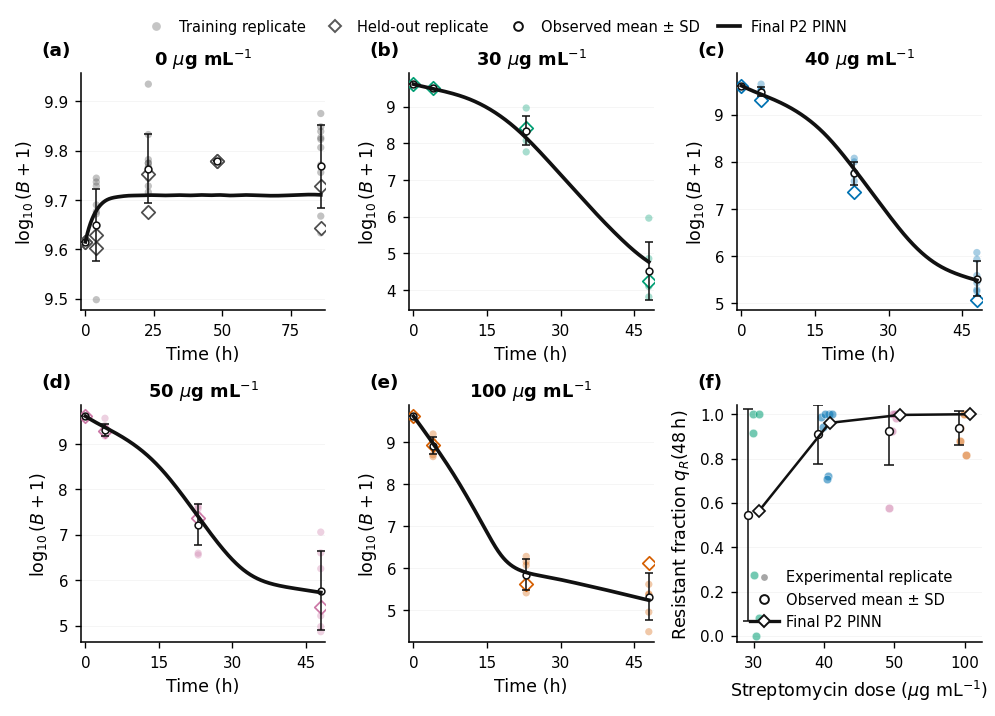

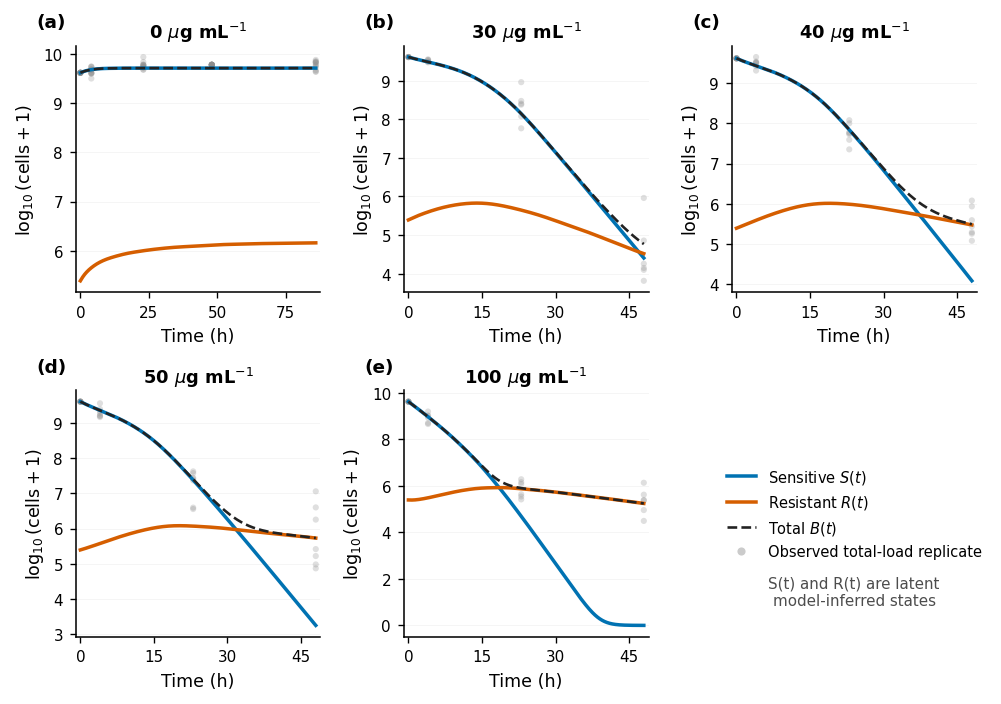

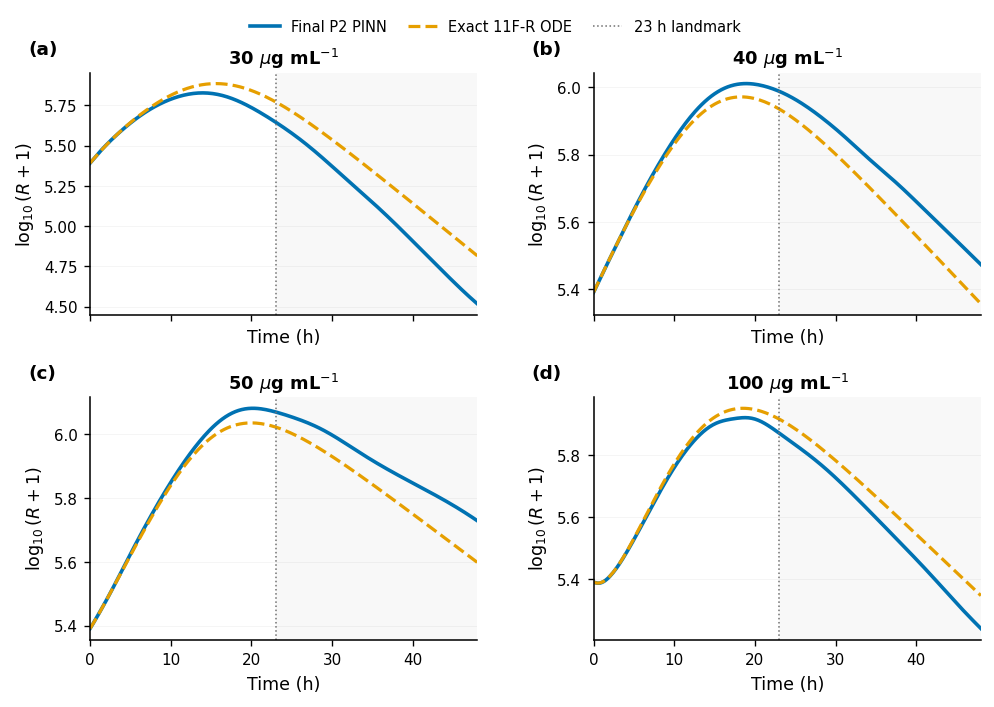

FINAL P2 PUBLICATION FIGURES GENERATED — NO TRAINING PERFORMED
Model source : INTEGRAL_REFINED_RESULT (P2)
Architecture : shared_dose_conditioned_hard_PINN_11FR
Figure folder: results\real_data\figures\publication_ready
Source data  : results\real_data\figures\publication_ready\source_data

MAIN
  - final_MAIN_real_data_P2_reconstruction_qR48.[png|pdf|svg]
SUPPLEMENTARY
  - final_SUPP_P2_latent_phenotype_trajectories.[png|pdf|svg]
  - final_SUPP_P2_PINN_vs_exact_11FR_R_0_48h.[png|pdf|svg]


In [60]:
# STANDALONE PUBLICATION-FIGURE CELL — FINAL R3.7/P2 REAL-DATA FIGURES
# =============================================================================
# Purpose
# -------
# Generate the FINAL publication-ready figures from the finalized P2 state model
# (INTEGRAL_REFINED_RESULT) without retraining or modifying any fitted parameter.
#
# Run this AFTER P2 has been completed/restored (preferably after Cell 13).
#
# Outputs
# -------
# MAIN FIGURE
#   Fig. R-main: final P2 total-load reconstruction across five environments
#               + 48-h resistant-fraction reconstruction.
#
# SUPPLEMENTARY FIGURES
#   Fig. S-R1: final P2 latent sensitive/resistant/total trajectories.
#   Fig. S-R2: final P2 PINN vs same-parameter exact 11F-R ODE for R(t), 0-48 h.
#
# Every figure is saved as PNG (600 dpi), PDF, and SVG. Source-data CSVs are
# also exported for reproducibility.
# =============================================================================

from pathlib import Path
import math
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator

# =============================================================================
# 0. REQUIRED FINAL OBJECTS / SAFETY GUARDS
# =============================================================================

_REQUIRED = [
    "BASE_BUNDLE",
    "q48",
    "INTEGRAL_REFINED_RESULT",
    "predict_numpy",
    "exact_ode_consistency_audit",
]

_missing = [name for name in _REQUIRED if name not in globals()]
if _missing:
    raise RuntimeError(
        "Publication-figure cell requires the finalized real-data workflow.\n"
        f"Missing globals: {_missing}\n"
        "Run/restore the final P2 analysis before this cell."
    )

if bool(globals().get("QUICK_MODE", False)):
    raise RuntimeError(
        "Do not generate manuscript figures from QUICK_MODE results. "
        "Use the FINAL run (QUICK_MODE=False)."
    )

FINAL_RESULT_FIG = INTEGRAL_REFINED_RESULT
FINAL_MODEL_FIG = FINAL_RESULT_FIG.model
EXPECTED_ARCHITECTURE_FIG = "shared_dose_conditioned_hard_PINN_11FR"

if getattr(FINAL_MODEL_FIG, "architecture_name", None) != EXPECTED_ARCHITECTURE_FIG:
    raise RuntimeError(
        "Unexpected model architecture for publication figures: "
        f"{getattr(FINAL_MODEL_FIG, 'architecture_name', None)!r}"
    )

# Save into a dedicated subfolder so old notebook figures are never overwritten.
if "FIGURE_DIR" in globals():
    PUB_FIG_DIR = Path(FIGURE_DIR) / "publication_ready"
elif "OUTPUT_ROOT" in globals():
    PUB_FIG_DIR = Path(OUTPUT_ROOT) / "figures" / "publication_ready"
else:
    PUB_FIG_DIR = Path.cwd() / "publication_ready"

PUB_DATA_DIR = PUB_FIG_DIR / "source_data"
PUB_FIG_DIR.mkdir(parents=True, exist_ok=True)
PUB_DATA_DIR.mkdir(parents=True, exist_ok=True)

RUN_PREFIX = str(globals().get("RUN_LABEL", "final"))

# =============================================================================
# 1. PUBLICATION STYLE
# =============================================================================
# Compact two-column-paper style. Vector outputs preserve text/line quality.
# =============================================================================

PUB_STYLE = {
    "figure.dpi": 140,
    "savefig.dpi": 600,
    "font.family": "sans-serif",
    "font.size": 8.5,
    "axes.labelsize": 9.0,
    "axes.titlesize": 9.2,
    "legend.fontsize": 7.5,
    "xtick.labelsize": 7.8,
    "ytick.labelsize": 7.8,
    "axes.linewidth": 0.8,
    "lines.linewidth": 1.7,
    "xtick.major.width": 0.7,
    "ytick.major.width": 0.7,
    "xtick.major.size": 3.0,
    "ytick.major.size": 3.0,
    "legend.frameon": False,
    "axes.unicode_minus": False,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
}

# Colorblind-friendly dose colors. Model/state colors remain consistent across figures.
DOSE_COLORS_PUB = {
    0.0: "#4D4D4D",
    30.0: "#009E73",
    40.0: "#0072B2",
    50.0: "#CC79A7",
    100.0: "#D55E00",
}
MODEL_COLOR_PUB = "#111111"
SENSITIVE_COLOR_PUB = "#0072B2"
RESISTANT_COLOR_PUB = "#D55E00"
TOTAL_COLOR_PUB = "#222222"
ODE_COLOR_PUB = "#E69F00"
OBS_MEAN_COLOR_PUB = "#111111"

DOSES_ALL_PUB = [float(d) for d in BASE_BUNDLE.doses]
DOSES_TREATED_PUB = [30.0, 40.0, 50.0, 100.0]


def _save_pubfig(fig, stem):
    """Save PNG/PDF/SVG publication versions without overwriting notebook figures."""
    clean = stem.strip().replace(" ", "_")
    fig.savefig(
        PUB_FIG_DIR / f"{clean}.png",
        dpi=600,
        bbox_inches="tight",
        facecolor="white",
    )
    fig.savefig(
        PUB_FIG_DIR / f"{clean}.pdf",
        bbox_inches="tight",
        facecolor="white",
    )
    fig.savefig(
        PUB_FIG_DIR / f"{clean}.svg",
        bbox_inches="tight",
        facecolor="white",
    )


def _clean_axis(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(direction="out")
    ax.grid(axis="y", linewidth=0.45, alpha=0.14)


def _panel_label(ax, label):
    ax.text(
        -0.16,
        1.06,
        label,
        transform=ax.transAxes,
        ha="left",
        va="bottom",
        fontsize=9.5,
        fontweight="bold",
    )


def _dose_title(dose):
    return rf"{dose:g} $\mu$g mL$^{{-1}}$"


def _observed_horizon(dose):
    dose_df = BASE_BUNDLE.total.loc[
        BASE_BUNDLE.total["dose_ug_ml"] == float(dose)
    ]
    if dose_df.empty:
        raise RuntimeError(f"No total-load observations found for dose {dose:g}.")
    return float(dose_df["time_h"].max())


# =============================================================================
# 2. MAIN FIGURE — FINAL P2 RECONSTRUCTION + qR(48 h)
# =============================================================================
# Panels (a-e): observed total-load data and final P2 PINN reconstruction.
# Panel (f): observed replicate qR(48 h), observed mean±SD, and final P2 prediction.
#
# Important design choice:
#   Each total-load panel ends at that environment's actual observed horizon.
#   Therefore the treated panels stop at 48 h and do NOT visually mix R3.7
#   reconstruction with the independent R3.10 post-48 h forecast experiment.
# =============================================================================

with mpl.rc_context(PUB_STYLE):
    fig, axes = plt.subplots(
        2,
        3,
        figsize=(7.15, 5.05),
        constrained_layout=False,
    )
    axes = axes.ravel()

    main_total_source_rows = []

    for idx, dose in enumerate(DOSES_ALL_PUB):
        ax = axes[idx]
        dose = float(dose)
        dose_df = BASE_BUNDLE.total.loc[
            BASE_BUNDLE.total["dose_ug_ml"] == dose
        ].copy()

        horizon = _observed_horizon(dose)
        grid = np.linspace(0.0, horizon, 600)
        pred = predict_numpy(FINAL_MODEL_FIG, dose, grid)

        train_df = dose_df.loc[dose_df["split"] == "train"]
        val_df = dose_df.loc[dose_df["split"] == "val"]

        # Training replicates: faint filled circles.
        ax.scatter(
            train_df["time_h"],
            train_df["log10_population_plus1"],
            s=14,
            color=DOSE_COLORS_PUB[dose],
            alpha=0.34,
            edgecolor="none",
            zorder=2,
        )

        # Held-out validation populations: open diamonds.
        ax.scatter(
            val_df["time_h"],
            val_df["log10_population_plus1"],
            s=24,
            marker="D",
            facecolor="white",
            edgecolor=DOSE_COLORS_PUB[dose],
            linewidth=0.9,
            zorder=4,
        )

        # Observed mean ± sample SD at each time.
        stats = (
            dose_df.groupby("time_h", as_index=False)["log10_population_plus1"]
            .agg(["mean", "std"])
            .reset_index()
        )
        # pandas versions differ slightly in groupby output naming; normalize here.
        if "time_h" not in stats.columns:
            stats = stats.rename(columns={stats.columns[0]: "time_h"})

        ax.errorbar(
            stats["time_h"],
            stats["mean"],
            yerr=stats["std"],
            fmt="o",
            ms=3.5,
            mfc="white",
            mec=OBS_MEAN_COLOR_PUB,
            mew=0.8,
            ecolor=OBS_MEAN_COLOR_PUB,
            elinewidth=0.8,
            capsize=2.0,
            capthick=0.7,
            zorder=5,
        )

        # Final P2 trajectory.
        ax.plot(
            pred["time_h"],
            pred["log10_total_plus1"],
            color=MODEL_COLOR_PUB,
            linewidth=1.9,
            zorder=6,
        )

        ax.set_title(_dose_title(dose), pad=4.0, fontweight="bold")
        ax.set_xlabel("Time (h)")
        ax.set_ylabel(r"$\log_{10}(B+1)$")
        ax.set_xlim(-0.02 * max(horizon, 1.0), horizon * 1.02)
        ax.xaxis.set_major_locator(MaxNLocator(nbins=4, integer=True))
        _clean_axis(ax)
        _panel_label(ax, f"({chr(97 + idx)})")

        # Export source data for this panel.
        obs_export = dose_df[
            ["dose_ug_ml", "time_h", "log10_population_plus1", "split"]
        ].copy()
        obs_export["series"] = "observed_replicate"
        obs_export["value"] = obs_export["log10_population_plus1"]
        main_total_source_rows.append(
            obs_export[["dose_ug_ml", "time_h", "series", "split", "value"]]
        )

        pred_export = pd.DataFrame(
            {
                "dose_ug_ml": dose,
                "time_h": pred["time_h"].to_numpy(float),
                "series": "final_P2_PINN",
                "split": "model",
                "value": pred["log10_total_plus1"].to_numpy(float),
            }
        )
        main_total_source_rows.append(pred_export)

    # -------------------------------------------------------------------------
    # Panel (f): qR at 48 h
    # -------------------------------------------------------------------------
    ax = axes[5]
    rng = np.random.default_rng(20260822)
    x = np.arange(len(DOSES_TREATED_PUB), dtype=float)
    pred_q_values = []
    q_source_rows = []

    for j, dose in enumerate(DOSES_TREATED_PUB):
        obs = q48.loc[
            q48["dose_ug_ml"] == dose,
            "resistant_fraction_qR",
        ].to_numpy(float)

        if len(obs) == 0:
            raise RuntimeError(f"No qR(48 h) observations found for dose {dose:g}.")

        jitter = rng.normal(0.0, 0.045, size=len(obs))
        ax.scatter(
            np.full(len(obs), x[j]) + jitter,
            obs,
            s=19,
            color=DOSE_COLORS_PUB[dose],
            alpha=0.55,
            edgecolor="white",
            linewidth=0.35,
            zorder=2,
        )

        obs_mean = float(np.mean(obs))
        obs_sd = float(np.std(obs, ddof=1)) if len(obs) > 1 else 0.0
        ax.errorbar(
            x[j] - 0.08,
            obs_mean,
            yerr=obs_sd,
            fmt="o",
            ms=4.0,
            mfc="white",
            mec=OBS_MEAN_COLOR_PUB,
            mew=0.8,
            ecolor=OBS_MEAN_COLOR_PUB,
            elinewidth=0.8,
            capsize=2.5,
            zorder=4,
        )

        pred_q = float(
            predict_numpy(
                FINAL_MODEL_FIG,
                dose,
                np.array([48.0], dtype=float),
            )["resistant_fraction"].iloc[0]
        )
        pred_q_values.append(pred_q)

        for val in obs:
            q_source_rows.append(
                {
                    "dose_ug_ml": dose,
                    "series": "observed_replicate",
                    "qR_48h": float(val),
                }
            )
        q_source_rows.append(
            {
                "dose_ug_ml": dose,
                "series": "observed_mean",
                "qR_48h": obs_mean,
            }
        )
        q_source_rows.append(
            {
                "dose_ug_ml": dose,
                "series": "final_P2_PINN",
                "qR_48h": pred_q,
            }
        )

    ax.plot(
        x + 0.08,
        pred_q_values,
        color=MODEL_COLOR_PUB,
        linewidth=1.3,
        marker="D",
        markersize=4.2,
        markerfacecolor="white",
        markeredgecolor=MODEL_COLOR_PUB,
        markeredgewidth=0.9,
        zorder=5,
    )

    ax.set_xticks(x, ["30", "40", "50", "100"])
    ax.set_xlabel(r"Streptomycin dose ($\mu$g mL$^{-1}$)")
    ax.set_ylabel(r"Resistant fraction $q_R(48\,\mathrm{h})$")
    ax.set_ylim(-0.03, 1.04)
    _clean_axis(ax)
    _panel_label(ax, "(f)")

    q_legend = [
        Line2D(
            [0], [0], marker="o", ls="none", markersize=4.5,
            markerfacecolor="0.65", markeredgecolor="white",
            label="Experimental replicate",
        ),
        Line2D(
            [0], [0], marker="o", ls="none", markersize=4.5,
            markerfacecolor="white", markeredgecolor=OBS_MEAN_COLOR_PUB,
            label="Observed mean ± SD",
        ),
        Line2D(
            [0], [0], marker="D", color=MODEL_COLOR_PUB, markersize=4.5,
            markerfacecolor="white", label="Final P2 PINN",
        ),
    ]
    ax.legend(handles=q_legend, loc="lower left", handletextpad=0.5)

    # Figure-level legend for panels (a-e).
    load_legend = [
        Line2D(
            [0], [0], marker="o", ls="none", markersize=4.5,
            markerfacecolor="0.55", markeredgecolor="none", alpha=0.5,
            label="Training replicate",
        ),
        Line2D(
            [0], [0], marker="D", ls="none", markersize=4.5,
            markerfacecolor="white", markeredgecolor="0.35",
            label="Held-out replicate",
        ),
        Line2D(
            [0], [0], marker="o", ls="none", markersize=4.5,
            markerfacecolor="white", markeredgecolor=OBS_MEAN_COLOR_PUB,
            label="Observed mean ± SD",
        ),
        Line2D(
            [0], [0], color=MODEL_COLOR_PUB, lw=1.9,
            label="Final P2 PINN",
        ),
    ]
    fig.legend(
        handles=load_legend,
        loc="upper center",
        bbox_to_anchor=(0.5, 0.995),
        ncol=4,
        columnspacing=1.25,
        handlelength=1.5,
    )

    fig.subplots_adjust(
        left=0.085,
        right=0.985,
        bottom=0.095,
        top=0.90,
        wspace=0.34,
        hspace=0.40,
    )

    main_stem = f"{RUN_PREFIX}_MAIN_real_data_P2_reconstruction_qR48"
    _save_pubfig(fig, main_stem)
    plt.show()

# Save main-figure source data.
pd.concat(main_total_source_rows, ignore_index=True).to_csv(
    PUB_DATA_DIR / f"{RUN_PREFIX}_MAIN_total_load_source_data.csv",
    index=False,
)
pd.DataFrame(q_source_rows).to_csv(
    PUB_DATA_DIR / f"{RUN_PREFIX}_MAIN_qR48_source_data.csv",
    index=False,
)


# =============================================================================
# 3. SUPPLEMENTARY FIGURE S-R1 — FINAL P2 LATENT PHENOTYPE TRAJECTORIES
# =============================================================================
# These S(t) and R(t) curves are MODEL-INFERRED LATENT STATES. Only total-load
# observations are overlaid. Do not describe longitudinal S and R as measured.
# =============================================================================

with mpl.rc_context(PUB_STYLE):
    fig, axes = plt.subplots(
        2,
        3,
        figsize=(7.15, 4.85),
        constrained_layout=False,
    )
    axes = axes.ravel()

    latent_source_rows = []

    for idx, dose in enumerate(DOSES_ALL_PUB):
        ax = axes[idx]
        dose = float(dose)
        horizon = _observed_horizon(dose)
        grid = np.linspace(0.0, horizon, 600)
        pred = predict_numpy(FINAL_MODEL_FIG, dose, grid)

        ax.plot(
            grid,
            np.log10(pred["sensitive"].to_numpy(float) + 1.0),
            color=SENSITIVE_COLOR_PUB,
            linewidth=1.8,
            label=r"Sensitive $S(t)$",
        )
        ax.plot(
            grid,
            np.log10(pred["resistant"].to_numpy(float) + 1.0),
            color=RESISTANT_COLOR_PUB,
            linewidth=1.8,
            label=r"Resistant $R(t)$",
        )
        ax.plot(
            grid,
            pred["log10_total_plus1"].to_numpy(float),
            color=TOTAL_COLOR_PUB,
            linestyle="--",
            linewidth=1.35,
            label=r"Total $B(t)$",
        )

        dose_obs = BASE_BUNDLE.total.loc[
            BASE_BUNDLE.total["dose_ug_ml"] == dose
        ]
        ax.scatter(
            dose_obs["time_h"],
            dose_obs["log10_population_plus1"],
            s=10,
            color="0.55",
            alpha=0.28,
            edgecolor="none",
            zorder=1,
        )

        ax.set_title(_dose_title(dose), pad=4.0, fontweight="bold")
        ax.set_xlabel("Time (h)")
        ax.set_ylabel(r"$\log_{10}(\mathrm{cells}+1)$")
        ax.set_xlim(-0.02 * max(horizon, 1.0), horizon * 1.02)
        ax.xaxis.set_major_locator(MaxNLocator(nbins=4, integer=True))
        _clean_axis(ax)
        _panel_label(ax, f"({chr(97 + idx)})")

        latent_source_rows.append(
            pd.DataFrame(
                {
                    "dose_ug_ml": dose,
                    "time_h": grid,
                    "log10_S_plus1": np.log10(pred["sensitive"].to_numpy(float) + 1.0),
                    "log10_R_plus1": np.log10(pred["resistant"].to_numpy(float) + 1.0),
                    "log10_B_plus1": pred["log10_total_plus1"].to_numpy(float),
                }
            )
        )

    # Sixth slot is intentionally used for a clean legend and interpretation note.
    axes[5].axis("off")
    latent_legend = [
        Line2D([0], [0], color=SENSITIVE_COLOR_PUB, lw=1.8, label=r"Sensitive $S(t)$"),
        Line2D([0], [0], color=RESISTANT_COLOR_PUB, lw=1.8, label=r"Resistant $R(t)$"),
        Line2D([0], [0], color=TOTAL_COLOR_PUB, lw=1.35, ls="--", label=r"Total $B(t)$"),
        Line2D(
            [0], [0], marker="o", ls="none", markersize=4.2,
            markerfacecolor="0.55", markeredgecolor="none", alpha=0.45,
            label="Observed total-load replicate",
        ),
    ]
    axes[5].legend(
        handles=latent_legend,
        loc="center",
        frameon=False,
    )
    axes[5].text(
        0.5,
        0.18,
        "S(t) and R(t) are latent\nmodel-inferred states",
        ha="center",
        va="center",
        fontsize=7.8,
        color="0.30",
        transform=axes[5].transAxes,
    )

    fig.subplots_adjust(
        left=0.085,
        right=0.985,
        bottom=0.095,
        top=0.965,
        wspace=0.34,
        hspace=0.40,
    )

    latent_stem = f"{RUN_PREFIX}_SUPP_P2_latent_phenotype_trajectories"
    _save_pubfig(fig, latent_stem)
    plt.show()

pd.concat(latent_source_rows, ignore_index=True).to_csv(
    PUB_DATA_DIR / f"{RUN_PREFIX}_SUPP_latent_state_source_data.csv",
    index=False,
)


# =============================================================================
# 4. SUPPLEMENTARY FIGURE S-R2 — FINAL P2 PINN vs SAME-PARAMETER EXACT 11F-R ODE
# =============================================================================
# Full treated observed horizon only (0-48 h). This replaces the old 0-4 h
# diagnostic figure. It uses the FINAL P2 neural state model and independently
# integrates the SAME fitted 11F-R ODE parameters through the existing audited
# exact_ode_consistency_audit() helper.
# =============================================================================

consistency_frames = []

for dose in DOSES_TREATED_PUB:
    # Dense 0-48 h grid, with 23 h included exactly because the later interval
    # was explicitly audited in the final workflow.
    check_times = np.unique(
        np.concatenate(
            [
                np.linspace(0.0, 48.0, 241),
                np.array([23.0, 48.0], dtype=float),
            ]
        )
    )

    detail, _summary = exact_ode_consistency_audit(
        FINAL_MODEL_FIG,
        BASE_BUNDLE,
        doses=[float(dose)],
        check_times=check_times,
    )
    consistency_frames.append(detail.copy())

consistency_pub = pd.concat(consistency_frames, ignore_index=True)

with mpl.rc_context(PUB_STYLE):
    fig, axes = plt.subplots(
        2,
        2,
        figsize=(7.15, 5.0),
        constrained_layout=False,
        sharex=True,
    )
    axes = axes.ravel()

    for idx, (ax, dose) in enumerate(zip(axes, DOSES_TREATED_PUB)):
        subset = (
            consistency_pub.loc[consistency_pub["dose_ug_ml"] == dose]
            .sort_values("time_h")
        )

        ax.plot(
            subset["time_h"],
            subset["PINN_log10_R_plus1"],
            color=SENSITIVE_COLOR_PUB,
            linewidth=1.85,
            label="Final P2 PINN",
        )
        ax.plot(
            subset["time_h"],
            subset["ODE_log10_R_plus1"],
            color=ODE_COLOR_PUB,
            linewidth=1.65,
            linestyle="--",
            label="Exact 11F-R ODE",
        )

        # Highlight the interval in which the earlier consistency problem was largest.
        ax.axvspan(23.0, 48.0, color="0.5", alpha=0.055, linewidth=0)
        ax.axvline(23.0, color="0.45", linestyle=":", linewidth=0.8)

        ax.set_title(_dose_title(dose), pad=4.0, fontweight="bold")
        ax.set_xlabel("Time (h)")
        ax.set_ylabel(r"$\log_{10}(R+1)$")
        ax.set_xlim(0.0, 48.0)
        ax.xaxis.set_major_locator(MaxNLocator(nbins=5, integer=True))
        _clean_axis(ax)
        _panel_label(ax, f"({chr(97 + idx)})")

    consistency_legend = [
        Line2D([0], [0], color=SENSITIVE_COLOR_PUB, lw=1.85, label="Final P2 PINN"),
        Line2D([0], [0], color=ODE_COLOR_PUB, lw=1.65, ls="--", label="Exact 11F-R ODE"),
        Line2D([0], [0], color="0.45", lw=0.8, ls=":", label="23 h landmark"),
    ]
    fig.legend(
        handles=consistency_legend,
        loc="upper center",
        bbox_to_anchor=(0.5, 0.995),
        ncol=3,
        columnspacing=1.4,
        handlelength=2.0,
    )

    fig.subplots_adjust(
        left=0.095,
        right=0.985,
        bottom=0.09,
        top=0.90,
        wspace=0.30,
        hspace=0.34,
    )

    consistency_stem = f"{RUN_PREFIX}_SUPP_P2_PINN_vs_exact_11FR_R_0_48h"
    _save_pubfig(fig, consistency_stem)
    plt.show()

consistency_pub.to_csv(
    PUB_DATA_DIR / f"{RUN_PREFIX}_SUPP_PINN_exact_ODE_source_data.csv",
    index=False,
)


# =============================================================================
# 5. FINAL REPORT
# =============================================================================

print("=" * 100)
print("FINAL P2 PUBLICATION FIGURES GENERATED — NO TRAINING PERFORMED")
print("=" * 100)
print("Model source : INTEGRAL_REFINED_RESULT (P2)")
print("Architecture :", FINAL_MODEL_FIG.architecture_name)
print("Figure folder:", PUB_FIG_DIR)
print("Source data  :", PUB_DATA_DIR)
print()
print("MAIN")
print("  -", f"{RUN_PREFIX}_MAIN_real_data_P2_reconstruction_qR48.[png|pdf|svg]")
print("SUPPLEMENTARY")
print("  -", f"{RUN_PREFIX}_SUPP_P2_latent_phenotype_trajectories.[png|pdf|svg]")
print("  -", f"{RUN_PREFIX}_SUPP_P2_PINN_vs_exact_11FR_R_0_48h.[png|pdf|svg]")
print("=" * 100)

cell 9 + cell 10 figures

Saved: results\real_data\figures\publication_ready_R38_R39\final_MAIN_R38_R39_generalization_and_design_sensitivity.png
Saved: results\real_data\figures\publication_ready_R38_R39\final_MAIN_R38_R39_generalization_and_design_sensitivity.pdf
Saved: results\real_data\figures\publication_ready_R38_R39\final_MAIN_R38_R39_generalization_and_design_sensitivity.svg


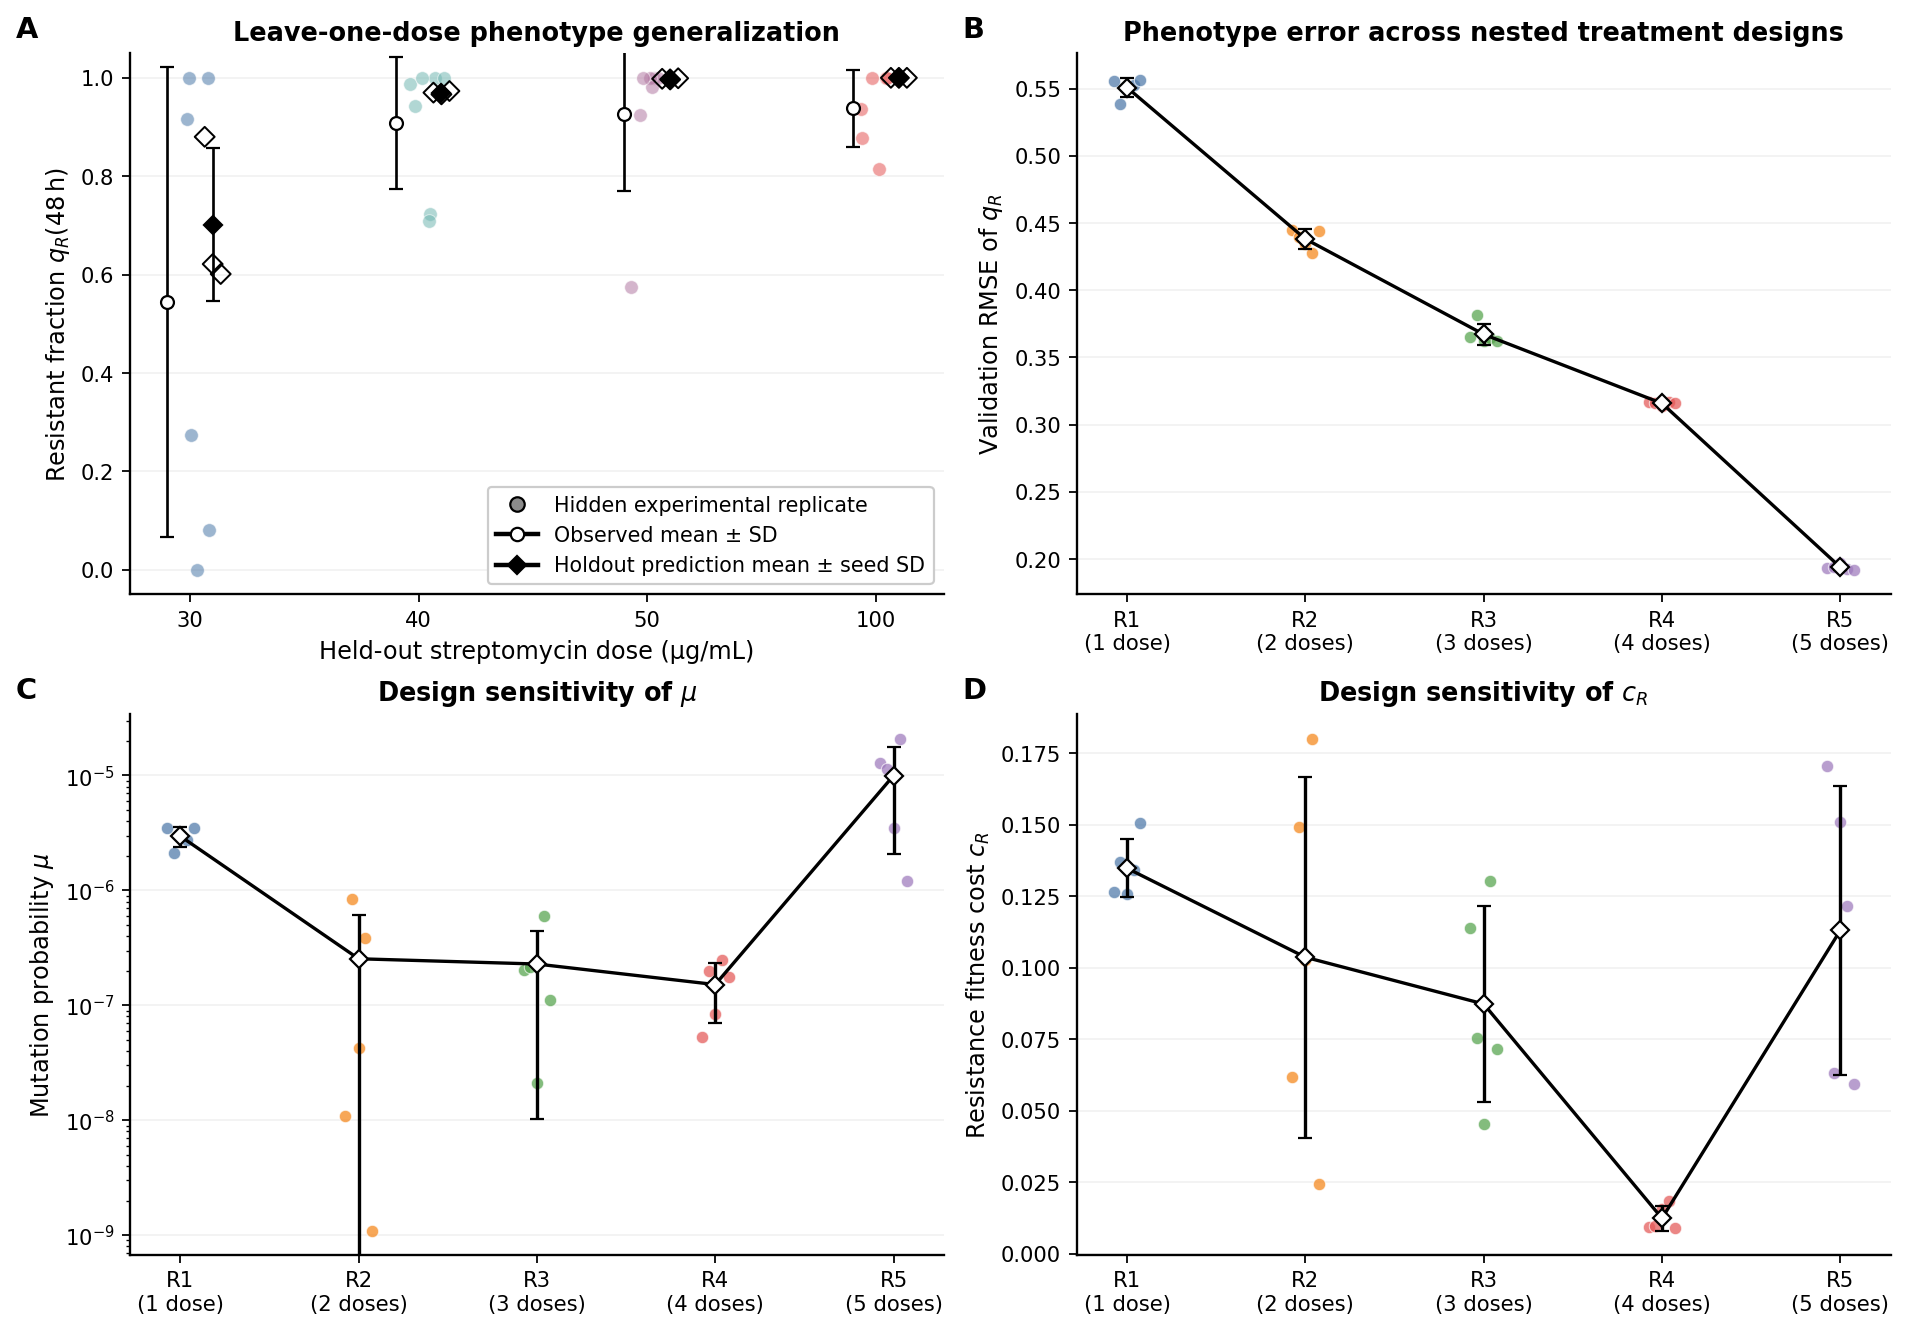

Saved: results\real_data\figures\publication_ready_R38_R39\final_SUPP_R38_full_holdout_context.png
Saved: results\real_data\figures\publication_ready_R38_R39\final_SUPP_R38_full_holdout_context.pdf
Saved: results\real_data\figures\publication_ready_R38_R39\final_SUPP_R38_full_holdout_context.svg


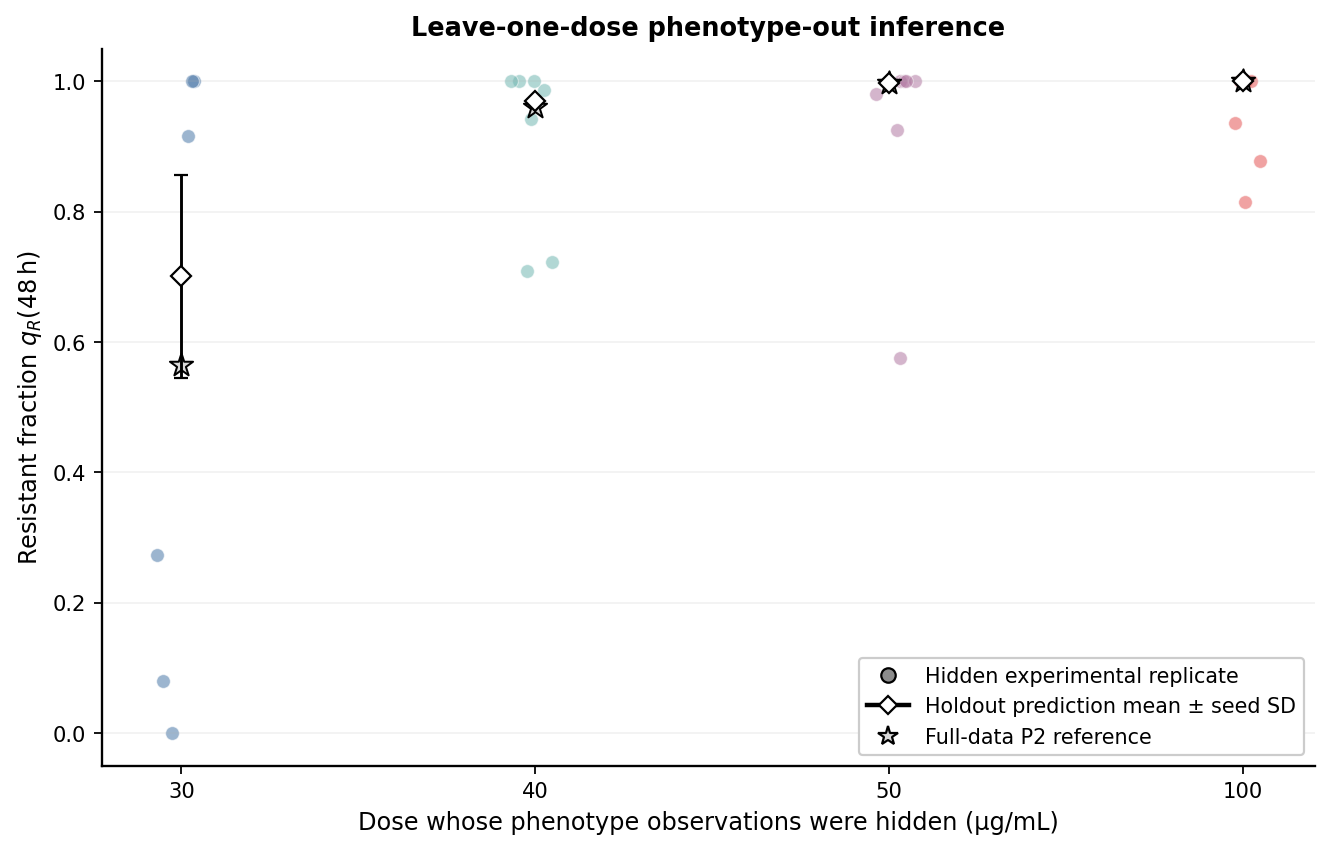

Saved: results\real_data\figures\publication_ready_R38_R39\final_SUPP_R39_core_shared_parameters.png
Saved: results\real_data\figures\publication_ready_R38_R39\final_SUPP_R39_core_shared_parameters.pdf
Saved: results\real_data\figures\publication_ready_R38_R39\final_SUPP_R39_core_shared_parameters.svg


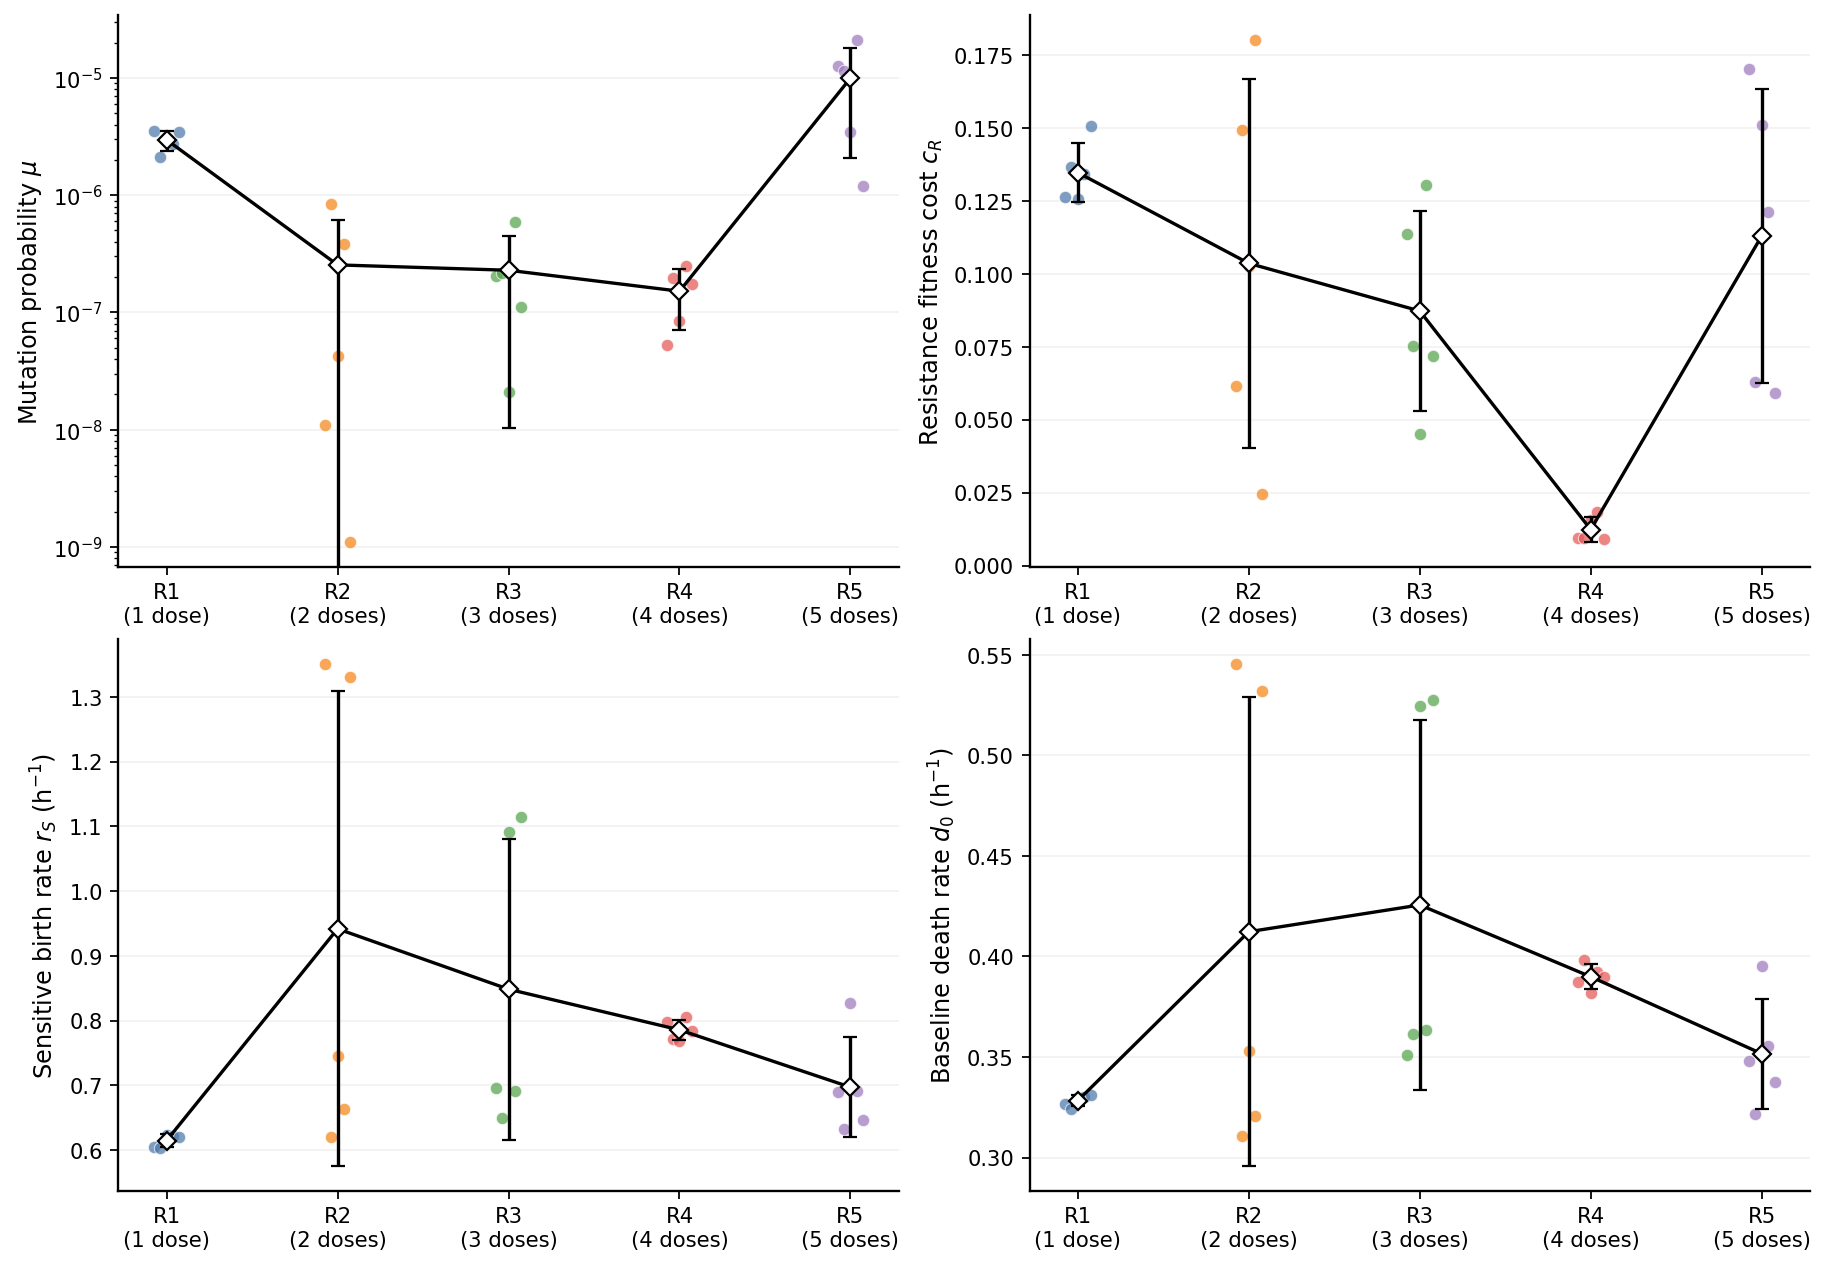

Saved: results\real_data\figures\publication_ready_R38_R39\final_SUPP_R39_q0_and_additional_shared_parameters.png
Saved: results\real_data\figures\publication_ready_R38_R39\final_SUPP_R39_q0_and_additional_shared_parameters.pdf
Saved: results\real_data\figures\publication_ready_R38_R39\final_SUPP_R39_q0_and_additional_shared_parameters.svg


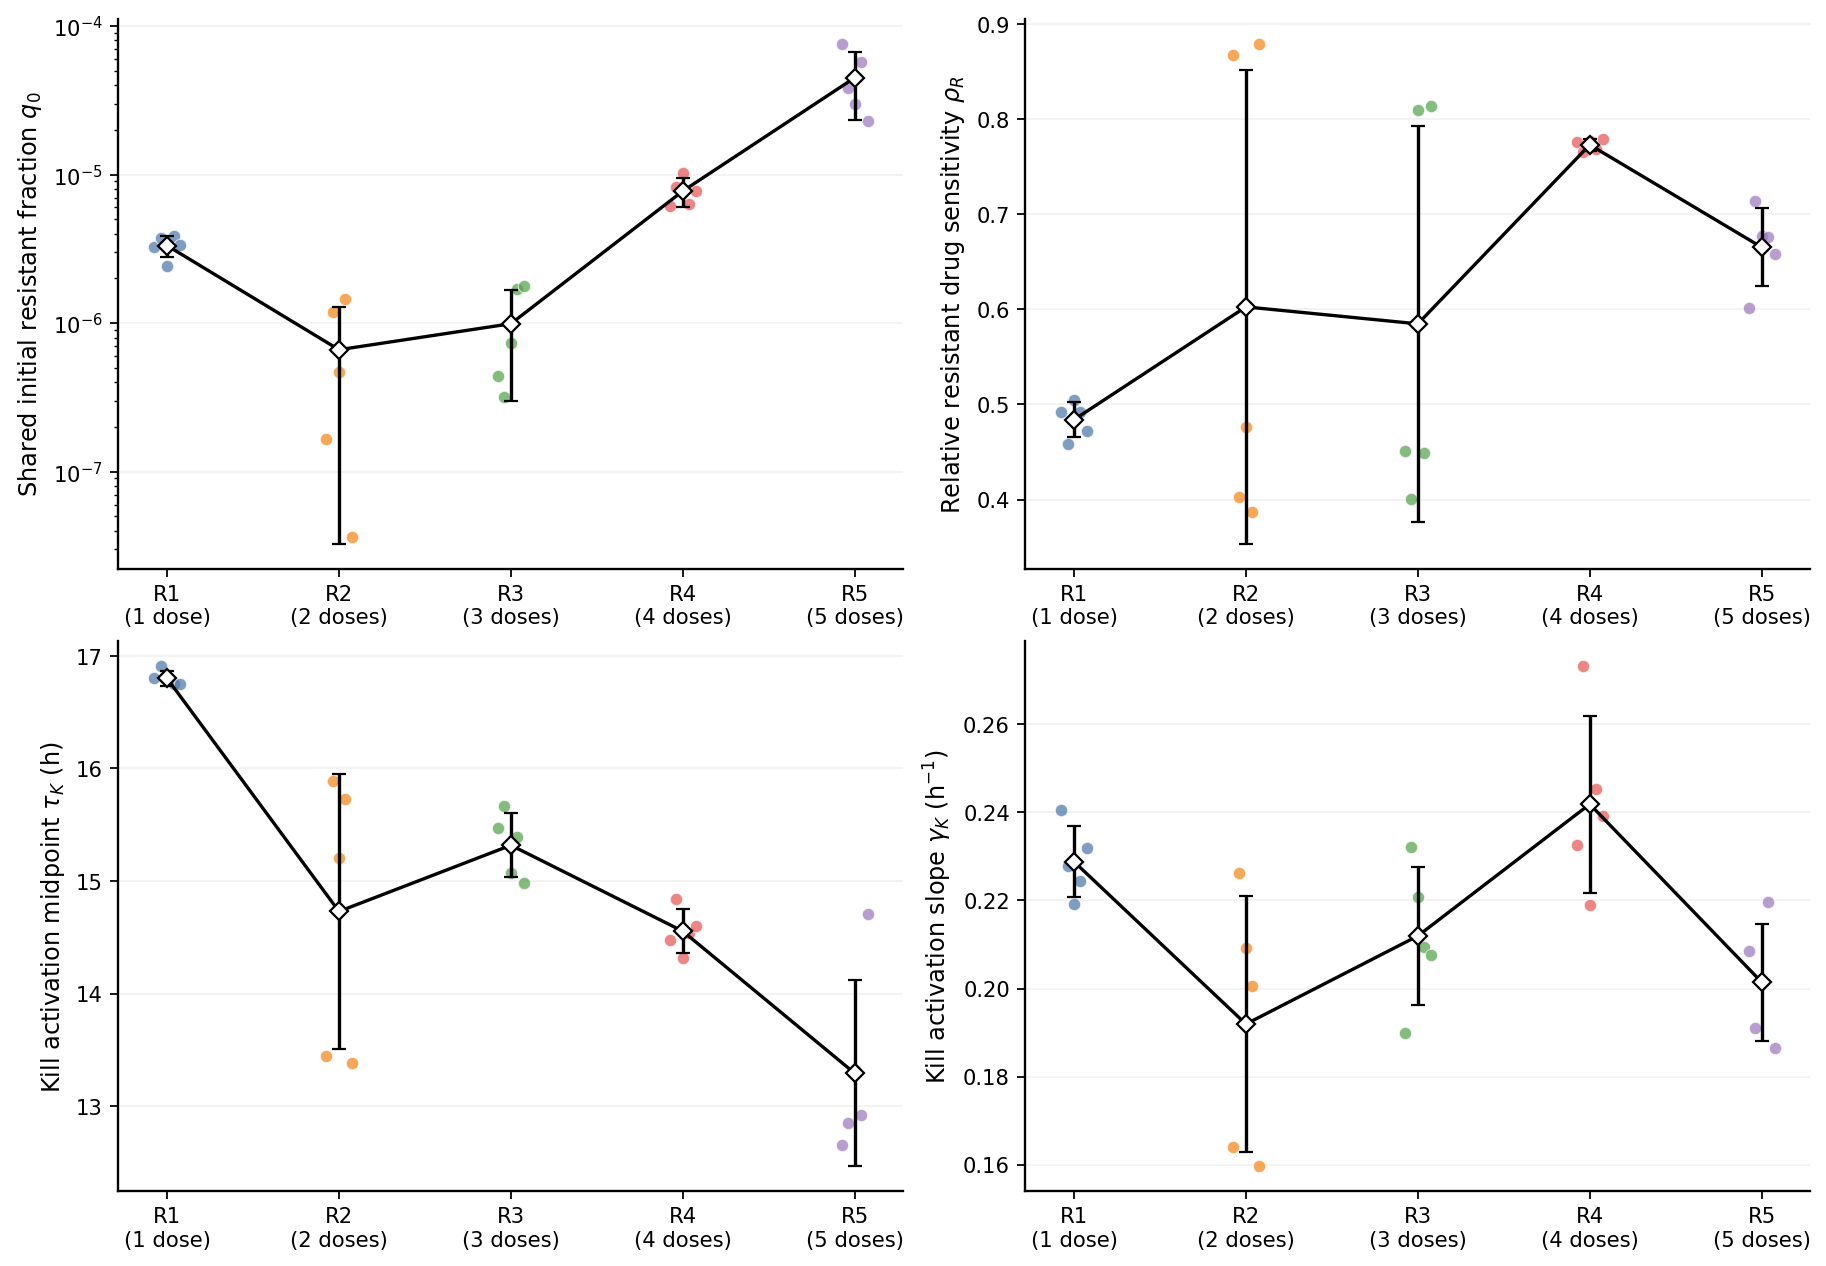

Saved: results\real_data\figures\publication_ready_R38_R39\final_SUPP_R39_validation_and_physics_metrics.png
Saved: results\real_data\figures\publication_ready_R38_R39\final_SUPP_R39_validation_and_physics_metrics.pdf
Saved: results\real_data\figures\publication_ready_R38_R39\final_SUPP_R39_validation_and_physics_metrics.svg


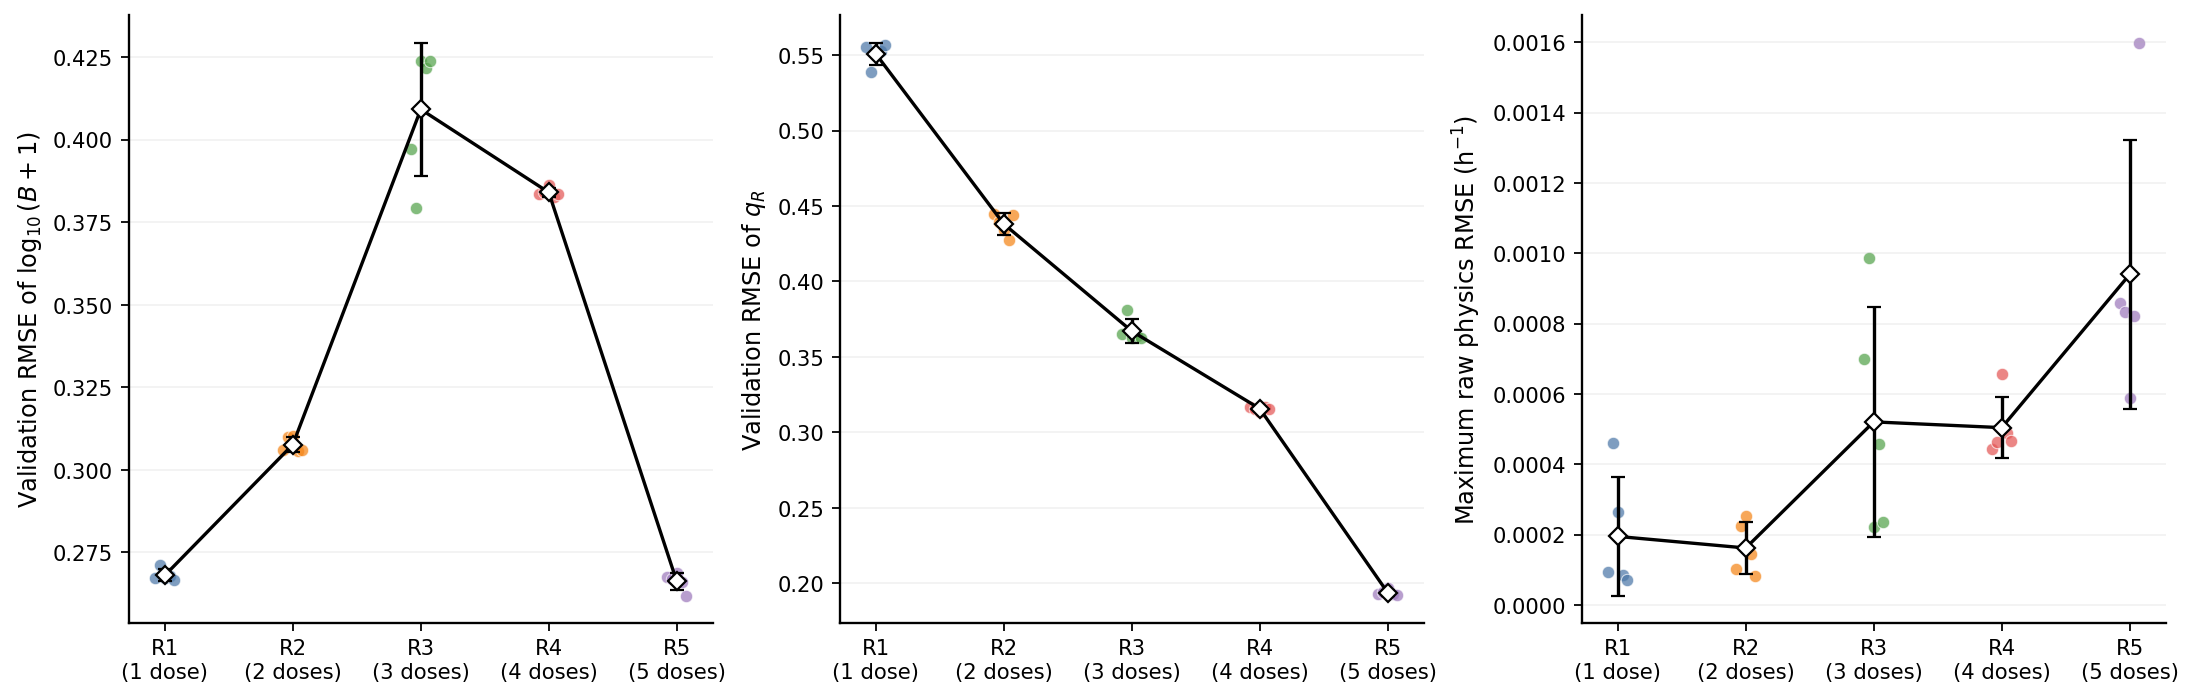

Saved: results\real_data\figures\publication_ready_R38_R39\final_SUPP_R39_dose_specific_killing_estimates.png
Saved: results\real_data\figures\publication_ready_R38_R39\final_SUPP_R39_dose_specific_killing_estimates.pdf
Saved: results\real_data\figures\publication_ready_R38_R39\final_SUPP_R39_dose_specific_killing_estimates.svg


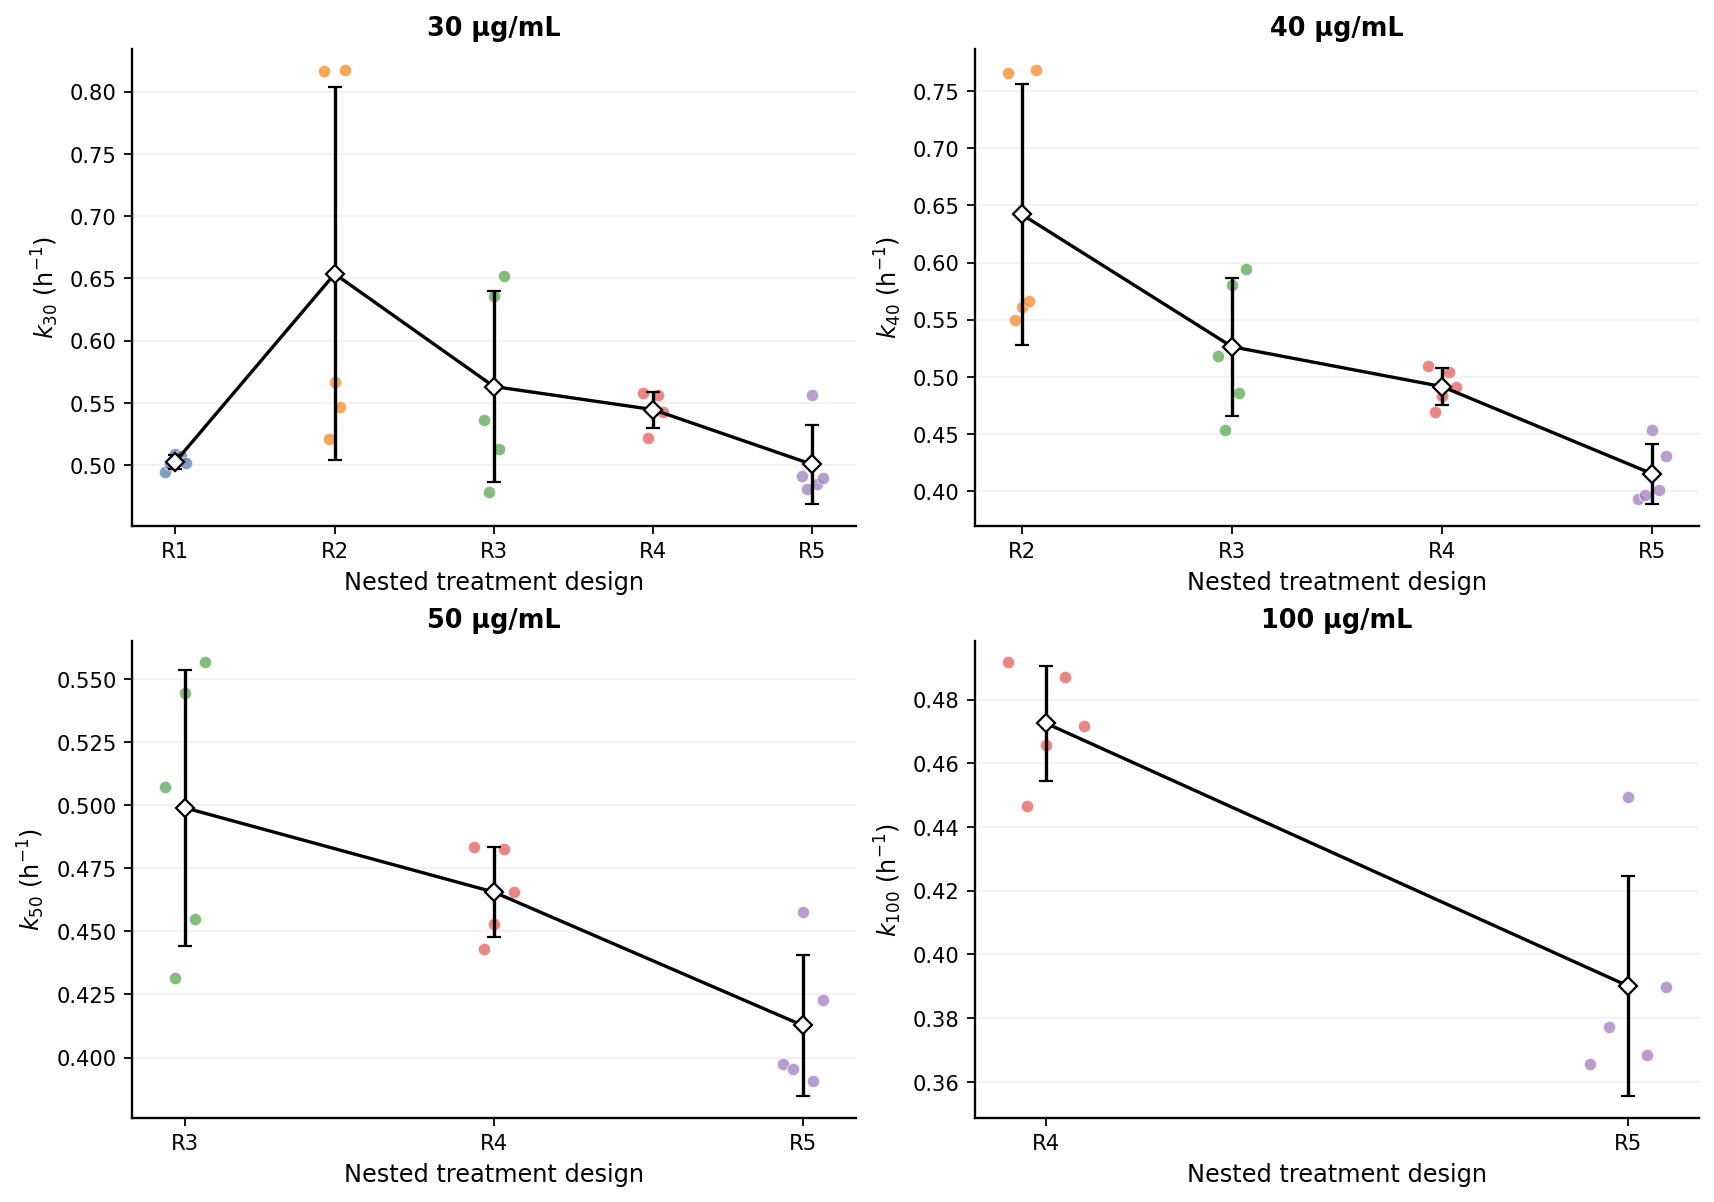


FINAL R3.8 + R3.9 PUBLICATION FIGURES GENERATED — NO TRAINING PERFORMED
Source tables : results\real_data\tables
Figure folder : results\real_data\figures\publication_ready_R38_R39

MAIN
  final_MAIN_R38_R39_generalization_and_design_sensitivity.[png|pdf|svg]

SUPPLEMENTARY
  final_SUPP_R38_full_holdout_context.[png|pdf|svg]
  final_SUPP_R39_core_shared_parameters.[png|pdf|svg]
  final_SUPP_R39_q0_and_additional_shared_parameters.[png|pdf|svg]
  final_SUPP_R39_validation_and_physics_metrics.[png|pdf|svg]
  final_SUPP_R39_dose_specific_killing_estimates.[png|pdf|svg]


In [61]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# =============================================================================
# STANDALONE PUBLICATION FIGURES — R3.8 + R3.9
# =============================================================================
# PURPOSE
#   Generate the final main and supplementary figures from the already-saved
#   Cell 9 (R3.8) and Cell 10 (R3.9) outputs.
#
# IMPORTANT
#   - NO model training
#   - NO P1/P2 refinement
#   - NO optimizer
#   - NO checkpoint modification
#   - Reads CSV files only
# =============================================================================

# -----------------------------------------------------------------------------
# 0. PATHS
# -----------------------------------------------------------------------------
# repository root (works when started from the repo root or from notebooks/)
REPO_ROOT = Path.cwd().parent if Path.cwd().name.lower() == "notebooks" else Path.cwd()
DATA_DIR = REPO_ROOT / "data" / "real"
RESULTS_ROOT = REPO_ROOT / "results" / "real_data"
TABLE_DIR = RESULTS_ROOT / "tables"
OUT_DIR = RESULTS_ROOT / "figures" / "publication_ready_R38_R39"
OUT_DIR.mkdir(parents=True, exist_ok=True)

RUN_LABEL = "final"
R38_TAG = "R38_11FR_P1P2_shared_leave_one_dose_qR"
R39_TAG = "R39_11FR_nested_treatment_diversity_BASE_ONLY"

# Original linked 48-h phenotype data; used only to draw experimental replicates.
Q48_PATH = DATA_DIR / "Ramsayer_qR_48h_EXACT_linked.csv"

R38_RAW_PATH = TABLE_DIR / f"{RUN_LABEL}_{R38_TAG}_raw.csv"
R38_SUMMARY_PATH = TABLE_DIR / f"{RUN_LABEL}_{R38_TAG}_summary.csv"
R38_OVERALL_PATH = TABLE_DIR / f"{RUN_LABEL}_{R38_TAG}_overall_summary.csv"

R39_RAW_PATH = TABLE_DIR / f"{RUN_LABEL}_{R39_TAG}_raw.csv"
R39_SUMMARY_PATH = TABLE_DIR / f"{RUN_LABEL}_{R39_TAG}_summary.csv"
R39_SHARED_LONG_PATH = TABLE_DIR / f"{RUN_LABEL}_{R39_TAG}_shared_parameter_long.csv"
R39_DOSE_K_PATH = TABLE_DIR / f"{RUN_LABEL}_{R39_TAG}_dose_specific_k_summary.csv"
R39_TRANSITION_PATH = TABLE_DIR / f"{RUN_LABEL}_{R39_TAG}_design_transition_changes.csv"

required_files = [
    Q48_PATH,
    R38_RAW_PATH,
    R38_SUMMARY_PATH,
    R39_RAW_PATH,
    R39_SUMMARY_PATH,
    R39_DOSE_K_PATH,
]
missing = [str(p) for p in required_files if not p.exists()]
if missing:
    raise FileNotFoundError(
        "Required completed-analysis file(s) are missing:\n" + "\n".join(missing)
    )

# -----------------------------------------------------------------------------
# 1. LOAD COMPLETED RESULTS
# -----------------------------------------------------------------------------
q48 = pd.read_csv(Q48_PATH)
r38_raw = pd.read_csv(R38_RAW_PATH)
r38_summary = pd.read_csv(R38_SUMMARY_PATH)
r39_raw = pd.read_csv(R39_RAW_PATH)
r39_summary = pd.read_csv(R39_SUMMARY_PATH)
r39_dose_k = pd.read_csv(R39_DOSE_K_PATH)

r39_shared_long = (
    pd.read_csv(R39_SHARED_LONG_PATH)
    if R39_SHARED_LONG_PATH.exists()
    else None
)
r39_transition = (
    pd.read_csv(R39_TRANSITION_PATH)
    if R39_TRANSITION_PATH.exists()
    else None
)

# -----------------------------------------------------------------------------
# 2. BASIC AUDITS — plotting only; no fitting
# -----------------------------------------------------------------------------
expected_r38 = {(d, s) for d in [30.0, 40.0, 50.0, 100.0]
                for s in sorted(r38_raw["seed"].astype(int).unique())}
observed_r38 = {
    (float(r.held_dose_ug_ml), int(r.seed))
    for r in r38_raw.itertuples()
}
if not expected_r38.issubset(observed_r38):
    raise RuntimeError("R3.8 saved results are incomplete for the available seed set.")

expected_r39 = {(d, s) for d in ["R1", "R2", "R3", "R4", "R5"]
                for s in sorted(r39_raw["seed"].astype(int).unique())}
observed_r39 = {(str(r.design), int(r.seed)) for r in r39_raw.itertuples()}
if not expected_r39.issubset(observed_r39):
    raise RuntimeError("R3.9 saved results are incomplete for the available seed set.")

# -----------------------------------------------------------------------------
# 3. PLOT SETTINGS
# -----------------------------------------------------------------------------
TREATED_DOSES = [30.0, 40.0, 50.0, 100.0]
DESIGN_ORDER = ["R1", "R2", "R3", "R4", "R5"]
DESIGN_LABELS = {
    "R1": "R1\n(1 dose)",
    "R2": "R2\n(2 doses)",
    "R3": "R3\n(3 doses)",
    "R4": "R4\n(4 doses)",
    "R5": "R5\n(5 doses)",
}

DOSE_COLORS = {
    30.0: "#4C78A8",
    40.0: "#72B7B2",
    50.0: "#B279A2",
    100.0: "#E45756",
}
DESIGN_COLORS = {
    "R1": "#4C78A8",
    "R2": "#F58518",
    "R3": "#54A24B",
    "R4": "#E45756",
    "R5": "#9D79BC",
}

PARAMETER_LABELS = {
    "mutation_probability": r"Mutation probability $\mu$",
    "resistance_fitness_cost": r"Resistance fitness cost $c_R$",
    "sensitive_birth_rate_per_h": r"Sensitive birth rate $r_S$ (h$^{-1}$)",
    "baseline_death_rate_per_h": r"Baseline death rate $d_0$ (h$^{-1}$)",
    "initial_resistant_fraction_shared": r"Shared initial resistant fraction $q_0$",
    "resistant_relative_drug_sensitivity": r"Relative resistant drug sensitivity $\rho_R$",
    "kill_activation_onset_h": r"Kill activation midpoint $\tau_K$ (h)",
    "kill_activation_per_h": r"Kill activation slope $\gamma_K$ (h$^{-1}$)",
    "kill_30_per_h": r"$k_{30}$ (h$^{-1}$)",
    "kill_40_per_h": r"$k_{40}$ (h$^{-1}$)",
    "kill_50_per_h": r"$k_{50}$ (h$^{-1}$)",
    "kill_100_per_h": r"$k_{100}$ (h$^{-1}$)",
}

plt.rcParams.update({
    "font.size": 10.5,
    "axes.titlesize": 11.5,
    "axes.labelsize": 10.8,
    "legend.fontsize": 9.3,
    "xtick.labelsize": 9.5,
    "ytick.labelsize": 9.5,
    "figure.dpi": 160,
    "savefig.dpi": 600,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

# -----------------------------------------------------------------------------
# 4. HELPERS
# -----------------------------------------------------------------------------
def save_all(fig, stem):
    for ext in ["png", "pdf", "svg"]:
        path = OUT_DIR / f"{stem}.{ext}"
        fig.savefig(path, bbox_inches="tight")
        print("Saved:", path)


def clean_axis(ax, grid_axis="y"):
    ax.grid(axis=grid_axis, alpha=0.18, linewidth=0.7)
    ax.spines[["top", "right"]].set_visible(False)


def panel_label(ax, text):
    ax.text(
        -0.14, 1.07, text,
        transform=ax.transAxes,
        fontweight="bold",
        fontsize=13,
        ha="left",
        va="top",
    )


def design_scatter_summary(
    ax,
    raw_col,
    mean_col,
    sd_col,
    ylabel,
    title,
    logscale=False,
):
    x = np.arange(len(DESIGN_ORDER))

    for i, design in enumerate(DESIGN_ORDER):
        vals = (
            r39_raw.loc[r39_raw["design"] == design, raw_col]
            .dropna()
            .to_numpy(float)
        )
        if len(vals) == 0:
            continue

        jitter = (
            np.linspace(-0.075, 0.075, len(vals))
            if len(vals) > 1
            else np.array([0.0])
        )
        ax.scatter(
            np.full(len(vals), i) + jitter,
            vals,
            s=31,
            alpha=0.72,
            color=DESIGN_COLORS[design],
            edgecolor="white",
            linewidth=0.45,
            zorder=3,
        )

    means, sds = [], []
    for design in DESIGN_ORDER:
        row = r39_summary.loc[r39_summary["design"] == design]
        means.append(float(row[mean_col].iloc[0]))
        sd_value = row[sd_col].iloc[0]
        sds.append(0.0 if pd.isna(sd_value) else float(sd_value))

    ax.errorbar(
        x,
        means,
        yerr=sds,
        fmt="D-",
        color="black",
        markerfacecolor="white",
        markeredgecolor="black",
        markersize=5.7,
        capsize=3.2,
        linewidth=1.5,
        zorder=5,
    )

    ax.set_xticks(x, [DESIGN_LABELS[d] for d in DESIGN_ORDER])
    ax.set_ylabel(ylabel)
    ax.set_title(title, fontweight="bold")
    if logscale:
        ax.set_yscale("log")
    clean_axis(ax)


# =============================================================================
# MAIN FIGURE — R3.8 GENERALIZATION + R3.9 DESIGN SENSITIVITY
# =============================================================================
fig, axes = plt.subplots(2, 2, figsize=(11.8, 8.2), constrained_layout=True)
axA, axB, axC, axD = axes.ravel()

# -----------------------------------------------------------------------------
# A. Leave-one-dose phenotype-out prediction
# -----------------------------------------------------------------------------
rng = np.random.default_rng(20260822)
for x, dose in enumerate(TREATED_DOSES):
    obs = q48.loc[
        np.isclose(q48["dose_ug_ml"].to_numpy(float), dose),
        "resistant_fraction_qR",
    ].to_numpy(float)

    pred = r38_raw.loc[
        np.isclose(r38_raw["held_dose_ug_ml"].to_numpy(float), dose),
        "predicted_qR_48",
    ].to_numpy(float)

    # Experimental replicates
    obs_jitter = rng.normal(0.0, 0.045, len(obs))
    axA.scatter(
        np.full(len(obs), x) + obs_jitter,
        obs,
        s=38,
        color=DOSE_COLORS[dose],
        alpha=0.55,
        edgecolor="white",
        linewidth=0.45,
        zorder=2,
    )

    # Observed mean ± SD
    obs_sd = float(np.std(obs, ddof=1)) if len(obs) > 1 else 0.0
    axA.errorbar(
        x - 0.10,
        float(np.mean(obs)),
        yerr=obs_sd,
        fmt="o",
        color="black",
        markerfacecolor="white",
        markersize=5.8,
        capsize=3,
        linewidth=1.2,
        zorder=5,
    )

    # Seed-level holdout predictions
    pred_jitter = (
        np.linspace(-0.035, 0.035, len(pred))
        if len(pred) > 1
        else np.array([0.0])
    )
    axA.scatter(
        np.full(len(pred), x + 0.10) + pred_jitter,
        pred,
        s=40,
        marker="D",
        facecolor="none",
        edgecolor="black",
        linewidth=0.9,
        zorder=4,
    )

    # Predicted mean ± seed SD
    pred_sd = float(np.std(pred, ddof=1)) if len(pred) > 1 else 0.0
    axA.errorbar(
        x + 0.10,
        float(np.mean(pred)),
        yerr=pred_sd,
        fmt="D",
        color="black",
        markerfacecolor="black",
        markersize=5.5,
        capsize=3,
        linewidth=1.2,
        zorder=6,
    )

axA.set_xticks(range(4), ["30", "40", "50", "100"])
axA.set_xlabel("Held-out streptomycin dose (µg/mL)")
axA.set_ylabel(r"Resistant fraction $q_R(48\,\mathrm{h})$")
axA.set_ylim(-0.05, 1.05)
axA.set_title("Leave-one-dose phenotype generalization", fontweight="bold")
clean_axis(axA)
axA.legend(
    handles=[
        Line2D([0], [0], marker="o", color="none", markerfacecolor="0.55",
               label="Hidden experimental replicate", markersize=6.5),
        Line2D([0], [0], marker="o", color="black", markerfacecolor="white",
               label="Observed mean ± SD", markersize=6),
        Line2D([0], [0], marker="D", color="black", markerfacecolor="black",
               label="Holdout prediction mean ± seed SD", markersize=6),
    ],
    loc="lower right",
    frameon=True,
)
panel_label(axA, "A")

# -----------------------------------------------------------------------------
# B. R3.9 phenotype validation across nested designs
# -----------------------------------------------------------------------------
design_scatter_summary(
    axB,
    raw_col="validation_rmse_qR",
    mean_col="validation_rmse_qR_mean",
    sd_col="validation_rmse_qR_sd",
    ylabel=r"Validation RMSE of $q_R$",
    title="Phenotype error across nested treatment designs",
)
panel_label(axB, "B")

# -----------------------------------------------------------------------------
# C. R3.9 mutation-probability sensitivity
# -----------------------------------------------------------------------------
design_scatter_summary(
    axC,
    raw_col="mutation_probability",
    mean_col="mutation_probability_mean",
    sd_col="mutation_probability_sd",
    ylabel=PARAMETER_LABELS["mutation_probability"],
    title=r"Design sensitivity of $\mu$",
    logscale=True,
)
panel_label(axC, "C")

# -----------------------------------------------------------------------------
# D. R3.9 resistance-cost sensitivity
# -----------------------------------------------------------------------------
design_scatter_summary(
    axD,
    raw_col="resistance_fitness_cost",
    mean_col="resistance_fitness_cost_mean",
    sd_col="resistance_fitness_cost_sd",
    ylabel=PARAMETER_LABELS["resistance_fitness_cost"],
    title=r"Design sensitivity of $c_R$",
)
panel_label(axD, "D")

save_all(fig, "final_MAIN_R38_R39_generalization_and_design_sensitivity")
plt.show()


# =============================================================================
# SUPPLEMENTARY FIGURE S1 — FULL R3.8 HOLDOUT CONTEXT
# =============================================================================
fig, ax = plt.subplots(figsize=(8.2, 5.2), constrained_layout=True)
rng = np.random.default_rng(20260823)

for x, dose in enumerate(TREATED_DOSES):
    obs = q48.loc[
        np.isclose(q48["dose_ug_ml"].to_numpy(float), dose),
        "resistant_fraction_qR",
    ].to_numpy(float)
    pred = r38_raw.loc[
        np.isclose(r38_raw["held_dose_ug_ml"].to_numpy(float), dose),
        "predicted_qR_48",
    ].to_numpy(float)
    full_q = float(
        r38_summary.loc[
            np.isclose(r38_summary["held_dose_ug_ml"].to_numpy(float), dose),
            "full_fit_qR",
        ].iloc[0]
    )

    ax.scatter(
        np.full(len(obs), x) + rng.normal(0.0, 0.045, len(obs)),
        obs,
        s=38,
        color=DOSE_COLORS[dose],
        alpha=0.55,
        edgecolor="white",
        linewidth=0.45,
    )

    pred_sd = float(np.std(pred, ddof=1)) if len(pred) > 1 else 0.0
    ax.errorbar(
        x,
        float(np.mean(pred)),
        yerr=pred_sd,
        fmt="D",
        color="black",
        markerfacecolor="white",
        markersize=6.2,
        capsize=3,
        linewidth=1.3,
        zorder=5,
    )
    ax.scatter(
        x,
        full_q,
        marker="*",
        s=120,
        facecolor="0.85",
        edgecolor="black",
        linewidth=0.9,
        zorder=4,
    )

ax.set_xticks(range(4), ["30", "40", "50", "100"])
ax.set_xlabel("Dose whose phenotype observations were hidden (µg/mL)")
ax.set_ylabel(r"Resistant fraction $q_R(48\,\mathrm{h})$")
ax.set_ylim(-0.05, 1.05)
ax.set_title("Leave-one-dose phenotype-out inference", fontweight="bold")
clean_axis(ax)
ax.legend(
    handles=[
        Line2D([0], [0], marker="o", color="none", markerfacecolor="0.55",
               label="Hidden experimental replicate", markersize=6.5),
        Line2D([0], [0], marker="D", color="black", markerfacecolor="white",
               label="Holdout prediction mean ± seed SD", markersize=6),
        Line2D([0], [0], marker="*", color="none", markerfacecolor="0.85",
               markeredgecolor="black", label="Full-data P2 reference", markersize=9),
    ],
    loc="lower right",
)
save_all(fig, "final_SUPP_R38_full_holdout_context")
plt.show()


# =============================================================================
# SUPPLEMENTARY FIGURE S2 — CORE SHARED PARAMETERS
# =============================================================================
fig, axes = plt.subplots(2, 2, figsize=(11.3, 7.8), constrained_layout=True)
core_specs = [
    ("mutation_probability", "mutation_probability_mean", "mutation_probability_sd", True),
    ("resistance_fitness_cost", "resistance_fitness_cost_mean", "resistance_fitness_cost_sd", False),
    ("sensitive_birth_rate_per_h", "sensitive_birth_rate_per_h_mean", "sensitive_birth_rate_per_h_sd", False),
    ("baseline_death_rate_per_h", "baseline_death_rate_per_h_mean", "baseline_death_rate_per_h_sd", False),
]
for ax, (raw_col, mean_col, sd_col, logscale) in zip(axes.ravel(), core_specs):
    design_scatter_summary(
        ax,
        raw_col=raw_col,
        mean_col=mean_col,
        sd_col=sd_col,
        ylabel=PARAMETER_LABELS[raw_col],
        title="",
        logscale=logscale,
    )
save_all(fig, "final_SUPP_R39_core_shared_parameters")
plt.show()


# =============================================================================
# SUPPLEMENTARY FIGURE S3 — q0 + ADDITIONAL SHARED 11F-R PARAMETERS
# =============================================================================
fig, axes = plt.subplots(2, 2, figsize=(11.3, 7.8), constrained_layout=True)
additional_specs = [
    ("initial_resistant_fraction_shared", "initial_resistant_fraction_shared_mean", "initial_resistant_fraction_shared_sd", True),
    ("resistant_relative_drug_sensitivity", "resistant_relative_drug_sensitivity_mean", "resistant_relative_drug_sensitivity_sd", False),
    ("kill_activation_onset_h", "kill_activation_onset_h_mean", "kill_activation_onset_h_sd", False),
    ("kill_activation_per_h", "kill_activation_per_h_mean", "kill_activation_per_h_sd", False),
]
for ax, (raw_col, mean_col, sd_col, logscale) in zip(axes.ravel(), additional_specs):
    design_scatter_summary(
        ax,
        raw_col=raw_col,
        mean_col=mean_col,
        sd_col=sd_col,
        ylabel=PARAMETER_LABELS[raw_col],
        title="",
        logscale=logscale,
    )
save_all(fig, "final_SUPP_R39_q0_and_additional_shared_parameters")
plt.show()


# =============================================================================
# SUPPLEMENTARY FIGURE S4 — VALIDATION + PHYSICS METRICS
# =============================================================================
fig, axes = plt.subplots(1, 3, figsize=(13.6, 4.25), constrained_layout=True)
metric_specs = [
    ("validation_rmse_logB", "validation_rmse_logB_mean", "validation_rmse_logB_sd",
     r"Validation RMSE of $\log_{10}(B+1)$"),
    ("validation_rmse_qR", "validation_rmse_qR_mean", "validation_rmse_qR_sd",
     r"Validation RMSE of $q_R$"),
]
for ax, (raw_col, mean_col, sd_col, ylabel) in zip(axes[:2], metric_specs):
    design_scatter_summary(
        ax,
        raw_col=raw_col,
        mean_col=mean_col,
        sd_col=sd_col,
        ylabel=ylabel,
        title="",
    )

# The summary table stores max physics over the design, not mean/sd of seed maxima.
# Plot seed-level physics values directly and overlay their mean ± SD computed here.
ax = axes[2]
x = np.arange(len(DESIGN_ORDER))
for i, design in enumerate(DESIGN_ORDER):
    vals = r39_raw.loc[
        r39_raw["design"] == design,
        "max_combined_raw_physics_rmse_per_h",
    ].to_numpy(float)
    jitter = np.linspace(-0.075, 0.075, len(vals)) if len(vals) > 1 else np.array([0.0])
    ax.scatter(
        np.full(len(vals), i) + jitter,
        vals,
        s=31,
        alpha=0.72,
        color=DESIGN_COLORS[design],
        edgecolor="white",
        linewidth=0.45,
    )
means = [
    r39_raw.loc[r39_raw["design"] == d, "max_combined_raw_physics_rmse_per_h"].mean()
    for d in DESIGN_ORDER
]
sds = [
    r39_raw.loc[r39_raw["design"] == d, "max_combined_raw_physics_rmse_per_h"].std(ddof=1)
    for d in DESIGN_ORDER
]
ax.errorbar(
    x, means, yerr=sds, fmt="D-", color="black", markerfacecolor="white",
    markeredgecolor="black", markersize=5.7, capsize=3.2, linewidth=1.5,
)
ax.set_xticks(x, [DESIGN_LABELS[d] for d in DESIGN_ORDER])
ax.set_ylabel(r"Maximum raw physics RMSE (h$^{-1}$)")
clean_axis(ax)

save_all(fig, "final_SUPP_R39_validation_and_physics_metrics")
plt.show()


# =============================================================================
# SUPPLEMENTARY FIGURE S5 — DOSE-SPECIFIC KILLING ESTIMATES
# =============================================================================
fig, axes = plt.subplots(2, 2, figsize=(10.6, 7.4), constrained_layout=True)
param_by_dose = {
    30.0: "kill_30_per_h",
    40.0: "kill_40_per_h",
    50.0: "kill_50_per_h",
    100.0: "kill_100_per_h",
}

for ax, dose in zip(axes.ravel(), TREATED_DOSES):
    param = param_by_dose[dose]
    valid_designs = [
        design for design in DESIGN_ORDER
        if r39_raw.loc[r39_raw["design"] == design, param].notna().any()
    ]
    lx = np.arange(len(valid_designs))
    means, sds = [], []

    for i, design in enumerate(valid_designs):
        vals = r39_raw.loc[r39_raw["design"] == design, param].dropna().to_numpy(float)
        jitter = np.linspace(-0.065, 0.065, len(vals)) if len(vals) > 1 else np.array([0.0])
        ax.scatter(
            np.full(len(vals), i) + jitter,
            vals,
            s=31,
            alpha=0.72,
            color=DESIGN_COLORS[design],
            edgecolor="white",
            linewidth=0.45,
        )
        means.append(float(np.mean(vals)))
        sds.append(float(np.std(vals, ddof=1)) if len(vals) > 1 else 0.0)

    ax.errorbar(
        lx,
        means,
        yerr=sds,
        fmt="D-",
        color="black",
        markerfacecolor="white",
        markeredgecolor="black",
        markersize=5.7,
        capsize=3.2,
        linewidth=1.5,
    )
    ax.set_xticks(lx, valid_designs)
    ax.set_xlabel("Nested treatment design")
    ax.set_ylabel(PARAMETER_LABELS[param])
    ax.set_title(f"{int(dose)} µg/mL", fontweight="bold")
    clean_axis(ax)

save_all(fig, "final_SUPP_R39_dose_specific_killing_estimates")
plt.show()


print("\n" + "=" * 100)
print("FINAL R3.8 + R3.9 PUBLICATION FIGURES GENERATED — NO TRAINING PERFORMED")
print("=" * 100)
print("Source tables :", TABLE_DIR)
print("Figure folder :", OUT_DIR)
print("\nMAIN")
print("  final_MAIN_R38_R39_generalization_and_design_sensitivity.[png|pdf|svg]")
print("\nSUPPLEMENTARY")
print("  final_SUPP_R38_full_holdout_context.[png|pdf|svg]")
print("  final_SUPP_R39_core_shared_parameters.[png|pdf|svg]")
print("  final_SUPP_R39_q0_and_additional_shared_parameters.[png|pdf|svg]")
print("  final_SUPP_R39_validation_and_physics_metrics.[png|pdf|svg]")
print("  final_SUPP_R39_dose_specific_killing_estimates.[png|pdf|svg]")
print("=" * 100)

cell 12 figures

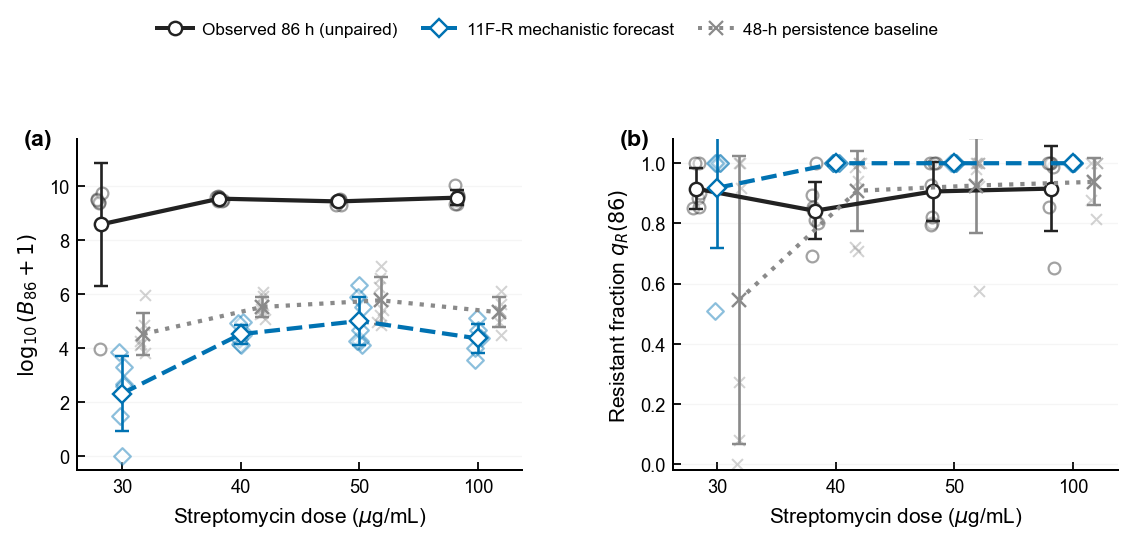

Saved final publication Figure C:
  results\real_data\figures\final_R310_11FR_86h_unpaired_distribution_forecast_FigureC_independent_86h_validation.pdf
  results\real_data\figures\final_R310_11FR_86h_unpaired_distribution_forecast_FigureC_independent_86h_validation.svg
  results\real_data\figures\final_R310_11FR_86h_unpaired_distribution_forecast_FigureC_independent_86h_validation.png


In [67]:
# =============================================================================
# CELL 12 — FINAL PUBLICATION FIGURE (FIXED)
# Figure C from Cell 12 — independent 86-h validation
#
# ASSUMES THESE ALREADY EXIST:
#   - forecast_86_12
#   - q86_treated_12
#
# This block does NOT retrain anything.
# =============================================================================

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# -----------------------------------------------------------------------------
# Output directory
# -----------------------------------------------------------------------------
if "FIGURE_DIR" in globals():
    figure_dir_pub_12 = Path(FIGURE_DIR)
else:
    figure_dir_pub_12 = Path.cwd() / "publication_figures"

figure_dir_pub_12.mkdir(parents=True, exist_ok=True)

if "R310_TAG" in globals():
    figure_stem_pub_12 = f"{R310_TAG}_FigureC_independent_86h_validation"
else:
    figure_stem_pub_12 = "FigureC_independent_86h_validation"

# -----------------------------------------------------------------------------
# Doses
# -----------------------------------------------------------------------------
doses_pub_12 = [30.0, 40.0, 50.0, 100.0]
x_pub_12 = np.arange(len(doses_pub_12), dtype=float)

# -----------------------------------------------------------------------------
# Publication style
# -----------------------------------------------------------------------------
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "DejaVu Sans"],
    "font.size": 8.5,
    "axes.labelsize": 9.4,
    "xtick.labelsize": 8.2,
    "ytick.labelsize": 8.2,
    "legend.fontsize": 7.7,
    "axes.linewidth": 0.9,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.major.size": 3.5,
    "ytick.major.size": 3.5,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
})

# -----------------------------------------------------------------------------
# Colors and horizontal offsets
# -----------------------------------------------------------------------------
COLOR_OBS_12 = "#222222"
COLOR_FORECAST_12 = "#0072B2"
COLOR_BASELINE_12 = "#8A8A8A"

OFFSET_OBS_12 = -0.18
OFFSET_FORECAST_12 = 0.00
OFFSET_BASELINE_12 = 0.18

SEED_PUB_12 = 20261125
rng_pub_12 = np.random.default_rng(SEED_PUB_12)

# -----------------------------------------------------------------------------
# Helpers
# -----------------------------------------------------------------------------
def _mean_sd_pub_12(values):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]

    if len(values) == 0:
        return np.nan, np.nan

    mean_val = float(np.mean(values))
    sd_val = float(np.std(values, ddof=1)) if len(values) > 1 else 0.0

    return mean_val, sd_val


def _dose_values_pub_12(df, dose, column):
    return df.loc[
        df["dose_ug_ml"] == dose,
        column
    ].to_numpy(dtype=float)


def _draw_group_pub_12(
    ax,
    x_center,
    values,
    color,
    marker,
    alpha_points=0.4,
):
    jitter = rng_pub_12.uniform(
        -0.030,
        0.030,
        size=len(values),
    )

    x_points = x_center + jitter

    if marker == "x":
        ax.scatter(
            x_points,
            values,
            s=24,
            marker="x",
            linewidths=0.9,
            color=color,
            alpha=alpha_points,
            zorder=2,
        )
    else:
        ax.scatter(
            x_points,
            values,
            s=28,
            marker=marker,
            facecolors="white",
            edgecolors=color,
            linewidths=1.0,
            alpha=alpha_points,
            zorder=2,
        )


def _draw_mean_sd_pub_12(
    ax,
    x,
    means,
    sds,
    color,
    marker,
    linestyle,
):
    markerface = color if marker == "x" else "white"

    ax.errorbar(
        x,
        means,
        yerr=sds,
        fmt=marker + linestyle,
        color=color,
        markerfacecolor=markerface,
        markeredgecolor=color,
        markeredgewidth=1.1,
        markersize=6.0,
        linewidth=1.9,
        elinewidth=1.2,
        capsize=3.2,
        capthick=1.0,
        zorder=5,
    )


def _draw_panel_pub_12(
    ax,
    observed_column,
    forecast_column,
    persistence_column,
    y_label,
    panel_label,
    q_fraction=False,
):
    observed_means = []
    observed_sds = []

    forecast_means = []
    forecast_sds = []

    persist_means = []
    persist_sds = []

    for i, dose in enumerate(doses_pub_12):

        obs_vals = _dose_values_pub_12(
            q86_treated_12,
            dose,
            observed_column,
        )

        frc_vals = _dose_values_pub_12(
            forecast_86_12,
            dose,
            forecast_column,
        )

        per_vals = _dose_values_pub_12(
            forecast_86_12,
            dose,
            persistence_column,
        )

        # Individual distribution points
        _draw_group_pub_12(
            ax,
            x_pub_12[i] + OFFSET_OBS_12,
            obs_vals,
            COLOR_OBS_12,
            "o",
            alpha_points=0.42,
        )

        _draw_group_pub_12(
            ax,
            x_pub_12[i] + OFFSET_FORECAST_12,
            frc_vals,
            COLOR_FORECAST_12,
            "D",
            alpha_points=0.45,
        )

        _draw_group_pub_12(
            ax,
            x_pub_12[i] + OFFSET_BASELINE_12,
            per_vals,
            COLOR_BASELINE_12,
            "x",
            alpha_points=0.38,
        )

        # Mean ± SD
        m, s = _mean_sd_pub_12(obs_vals)
        observed_means.append(m)
        observed_sds.append(s)

        m, s = _mean_sd_pub_12(frc_vals)
        forecast_means.append(m)
        forecast_sds.append(s)

        m, s = _mean_sd_pub_12(per_vals)
        persist_means.append(m)
        persist_sds.append(s)

    # Mean ± SD curves
    _draw_mean_sd_pub_12(
        ax,
        x_pub_12 + OFFSET_OBS_12,
        np.asarray(observed_means),
        np.asarray(observed_sds),
        COLOR_OBS_12,
        "o",
        "-",
    )

    _draw_mean_sd_pub_12(
        ax,
        x_pub_12 + OFFSET_FORECAST_12,
        np.asarray(forecast_means),
        np.asarray(forecast_sds),
        COLOR_FORECAST_12,
        "D",
        "--",
    )

    _draw_mean_sd_pub_12(
        ax,
        x_pub_12 + OFFSET_BASELINE_12,
        np.asarray(persist_means),
        np.asarray(persist_sds),
        COLOR_BASELINE_12,
        "x",
        ":",
    )

    # Axes
    ax.set_xticks(x_pub_12)
    ax.set_xticklabels(
        [str(int(d)) for d in doses_pub_12]
    )

    ax.set_xlabel(
        r"Streptomycin dose ($\mu$g/mL)"
    )

    ax.set_ylabel(
        y_label
    )

    ax.grid(
        axis="y",
        alpha=0.12,
        linewidth=0.6,
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    # Panel label outside data region
    ax.text(
        -0.12,
        1.03,
        panel_label,
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=10.5,
        fontweight="bold",
        clip_on=False,
    )

    # Y limits
    if q_fraction:
        ax.set_ylim(
            -0.02,
            1.08,
        )

        ax.set_yticks(
            np.linspace(
                0.0,
                1.0,
                6,
            )
        )

    else:
        ymin, ymax = ax.get_ylim()

        ax.set_ylim(
            min(-0.2, ymin),
            ymax + 0.35,
        )


# =============================================================================
# Create final Figure C
# =============================================================================

fig_pub_12, axes_pub_12 = plt.subplots(
    1,
    2,
    figsize=(7.35, 3.45),
    constrained_layout=False,
)

# Panel (a)
_draw_panel_pub_12(
    ax=axes_pub_12[0],
    observed_column="log10_population_plus1",
    forecast_column="forecast_log10_B86",
    persistence_column="persistence_log10_B86",
    y_label=r"$\log_{10}(B_{86}+1)$",
    panel_label="(a)",
    q_fraction=False,
)

# Panel (b)
_draw_panel_pub_12(
    ax=axes_pub_12[1],
    observed_column="resistant_fraction_qR",
    forecast_column="forecast_qR86",
    persistence_column="persistence_qR86",
    y_label=r"Resistant fraction $q_R(86)$",
    panel_label="(b)",
    q_fraction=True,
)

# -----------------------------------------------------------------------------
# Shared legend
# -----------------------------------------------------------------------------
legend_handles_pub_12 = [

    Line2D(
        [0], [0],
        marker="o",
        linestyle="-",
        color=COLOR_OBS_12,
        markerfacecolor="white",
        markeredgecolor=COLOR_OBS_12,
        markeredgewidth=1.1,
        linewidth=1.8,
        markersize=6.0,
        label="Observed 86 h (unpaired)",
    ),

    Line2D(
        [0], [0],
        marker="D",
        linestyle="--",
        color=COLOR_FORECAST_12,
        markerfacecolor="white",
        markeredgecolor=COLOR_FORECAST_12,
        markeredgewidth=1.1,
        linewidth=1.8,
        markersize=6.0,
        label="11F-R mechanistic forecast",
    ),

    Line2D(
        [0], [0],
        marker="x",
        linestyle=":",
        color=COLOR_BASELINE_12,
        linewidth=1.8,
        markersize=6.0,
        label="48-h persistence baseline",
    ),
]

fig_pub_12.legend(
    handles=legend_handles_pub_12,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.02),
    ncol=3,
    frameon=False,
    handlelength=2.1,
    columnspacing=1.4,
    handletextpad=0.55,
)

# -----------------------------------------------------------------------------
# Final spacing
# -----------------------------------------------------------------------------
fig_pub_12.subplots_adjust(
    left=0.10,
    right=0.985,
    bottom=0.18,
    top=0.78,
    wspace=0.34,
)

# -----------------------------------------------------------------------------
# Save publication files
# -----------------------------------------------------------------------------
figure_base_pub_12 = (
    figure_dir_pub_12
    /
    figure_stem_pub_12
)

fig_pub_12.savefig(
    figure_base_pub_12.with_suffix(".pdf"),
    bbox_inches="tight",
    pad_inches=0.03,
)

fig_pub_12.savefig(
    figure_base_pub_12.with_suffix(".svg"),
    bbox_inches="tight",
    pad_inches=0.03,
)

fig_pub_12.savefig(
    figure_base_pub_12.with_suffix(".png"),
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.03,
)

plt.show()

print("Saved final publication Figure C:")
print(" ", figure_base_pub_12.with_suffix(".pdf"))
print(" ", figure_base_pub_12.with_suffix(".svg"))
print(" ", figure_base_pub_12.with_suffix(".png"))